# Cavity pulses with a trip label

One row per cavity pulse: `cavity`, `value_1` … `value_n` (field amplitude, bin means over the whole record), `label`.

- `label = 0`: every pulse of the DD captures (nominal operation, taken on demand).
- `label = 1`: the last `TRIP_PULSES` pulses of each PM capture (taken when the beam trips; rank 0 is the pulse of the trip).

The other PM pulses are left out: they come before the trip, so they are neither clearly nominal nor the trip.

Source: `cavity_pulses.parquet` written by `../notebooks/ess_dd/ess_dd_features.py` for the DD and the PM captures.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOKS = Path("../notebooks")
OUT = Path("cavity_pulses_labeled.parquet")
TRIP_PULSES = 1
COLUMNS = ["cavity", "field_amp_bins", "cycle_rank_from_last"]

In [3]:
dd = pd.read_parquet(NOTEBOOKS / "ess_dd" / "cavity_pulses.parquet", columns=COLUMNS).assign(label=0)
pm = pd.read_parquet(NOTEBOOKS / "ess_pm" / "cavity_pulses.parquet", columns=COLUMNS)
pm = pm[pm["cycle_rank_from_last"] < TRIP_PULSES].assign(label=1)
pulses = pd.concat([dd, pm], ignore_index=True)

values = np.stack(pulses["field_amp_bins"].to_numpy())
dataset = pd.concat([
    pulses[["cavity"]],
    pd.DataFrame(values, columns=[f"value_{i + 1}" for i in range(values.shape[1])]),
    pulses[["label"]],
], axis=1)
dataset.to_parquet(OUT, index=False)
print(OUT.resolve(), dataset.shape)
dataset["label"].value_counts()

/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/teams/the-outliers/cavity_dataset/cavity_pulses_labeled.parquet (40223, 66)


label
0    35414
1     4809
Name: count, dtype: int64

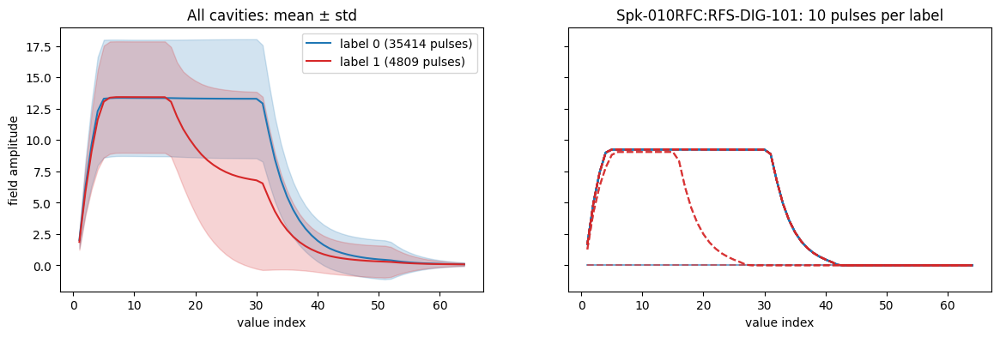

In [4]:
value_columns = [c for c in dataset.columns if c.startswith("value_")]
cavity = dataset.loc[dataset["label"] == 1, "cavity"].value_counts().index[0]
one = dataset[dataset["cavity"] == cavity]

fig, (mean_ax, sample_ax) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for label, color, style in [(0, "tab:blue", "-"), (1, "tab:red", "--")]:
    rows = dataset.loc[dataset["label"] == label, value_columns].to_numpy()
    mean, std = rows.mean(axis=0), rows.std(axis=0)
    x = np.arange(1, len(value_columns) + 1)
    mean_ax.plot(x, mean, color=color, label=f"label {label} ({len(rows)} pulses)")
    mean_ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.2)
    for row in one.loc[one["label"] == label, value_columns].sample(10, random_state=0).to_numpy():
        sample_ax.plot(x, row, color=color, linestyle=style, alpha=0.6)
mean_ax.set(title="All cavities: mean ± std", xlabel="value index", ylabel="field amplitude")
mean_ax.legend()
sample_ax.set(title=f"{cavity}: 10 pulses per label", xlabel="value index")
plt.show()

In [5]:
value_columns = [c for c in dataset.columns if c.startswith("value_")]

dd_only = dataset[dataset["label"] == 0].copy()

dd_only["mean"] = dd_only[value_columns].mean(axis=1)
dd_only["std"] = dd_only[value_columns].std(axis=1)
dd_only["min"] = dd_only[value_columns].min(axis=1)
dd_only["max"] = dd_only[value_columns].max(axis=1)
dd_only["range"] = dd_only["max"] - dd_only["min"]

dd_stats = dd_only[
    ["cavity", "mean", "std", "min", "max", "range"]
]

display(dd_stats.head(20))

,cavity,mean,std,min,max,range
0,HBL-010RFC:RFS-DIG-101,5.557890,7.738515,0.215462,19.787766,19.572304
1,HBL-010RFC:RFS-DIG-201,5.032678,7.016352,0.120836,17.863754,17.742918
2,HBL-010RFC:RFS-DIG-401,5.496892,7.714774,0.000000,19.547852,19.547852
3,HBL-010RFC:RFS-DIG-301,4.915654,6.995852,0.000000,17.684509,17.684509
4,HBL-010RFC:RFS-DIG-401,5.496830,7.714846,0.000000,19.547930,19.547930
5,HBL-010RFC:RFS-DIG-301,4.916027,6.995636,0.000000,17.684490,17.684490
6,HBL-010RFC:RFS-DIG-101,5.556869,7.738068,0.215449,19.787525,19.572077
7,HBL-010RFC:RFS-DIG-201,5.031763,7.016291,0.120815,17.863541,17.742725
8,HBL-010RFC:RFS-DIG-401,5.500826,7.714758,0.000000,19.549051,19.549051
9,HBL-010RFC:RFS-DIG-201,5.031909,7.016373,0.120804,17.863676,17.742872


In [6]:
cavity_name = "HBL-010RFC:RFS-DIG-101"

cavity_df = dd_stats[dd_stats["cavity"] == cavity_name].reset_index(drop=True)

display(cavity_df)

,cavity,mean,std,min,max,range
0,HBL-010RFC:RFS-DIG-101,5.557890,7.738515,0.215462,19.787766,19.572304
1,HBL-010RFC:RFS-DIG-101,5.556869,7.738068,0.215449,19.787525,19.572077
2,HBL-010RFC:RFS-DIG-101,5.556579,7.737775,0.215427,19.787056,19.571629
3,HBL-010RFC:RFS-DIG-101,5.558135,7.738444,0.215429,19.788383,19.572954
4,HBL-010RFC:RFS-DIG-101,5.557323,7.738052,0.215436,19.787315,19.571878
...,...,...,...,...,...,...
432,HBL-010RFC:RFS-DIG-101,10.387723,9.051884,0.215503,19.952892,19.737389
433,HBL-010RFC:RFS-DIG-101,10.389402,9.050953,0.215526,19.952957,19.737431
434,HBL-010RFC:RFS-DIG-101,10.388836,9.051300,0.215499,19.952944,19.737446
435,HBL-010RFC:RFS-DIG-101,10.391621,9.049738,0.215559,19.952923,19.737364


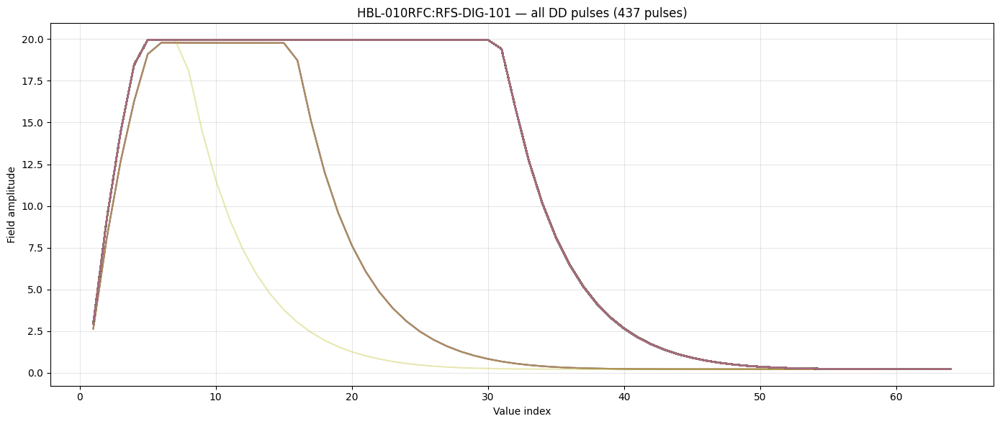

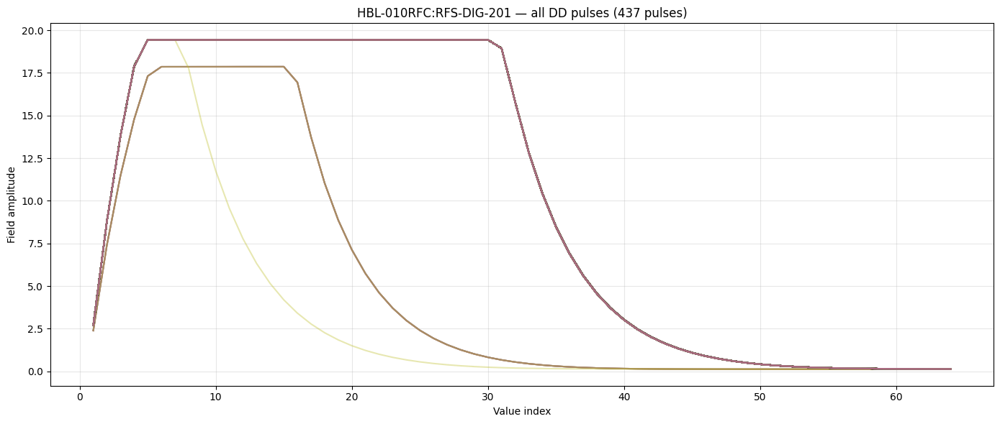

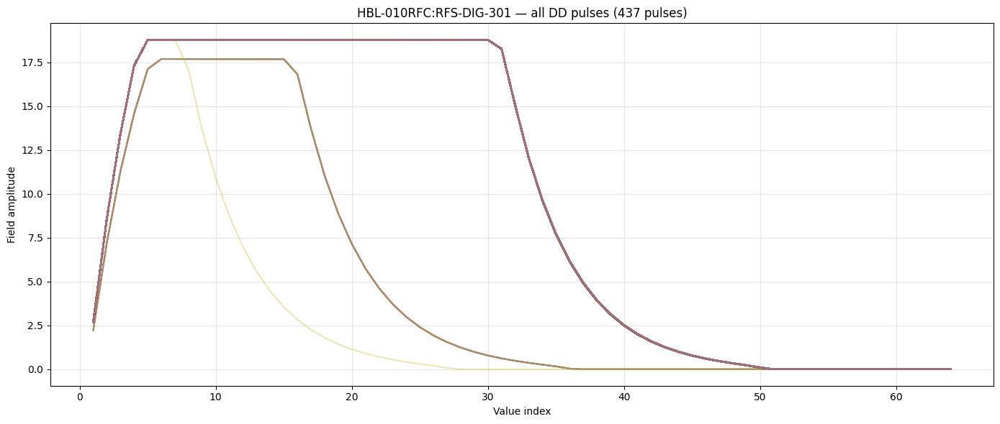

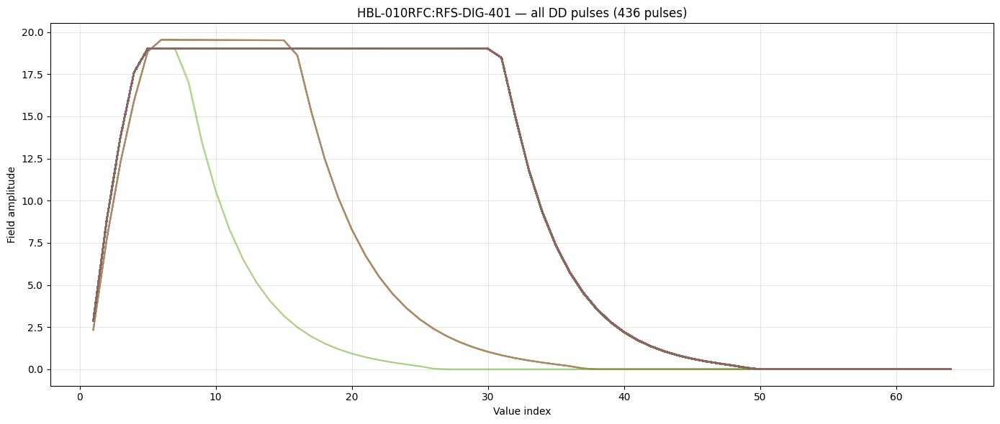

In [40]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

x = np.arange(1, len(value_columns) + 1)

for cavity_name in cavity_names:

    cavity_df = dd_only[
        dd_only["cavity"] == cavity_name
    ].reset_index(drop=True)

    plt.figure(figsize=(14, 6))

    for i, row in cavity_df.iterrows():
        y = row[value_columns].to_numpy(dtype=float)

        plt.plot(
            x,
            y,
            alpha=0.35
        )

    plt.xlabel("Value index")
    plt.ylabel("Field amplitude")
    plt.title(
        f"{cavity_name} — all DD pulses "
        f"({len(cavity_df)} pulses)"
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

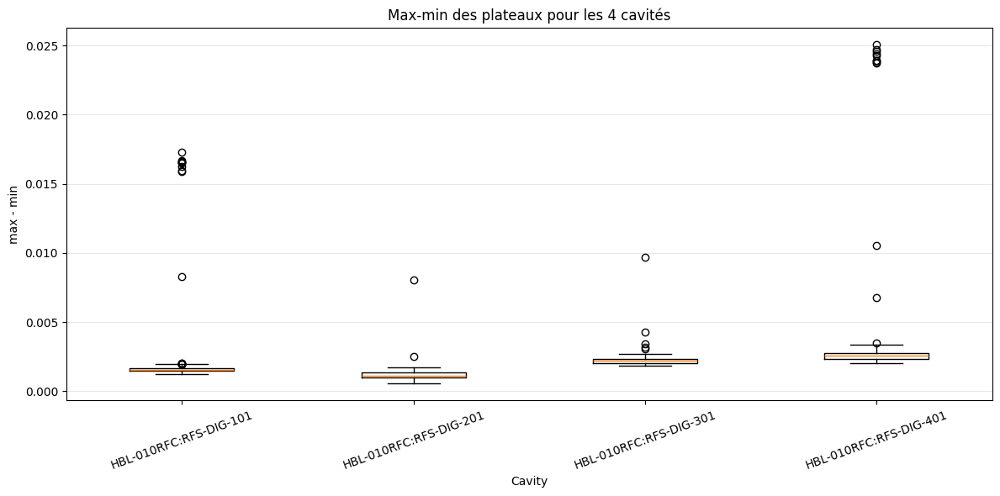

In [57]:
plt.figure(figsize=(12, 6))

data = [
    plateau_stats_all.loc[
        plateau_stats_all["cavity"] == cavity,
        "max_minus_min"
    ].dropna()
    for cavity in cavity_names
]

plt.boxplot(
    data,
    tick_labels=cavity_names
)

plt.xlabel("Cavity")
plt.ylabel("max - min")
plt.title("Max-min des plateaux pour les 4 cavités")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

all_plateau_stats = []

for cavity_name in cavity_names:

    cavity_df = dd_only[
        dd_only["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:
            start, end = plateau
            flat = y[start:end]

            results.append({
                "cavity": cavity_name,
                "pulse": i + 1,
                "start_x": start + 1,
                "end_x": end,
                "n_points": len(flat),
                "min": flat.min(),
                "max": flat.max(),
                "max_minus_min": flat.max() - flat.min(),
                "mean": flat.mean(),
                "std": flat.std()
            })

    cavity_stats = pd.DataFrame(results)
    all_plateau_stats.append(cavity_stats)

plateau_stats_all = pd.concat(
    all_plateau_stats,
    ignore_index=True
)

display(plateau_stats_all.head())

,cavity,pulse,start_x,end_x,n_points,min,max,max_minus_min,mean,std
0,HBL-010RFC:RFS-DIG-101,1,7,15,9,19.766281,19.782183,0.015902,19.770797,0.004888
1,HBL-010RFC:RFS-DIG-101,2,7,15,9,19.765884,19.782475,0.016590,19.770803,0.005173
2,HBL-010RFC:RFS-DIG-101,3,7,15,9,19.765106,19.781794,0.016687,19.770058,0.005242
3,HBL-010RFC:RFS-DIG-101,4,7,15,9,19.765709,19.783009,0.017300,19.770812,0.005328
4,HBL-010RFC:RFS-DIG-101,5,7,15,9,19.766048,19.782009,0.015961,19.770656,0.005030


In [44]:
outliers_all = []

for cavity_name in cavity_names:

    df_cav = plateau_stats_all[
        plateau_stats_all["cavity"] == cavity_name
    ].copy()

    q1 = df_cav["max_minus_min"].quantile(0.25)
    q3 = df_cav["max_minus_min"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df_cav[
        (df_cav["max_minus_min"] < lower_bound) |
        (df_cav["max_minus_min"] > upper_bound)
    ].copy()

    outliers_all.append(outliers)

    print("\n", cavity_name)
    print("Outlier pulse indices:")
    print(outliers["pulse"].tolist())


 HBL-010RFC:RFS-DIG-101
Outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 221, 224, 228, 229, 240, 241, 258, 261, 268]

 HBL-010RFC:RFS-DIG-201
Outlier pulse indices:
[229, 324]

 HBL-010RFC:RFS-DIG-301
Outlier pulse indices:
[229, 324, 325, 326, 327]

 HBL-010RFC:RFS-DIG-401
Outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 229, 293, 323]


In [46]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

label1 = dataset[dataset["label"] == 1].copy()

In [47]:
all_plateau_stats_label1 = []

for cavity_name in cavity_names:

    cavity_df = label1[
        label1["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:
            start, end = plateau
            flat = y[start:end]

            results.append({
                "cavity": cavity_name,
                "pulse": i + 1,
                "start_x": start + 1,
                "end_x": end,
                "n_points": len(flat),
                "min": flat.min(),
                "max": flat.max(),
                "max_minus_min": flat.max() - flat.min(),
                "mean": flat.mean(),
                "std": flat.std()
            })

    cavity_stats = pd.DataFrame(results)
    all_plateau_stats_label1.append(cavity_stats)

plateau_stats_label1 = pd.concat(
    all_plateau_stats_label1,
    ignore_index=True
)

display(plateau_stats_label1.head())

,cavity,pulse,start_x,end_x,n_points,min,max,max_minus_min,mean,std
0,HBL-010RFC:RFS-DIG-101,1,7,15,9,19.765759,19.782373,0.016615,19.770849,0.004990
1,HBL-010RFC:RFS-DIG-101,2,7,15,9,19.765154,19.782450,0.017296,19.770592,0.005266
2,HBL-010RFC:RFS-DIG-101,3,7,15,9,19.766144,19.782314,0.016171,19.770987,0.004955
3,HBL-010RFC:RFS-DIG-101,4,7,15,9,19.764069,19.780935,0.016867,19.769272,0.005270
4,HBL-010RFC:RFS-DIG-101,5,7,15,9,19.765430,19.782606,0.017176,19.770897,0.005183


/tmp/ipykernel_1736245/367998495.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


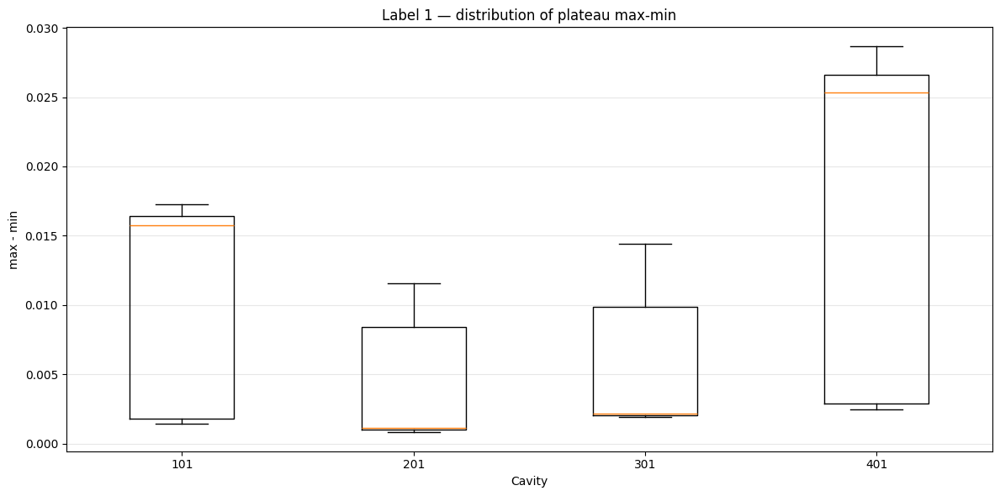

In [48]:
plt.figure(figsize=(12, 6))

data = [
    plateau_stats_label1.loc[
        plateau_stats_label1["cavity"] == cavity,
        "max_minus_min"
    ].dropna()
    for cavity in cavity_names
]

plt.boxplot(
    data,
    labels=["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("max - min")
plt.title("Label 1 — distribution of plateau max-min")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
WINDOW_SIZE = 6

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

all_window_stats = []

for cavity_name in cavity_names:

    cavity_df = dd_only[
        dd_only["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:

            start, end = plateau
            flat = y[start:end]

            window_ranges = []

            for j in range(
                0,
                len(flat) - WINDOW_SIZE + 1,
                WINDOW_SIZE
            ):
                window = flat[j:j + WINDOW_SIZE]

                window_ranges.append(
                    window.max() - window.min()
                )

            if len(window_ranges) > 0:

                results.append({
                    "cavity": cavity_name,
                    "pulse": i + 1,
                    "mean_window_range": np.mean(window_ranges),
                    "std_window_range": np.std(window_ranges),
                    "max_window_range": np.max(window_ranges),
                    "n_windows": len(window_ranges)
                })

    cavity_window_stats = pd.DataFrame(results)
    all_window_stats.append(cavity_window_stats)

window_stats_all = pd.concat(
    all_window_stats,
    ignore_index=True
)

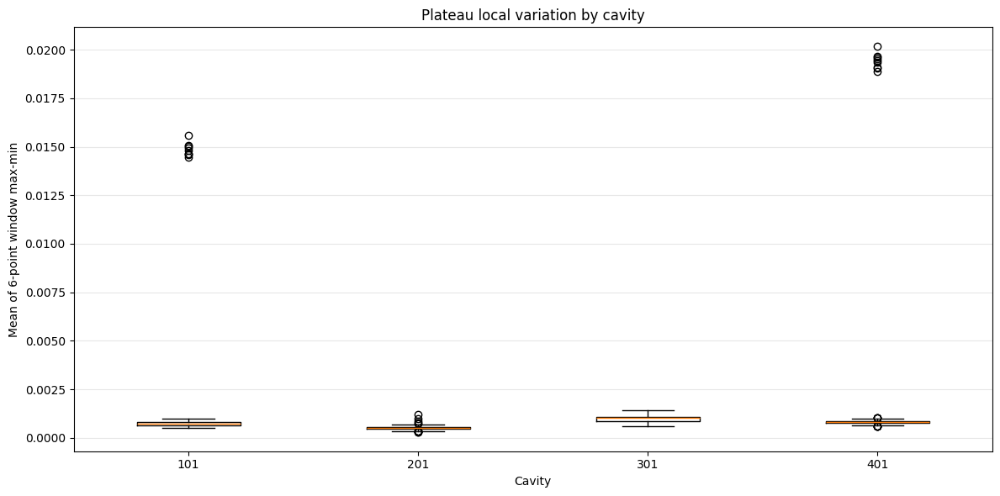

In [56]:
data = [
    window_stats_all.loc[
        window_stats_all["cavity"] == cavity,
        "mean_window_range"
    ].dropna()
    for cavity in cavity_names
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    data,
    tick_labels=["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("Mean of 6-point window max-min")
plt.title("Plateau local variation by cavity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
WINDOW_SIZE = 6

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

label1 = dataset[dataset["label"] == 1].copy()

all_window_stats_label1 = []

for cavity_name in cavity_names:

    cavity_df = label1[
        label1["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:

            start, end = plateau
            flat = y[start:end]

            window_ranges = []

            for j in range(
                0,
                len(flat) - WINDOW_SIZE + 1,
                WINDOW_SIZE
            ):
                window = flat[j:j + WINDOW_SIZE]

                window_ranges.append(
                    window.max() - window.min()
                )

            if len(window_ranges) > 0:

                results.append({
                    "cavity": cavity_name,
                    "pulse": i + 1,
                    "mean_window_range": np.mean(window_ranges),
                    "std_window_range": np.std(window_ranges),
                    "max_window_range": np.max(window_ranges),
                    "n_windows": len(window_ranges)
                })

    cavity_window_stats = pd.DataFrame(results)
    all_window_stats_label1.append(cavity_window_stats)

window_stats_label1 = pd.concat(
    all_window_stats_label1,
    ignore_index=True
)

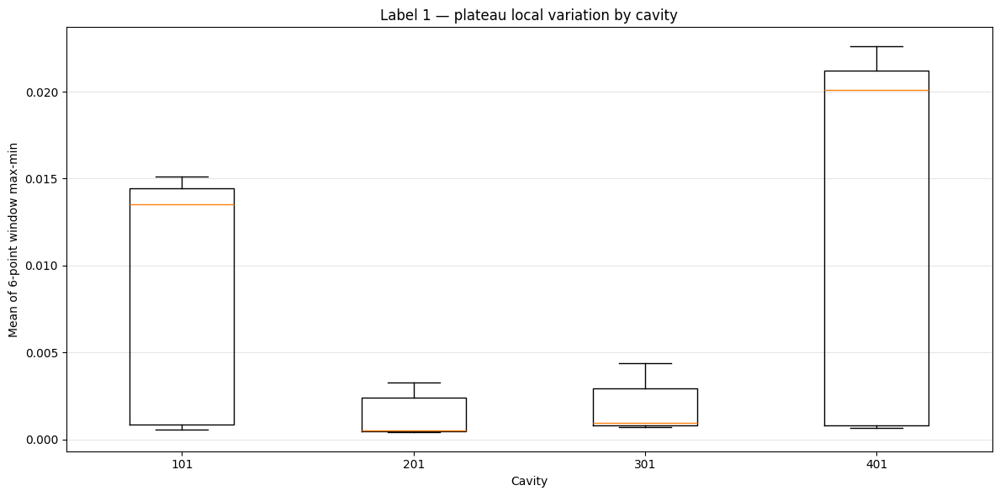

In [59]:
data = [
    window_stats_label1.loc[
        window_stats_label1["cavity"] == cavity,
        "mean_window_range"
    ].dropna()
    for cavity in cavity_names
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    data,
    tick_labels=["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("Mean of 6-point window max-min")
plt.title("Label 1 — plateau local variation by cavity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
comparison_data = []
positions = []
labels = []

pos = 1

for cavity in cavity_names:

    # label 0
    d0 = window_stats_all.loc[
        window_stats_all["cavity"] == cavity,
        "mean_window_range"
    ].dropna()

    # label 1
    d1 = window_stats_label1.loc[
        window_stats_label1["cavity"] == cavity,
        "mean_window_range"
    ].dropna()

    comparison_data.extend([d0, d1])
    positions.extend([pos, pos + 0.35])

    pos += 1.3

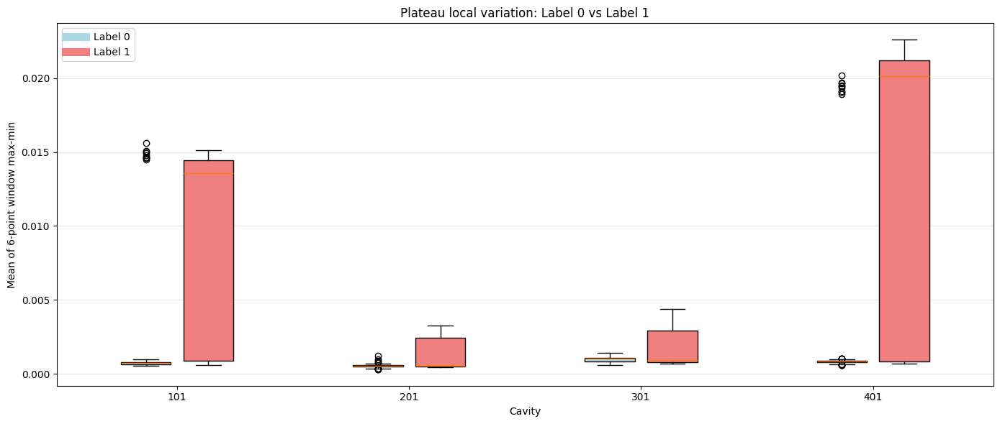

In [61]:
plt.figure(figsize=(14, 6))

bp = plt.boxplot(
    comparison_data,
    positions=positions,
    widths=0.28,
    patch_artist=True
)

# alternate colors label 0 / label 1
for i, box in enumerate(bp["boxes"]):
    if i % 2 == 0:
        box.set_facecolor("lightblue")   # label 0
    else:
        box.set_facecolor("lightcoral")  # label 1

centers = [
    (positions[i] + positions[i + 1]) / 2
    for i in range(0, len(positions), 2)
]

plt.xticks(
    centers,
    ["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("Mean of 6-point window max-min")
plt.title("Plateau local variation: Label 0 vs Label 1")

plt.plot([], [], color="lightblue", linewidth=8, label="Label 0")
plt.plot([], [], color="lightcoral", linewidth=8, label="Label 1")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
for cavity in cavity_names:

    d0 = window_stats_all.loc[
        window_stats_all["cavity"] == cavity,
        "mean_window_range"
    ]

    d1 = window_stats_label1.loc[
        window_stats_label1["cavity"] == cavity,
        "mean_window_range"
    ]

    print("\n", cavity)

    print(
        "Label 0:",
        "n =", len(d0),
        "median =", d0.median(),
        "mean =", d0.mean()
    )

    print(
        "Label 1:",
        "n =", len(d1),
        "median =", d1.median(),
        "mean =", d1.mean()
    )


 HBL-010RFC:RFS-DIG-101
Label 0: n = 436 median = 0.0007169246673583984 mean = 0.0010078095514839942
Label 1: n = 59 median = 0.013545989990234375 mean = 0.00817351422067416

 HBL-010RFC:RFS-DIG-201
Label 0: n = 427 median = 0.000514984130859375 mean = 0.0005244170195604096
Label 1: n = 28 median = 0.0005230903625488281 mean = 0.001223581177847726

 HBL-010RFC:RFS-DIG-301
Label 0: n = 427 median = 0.0010151863098144531 mean = 0.0009625689486429898
Label 1: n = 28 median = 0.0009388923645019531 mean = 0.0017821788787841797

 HBL-010RFC:RFS-DIG-401
Label 0: n = 434 median = 0.0008106231689453125 mean = 0.0011927279459166638
Label 1: n = 57 median = 0.020107269287109375 mean = 0.012176522037439179


In [63]:
upper_outliers_dd = []

for cavity_name in cavity_names:

    df_cav = window_stats_all[
        window_stats_all["cavity"] == cavity_name
    ].copy()

    q1 = df_cav["mean_window_range"].quantile(0.25)
    q3 = df_cav["mean_window_range"].quantile(0.75)
    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr

    outliers = df_cav[
        df_cav["mean_window_range"] > upper_bound
    ].copy()

    outliers["upper_bound"] = upper_bound

    upper_outliers_dd.append(outliers)

    print("\n", cavity_name)
    print("Upper outlier pulse indices:")
    print(outliers["pulse"].tolist())


 HBL-010RFC:RFS-DIG-101
Upper outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9]

 HBL-010RFC:RFS-DIG-201
Upper outlier pulse indices:
[324, 325, 326, 327, 328]

 HBL-010RFC:RFS-DIG-301
Upper outlier pulse indices:
[]

 HBL-010RFC:RFS-DIG-401
Upper outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 179, 191, 323, 359]


In [66]:
upper_outliers_dd_df = pd.concat(
    upper_outliers_dd,
    ignore_index=True
)

In [69]:
flattest = window_stats_all.loc[
    window_stats_all["mean_window_range"].idxmin()
]

flattest

cavity               HBL-010RFC:RFS-DIG-201
pulse                                   322
mean_window_range                  0.000302
std_window_range                   0.000159
max_window_range                   0.000568
n_windows                                 4
Name: 747, dtype: object

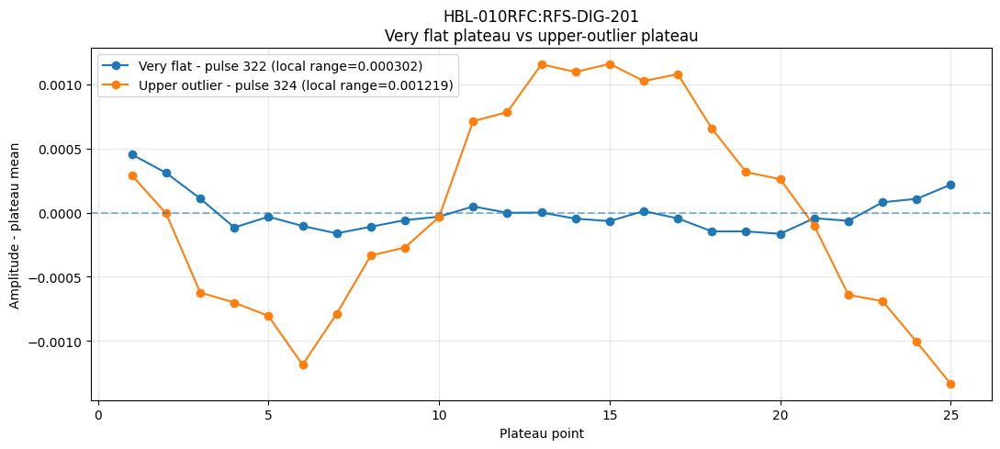

,type,pulse,max_minus_min,mean_window_range,std
0,Very flat,322,0.000618,0.000302,0.000146
1,Upper outlier,324,0.002495,0.001219,0.000783


In [71]:
WINDOW_SIZE = 6
cavity_name = "HBL-010RFC:RFS-DIG-201"

# --------------------------------------------------
# 1. Get one very flat pulse
# --------------------------------------------------
temp_stats = window_stats_all[
    window_stats_all["cavity"] == cavity_name
].copy()

very_flat_row = temp_stats.loc[
    temp_stats["mean_window_range"].idxmin()
]

flat_pulse = int(very_flat_row["pulse"])


# --------------------------------------------------
# 2. Get one upper-outlier pulse
# --------------------------------------------------
temp_outliers = upper_outliers_dd_df[
    upper_outliers_dd_df["cavity"] == cavity_name
].copy()

# choose the strongest upper outlier
outlier_row = temp_outliers.loc[
    temp_outliers["mean_window_range"].idxmax()
]

outlier_pulse = int(outlier_row["pulse"])


# --------------------------------------------------
# 3. Extract plateau function
# --------------------------------------------------
cavity_df = dd_only[
    dd_only["cavity"] == cavity_name
].reset_index(drop=True)


def extract_plateau(pulse_number):

    y = cavity_df.loc[
        pulse_number - 1,
        value_columns
    ].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau

    return y[start:end]


flat_normal = extract_plateau(flat_pulse)
flat_outlier = extract_plateau(outlier_pulse)


# --------------------------------------------------
# 4. Function for metrics
# --------------------------------------------------
def plateau_metrics(flat, window_size=6):

    window_ranges = []

    for j in range(
        0,
        len(flat) - window_size + 1,
        window_size
    ):
        window = flat[j:j + window_size]

        window_ranges.append(
            window.max() - window.min()
        )

    return {
        "max_minus_min": flat.max() - flat.min(),
        "mean_window_range": np.mean(window_ranges),
        "std": flat.std()
    }


m_normal = plateau_metrics(flat_normal, WINDOW_SIZE)
m_outlier = plateau_metrics(flat_outlier, WINDOW_SIZE)


# --------------------------------------------------
# 5. Center both plateaux
# --------------------------------------------------
flat_normal_centered = (
    flat_normal - flat_normal.mean()
)

flat_outlier_centered = (
    flat_outlier - flat_outlier.mean()
)


# --------------------------------------------------
# 6. Plot comparison
# --------------------------------------------------
plt.figure(figsize=(11, 5))

plt.plot(
    np.arange(1, len(flat_normal_centered) + 1),
    flat_normal_centered,
    marker="o",
    label=(
        f"Very flat - pulse {flat_pulse} "
        f"(local range={m_normal['mean_window_range']:.6f})"
    )
)

plt.plot(
    np.arange(1, len(flat_outlier_centered) + 1),
    flat_outlier_centered,
    marker="o",
    label=(
        f"Upper outlier - pulse {outlier_pulse} "
        f"(local range={m_outlier['mean_window_range']:.6f})"
    )
)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Plateau point")
plt.ylabel("Amplitude - plateau mean")

plt.title(
    f"{cavity_name}\n"
    "Very flat plateau vs upper-outlier plateau"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Show numerical comparison
# --------------------------------------------------
comparison = pd.DataFrame({
    "type": [
        "Very flat",
        "Upper outlier"
    ],
    "pulse": [
        flat_pulse,
        outlier_pulse
    ],
    "max_minus_min": [
        m_normal["max_minus_min"],
        m_outlier["max_minus_min"]
    ],
    "mean_window_range": [
        m_normal["mean_window_range"],
        m_outlier["mean_window_range"]
    ],
    "std": [
        m_normal["std"],
        m_outlier["std"]
    ]
})

display(comparison)

In [74]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [73]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.9/281.9 MB 27.4 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 25.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 27.3 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━ 7/8 [tensorflow]  WARNING: The scripts saved_model_cli, tf_upgrade_v2, tflite_convert and toco are installed in '/lustre/home/extusers/udlc4dd19/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [tensorflow]
Note: you may need to restart the kernel to use updated packages.


In [75]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

# DD = label 0
dd_model = dataset[
    (dataset["label"] == 0) &
    (dataset["cavity"].isin(cavity_names))
].copy()

# numéro du pulse à l'intérieur de chaque cavité
dd_model["pulse"] = (
    dd_model.groupby("cavity").cumcount() + 1
)

# upper outliers que tu avais trouvés
bad_keys = set(
    zip(
        upper_outliers_dd_df["cavity"],
        upper_outliers_dd_df["pulse"]
    )
)

mask_good = [
    (cavity, pulse) not in bad_keys
    for cavity, pulse in zip(
        dd_model["cavity"],
        dd_model["pulse"]
    )
]

dd_clean = dd_model.loc[mask_good].reset_index(drop=True)

print("DD total :", len(dd_model))
print("Outliers removed :", len(dd_model) - len(dd_clean))
print("DD clean :", len(dd_clean))

DD total : 1747
Outliers removed : 27
DD clean : 1720


In [110]:
FIXED_LEN = 15

def resample_plateau(flat, fixed_len=24):
    flat = np.asarray(flat, dtype=float)

    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)

    return np.interp(x_new, x_old, flat)

In [111]:
def extract_fixed_plateau(row, fixed_len=24):

    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    # éviter les plateaux trop courts
    if len(flat) < 6:
        return None

    flat_fixed = resample_plateau(
        flat,
        fixed_len=fixed_len
    )

    return flat_fixed

In [112]:
plateau_vectors = []
metadata = []

for idx, row in dd_clean.iterrows():

    flat_fixed = extract_fixed_plateau(
        row,
        fixed_len=FIXED_LEN
    )

    if flat_fixed is not None:

        plateau_vectors.append(flat_fixed)

        metadata.append({
            "cavity": row["cavity"],
            "pulse": row["pulse"]
        })

X_plateau = np.vstack(plateau_vectors)

metadata = pd.DataFrame(metadata)

print("X plateau shape :", X_plateau.shape)
display(metadata.head())

X plateau shape : (1697, 15)


,cavity,pulse
0,HBL-010RFC:RFS-DIG-201,10
1,HBL-010RFC:RFS-DIG-101,10
2,HBL-010RFC:RFS-DIG-301,10
3,HBL-010RFC:RFS-DIG-401,10
4,HBL-010RFC:RFS-DIG-401,11


In [113]:
X_train, X_temp, meta_train, meta_temp = train_test_split(
    X_plateau,
    metadata,
    test_size=0.40,
    random_state=42
)

X_val, X_test, meta_val, meta_test = train_test_split(
    X_temp,
    meta_temp,
    test_size=0.50,
    random_state=42
)

print("Train :", X_train.shape)
print("Val   :", X_val.shape)
print("Test  :", X_test.shape)

Train : (1018, 15)
Val   : (339, 15)
Test  : (340, 15)


In [114]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [115]:
def build_autoencoder(input_dim):

    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(
        negative_slope=0.075
    )(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(
        input_layer,
        output_layer
    )

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(
            learning_rate=1e-4
        )
    )

    return model

In [116]:
from tensorflow.keras import backend as K

K.clear_session()

input_dim = X_train_scaled.shape[1]

ae = build_autoencoder(input_dim)

In [117]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = ae.fit(
    X_train_scaled,
    X_train_scaled,
    validation_data=(
        X_val_scaled,
        X_val_scaled
    ),
    epochs=500,
    batch_size=16,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.0971 - val_loss: 1.1314
Epoch 2/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0629 - val_loss: 1.0964
Epoch 3/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0286 - val_loss: 1.0618
Epoch 4/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9967 - val_loss: 1.0299
Epoch 5/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9642 - val_loss: 0.9945
Epoch 6/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9290 - val_loss: 0.9567
Epoch 7/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8920 - val_loss: 0.9165
Epoch 8/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8533 - val_loss: 0.8757
Epoch 9/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8138 - val_loss: 0.8341
Epoch 10/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7742 - val_loss: 0.7926
Epoch 11/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7353 - val_loss: 0.7521
Epoch 12/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6

In [121]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
def residual_features(residual):

    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),

        "res_std": residual.std(axis=1),

        "res_max_minus_min":
            residual.max(axis=1) - residual.min(axis=1),

        "res_mae":
            np.mean(np.abs(residual), axis=1),

        "res_mse":
            np.mean(residual**2, axis=1),

        "res_max_abs":
            np.max(np.abs(residual), axis=1)
    })
# Reconstruction
X_val_rec = ae.predict(
    X_val_scaled,
    verbose=0
)

X_test_rec = ae.predict(
    X_test_scaled,
    verbose=0
)

# Residuals
res_val = X_val_scaled - X_val_rec
res_test = X_test_scaled - X_test_rec

# Statistical features
features_val = residual_features(res_val)
features_test = residual_features(res_test)

print("DD validation features:", features_val.shape)
print("DD test features:", features_test.shape)

display(features_val.head())
label1 = dataset[
    (dataset["label"] == 1) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print("Total label 1 pulses:", len(label1))
print()
print(label1["cavity"].value_counts())
trip_vectors = []
trip_metadata = []

for idx, row in label1.iterrows():

    flat_fixed = extract_fixed_plateau(
        row,
        fixed_len=15
    )

    if flat_fixed is not None:

        trip_vectors.append(flat_fixed)

        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_trip_all = np.vstack(trip_vectors)

trip_metadata = pd.DataFrame(
    trip_metadata
)

print("Usable label 1 plateaux:", X_trip_all.shape)
display(trip_metadata.head())

DD validation features: (339, 6)
DD test features: (340, 6)


,res_mean,res_std,res_max_minus_min,res_mae,res_mse,res_max_abs
0,-0.000439,0.000889,0.003936,0.000743,9.833832e-07,0.002004
1,0.001030,0.001029,0.003209,0.001223,2.119546e-06,0.002452
2,0.002219,0.000480,0.001794,0.002219,5.155893e-06,0.003216
3,0.001030,0.001061,0.003632,0.001273,2.186747e-06,0.002416
4,-0.000439,0.000648,0.002122,0.000629,6.128133e-07,0.001506


Total label 1 pulses: 234

cavity
HBL-010RFC:RFS-DIG-201    59
HBL-010RFC:RFS-DIG-101    59
HBL-010RFC:RFS-DIG-301    59
HBL-010RFC:RFS-DIG-401    57
Name: count, dtype: int64
Usable label 1 plateaux: (172, 15)


,original_index,cavity
0,1,HBL-010RFC:RFS-DIG-101
1,3,HBL-010RFC:RFS-DIG-401
2,4,HBL-010RFC:RFS-DIG-401
3,7,HBL-010RFC:RFS-DIG-101
4,10,HBL-010RFC:RFS-DIG-101


In [122]:
# ---------------------------------------------------------
# Split the 172 usable trip plateaux into validation/test
# ---------------------------------------------------------

from sklearn.model_selection import train_test_split

trip_indices = np.arange(len(X_trip_all))

idx_trip_val, idx_trip_test = train_test_split(
    trip_indices,
    test_size=0.50,
    random_state=42,
    stratify=trip_metadata["cavity"]
)

X_trip_val = X_trip_all[idx_trip_val]
X_trip_test = X_trip_all[idx_trip_test]

trip_meta_val = trip_metadata.iloc[idx_trip_val].reset_index(drop=True)
trip_meta_test = trip_metadata.iloc[idx_trip_test].reset_index(drop=True)

print("Trip validation:", len(X_trip_val))
print("Trip test:", len(X_trip_test))

print("\nTrip validation per cavity:")
print(trip_meta_val["cavity"].value_counts())

print("\nTrip test per cavity:")
print(trip_meta_test["cavity"].value_counts())

Trip validation: 86
Trip test: 86

Trip validation per cavity:
cavity
HBL-010RFC:RFS-DIG-101    30
HBL-010RFC:RFS-DIG-401    28
HBL-010RFC:RFS-DIG-301    14
HBL-010RFC:RFS-DIG-201    14
Name: count, dtype: int64

Trip test per cavity:
cavity
HBL-010RFC:RFS-DIG-401    29
HBL-010RFC:RFS-DIG-101    29
HBL-010RFC:RFS-DIG-201    14
HBL-010RFC:RFS-DIG-301    14
Name: count, dtype: int64


DD validation features: (339, 6)
DD test features: (340, 6)

Total label 1: 234
cavity
HBL-010RFC:RFS-DIG-201    59
HBL-010RFC:RFS-DIG-101    59
HBL-010RFC:RFS-DIG-301    59
HBL-010RFC:RFS-DIG-401    57
Name: count, dtype: int64

Usable label 1 plateaux: (172, 15)
cavity
HBL-010RFC:RFS-DIG-101    59
HBL-010RFC:RFS-DIG-401    57
HBL-010RFC:RFS-DIG-201    28
HBL-010RFC:RFS-DIG-301    28
Name: count, dtype: int64

Trip validation: 86
Trip test: 86

Trip validation by cavity:
cavity
HBL-010RFC:RFS-DIG-101    30
HBL-010RFC:RFS-DIG-401    28
HBL-010RFC:RFS-DIG-301    14
HBL-010RFC:RFS-DIG-201    14
Name: count, dtype: int64

Trip test by cavity:
cavity
HBL-010RFC:RFS-DIG-401    29
HBL-010RFC:RFS-DIG-101    29
HBL-010RFC:RFS-DIG-201    14
HBL-010RFC:RFS-DIG-301    14
Name: count, dtype: int64

Balanced DD validation: 86
Balanced DD test: 86

Trip validation features: (86, 6)
Trip test features: (86, 6)

Classifier pool:
label
0    86
1    86
Name: count, dtype: int64

XGBoost train: (120, 6)


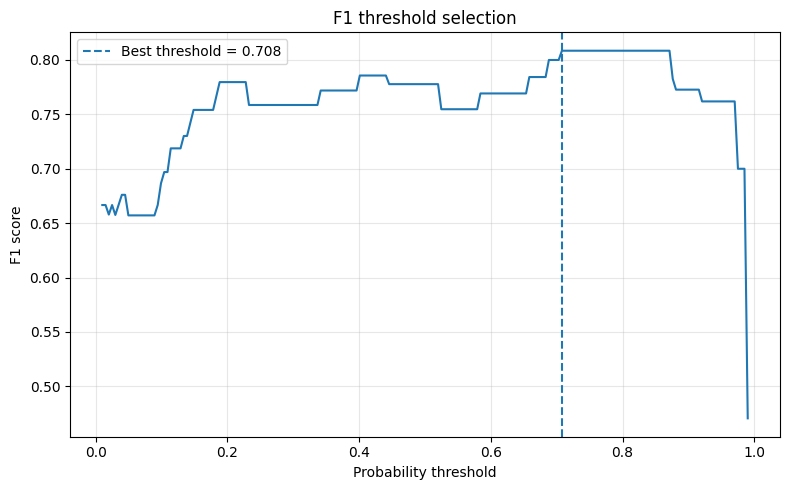


Final test:
label
0    86
1    86
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

           0     0.7600    0.8837    0.8172        86
           1     0.8611    0.7209    0.7848        86

    accuracy                         0.8023       172
   macro avg     0.8106    0.8023    0.8010       172
weighted avg     0.8106    0.8023    0.8010       172

F1: 0.7848101265822784
Precision: 0.8611111111111112
Recall: 0.7209302325581395
ROC AUC: 0.8845997836668469
PR AUC: 0.9083195818909655

Confusion matrix:
[[76 10]
 [24 62]]


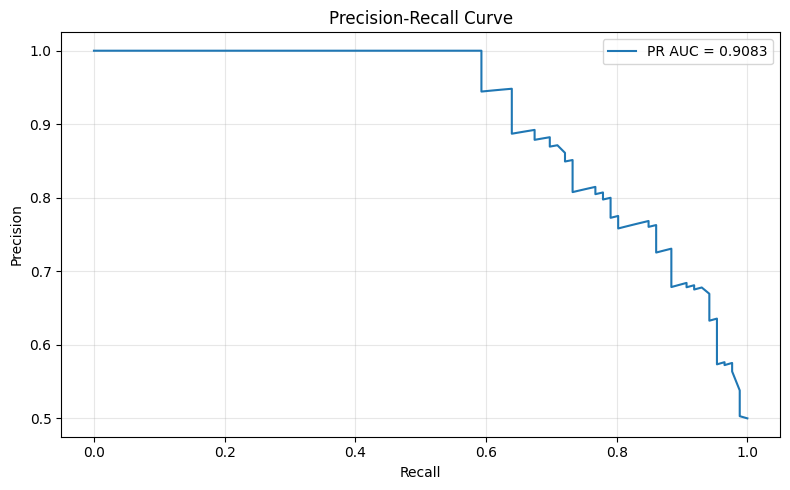

In [123]:
# ============================================================
# AFTER AUTOENCODER TRAINING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# 1. RESIDUAL FEATURE FUNCTION
# ============================================================

def residual_features(residual):

    return pd.DataFrame({
        "res_mean":
            residual.mean(axis=1),

        "res_std":
            residual.std(axis=1),

        "res_max_minus_min":
            residual.max(axis=1)
            - residual.min(axis=1),

        "res_mae":
            np.mean(
                np.abs(residual),
                axis=1
            ),

        "res_mse":
            np.mean(
                residual**2,
                axis=1
            ),

        "res_max_abs":
            np.max(
                np.abs(residual),
                axis=1
            )
    })


# ============================================================
# 2. DD VALIDATION + TEST RECONSTRUCTION
# ============================================================

X_val_rec = ae.predict(
    X_val_scaled,
    verbose=0
)

X_test_rec = ae.predict(
    X_test_scaled,
    verbose=0
)

res_val = (
    X_val_scaled
    - X_val_rec
)

res_test = (
    X_test_scaled
    - X_test_rec
)

features_val = residual_features(
    res_val
)

features_test = residual_features(
    res_test
)

print(
    "DD validation features:",
    features_val.shape
)

print(
    "DD test features:",
    features_test.shape
)


# ============================================================
# 3. GET LABEL 1 DATA
# ============================================================

label1 = dataset[
    (dataset["label"] == 1)
    &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print(
    "\nTotal label 1:",
    len(label1)
)

print(
    label1["cavity"].value_counts()
)


# ============================================================
# 4. EXTRACT 24-POINT TRIP PLATEAUX
# ============================================================

trip_vectors = []
trip_metadata = []

for idx, row in label1.iterrows():

    flat_fixed = extract_fixed_plateau(
        row,
        fixed_len=15
    )

    if flat_fixed is not None:

        trip_vectors.append(
            flat_fixed
        )

        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })


X_trip_all = np.vstack(
    trip_vectors
)

trip_metadata = pd.DataFrame(
    trip_metadata
)

print(
    "\nUsable label 1 plateaux:",
    X_trip_all.shape
)

print(
    trip_metadata["cavity"].value_counts()
)


# ============================================================
# 5. SPLIT LABEL 1: 50% VALIDATION / 50% TEST
# ============================================================

trip_indices = np.arange(
    len(X_trip_all)
)

idx_trip_val, idx_trip_test = train_test_split(
    trip_indices,
    test_size=0.50,
    random_state=42,
    stratify=trip_metadata["cavity"]
)

X_trip_val = X_trip_all[
    idx_trip_val
]

X_trip_test = X_trip_all[
    idx_trip_test
]

trip_meta_val = (
    trip_metadata
    .iloc[idx_trip_val]
    .reset_index(drop=True)
)

trip_meta_test = (
    trip_metadata
    .iloc[idx_trip_test]
    .reset_index(drop=True)
)

print(
    "\nTrip validation:",
    len(X_trip_val)
)

print(
    "Trip test:",
    len(X_trip_test)
)

print(
    "\nTrip validation by cavity:"
)

print(
    trip_meta_val[
        "cavity"
    ].value_counts()
)

print(
    "\nTrip test by cavity:"
)

print(
    trip_meta_test[
        "cavity"
    ].value_counts()
)


# ============================================================
# 6. SAMPLE MATCHING DD BY CAVITY
# ============================================================

def sample_dd_by_cavity(
    dd_features,
    dd_meta,
    trip_meta,
    random_state=42
):

    selected_indices = []

    for cavity_name, n_needed in (
        trip_meta["cavity"]
        .value_counts()
        .items()
    ):

        available = dd_meta[
            dd_meta["cavity"]
            == cavity_name
        ].index

        if len(available) < n_needed:

            raise ValueError(
                f"Not enough DD samples for "
                f"{cavity_name}. "
                f"Need {n_needed}, "
                f"have {len(available)}."
            )

        sampled = (
            pd.Series(
                available
            )
            .sample(
                n=n_needed,
                random_state=random_state
            )
            .tolist()
        )

        selected_indices.extend(
            sampled
        )

    return (
        dd_features
        .loc[selected_indices]
        .reset_index(drop=True)
    )


features_dd_val_bal = sample_dd_by_cavity(
    features_val,
    meta_val.reset_index(drop=True),
    trip_meta_val,
    random_state=42
)

features_dd_test_bal = sample_dd_by_cavity(
    features_test,
    meta_test.reset_index(drop=True),
    trip_meta_test,
    random_state=43
)

print(
    "\nBalanced DD validation:",
    len(features_dd_val_bal)
)

print(
    "Balanced DD test:",
    len(features_dd_test_bal)
)


# ============================================================
# 7. SCALE TRIP DATA
# ============================================================

# IMPORTANT:
# scaler was fitted ONLY on DD training data

X_trip_val_scaled = scaler.transform(
    X_trip_val
)

X_trip_test_scaled = scaler.transform(
    X_trip_test
)


# ============================================================
# 8. TRIP RECONSTRUCTION
# ============================================================

X_trip_val_rec = ae.predict(
    X_trip_val_scaled,
    verbose=0
)

X_trip_test_rec = ae.predict(
    X_trip_test_scaled,
    verbose=0
)


# ============================================================
# 9. TRIP RESIDUAL FEATURES
# ============================================================

res_trip_val = (
    X_trip_val_scaled
    - X_trip_val_rec
)

res_trip_test = (
    X_trip_test_scaled
    - X_trip_test_rec
)

features_trip_val = residual_features(
    res_trip_val
)

features_trip_test = residual_features(
    res_trip_test
)

print(
    "\nTrip validation features:",
    features_trip_val.shape
)

print(
    "Trip test features:",
    features_trip_test.shape
)


# ============================================================
# 10. BUILD BALANCED XGBOOST DEVELOPMENT DATA
# ============================================================

dd_clf = (
    features_dd_val_bal
    .copy()
)

dd_clf["label"] = 0


trip_clf = (
    features_trip_val
    .copy()
)

trip_clf["label"] = 1


clf_pool = pd.concat(
    [
        dd_clf,
        trip_clf
    ],
    ignore_index=True
)

print(
    "\nClassifier pool:"
)

print(
    clf_pool[
        "label"
    ].value_counts()
)


# ============================================================
# 11. XGBOOST TRAIN / THRESHOLD VALIDATION SPLIT
# ============================================================

X_clf = clf_pool.drop(
    columns="label"
)

y_clf = clf_pool[
    "label"
]

(
    X_xgb_train,
    X_thresh_val,
    y_xgb_train,
    y_thresh_val
) = train_test_split(
    X_clf,
    y_clf,
    test_size=0.30,
    random_state=42,
    stratify=y_clf
)

print(
    "\nXGBoost train:",
    X_xgb_train.shape
)

print(
    "Threshold validation:",
    X_thresh_val.shape
)


# ============================================================
# 12. TRAIN XGBOOST
# ============================================================

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    eval_metric="logloss",
    random_state=42
)

xgb.fit(
    X_xgb_train,
    y_xgb_train
)


# ============================================================
# 13. FIND BEST F1 THRESHOLD
# ============================================================

val_prob = xgb.predict_proba(
    X_thresh_val
)[:, 1]

thresholds = np.linspace(
    0.01,
    0.99,
    199
)

f1_scores = []

for threshold in thresholds:

    pred = (
        val_prob
        >= threshold
    ).astype(int)

    score = f1_score(
        y_thresh_val,
        pred
    )

    f1_scores.append(
        score
    )


best_idx = np.argmax(
    f1_scores
)

best_threshold = thresholds[
    best_idx
]

best_val_f1 = f1_scores[
    best_idx
]

print(
    "\nBest threshold:",
    best_threshold
)

print(
    "Best validation F1:",
    best_val_f1
)


# ============================================================
# 14. PLOT F1 VS THRESHOLD
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    thresholds,
    f1_scores
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Best threshold = "
        f"{best_threshold:.3f}"
    )
)

plt.xlabel(
    "Probability threshold"
)

plt.ylabel(
    "F1 score"
)

plt.title(
    "F1 threshold selection"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 15. BUILD FINAL UNTOUCHED TEST SET
# ============================================================

dd_final = (
    features_dd_test_bal
    .copy()
)

dd_final["label"] = 0


trip_final = (
    features_trip_test
    .copy()
)

trip_final["label"] = 1


final_test = pd.concat(
    [
        dd_final,
        trip_final
    ],
    ignore_index=True
)

final_test = (
    final_test
    .sample(
        frac=1,
        random_state=42
    )
    .reset_index(drop=True)
)


X_final_test = final_test.drop(
    columns="label"
)

y_final_test = final_test[
    "label"
]

print(
    "\nFinal test:"
)

print(
    y_final_test.value_counts()
)


# ============================================================
# 16. FINAL TEST PROBABILITIES
# ============================================================

test_prob = xgb.predict_proba(
    X_final_test
)[:, 1]


# ============================================================
# 17. APPLY VALIDATION-SELECTED THRESHOLD
# ============================================================

y_final_pred = (
    test_prob
    >= best_threshold
).astype(int)


# ============================================================
# 18. FINAL CLASSIFICATION METRICS
# ============================================================

print(
    "\nClassification report:"
)

print(
    classification_report(
        y_final_test,
        y_final_pred,
        digits=4
    )
)


final_f1 = f1_score(
    y_final_test,
    y_final_pred
)

final_precision = precision_score(
    y_final_test,
    y_final_pred
)

final_recall = recall_score(
    y_final_test,
    y_final_pred
)

roc_auc = roc_auc_score(
    y_final_test,
    test_prob
)


print(
    "F1:",
    final_f1
)

print(
    "Precision:",
    final_precision
)

print(
    "Recall:",
    final_recall
)

print(
    "ROC AUC:",
    roc_auc
)


# ============================================================
# 19. PR AUC
# ============================================================

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_final_test,
        test_prob
    )
)

pr_auc = auc(
    recall_curve,
    precision_curve
)

print(
    "PR AUC:",
    pr_auc
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_final_test,
    y_final_pred
)

print(
    "\nConfusion matrix:"
)

print(
    cm
)


# ============================================================
# 21. PRECISION-RECALL CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    recall_curve,
    precision_curve,
    label=(
        f"PR AUC = "
        f"{pr_auc:.4f}"
    )
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Precision-Recall Curve"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 20.7 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 22.7 MB/s  0:00:13m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.



FIXED LENGTH = 12
Usable DD: (1697, 12)
DD train: (1018, 12)
DD val: (339, 12)
DD test: (340, 12)
AE epochs: 500
Best val loss: 0.00047473120503127575
Usable trips: (172, 12)
Trip val: 86
Trip test: 86

Best threshold: 0.2921212121212121
Validation F1: 0.8
Test F1: 0.7789473684210526
Precision: 0.7115384615384616
Recall: 0.8604651162790697
ROC AUC: 0.8650621957815035
PR AUC: 0.8954264407160013
Confusion matrix:
[[56 30]
 [12 74]]

FIXED LENGTH = 15
Usable DD: (1697, 15)
DD train: (1018, 15)
DD val: (339, 15)
DD test: (340, 15)
AE epochs: 500
Best val loss: 0.0005516615347005427
Usable trips: (172, 15)
Trip val: 86
Trip test: 86

Best threshold: 0.5841414141414141
Validation F1: 0.8979591836734694
Test F1: 0.8375
Precision: 0.9054054054054054
Recall: 0.7790697674418605
ROC AUC: 0.8865603028664144
PR AUC: 0.9167172525795063
Confusion matrix:
[[79  7]
 [19 67]]

FIXED LENGTH = 18
Usable DD: (1697, 18)
DD train: (1018, 18)
DD val: (339, 18)
DD test: (340, 18)
AE epochs: 500
Best val loss:

,fixed_len,dd_usable,trip_usable,ae_epochs,best_ae_val_loss,best_threshold,validation_f1,test_f1,precision,recall,roc_auc,pr_auc
0,12,1697,172,500,0.000475,0.292121,0.800000,0.778947,0.711538,0.860465,0.865062,0.895426
1,15,1697,172,500,0.000552,0.584141,0.897959,0.837500,0.905405,0.779070,0.886560,0.916717
2,18,1697,172,500,0.000821,0.460404,0.823529,0.768362,0.747253,0.790698,0.837953,0.874849
3,24,1697,172,500,0.000460,0.732626,0.880000,0.835443,0.916667,0.767442,0.908396,0.931370


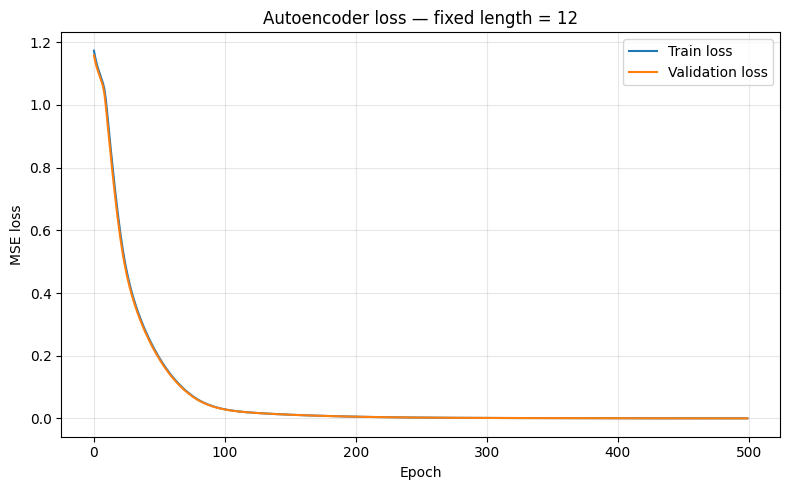

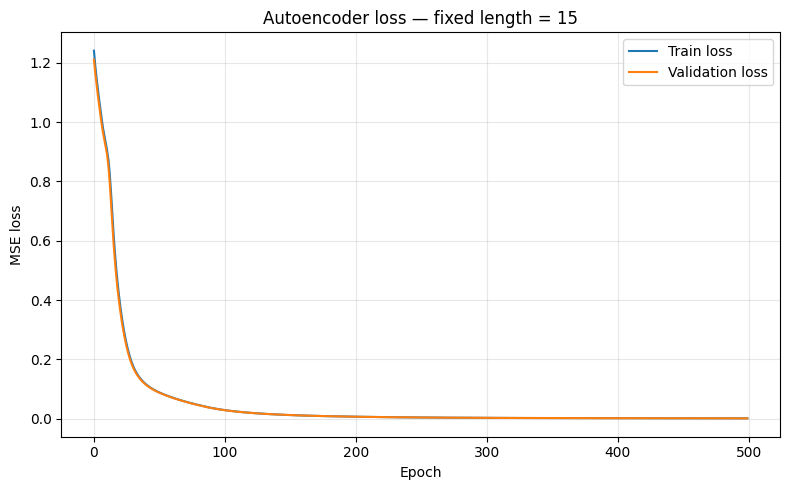

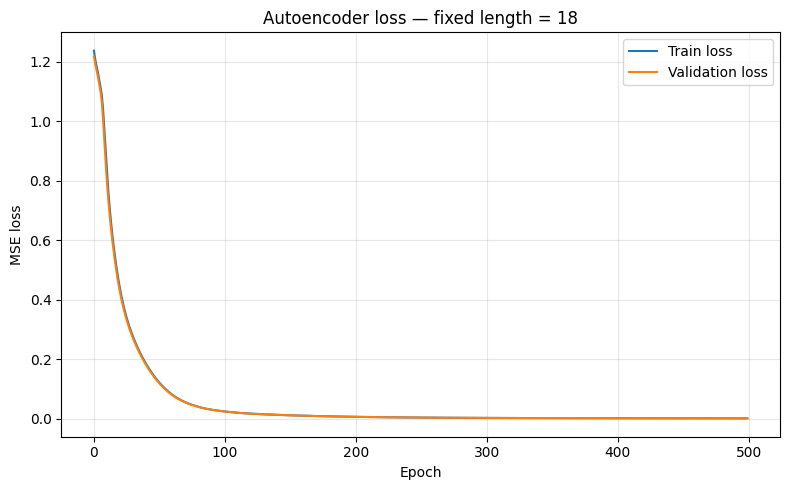

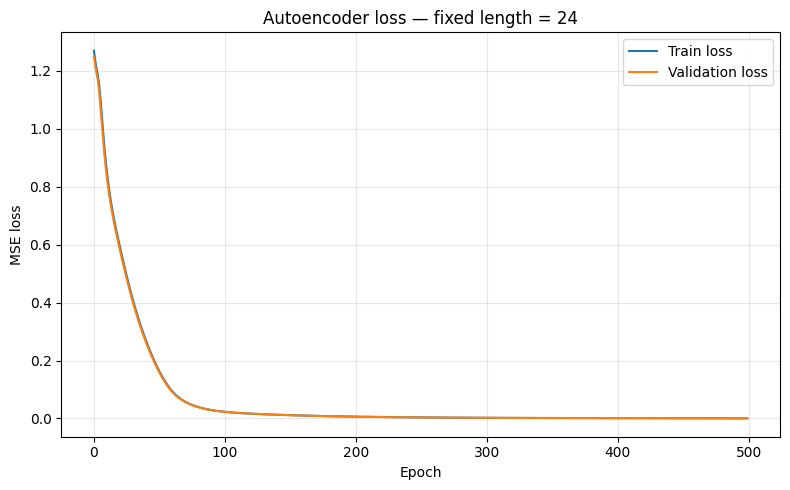

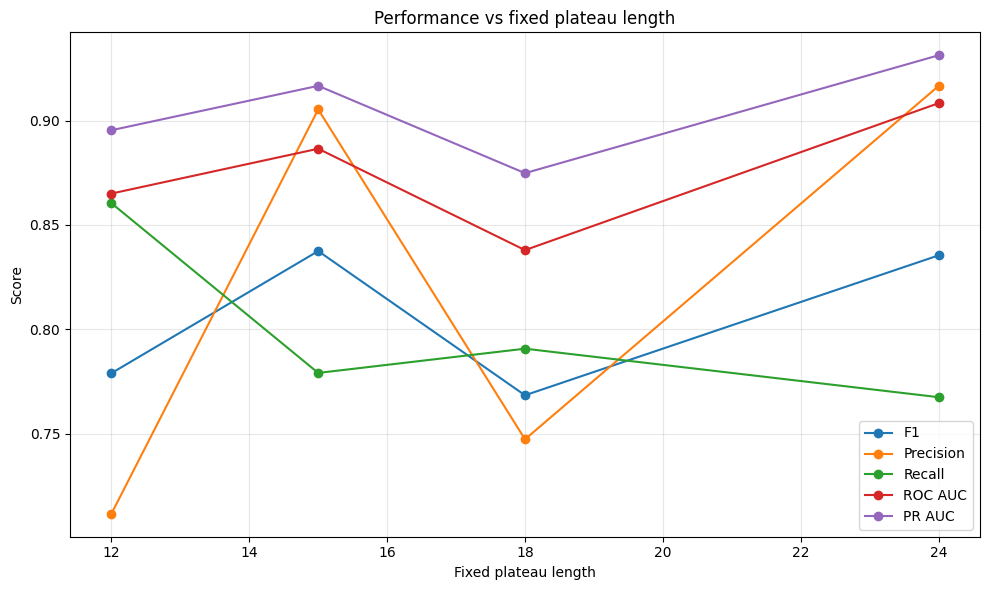

In [130]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# SETTINGS
# ============================================================

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

fixed_lengths = [12, 15, 18, 24]

EPOCHS = 500
BATCH_SIZE = 16
PATIENCE = 20
SEED = 42


# ============================================================
# FUNCTIONS
# ============================================================

def resample_plateau(flat, fixed_len):
    flat = np.asarray(flat, dtype=float)

    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)

    return np.interp(x_new, x_old, flat)


def extract_fixed_plateau(row, fixed_len):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    if len(flat) < 6:
        return None

    return resample_plateau(flat, fixed_len)


def build_autoencoder(input_dim):

    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(
        negative_slope=0.075
    )(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(
        input_layer,
        output_layer
    )

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(
            learning_rate=1e-4
        )
    )

    return model


def residual_features(residual):

    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),

        "res_std": residual.std(axis=1),

        "res_max_minus_min":
            residual.max(axis=1)
            - residual.min(axis=1),

        "res_mae":
            np.mean(np.abs(residual), axis=1),

        "res_mse":
            np.mean(residual**2, axis=1),

        "res_max_abs":
            np.max(np.abs(residual), axis=1)
    })


# ============================================================
# CLEAN DD
# ============================================================

dd_model = dataset[
    (dataset["label"] == 0)
    &
    (dataset["cavity"].isin(cavity_names))
].copy()

dd_model["pulse"] = (
    dd_model
    .groupby("cavity")
    .cumcount() + 1
)

bad_keys = set(
    zip(
        upper_outliers_dd_df["cavity"],
        upper_outliers_dd_df["pulse"]
    )
)

mask_good = [
    (cavity, pulse) not in bad_keys
    for cavity, pulse in zip(
        dd_model["cavity"],
        dd_model["pulse"]
    )
]

dd_clean = (
    dd_model
    .loc[mask_good]
    .reset_index(drop=True)
)


# ============================================================
# LABEL 1
# ============================================================

label1 = dataset[
    (dataset["label"] == 1)
    &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)


# ============================================================
# FULL EXPERIMENT FUNCTION
# ============================================================

def run_experiment(FIXED_LEN):

    print("\n" + "=" * 70)
    print(f"FIXED LENGTH = {FIXED_LEN}")
    print("=" * 70)

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # --------------------------------------------------------
    # DD plateaux
    # --------------------------------------------------------

    dd_vectors = []
    dd_metadata = []

    for _, row in dd_clean.iterrows():

        flat_fixed = extract_fixed_plateau(
            row,
            fixed_len=FIXED_LEN
        )

        if flat_fixed is not None:

            dd_vectors.append(flat_fixed)

            dd_metadata.append({
                "cavity": row["cavity"],
                "pulse": row["pulse"]
            })

    X_dd_all = np.vstack(dd_vectors)
    dd_metadata = pd.DataFrame(dd_metadata)

    print("Usable DD:", X_dd_all.shape)

    # --------------------------------------------------------
    # DD split 60 / 20 / 20
    # --------------------------------------------------------

    X_train, X_temp, meta_train, meta_temp = train_test_split(
        X_dd_all,
        dd_metadata,
        test_size=0.40,
        random_state=SEED,
        stratify=dd_metadata["cavity"]
    )

    X_val, X_test, meta_val, meta_test = train_test_split(
        X_temp,
        meta_temp,
        test_size=0.50,
        random_state=SEED,
        stratify=meta_temp["cavity"]
    )

    print("DD train:", X_train.shape)
    print("DD val:", X_val.shape)
    print("DD test:", X_test.shape)

    # --------------------------------------------------------
    # scaling
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # --------------------------------------------------------
    # fresh autoencoder
    # --------------------------------------------------------

    K.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    ae = build_autoencoder(FIXED_LEN)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = ae.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(
            X_val_scaled,
            X_val_scaled
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[early_stop]
    )

    print(
        "AE epochs:",
        len(history.history["loss"])
    )

    print(
        "Best val loss:",
        min(history.history["val_loss"])
    )

    # --------------------------------------------------------
    # DD residual features
    # --------------------------------------------------------

    X_val_rec = ae.predict(
        X_val_scaled,
        verbose=0
    )

    X_test_rec = ae.predict(
        X_test_scaled,
        verbose=0
    )

    res_val = (
        X_val_scaled
        - X_val_rec
    )

    res_test = (
        X_test_scaled
        - X_test_rec
    )

    features_val = residual_features(res_val)
    features_test = residual_features(res_test)

    # --------------------------------------------------------
    # Trip plateaux
    # --------------------------------------------------------

    trip_vectors = []
    trip_metadata = []

    for idx, row in label1.iterrows():

        flat_fixed = extract_fixed_plateau(
            row,
            fixed_len=FIXED_LEN
        )

        if flat_fixed is not None:

            trip_vectors.append(flat_fixed)

            trip_metadata.append({
                "original_index": idx,
                "cavity": row["cavity"]
            })

    X_trip_all = np.vstack(trip_vectors)
    trip_metadata = pd.DataFrame(trip_metadata)

    print(
        "Usable trips:",
        X_trip_all.shape
    )

    # --------------------------------------------------------
    # split trips 50 / 50
    # --------------------------------------------------------

    trip_indices = np.arange(
        len(X_trip_all)
    )

    idx_trip_val, idx_trip_test = train_test_split(
        trip_indices,
        test_size=0.50,
        random_state=SEED,
        stratify=trip_metadata["cavity"]
    )

    X_trip_val = X_trip_all[idx_trip_val]
    X_trip_test = X_trip_all[idx_trip_test]

    trip_meta_val = (
        trip_metadata
        .iloc[idx_trip_val]
        .reset_index(drop=True)
    )

    trip_meta_test = (
        trip_metadata
        .iloc[idx_trip_test]
        .reset_index(drop=True)
    )

    print(
        "Trip val:",
        len(X_trip_val)
    )

    print(
        "Trip test:",
        len(X_trip_test)
    )

    # --------------------------------------------------------
    # reset DD indices
    # --------------------------------------------------------

    meta_val = meta_val.reset_index(drop=True)
    meta_test = meta_test.reset_index(drop=True)

    features_val = features_val.reset_index(drop=True)
    features_test = features_test.reset_index(drop=True)

    # --------------------------------------------------------
    # sample matching DD per cavity
    # --------------------------------------------------------

    def sample_matching_dd(
        features,
        metadata,
        trip_meta,
        random_state
    ):

        selected = []

        for cavity_name, n_needed in (
            trip_meta["cavity"]
            .value_counts()
            .items()
        ):

            available = metadata[
                metadata["cavity"]
                == cavity_name
            ].index

            if len(available) < n_needed:
                raise ValueError(
                    f"{cavity_name}: need "
                    f"{n_needed} DD, have "
                    f"{len(available)}"
                )

            chosen = (
                pd.Series(available)
                .sample(
                    n=n_needed,
                    random_state=random_state
                )
                .tolist()
            )

            selected.extend(chosen)

        return (
            features
            .loc[selected]
            .reset_index(drop=True)
        )

    features_dd_val_bal = sample_matching_dd(
        features_val,
        meta_val,
        trip_meta_val,
        SEED
    )

    features_dd_test_bal = sample_matching_dd(
        features_test,
        meta_test,
        trip_meta_test,
        SEED + 1
    )

    # --------------------------------------------------------
    # trip reconstruction
    # --------------------------------------------------------

    X_trip_val_scaled = scaler.transform(
        X_trip_val
    )

    X_trip_test_scaled = scaler.transform(
        X_trip_test
    )

    X_trip_val_rec = ae.predict(
        X_trip_val_scaled,
        verbose=0
    )

    X_trip_test_rec = ae.predict(
        X_trip_test_scaled,
        verbose=0
    )

    res_trip_val = (
        X_trip_val_scaled
        - X_trip_val_rec
    )

    res_trip_test = (
        X_trip_test_scaled
        - X_trip_test_rec
    )

    features_trip_val = residual_features(
        res_trip_val
    )

    features_trip_test = residual_features(
        res_trip_test
    )

    # --------------------------------------------------------
    # classifier pool
    # --------------------------------------------------------

    dd_clf = features_dd_val_bal.copy()
    dd_clf["label"] = 0

    trip_clf = features_trip_val.copy()
    trip_clf["label"] = 1

    clf_pool = pd.concat(
        [dd_clf, trip_clf],
        ignore_index=True
    )

    X_clf = clf_pool.drop(
        columns="label"
    )

    y_clf = clf_pool["label"]

    # --------------------------------------------------------
    # XGBoost train / threshold validation
    # --------------------------------------------------------

    X_xgb_train, X_thresh_val, y_xgb_train, y_thresh_val = (
        train_test_split(
            X_clf,
            y_clf,
            test_size=0.30,
            random_state=SEED,
            stratify=y_clf
        )
    )

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=SEED
    )

    xgb.fit(
        X_xgb_train,
        y_xgb_train
    )

    # --------------------------------------------------------
    # best threshold on validation
    # --------------------------------------------------------

    val_prob = xgb.predict_proba(
        X_thresh_val
    )[:, 1]

    thresholds = np.linspace(
        0.01,
        0.99,
        199
    )

    f1_scores = []

    for threshold in thresholds:

        pred = (
            val_prob >= threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_thresh_val,
                pred
            )
        )

    best_idx = np.argmax(
        f1_scores
    )

    best_threshold = thresholds[
        best_idx
    ]

    best_val_f1 = f1_scores[
        best_idx
    ]

    # --------------------------------------------------------
    # final test
    # --------------------------------------------------------

    dd_final = features_dd_test_bal.copy()
    dd_final["label"] = 0

    trip_final = features_trip_test.copy()
    trip_final["label"] = 1

    final_test = pd.concat(
        [dd_final, trip_final],
        ignore_index=True
    )

    final_test = (
        final_test
        .sample(
            frac=1,
            random_state=SEED
        )
        .reset_index(drop=True)
    )

    X_final_test = final_test.drop(
        columns="label"
    )

    y_final_test = final_test[
        "label"
    ]

    test_prob = xgb.predict_proba(
        X_final_test
    )[:, 1]

    y_final_pred = (
        test_prob >= best_threshold
    ).astype(int)

    # --------------------------------------------------------
    # metrics
    # --------------------------------------------------------

    final_f1 = f1_score(
        y_final_test,
        y_final_pred
    )

    final_precision = precision_score(
        y_final_test,
        y_final_pred,
        zero_division=0
    )

    final_recall = recall_score(
        y_final_test,
        y_final_pred
    )

    roc_auc = roc_auc_score(
        y_final_test,
        test_prob
    )

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_final_test,
            test_prob
        )
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    cm = confusion_matrix(
        y_final_test,
        y_final_pred
    )

    print()
    print("Best threshold:", best_threshold)
    print("Validation F1:", best_val_f1)
    print("Test F1:", final_f1)
    print("Precision:", final_precision)
    print("Recall:", final_recall)
    print("ROC AUC:", roc_auc)
    print("PR AUC:", pr_auc)
    print("Confusion matrix:")
    print(cm)

    return {
        "fixed_len": FIXED_LEN,
        "dd_usable": len(X_dd_all),
        "trip_usable": len(X_trip_all),
        "ae_epochs": len(history.history["loss"]),
        "best_ae_val_loss": min(history.history["val_loss"]),
        "best_threshold": best_threshold,
        "validation_f1": best_val_f1,
        "test_f1": final_f1,
        "precision": final_precision,
        "recall": final_recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "history": history.history
    }


# ============================================================
# RUN ALL LENGTHS
# ============================================================

results = []

for L in fixed_lengths:

    result = run_experiment(
        FIXED_LEN=L
    )

    results.append(result)


# ============================================================
# RESULTS TABLE
# ============================================================

results_df = pd.DataFrame([
    {
        k: v
        for k, v in result.items()
        if k != "history"
    }
    for result in results
])

display(
    results_df[
        [
            "fixed_len",
            "dd_usable",
            "trip_usable",
            "ae_epochs",
            "best_ae_val_loss",
            "best_threshold",
            "validation_f1",
            "test_f1",
            "precision",
            "recall",
            "roc_auc",
            "pr_auc"
        ]
    ]
)


# ============================================================
# TRAIN / VALIDATION LOSS CURVES
# ONE FIGURE PER LENGTH
# ============================================================

for result in results:

    L = result["fixed_len"]
    h = result["history"]

    plt.figure(figsize=(8, 5))

    plt.plot(
        h["loss"],
        label="Train loss"
    )

    plt.plot(
        h["val_loss"],
        label="Validation loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")

    plt.title(
        f"Autoencoder loss — fixed length = {L}"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# PERFORMANCE VS LENGTH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["fixed_len"],
    results_df["test_f1"],
    marker="o",
    label="F1"
)

plt.plot(
    results_df["fixed_len"],
    results_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["fixed_len"],
    results_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["fixed_len"],
    results_df["roc_auc"],
    marker="o",
    label="ROC AUC"
)

plt.plot(
    results_df["fixed_len"],
    results_df["pr_auc"],
    marker="o",
    label="PR AUC"
)

plt.xlabel("Fixed plateau length")
plt.ylabel("Score")

plt.title(
    "Performance vs fixed plateau length"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

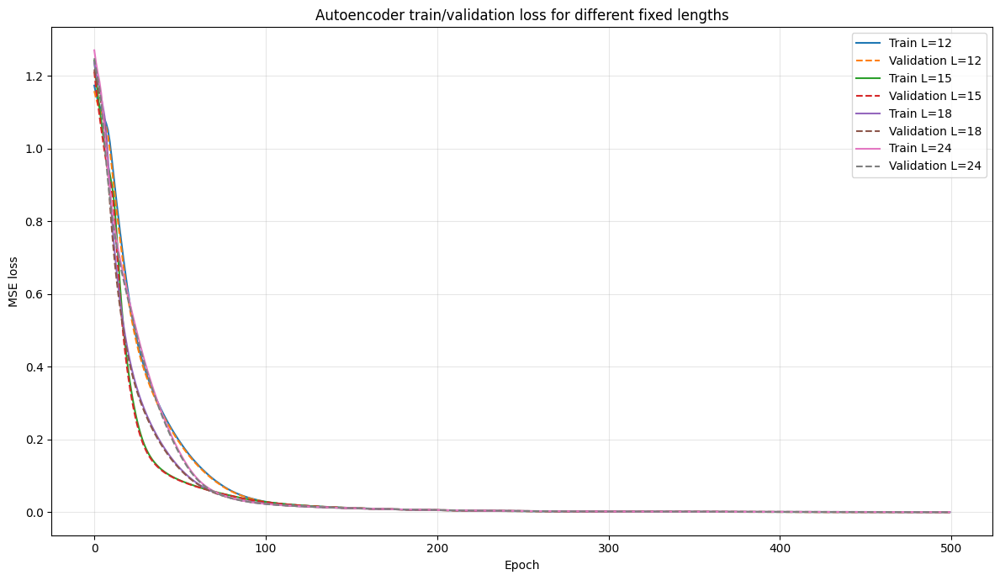

In [131]:
plt.figure(figsize=(12, 7))

for result in results:

    L = result["fixed_len"]
    h = result["history"]

    plt.plot(
        h["loss"],
        label=f"Train L={L}"
    )

    plt.plot(
        h["val_loss"],
        linestyle="--",
        label=f"Validation L={L}"
    )

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Autoencoder train/validation loss for different fixed lengths")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Total DD: 1747
Total trips: 234
Usable DD: (1724, 12)
Usable trips: (172, 12)

SEED / SHUFFLE: 10
AE train: (1016, 12)
AE validation: (345, 12)
DD test pool: (345, 12)
AE epochs: 500
Best AE validation loss: 0.000627692264970392
Trip development: 86
Trip final test: 86
Best threshold: 0.598989898989899
Validation F1: 0.9019607843137255

FINAL TEST
F1: 0.7857142857142857
Precision: 0.8048780487804879
Recall: 0.7674418604651163
ROC AUC: 0.8731070849107625
PR AUC: 0.8908204281508721
Confusion matrix:
[[70 16]
 [20 66]]

TRUE POSITIVES


,seed,cavity,original_index,prob_trip
93,10,HBL-010RFC:RFS-DIG-101,1,0.989441
132,10,HBL-010RFC:RFS-DIG-101,20,0.989441
130,10,HBL-010RFC:RFS-DIG-101,32,0.989441
23,10,HBL-010RFC:RFS-DIG-101,36,0.989441
113,10,HBL-010RFC:RFS-DIG-101,47,0.989441
...,...,...,...,...
96,10,HBL-010RFC:RFS-DIG-401,149,0.878354
164,10,HBL-010RFC:RFS-DIG-401,153,0.878354
116,10,HBL-010RFC:RFS-DIG-401,181,0.860965
44,10,HBL-010RFC:RFS-DIG-401,191,0.905573



FALSE POSITIVES


,seed,cavity,original_index,prob_trip
43,10,HBL-010RFC:RFS-DIG-101,18,0.989441
71,10,HBL-010RFC:RFS-DIG-101,936,0.777904
154,10,HBL-010RFC:RFS-DIG-101,1004,0.824232
42,10,HBL-010RFC:RFS-DIG-201,660,0.698881
5,10,HBL-010RFC:RFS-DIG-201,1151,0.610005
59,10,HBL-010RFC:RFS-DIG-201,1309,0.689191
138,10,HBL-010RFC:RFS-DIG-201,1358,0.732254
2,10,HBL-010RFC:RFS-DIG-201,1439,0.704632
64,10,HBL-010RFC:RFS-DIG-301,705,0.749561
161,10,HBL-010RFC:RFS-DIG-301,712,0.702475



SEED / SHUFFLE: 20
AE train: (1018, 12)
AE validation: (345, 12)
DD test pool: (345, 12)
AE epochs: 500
Best AE validation loss: 0.0033450210466980934
Trip development: 86
Trip final test: 86
Best threshold: 0.24757575757575756
Validation F1: 0.75

FINAL TEST
F1: 0.7564766839378239
Precision: 0.6822429906542056
Recall: 0.8488372093023255
ROC AUC: 0.8557328285559762
PR AUC: 0.8714424261201508
Confusion matrix:
[[52 34]
 [13 73]]

TRUE POSITIVES


...


TP PER CAVITY


,cavity,TP_count
0,HBL-010RFC:RFS-DIG-101,112
1,HBL-010RFC:RFS-DIG-201,48
2,HBL-010RFC:RFS-DIG-301,39
3,HBL-010RFC:RFS-DIG-401,115



FP PER CAVITY


,cavity,FP_count
0,HBL-010RFC:RFS-DIG-101,17
1,HBL-010RFC:RFS-DIG-201,24
2,HBL-010RFC:RFS-DIG-301,22
3,HBL-010RFC:RFS-DIG-401,28



5 SHUFFLES — MEAN ± STD
test_f1        : 0.7484 ± 0.0347
precision      : 0.8096 ± 0.1256
recall         : 0.7302 ± 0.1474
roc_auc        : 0.8446 ± 0.0299
pr_auc         : 0.8725 ± 0.0177


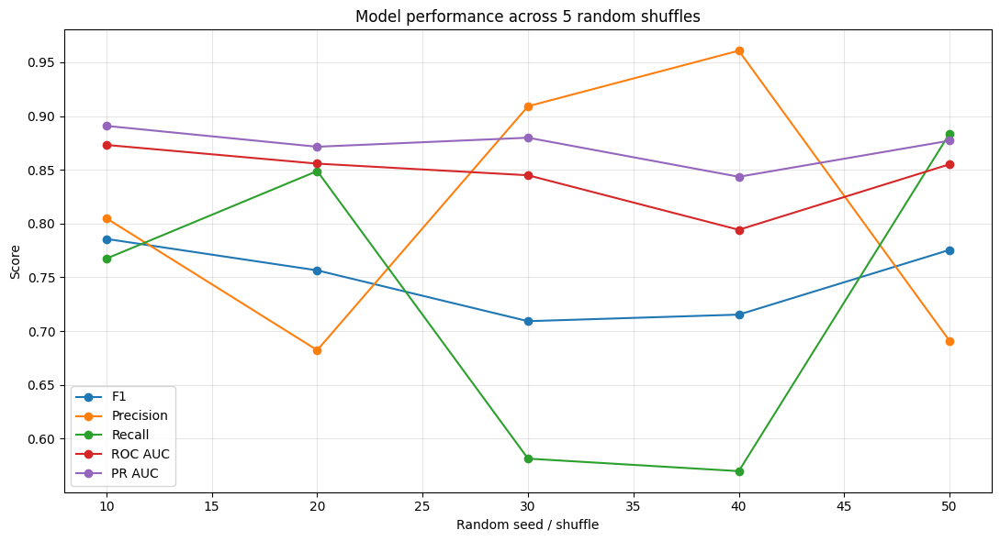

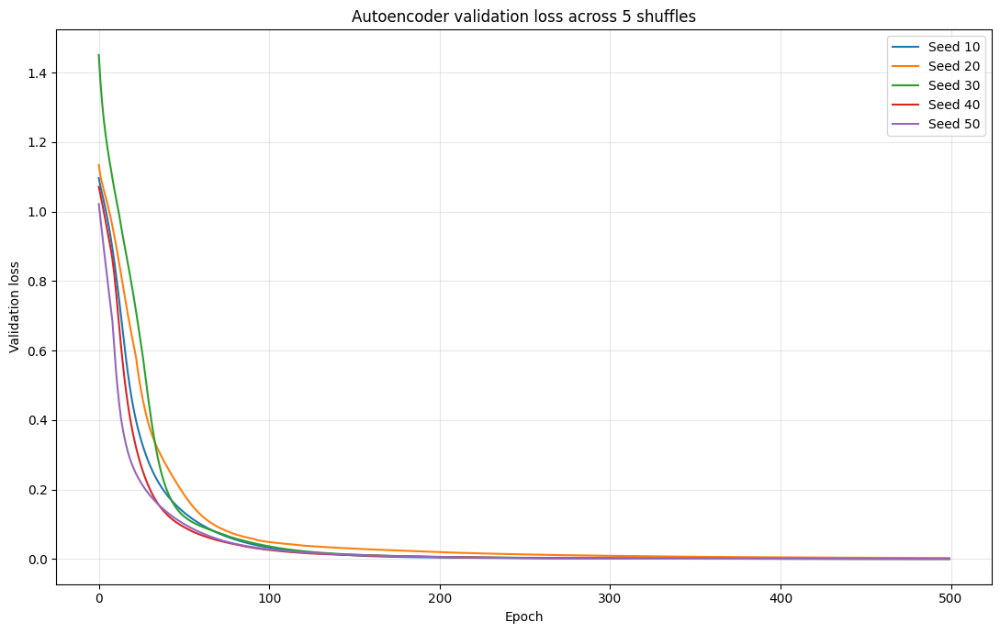

In [140]:
# ============================================================
# COMPLETE MODEL
# 4 CAVITIES MIXED + 5 SHUFFLES
# WITH TP / FP CAVITY + ORIGINAL INDEX
# ============================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# SETTINGS
# ============================================================

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

FIXED_LEN = 12
EPOCHS = 500
BATCH_SIZE = 16
PATIENCE = 20
WINDOW_SIZE = 6

SEEDS = [10, 20, 30, 40, 50]

FEATURE_COLUMNS = [
    "res_mean",
    "res_std",
    "res_max_minus_min",
    "res_mae",
    "res_mse",
    "res_max_abs"
]


# ============================================================
# VALUE COLUMNS
# ============================================================

value_columns = [c for c in dataset.columns if c.startswith("value_")]


# ============================================================
# DATA
# ============================================================

dd_all = dataset[
    (dataset["label"] == 0) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

trip_all = dataset[
    (dataset["label"] == 1) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print("Total DD:", len(dd_all))
print("Total trips:", len(trip_all))


# ============================================================
# PLATEAU FUNCTIONS
# ============================================================

def get_flat_plateau(y, slope_threshold=0.1, amp_min=18, amp_max=24):
    y = np.asarray(y, dtype=float)
    slope = np.diff(y)

    flat_mask = np.zeros(len(y), dtype=bool)
    flat_mask[1:] = np.abs(slope) <= slope_threshold
    flat_mask &= (y >= amp_min) & (y <= amp_max)

    segments = []
    start = None

    for i, flag in enumerate(flat_mask):
        if flag and start is None:
            start = i
        elif not flag and start is not None:
            segments.append((start, i))
            start = None

    if start is not None:
        segments.append((start, len(y)))

    if not segments:
        return None

    return max(segments, key=lambda s: s[1] - s[0])


def resample_plateau(flat, fixed_len):
    flat = np.asarray(flat, dtype=float)
    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)
    return np.interp(x_new, x_old, flat)


def extract_fixed_plateau(row, fixed_len=FIXED_LEN):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    if len(flat) < 6:
        return None

    return resample_plateau(flat, fixed_len)


# ============================================================
# DD OUTLIER FEATURE
# ============================================================

def mean_window_range(row):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return np.nan

    start, end = plateau
    flat = y[start:end]

    window_ranges = []

    for j in range(0, len(flat) - WINDOW_SIZE + 1, WINDOW_SIZE):
        window = flat[j:j + WINDOW_SIZE]
        window_ranges.append(window.max() - window.min())

    if len(window_ranges) == 0:
        return np.nan

    return np.mean(window_ranges)


def remove_training_dd_outliers(df):
    df = df.copy()

    df["mean_window_range"] = [
        mean_window_range(row)
        for _, row in df.iterrows()
    ]

    cleaned = []

    for cavity in df["cavity"].unique():
        temp = df[df["cavity"] == cavity].copy()
        values = temp["mean_window_range"].dropna()

        if len(values) == 0:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr

        temp = temp[temp["mean_window_range"] <= upper_bound]
        cleaned.append(temp)

    if len(cleaned) == 0:
        return pd.DataFrame(columns=df.columns)

    return pd.concat(cleaned, ignore_index=True)


# ============================================================
# DATAFRAME -> PLATEAUX
# ============================================================

def dataframe_to_plateaux(df, fixed_len=FIXED_LEN):
    vectors = []
    metadata = []

    for idx, row in df.iterrows():
        plateau = extract_fixed_plateau(row, fixed_len=fixed_len)

        if plateau is not None:
            vectors.append(plateau)
            metadata.append({
                "index": idx,
                "cavity": row["cavity"]
            })

    if len(vectors) == 0:
        return (
            np.empty((0, fixed_len)),
            pd.DataFrame(columns=["index", "cavity"])
        )

    return np.vstack(vectors), pd.DataFrame(metadata)


# ============================================================
# AUTOENCODER
# ============================================================

def build_autoencoder(input_dim):
    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(negative_slope=0.075)(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(input_layer, output_layer)

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(learning_rate=1e-4)
    )

    return model


# ============================================================
# RESIDUAL FEATURES
# ============================================================

def residual_features(residual):
    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),
        "res_std": residual.std(axis=1),
        "res_max_minus_min": residual.max(axis=1) - residual.min(axis=1),
        "res_mae": np.mean(np.abs(residual), axis=1),
        "res_mse": np.mean(residual**2, axis=1),
        "res_max_abs": np.max(np.abs(residual), axis=1)
    })


# ============================================================
# PRE-EXTRACT DD
# ============================================================

dd_vectors = []
dd_metadata = []

for idx, row in dd_all.iterrows():
    flat_fixed = extract_fixed_plateau(row, FIXED_LEN)

    if flat_fixed is not None:
        dd_vectors.append(flat_fixed)
        dd_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_dd_all = np.vstack(dd_vectors)
dd_metadata = pd.DataFrame(dd_metadata)

print("Usable DD:", X_dd_all.shape)


# ============================================================
# PRE-EXTRACT TRIPS
# ============================================================

trip_vectors = []
trip_metadata = []

for idx, row in trip_all.iterrows():
    flat_fixed = extract_fixed_plateau(row, FIXED_LEN)

    if flat_fixed is not None:
        trip_vectors.append(flat_fixed)
        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_trip_all = np.vstack(trip_vectors)
trip_metadata = pd.DataFrame(trip_metadata)

print("Usable trips:", X_trip_all.shape)


# ============================================================
# DD MATCHING FUNCTION
# ============================================================

def sample_matching_dd_indices(metadata, trip_meta, random_state):
    selected = []
    rng = np.random.RandomState(random_state)

    for cavity_name, n_needed in trip_meta["cavity"].value_counts().items():
        available = metadata[
            metadata["cavity"] == cavity_name
        ].index.to_numpy()

        if len(available) < n_needed:
            raise ValueError(
                f"{cavity_name}: need {n_needed} DD, have {len(available)}"
            )

        chosen = rng.choice(
            available,
            size=n_needed,
            replace=False
        )

        selected.extend(chosen.tolist())

    return np.array(selected, dtype=int)


# ============================================================
# STORAGE
# ============================================================

all_results = []
all_histories = {}
all_test_predictions = []


# ============================================================
# 5 SHUFFLES
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 80)
    print("SEED / SHUFFLE:", seed)
    print("=" * 80)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


    # ========================================================
    # DD SPLIT 60 / 20 / 20
    # ========================================================

    dd_indices = np.arange(len(X_dd_all))

    idx_dd_train, idx_dd_temp = train_test_split(
        dd_indices,
        test_size=0.40,
        random_state=seed,
        stratify=dd_metadata["cavity"]
    )

    idx_dd_val, idx_dd_test = train_test_split(
        idx_dd_temp,
        test_size=0.50,
        random_state=seed,
        stratify=dd_metadata.iloc[idx_dd_temp]["cavity"]
    )


    # ========================================================
    # CLEAN AE TRAIN DD ONLY
    # ========================================================

    dd_train_original_indices = (
        dd_metadata
        .iloc[idx_dd_train]["original_index"]
        .to_numpy()
    )

    dd_train_df = dd_all.iloc[
        dd_train_original_indices
    ].copy()

    dd_train_clean = remove_training_dd_outliers(dd_train_df)

    X_train, _ = dataframe_to_plateaux(
        dd_train_clean,
        FIXED_LEN
    )

    X_val = X_dd_all[idx_dd_val]
    X_test_dd = X_dd_all[idx_dd_test]

    meta_val = (
        dd_metadata
        .iloc[idx_dd_val]
        .reset_index(drop=True)
    )

    meta_test = (
        dd_metadata
        .iloc[idx_dd_test]
        .reset_index(drop=True)
    )

    print("AE train:", X_train.shape)
    print("AE validation:", X_val.shape)
    print("DD test pool:", X_test_dd.shape)


    # ========================================================
    # SCALER
    # ========================================================

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_dd_scaled = scaler.transform(X_test_dd)


    # ========================================================
    # AUTOENCODER
    # ========================================================

    K.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    ae = build_autoencoder(FIXED_LEN)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = ae.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(X_val_scaled, X_val_scaled),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[early_stop]
    )

    all_histories[seed] = history.history

    print("AE epochs:", len(history.history["loss"]))
    print("Best AE validation loss:", min(history.history["val_loss"]))


    # ========================================================
    # DD RESIDUAL FEATURES
    # ========================================================

    X_val_rec = ae.predict(X_val_scaled, verbose=0)
    X_test_dd_rec = ae.predict(X_test_dd_scaled, verbose=0)

    res_dd_val = X_val_scaled - X_val_rec
    res_dd_test = X_test_dd_scaled - X_test_dd_rec

    features_dd_val = residual_features(res_dd_val).reset_index(drop=True)
    features_dd_test = residual_features(res_dd_test).reset_index(drop=True)


    # ========================================================
    # TRIP SPLIT 50 / 50
    # ========================================================

    trip_indices = np.arange(len(X_trip_all))

    idx_trip_dev, idx_trip_test = train_test_split(
        trip_indices,
        test_size=0.50,
        random_state=seed,
        stratify=trip_metadata["cavity"]
    )

    X_trip_dev = X_trip_all[idx_trip_dev]
    X_trip_test = X_trip_all[idx_trip_test]

    trip_meta_dev = (
        trip_metadata
        .iloc[idx_trip_dev]
        .reset_index(drop=True)
    )

    trip_meta_test = (
        trip_metadata
        .iloc[idx_trip_test]
        .reset_index(drop=True)
    )

    print("Trip development:", len(X_trip_dev))
    print("Trip final test:", len(X_trip_test))


    # ========================================================
    # TRIP RESIDUAL FEATURES
    # ========================================================

    X_trip_dev_scaled = scaler.transform(X_trip_dev)
    X_trip_test_scaled = scaler.transform(X_trip_test)

    X_trip_dev_rec = ae.predict(X_trip_dev_scaled, verbose=0)
    X_trip_test_rec = ae.predict(X_trip_test_scaled, verbose=0)

    res_trip_dev = X_trip_dev_scaled - X_trip_dev_rec
    res_trip_test = X_trip_test_scaled - X_trip_test_rec

    features_trip_dev = residual_features(res_trip_dev)
    features_trip_test = residual_features(res_trip_test)


    # ========================================================
    # BALANCE DD DEVELOPMENT + TEST BY CAVITY
    # ========================================================

    idx_dd_dev_bal = sample_matching_dd_indices(
        meta_val,
        trip_meta_dev,
        seed
    )

    idx_dd_test_bal = sample_matching_dd_indices(
        meta_test,
        trip_meta_test,
        seed + 100
    )

    features_dd_dev_bal = (
        features_dd_val
        .iloc[idx_dd_dev_bal]
        .reset_index(drop=True)
    )

    features_dd_test_bal = (
        features_dd_test
        .iloc[idx_dd_test_bal]
        .reset_index(drop=True)
    )

    meta_dd_test_bal = (
        meta_test
        .iloc[idx_dd_test_bal]
        .reset_index(drop=True)
    )


    # ========================================================
    # CLASSIFIER DEVELOPMENT
    # ========================================================

    dd_clf = features_dd_dev_bal.copy()
    dd_clf["label"] = 0

    trip_clf = features_trip_dev.copy()
    trip_clf["label"] = 1

    classifier_pool = pd.concat(
        [dd_clf, trip_clf],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_clf = classifier_pool[FEATURE_COLUMNS]
    y_clf = classifier_pool["label"]


    # ========================================================
    # XGBOOST TRAIN / THRESHOLD VALIDATION
    # ========================================================

    X_xgb_train, X_threshold_val, y_xgb_train, y_threshold_val = train_test_split(
        X_clf,
        y_clf,
        test_size=0.30,
        random_state=seed,
        stratify=y_clf
    )

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=seed,
        n_jobs=-1
    )

    xgb.fit(
        X_xgb_train,
        y_xgb_train
    )


    # ========================================================
    # BEST THRESHOLD
    # ========================================================

    val_prob = xgb.predict_proba(
        X_threshold_val
    )[:, 1]

    thresholds = np.linspace(
        0.01,
        0.99,
        199
    )

    f1_scores = []

    for threshold in thresholds:
        val_pred = (val_prob >= threshold).astype(int)
        f1_scores.append(
            f1_score(
                y_threshold_val,
                val_pred
            )
        )

    best_index = np.argmax(f1_scores)
    best_threshold = thresholds[best_index]
    validation_f1 = f1_scores[best_index]

    print("Best threshold:", best_threshold)
    print("Validation F1:", validation_f1)


    # ========================================================
    # FINAL TEST WITH METADATA
    # ========================================================

    dd_final = features_dd_test_bal.copy()
    dd_final["label"] = 0
    dd_final["cavity"] = meta_dd_test_bal["cavity"].to_numpy()
    dd_final["original_index"] = meta_dd_test_bal["original_index"].to_numpy()
    dd_final["source"] = "DD"

    trip_final = features_trip_test.copy()
    trip_final["label"] = 1
    trip_final["cavity"] = trip_meta_test["cavity"].to_numpy()
    trip_final["original_index"] = trip_meta_test["original_index"].to_numpy()
    trip_final["source"] = "Trip"

    final_test = pd.concat(
        [dd_final, trip_final],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_final = final_test[FEATURE_COLUMNS]
    y_final = final_test["label"]


    # ========================================================
    # FINAL PREDICTION
    # ========================================================

    test_prob = xgb.predict_proba(
        X_final
    )[:, 1]

    y_pred = (
        test_prob >= best_threshold
    ).astype(int)

    final_test["prob_trip"] = test_prob
    final_test["predicted_label"] = y_pred
    final_test["seed"] = seed


    # ========================================================
    # TP / FP / TN / FN
    # ========================================================

    final_test["classification"] = np.select(
        [
            (final_test["label"] == 1) & (final_test["predicted_label"] == 1),
            (final_test["label"] == 0) & (final_test["predicted_label"] == 1),
            (final_test["label"] == 0) & (final_test["predicted_label"] == 0),
            (final_test["label"] == 1) & (final_test["predicted_label"] == 0)
        ],
        ["TP", "FP", "TN", "FN"],
        default="Unknown"
    )

    all_test_predictions.append(
        final_test.copy()
    )


    # ========================================================
    # METRICS
    # ========================================================

    test_f1 = f1_score(y_final, y_pred)

    precision = precision_score(
        y_final,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_final,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_final,
        test_prob
    )

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_final,
        test_prob
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    cm = confusion_matrix(
        y_final,
        y_pred
    )

    print("\nFINAL TEST")
    print("F1:", test_f1)
    print("Precision:", precision)
    print("Recall:", recall)
    print("ROC AUC:", roc_auc)
    print("PR AUC:", pr_auc)
    print("Confusion matrix:")
    print(cm)


    # ========================================================
    # TP / FP FOR CURRENT SEED
    # ========================================================

    tp_seed = final_test[
        final_test["classification"] == "TP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ].sort_values(
        ["cavity", "original_index"]
    )

    fp_seed = final_test[
        final_test["classification"] == "FP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ].sort_values(
        ["cavity", "original_index"]
    )

    print("\nTRUE POSITIVES")
    display(tp_seed)

    print("\nFALSE POSITIVES")
    display(fp_seed)


    # ========================================================
    # SAVE METRICS
    # ========================================================

    all_results.append({
        "seed": seed,
        "ae_train": len(X_train),
        "ae_val": len(X_val),
        "trip_dev": len(X_trip_dev),
        "trip_test": len(X_trip_test),
        "best_threshold": best_threshold,
        "validation_f1": validation_f1,
        "test_f1": test_f1,
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "ae_epochs": len(history.history["loss"]),
        "ae_best_val_loss": min(history.history["val_loss"])
    })


# ============================================================
# RESULTS TABLE
# ============================================================

results_shuffle = pd.DataFrame(
    all_results
)

display(
    results_shuffle
)


# ============================================================
# ALL TEST PREDICTIONS
# ============================================================

all_test_predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)


# ============================================================
# ALL TRUE POSITIVES
# ============================================================

all_tp = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "TP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ]
    .sort_values(
        ["seed", "cavity", "original_index"]
    )
    .reset_index(drop=True)
)

print("\nALL TRUE POSITIVES")
display(all_tp)


# ============================================================
# ALL FALSE POSITIVES
# ============================================================

all_fp = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "FP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ]
    .sort_values(
        ["seed", "cavity", "original_index"]
    )
    .reset_index(drop=True)
)

print("\nALL FALSE POSITIVES")
display(all_fp)


# ============================================================
# TP COUNT PER CAVITY
# ============================================================

tp_per_cavity = (
    all_tp
    .groupby("cavity")
    .size()
    .rename("TP_count")
    .reset_index()
)

print("\nTP PER CAVITY")
display(tp_per_cavity)


# ============================================================
# FP COUNT PER CAVITY
# ============================================================

fp_per_cavity = (
    all_fp
    .groupby("cavity")
    .size()
    .rename("FP_count")
    .reset_index()
)

print("\nFP PER CAVITY")
display(fp_per_cavity)


# ============================================================
# MEAN ± STD ACROSS 5 SHUFFLES
# ============================================================

metrics = [
    "test_f1",
    "precision",
    "recall",
    "roc_auc",
    "pr_auc"
]

print("\n" + "=" * 60)
print("5 SHUFFLES — MEAN ± STD")
print("=" * 60)

for metric in metrics:
    print(
        f"{metric:15s}: "
        f"{results_shuffle[metric].mean():.4f} "
        f"± "
        f"{results_shuffle[metric].std():.4f}"
    )


# ============================================================
# PERFORMANCE ACROSS SHUFFLES
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(results_shuffle["seed"], results_shuffle["test_f1"], marker="o", label="F1")
plt.plot(results_shuffle["seed"], results_shuffle["precision"], marker="o", label="Precision")
plt.plot(results_shuffle["seed"], results_shuffle["recall"], marker="o", label="Recall")
plt.plot(results_shuffle["seed"], results_shuffle["roc_auc"], marker="o", label="ROC AUC")
plt.plot(results_shuffle["seed"], results_shuffle["pr_auc"], marker="o", label="PR AUC")

plt.xlabel("Random seed / shuffle")
plt.ylabel("Score")
plt.title("Model performance across 5 random shuffles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# AE VALIDATION LOSS
# ============================================================

plt.figure(figsize=(11, 7))

for seed, history in all_histories.items():
    plt.plot(history["val_loss"], label=f"Seed {seed}")

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Autoencoder validation loss across 5 shuffles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,cavity,TP
0,HBL-010RFC:RFS-DIG-101,112
1,HBL-010RFC:RFS-DIG-201,48
2,HBL-010RFC:RFS-DIG-301,39
3,HBL-010RFC:RFS-DIG-401,115


,cavity,FP
0,HBL-010RFC:RFS-DIG-101,17
1,HBL-010RFC:RFS-DIG-201,24
2,HBL-010RFC:RFS-DIG-301,22
3,HBL-010RFC:RFS-DIG-401,28


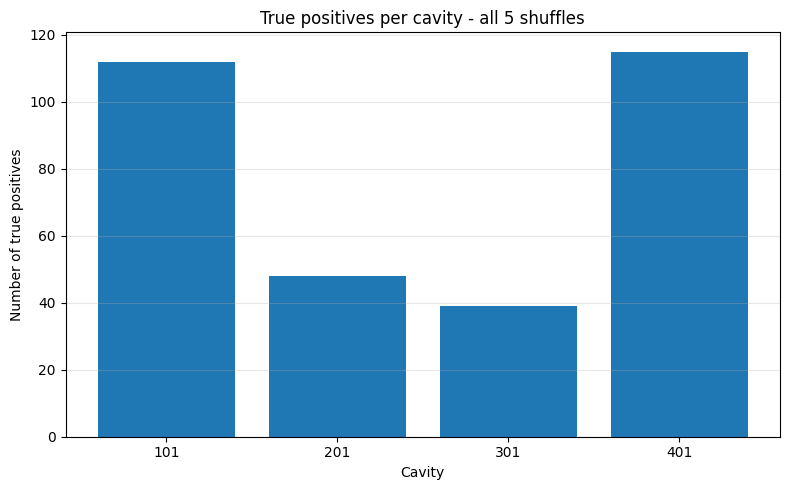

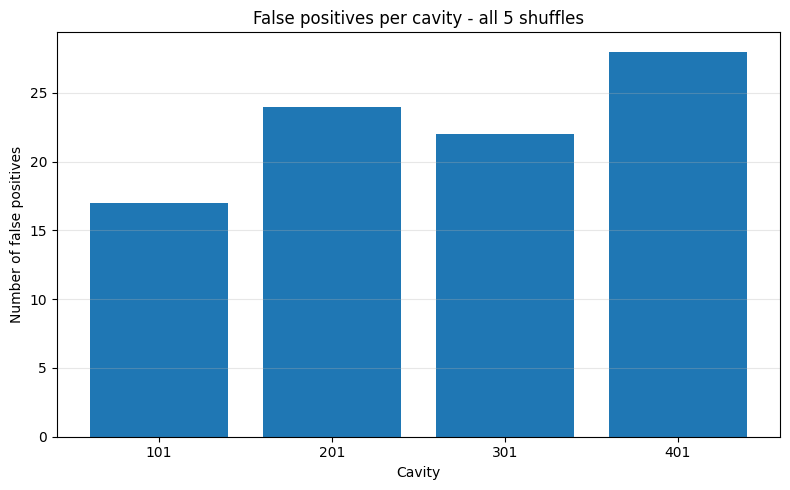

In [141]:
# ============================================================
# SAVE ALL PREDICTIONS
# ============================================================

all_test_predictions_df.to_csv("all_test_predictions.csv", index=False)
all_tp.to_csv("true_positives.csv", index=False)
all_fp.to_csv("false_positives.csv", index=False)


# ============================================================
# TP / FP COUNTS PER CAVITY
# ============================================================

tp_per_cavity = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "TP"
    ]
    .groupby("cavity")
    .size()
    .reset_index(name="TP")
)

fp_per_cavity = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "FP"
    ]
    .groupby("cavity")
    .size()
    .reset_index(name="FP")
)

display(tp_per_cavity)
display(fp_per_cavity)


# ============================================================
# SHORT CAVITY NAMES
# ============================================================

tp_per_cavity["cavity_short"] = tp_per_cavity["cavity"].str.extract(r"(\d{3})$")
fp_per_cavity["cavity_short"] = fp_per_cavity["cavity"].str.extract(r"(\d{3})$")


# ============================================================
# BAR PLOT: TRUE POSITIVES PER CAVITY
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    tp_per_cavity["cavity_short"],
    tp_per_cavity["TP"]
)

plt.xlabel("Cavity")
plt.ylabel("Number of true positives")
plt.title("True positives per cavity - all 5 shuffles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# BAR PLOT: FALSE POSITIVES PER CAVITY
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    fp_per_cavity["cavity_short"],
    fp_per_cavity["FP"]
)

plt.xlabel("Cavity")
plt.ylabel("Number of false positives")
plt.title("False positives per cavity - all 5 shuffles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Clustering

- **Whole waveform**: All 64 waveform bins, including differences in pulse duration and amplitude.
- **Plateau**: The flat segment extracted using the final model's rules and interpolated to 12 points.
- **Centered plateau**: Each plateau with its own mean amplitude subtracted, removing the amplitude offset to examine differences in shape.

Each representation is standardized feature by feature and **displayed in two dimensions using PCA**.
**K-means is applied to the standardized features before the two-dimensional projection**.
The number of clusters is selected from k=2 through 8 by maximizing the silhouette score.
Normal/trip labels and cavity identifiers are used only for coloring and summaries;
they are not used to determine the clusters.

These plots show data before outlier removal, including normal pulses excluded from
model training. Pulses with no valid plateau, or a plateau shorter than six points,
are excluded from the two plateau representations.


In [142]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

CLUSTER_CAVITIES = [
    "HBL-010RFC:RFS-DIG-101", "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301", "HBL-010RFC:RFS-DIG-401",
]
CLUSTER_FIXED_LEN = 12
CLUSTER_K_VALUES = range(2, 9)
CLUSTER_RANDOM_STATE = 42

# Reuse the notebook's input if available; otherwise load the saved input.
if "dataset" in globals():
    cluster_source = dataset.copy()
else:
    cluster_data_path = next(
        (p for p in [Path("cavity_pulses_labeled.parquet"),
                     Path("cavity_dataset/cavity_pulses_labeled.parquet")]
         if p.is_file()),
        None,
    )
    if cluster_data_path is None:
        raise FileNotFoundError("cavity_pulses_labeled.parquet was not found")
    cluster_source = pd.read_parquet(cluster_data_path)

cluster_value_columns = sorted(
    [c for c in cluster_source.columns if c.startswith("value_")],
    key=lambda c: int(c.split("_")[-1]),
)
cluster_df = cluster_source.loc[
    cluster_source["cavity"].isin(CLUSTER_CAVITIES),
    ["cavity", *cluster_value_columns, "label"],
].copy()
cluster_df.insert(0, "dataset_index", cluster_df.index)
cluster_df = cluster_df.reset_index(drop=True)
cluster_df["cavity_short"] = cluster_df["cavity"].str.extract(r"(\d{3})$")
cluster_df["label_name"] = cluster_df["label"].map({0: "Normal (DD)", 1: "Trip (PM)"})
cluster_full_x = cluster_df[cluster_value_columns].to_numpy(dtype=float)
if not len(cluster_df) or not np.isfinite(cluster_full_x).all():
    raise ValueError("Expected nonempty, finite waveform data")

print(f"Selected pulses: {len(cluster_df):,}; waveform length: {cluster_full_x.shape[1]}")
display(pd.crosstab(cluster_df["cavity_short"], cluster_df["label_name"]).rename_axis("cavity"))


Selected pulses: 1,981; waveform length: 64


label_name,Normal (DD),Trip (PM)
cavity,,
101,437,59
201,437,59
301,437,59
401,436,57


In [143]:
def cluster_extract_plateau(y, fixed_len=CLUSTER_FIXED_LEN):
    # Same longest-flat-segment rule as the final model.
    y = np.asarray(y, dtype=float)
    flat_mask = np.zeros(len(y), dtype=bool)
    flat_mask[1:] = np.abs(np.diff(y)) <= 0.1
    flat_mask &= (y >= 18) & (y <= 24)
    edges = np.diff(np.r_[False, flat_mask, False].astype(int))
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    if len(starts) == 0:
        return None
    best = np.argmax(ends - starts)
    flat = y[starts[best]:ends[best]]
    if len(flat) < 6:
        return None
    return np.interp(np.linspace(0, 1, fixed_len),
                     np.linspace(0, 1, len(flat)), flat)

cluster_plateau_list = [cluster_extract_plateau(y) for y in cluster_full_x]
cluster_keep = np.array([p is not None for p in cluster_plateau_list])
if cluster_keep.sum() < 10:
    raise ValueError("Too few usable plateaux for clustering")
cluster_plateau_x = np.vstack([p for p in cluster_plateau_list if p is not None])
cluster_plateau_meta = cluster_df.loc[cluster_keep].reset_index(drop=True)
cluster_centered_x = cluster_plateau_x - cluster_plateau_x.mean(axis=1, keepdims=True)

cluster_availability = cluster_df[["cavity_short", "label_name"]].copy()
cluster_availability["usable_plateau"] = cluster_keep.astype(int)
cluster_availability = cluster_availability.groupby(
    ["cavity_short", "label_name"]
)["usable_plateau"].agg(total="size", usable="sum")
cluster_availability["excluded"] = cluster_availability["total"] - cluster_availability["usable"]
print(f"Usable plateaux: {cluster_keep.sum():,}; excluded: {(~cluster_keep).sum():,}")
display(cluster_availability)

cluster_views = {
    "Whole waveform": {"x": cluster_full_x, "meta": cluster_df},
    "Plateau": {"x": cluster_plateau_x, "meta": cluster_plateau_meta},
    "Centered plateau": {"x": cluster_centered_x, "meta": cluster_plateau_meta},
}


Usable plateaux: 1,896; excluded: 85


total  usable  excluded
cavity_short label_name                          
101          Normal (DD)    437     436         1
             Trip (PM)       59      59         0
201          Normal (DD)    437     427        10
             Trip (PM)       59      28        31
301          Normal (DD)    437     427        10
             Trip (PM)       59      28        31
401          Normal (DD)    436     434         2
             Trip (PM)       57      57         0

,representation,n_pulses,n_features,selected_k,silhouette,PCA_2D_variance
0,Whole waveform,1981,64,8,0.9688,0.8779
1,Plateau,1896,12,6,0.9985,1.0000
2,Centered plateau,1896,12,2,0.8573,0.9175


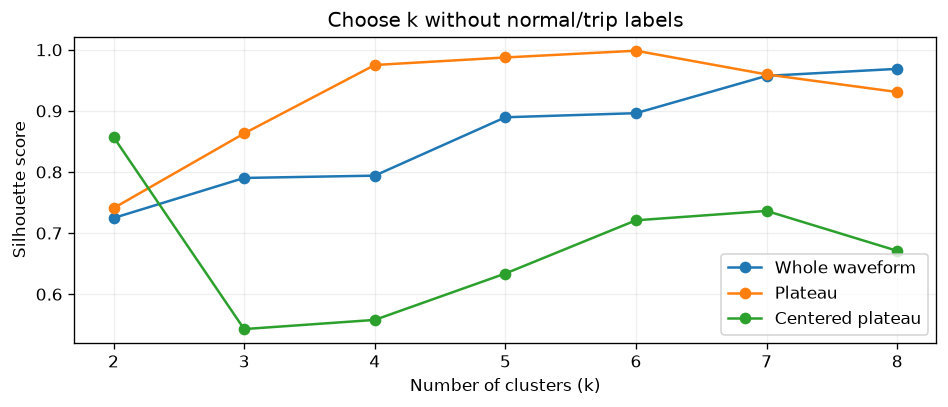

In [144]:
cluster_summary_rows = []
cluster_memberships = {}
# Limit BLAS threads to keep this exploration responsive on shared nodes.
with threadpool_limits(limits=2):
    for cluster_view_name, cluster_view in cluster_views.items():
        cluster_scaler = StandardScaler()
        cluster_scaled = cluster_scaler.fit_transform(cluster_view["x"])
        cluster_pca = PCA(n_components=2, svd_solver="full")
        cluster_xy = cluster_pca.fit_transform(cluster_scaled)
        cluster_scores, cluster_models = {}, {}
        for cluster_k in CLUSTER_K_VALUES:
            if cluster_k >= len(cluster_scaled):
                continue
            cluster_model = KMeans(
                n_clusters=cluster_k, n_init=20, random_state=CLUSTER_RANDOM_STATE
            ).fit(cluster_scaled)
            if len(np.unique(cluster_model.labels_)) < 2:
                continue
            cluster_scores[cluster_k] = silhouette_score(
                cluster_scaled, cluster_model.labels_,
                sample_size=min(1200, len(cluster_scaled)),
                random_state=CLUSTER_RANDOM_STATE,
            )
            cluster_models[cluster_k] = cluster_model
        cluster_best_k = max(cluster_scores, key=cluster_scores.get)
        cluster_best_model = cluster_models[cluster_best_k]
        cluster_view.update({
            "xy": cluster_xy, "pca": cluster_pca,
            "scaler": cluster_scaler, "model": cluster_best_model,
            "clusters": cluster_best_model.labels_ + 1,
            "scores": cluster_scores, "best_k": cluster_best_k,
        })
        cluster_membership = cluster_view["meta"][[
            "dataset_index", "cavity", "cavity_short", "label", "label_name"
        ]].copy()
        cluster_membership["cluster"] = cluster_view["clusters"]
        cluster_membership[["PC1", "PC2"]] = cluster_xy
        cluster_memberships[cluster_view_name] = cluster_membership
        cluster_summary_rows.append({
            "representation": cluster_view_name,
            "n_pulses": len(cluster_scaled), "n_features": cluster_scaled.shape[1],
            "selected_k": cluster_best_k,
            "silhouette": cluster_scores[cluster_best_k],
            "PCA_2D_variance": cluster_pca.explained_variance_ratio_.sum(),
        })
cluster_summary = pd.DataFrame(cluster_summary_rows)
display(cluster_summary.round(4))

cluster_score_fig, cluster_score_ax = plt.subplots(figsize=(8, 3.5))
for cluster_view_name, cluster_view in cluster_views.items():
    cluster_score_ax.plot(list(cluster_view["scores"]), list(cluster_view["scores"].values()),
                          marker="o", label=cluster_view_name)
cluster_score_ax.set(xlabel="Number of clusters (k)", ylabel="Silhouette score",
                     title="Choose k without normal/trip labels")
cluster_score_ax.legend()
cluster_score_ax.grid(alpha=0.2)
cluster_score_fig.tight_layout()
plt.show()


### How to read the PCA scatter plots

The same point coordinates are colored by **normal/trip label, cavity identifier,
and K-means cluster**, from left to right. Each point represents one pulse.
The percentage on each axis is the fraction of variance explained by that principal
component. When the combined percentage is low, the plot captures only part of the
distance structure in the original data.

Cluster numbers are independent for each representation. Identifiers such as C1
are arbitrary and do not indicate whether a pulse is normal or abnormal.

The **Normal / Trip panel itself** includes a blue Normal and an orange dashed Trip
1-sigma circle for every existing cluster with at least two points in that label.
Each circle uses its own label mean and radius `sqrt(Var(PC1) + Var(PC2))`.
The original axis scales are retained; circular boundaries in PCA coordinates can
appear stretched on screen. Use the equal-unit cluster zooms below for detail.


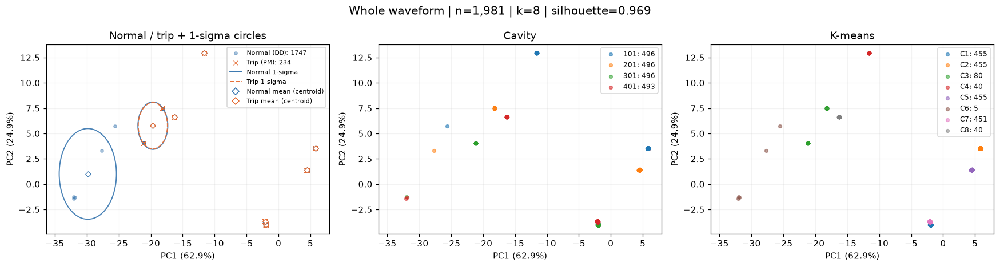

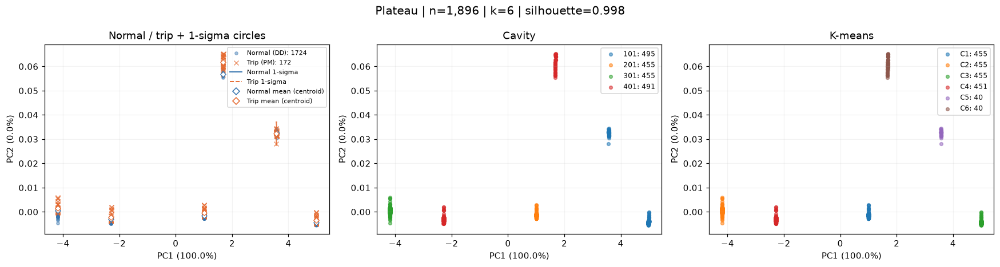

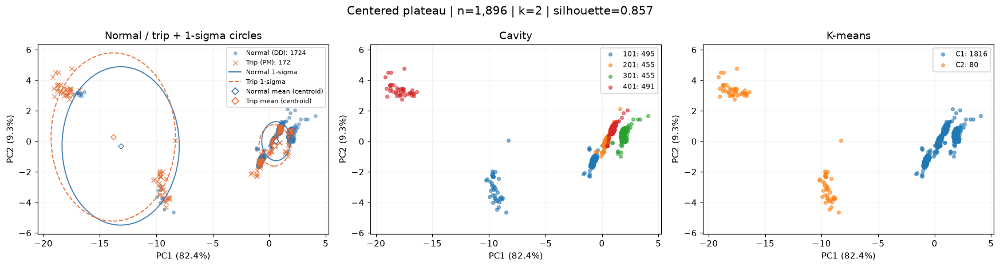

In [206]:
from pathlib import Path
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

cluster_scatter_output = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_pca_cluster_variance.py").is_file()
) / "signal_comparison/pca_cluster_variance"
cluster_scatter_output.mkdir(parents=True, exist_ok=True)

cluster_scatter_figures = {}
for cluster_view_name, cluster_view in cluster_views.items():
    cluster_fig, cluster_axes = plt.subplots(1, 3, figsize=(16, 4.3))
    cluster_xy = cluster_view["xy"]
    cluster_meta = cluster_view["meta"]
    for cluster_label, cluster_color, cluster_marker in [
        (0, "#3574ae", "o"), (1, "#e56b32", "x")
    ]:
        cluster_mask = cluster_meta["label"].to_numpy() == cluster_label
        cluster_axes[0].scatter(
            cluster_xy[cluster_mask, 0], cluster_xy[cluster_mask, 1],
            c=cluster_color, marker=cluster_marker,
            s=13 if cluster_label == 0 else 28,
            alpha=0.45 if cluster_label == 0 else 0.85,
            linewidths=0.8,
            label=f"{'Normal (DD)' if cluster_label == 0 else 'Trip (PM)'}: {cluster_mask.sum()}",
        )
    # Overlay each existing cluster's separate Normal/Trip radial 1-sigma circle.
    cluster_circle_stats = []
    for cluster_circle_id in sorted(np.unique(cluster_view["clusters"])):
        for cluster_circle_label, cluster_circle_color, cluster_circle_style in [
            (0, "#3574ae", "-"), (1, "#e56b32", "--")
        ]:
            cluster_circle_mask = (
                (np.asarray(cluster_view["clusters"]) == cluster_circle_id)
                & (cluster_meta["label"].to_numpy() == cluster_circle_label)
            )
            cluster_circle_points = cluster_xy[cluster_circle_mask]
            if len(cluster_circle_points) < 2:
                continue
            cluster_circle_center = cluster_circle_points.mean(axis=0)
            cluster_circle_radius = np.sqrt(cluster_circle_points.var(axis=0, ddof=1).sum())
            cluster_axes[0].add_patch(Circle(
                cluster_circle_center, cluster_circle_radius, fill=False,
                edgecolor=cluster_circle_color, linestyle=cluster_circle_style,
                linewidth=1.25, alpha=0.9, zorder=5,
            ))
            cluster_axes[0].scatter(
                *cluster_circle_center, marker="D", s=19, facecolors="white",
                edgecolors=cluster_circle_color, linewidths=0.8, zorder=6,
            )
            cluster_circle_stats.append((int(cluster_circle_id), cluster_circle_label,
                                         cluster_circle_center.copy(), float(cluster_circle_radius)))
    for cluster_cavity_i, cluster_cavity in enumerate(sorted(cluster_meta["cavity_short"].unique())):
        cluster_mask = cluster_meta["cavity_short"].to_numpy() == cluster_cavity
        cluster_axes[1].scatter(
            cluster_xy[cluster_mask, 0], cluster_xy[cluster_mask, 1],
            s=14, alpha=0.55, color=plt.get_cmap("tab10")(cluster_cavity_i),
            label=f"{cluster_cavity}: {cluster_mask.sum()}",
        )
    for cluster_id in range(1, cluster_view["best_k"] + 1):
        cluster_mask = cluster_view["clusters"] == cluster_id
        cluster_axes[2].scatter(
            cluster_xy[cluster_mask, 0], cluster_xy[cluster_mask, 1],
            s=14, alpha=0.55, color=plt.get_cmap("tab10")(cluster_id - 1),
            label=f"C{cluster_id}: {cluster_mask.sum()}",
        )
    for cluster_ax, cluster_title in zip(cluster_axes, ["Normal / trip + 1-sigma circles", "Cavity", "K-means"]):
        cluster_ax.set(
            title=cluster_title,
            xlabel=f"PC1 ({cluster_view['pca'].explained_variance_ratio_[0]:.1%})",
            ylabel=f"PC2 ({cluster_view['pca'].explained_variance_ratio_[1]:.1%})",
        )
        cluster_ax.legend(fontsize=8)
        cluster_ax.grid(alpha=0.15)
    cluster_circle_handles, cluster_circle_labels = cluster_axes[0].get_legend_handles_labels()
    cluster_axes[0].legend(
        handles=cluster_circle_handles + [
            Line2D([], [], color="#3574ae", linewidth=1.25, label="Normal 1-sigma"),
            Line2D([], [], color="#e56b32", linestyle="--", linewidth=1.25, label="Trip 1-sigma"),
            Line2D([], [], marker="D", linestyle="", markerfacecolor="white",
                   markeredgecolor="#3574ae", label="Normal mean (centroid)"),
            Line2D([], [], marker="D", linestyle="", markerfacecolor="white",
                   markeredgecolor="#e56b32", label="Trip mean (centroid)"),
        ], fontsize=7, loc="best",
    )
    # The circle overlay may extend beyond the points; keep all three panels aligned.
    cluster_circle_xlim, cluster_circle_ylim = cluster_axes[0].get_xlim(), cluster_axes[0].get_ylim()
    for cluster_ax in cluster_axes:
        cluster_ax.set_xlim(cluster_circle_xlim)
        cluster_ax.set_ylim(cluster_circle_ylim)
    cluster_fig.suptitle(
        f"{cluster_view_name} | n={len(cluster_meta):,} | k={cluster_view['best_k']} | "
        f"silhouette={cluster_view['scores'][cluster_view['best_k']]:.3f}",
        fontsize=13,
    )
    cluster_fig.tight_layout()
    cluster_scatter_figures[cluster_view_name] = cluster_fig
    cluster_fig.savefig(
        cluster_scatter_output / (cluster_view_name.lower().replace(" ", "_") + "_normal_trip_scatter_1sigma.png"),
        dpi=140, bbox_inches="tight",
    )
    plt.show()


### Within-cluster variance: Normal versus Trip

Use the existing PCA coordinates and existing cluster memberships. **Within each
cluster, calculate Normal variance around the Normal mean, and Trip variance
around the Trip mean.** No PCA, clustering, or classifier is fitted.

- `var_PC1` is the horizontal sample variance; `var_PC2` is the vertical sample variance.
- `variance_2D = var_PC1 + var_PC2`, calculated separately for each label (`ddof=1`).
- `Trip / Normal` compares their 2D variances. A ratio above 1 means more spread
  among Trip points in this cluster. It is a variance ratio, not a standard-deviation ratio.
- Values use squared PCA-score units. Compare labels/clusters within one representation;
  the three representations have different standardization and PCA scales.
- The primary table compares the 2D variances side by side. The detail table gives
  both axis variances, capture counts, and the circle radius for each label.

**1-sigma circles:** blue is Normal and orange is Trip. Each circle is centered at
that label's own mean. Here the circular spread is explicitly defined as
`radius = sqrt(var_PC1 + var_PC2)`. This is a radial summary of the two coordinate
variances, not a covariance ellipse, a confidence interval, or a region with a
guaranteed percentage of points. Diamonds mark the two label means.

Each cluster is translated by one common cluster center for the zoom plot, so the
relative Normal/Trip positions and all variances are preserved. Axis units are equal
within each panel and zoom levels differ between panels. All points are retained.
With fewer than two points in a label, its variance/radius is NA and no circle is
drawn. These are descriptive pulse statistics; capture counts show their sampling support.


In [202]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cluster_variance_root = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_pca_cluster_variance.py").is_file()
)
if str(cluster_variance_root) not in sys.path:
    sys.path.insert(0, str(cluster_variance_root))
import cavity_pca_cluster_variance as cluster_variance_tools
cluster_variance_tools = importlib.reload(cluster_variance_tools)
if "pca_stats_result" in globals():
    cluster_variance_annotations = pca_stats_result["point_statistics"]
else:
    cluster_variance_annotations = pd.read_csv(
        cluster_variance_root / "signal_comparison/pca_cluster_statistics/point_statistics.csv",
        float_precision="round_trip",
    )
if "cluster_views" in globals():
    # Use the exact coordinates and memberships that produced the scatter plots.
    cluster_variance_points = cluster_variance_tools.points_from_views(
        cluster_views, annotated_points=cluster_variance_annotations
    )
else:
    cluster_variance_points = cluster_variance_annotations
cluster_variance_result = cluster_variance_tools.make_result(cluster_variance_points)
cluster_variance_output = cluster_variance_root / "signal_comparison/pca_cluster_variance"
cluster_variance_tools.save_results(cluster_variance_result, cluster_variance_output)


for cluster_variance_name in cluster_variance_tools.VIEWS:
    print(cluster_variance_name + ": Normal / Trip variance within each existing cluster")
    cluster_variance_comparison = cluster_variance_result["label_comparison"].loc[
        lambda table: table["representation"] == cluster_variance_name, [
            "cluster", "Normal_n_waveforms", "Trip_n_waveforms",
            "Normal_variance_2D", "Trip_variance_2D", "Trip_over_Normal_variance_2D"
        ]
    ].copy()
    for cluster_variance_column in ["Normal_variance_2D", "Trip_variance_2D"]:
        cluster_variance_comparison[cluster_variance_column] = cluster_variance_comparison[cluster_variance_column].map(
            lambda value: "NA" if pd.isna(value) else f"{value:.5e}"
        )
    cluster_variance_comparison["Trip_over_Normal_variance_2D"] = cluster_variance_comparison[
        "Trip_over_Normal_variance_2D"
    ].map(lambda value: "NA" if pd.isna(value) else f"{value:.3f}")
    display(cluster_variance_comparison.reset_index(drop=True))

    print("Axis variances and 1-sigma circle radii:")
    cluster_variance_details = cluster_variance_result["label_variance"].loc[
        lambda table: table["representation"] == cluster_variance_name, [
            "cluster", "label_name", "n_waveforms", "n_captures", "var_PC1", "var_PC2",
            "variance_2D", "circle_radius_1sigma", "status"
        ]
    ].copy()
    for cluster_variance_column in ["var_PC1", "var_PC2", "variance_2D", "circle_radius_1sigma"]:
        cluster_variance_details[cluster_variance_column] = cluster_variance_details[cluster_variance_column].map(
            lambda value: "NA" if pd.isna(value) else f"{value:.5e}"
        )
    display(cluster_variance_details.reset_index(drop=True))


Whole waveform: Normal / Trip variance within each existing cluster


,cluster,Normal_n_waveforms,Trip_n_waveforms,Normal_variance_2D,Trip_variance_2D,Trip_over_Normal_variance_2D
0,1,427,28,2.12268e-03,1.53432e-03,0.723
1,2,427,28,8.44189e-04,6.78723e-04,0.804
2,3,18,62,5.45661e+00,5.23716e+00,0.960
3,4,9,31,1.75319e-05,5.30228e-05,3.024
4,5,427,28,1.43153e-03,1.35978e-03,0.950
5,6,5,0,2.00370e+01,NA,NA
6,7,425,26,1.03102e-03,7.82002e-04,0.758
7,8,9,31,4.15165e-05,1.12431e-04,2.708


Axis variances and 1-sigma circle radii:


,cluster,label_name,n_waveforms,n_captures,var_PC1,var_PC2,variance_2D,circle_radius_1sigma,status
0,1,Normal,427,33,2.12154e-03,1.14123e-06,2.12268e-03,4.60726e-02,descriptive_sample_variance
1,1,Trip,28,28,1.53258e-03,1.74479e-06,1.53432e-03,3.91704e-02,descriptive_sample_variance
2,2,Normal,427,33,8.39669e-04,4.51983e-06,8.44189e-04,2.90549e-02,descriptive_sample_variance
3,2,Trip,28,28,6.73492e-04,5.23125e-06,6.78723e-04,2.60523e-02,descriptive_sample_variance
4,3,Normal,18,1,2.27801e+00,3.17860e+00,5.45661e+00,2.33594e+00,descriptive_sample_variance
5,3,Trip,62,31,2.17613e+00,3.06103e+00,5.23716e+00,2.28848e+00,descriptive_sample_variance
6,4,Normal,9,1,1.60699e-05,1.46199e-06,1.75319e-05,4.18711e-03,descriptive_sample_variance
7,4,Trip,31,31,5.05625e-05,2.46037e-06,5.30228e-05,7.28168e-03,descriptive_sample_variance
8,5,Normal,427,33,1.31984e-03,1.11684e-04,1.43153e-03,3.78355e-02,descriptive_sample_variance
9,5,Trip,28,28,1.25112e-03,1.08658e-04,1.35978e-03,3.68752e-02,descriptive_sample_variance


Plateau: Normal / Trip variance within each existing cluster


...

,cluster,label_name,n_waveforms,n_captures,var_PC1,var_PC2,variance_2D,circle_radius_1sigma,status
0,1,Normal,427,33,1.37477e-07,1.67178e-07,3.04655e-07,5.51955e-04,descriptive_sample_variance
1,1,Trip,28,28,9.47600e-07,2.60857e-06,3.55617e-06,1.88578e-03,descriptive_sample_variance
2,2,Normal,427,33,2.02199e-07,7.03008e-07,9.05207e-07,9.51424e-04,descriptive_sample_variance
3,2,Trip,28,28,1.50607e-06,3.66399e-06,5.17006e-06,2.27378e-03,descriptive_sample_variance
4,3,Normal,427,33,1.10168e-07,1.60644e-07,2.70813e-07,5.20397e-04,descriptive_sample_variance
5,3,Trip,28,28,8.14070e-07,2.39500e-06,3.20907e-06,1.79139e-03,descriptive_sample_variance
6,4,Normal,425,33,1.28826e-07,3.34522e-07,4.63348e-07,6.80697e-04,descriptive_sample_variance
7,4,Trip,26,26,9.29640e-07,3.95855e-06,4.88819e-06,2.21093e-03,descriptive_sample_variance
8,5,Normal,9,1,5.41115e-06,1.09635e-06,6.50750e-06,2.55098e-03,descriptive_sample_variance
9,5,Trip,31,31,2.33501e-05,1.39131e-06,2.47414e-05,4.97407e-03,descriptive_sample_variance


Centered plateau: Normal / Trip variance within each existing cluster


,cluster,Normal_n_waveforms,Trip_n_waveforms,Normal_variance_2D,Trip_variance_2D,Trip_over_Normal_variance_2D
0,1,1706,110,1.62542e+00,1.84576e+00,1.136
1,2,18,62,2.68966e+01,3.03314e+01,1.128


Axis variances and 1-sigma circle radii:


,cluster,label_name,n_waveforms,n_captures,var_PC1,var_PC2,variance_2D,circle_radius_1sigma,status
0,1,Normal,1706,33,9.55822e-01,6.69599e-01,1.62542e+00,1.27492e+00,descriptive_sample_variance
1,1,Trip,110,28,1.00154e+00,8.44221e-01,1.84576e+00,1.35859e+00,descriptive_sample_variance
2,2,Normal,18,1,1.43355e+01,1.25611e+01,2.68966e+01,5.18619e+00,descriptive_sample_variance
3,2,Trip,62,31,1.95982e+01,1.07332e+01,3.03314e+01,5.50739e+00,descriptive_sample_variance


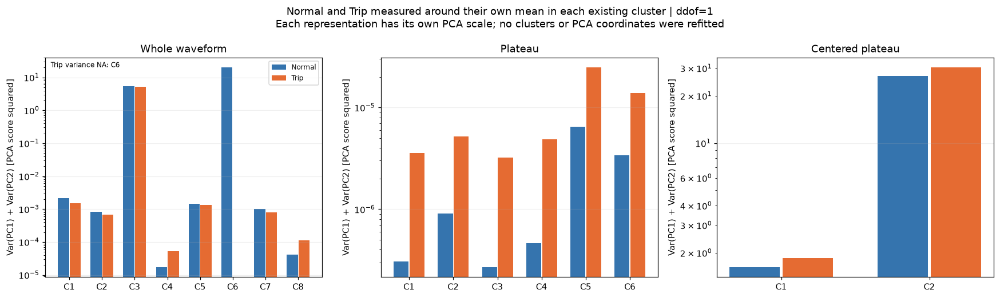

In [203]:
cluster_variance_figure = cluster_variance_tools.plot_variance_bars(cluster_variance_result)
cluster_variance_figure.savefig(
    cluster_variance_output / "normal_trip_variance_by_cluster.png", dpi=140, bbox_inches="tight"
)
plt.show()


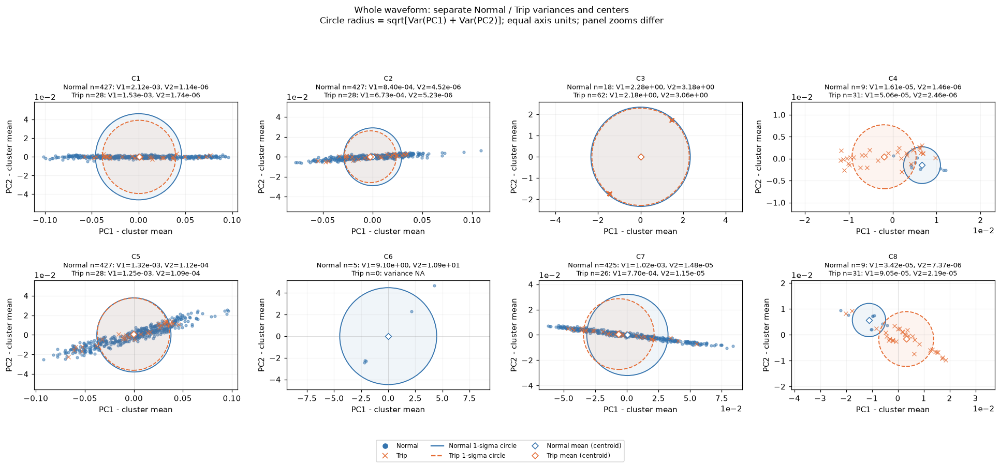

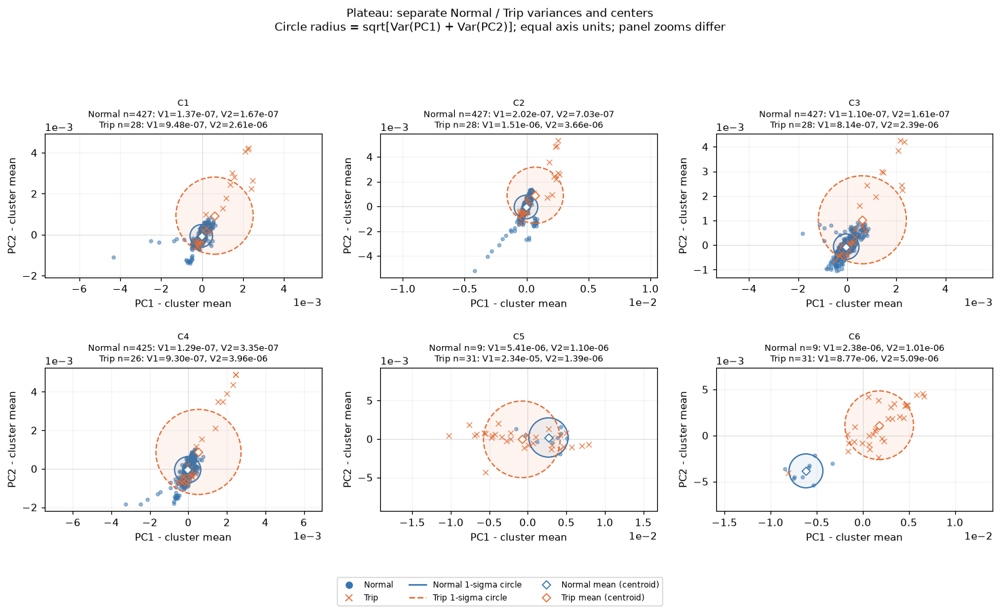

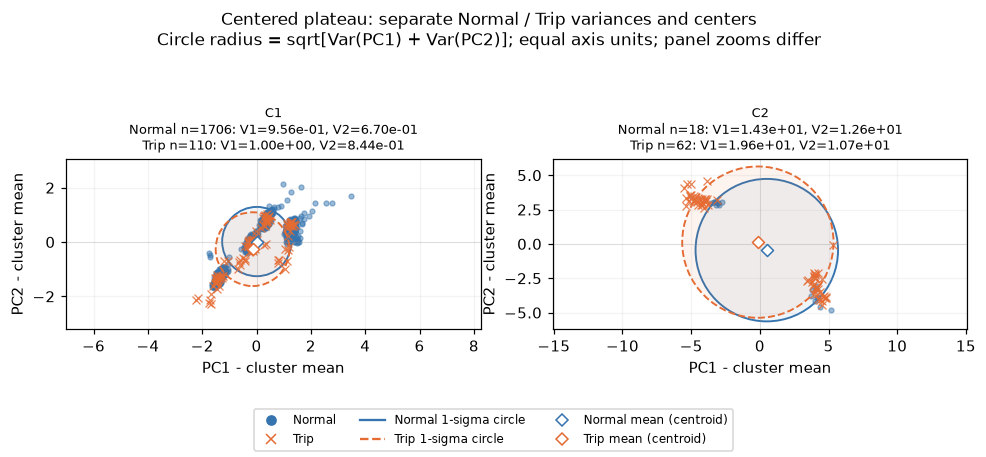

In [207]:
for cluster_variance_name in cluster_variance_tools.VIEWS:
    cluster_variance_figure = cluster_variance_tools.plot_cluster_zooms(
        cluster_variance_result, cluster_variance_name
    )
    cluster_variance_figure.savefig(
        cluster_variance_output / (cluster_variance_name.lower().replace(" ", "_") + "_normal_trip_1sigma_circles.png"),
        dpi=140, bbox_inches="tight",
    )
    plt.show()


### Statistical reading of these PCA clusters

ここでは、上の **Whole waveform / Plateau / Centered plateau** の同じ点・同じクラスターを数値で読みます。
対象はHBL-010の101/201/301/401という **4 cavityの1,981点**です。
PlateauとCentered plateauは抽出できた1,896点です。
末尾の「Normal + Trip: all 40,223 cavity-pulses」の全82 cavity解析とは対象・特徴が異なります。
**クラスター番号、PCA座標、選ばれたkは変更しません。**

### 指標を3つの観点に分けて読む

| 観点 | 指標 | 読み方 |
|---|---|---|
| 幾何的に群が分かれているか | Silhouette（−1〜1） | 1に近いほど自分の群に近く他の群から遠い。0付近は境界、負値は他群の方が近い点。全体平均だけでなく群別分布も確認する。 |
| 同じ特徴空間での群のまとまり | Davies–Bouldin（0以上） | 群内の広がりに対して群の中心がどれだけ離れているか。低いほどよい。 |
| 図にどれだけ情報が載っているか | PCA 2D variance | PC1+PC2の寄与率。SilhouetteとDBは2D図ではなく、実際にクラスタリングした標準化特徴空間で計算する。 |
| 群が何の違いを表すか | AMI(label/cavity/year) | 偶然の一致を補正した群との対応。1は同じ分割、0付近は偶然程度で、負値もあり得る。Normal/Tripだけでなくcavityと取得年も比較する。 |
| 同じ年の中でもラベルと対応するか | Conditional MI（bits） | `I(label; cluster | year)`。年ごとの相互情報量をその年の点数比で平均する。0なら、このデータ内では年をそろえた後のラベルとの情報上の対応がない。 |
| 初期値に依存するか | 初期値を変えたARI | 選んだkと標準化を固定し、seed=0〜9でKMeansを再実行。元の分割とのARIが1なら同じ分割。新規収録に対する安定性とは別の評価。 |

Silhouetteは元のk選択では最大1,200点の近似でしたが、この節では1,981点／1,896点の**全点**で再計算します。
定義が同じでも、標本が違うので元の図に表示された値と少し異なります。
高いSilhouetteや低いDBは「NormalとTripがよく分かれた」という意味ではありません。
異なる特徴表現で数値の大小を比較する際も、同じ距離の問題を評価しているわけではないことに注意します。

クラスターの構成には、点数、独立した収録数、Trip比率、全体に対するTrip濃縮倍率を表示します。
Trip濃縮倍率は `群のTrip点数比 / その表現全体のTrip点数比` です。
`capture_balanced_trip_fraction` は各収録の重みの合計を1にそろえた構成比で、元の波形点数比とは別の値です。
いずれも、このデータでのラベルの構成を記述する指標であり、故障確率・検出精度ではありません。

定義：[Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_samples.html)、
[Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html)、
[AMI](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_mutual_info_score.html)、
[相互情報量](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mutual_info_score.html)。


In [193]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

pca_stats_root = next(p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
                      if (p / "cavity_pca_cluster_statistics.py").is_file())
if str(pca_stats_root) not in sys.path:
    sys.path.insert(0, str(pca_stats_root))
import cavity_pca_cluster_statistics as pca_stats_tools
pca_stats_tools = importlib.reload(pca_stats_tools)
pca_stats_output = pca_stats_root / "signal_comparison" / "pca_cluster_statistics"
REBUILD_PCA_CLUSTER_STATISTICS = False
pca_stats_live_views = globals().get("cluster_views")
if pca_stats_live_views is not None:
    # Read the exact already displayed assignments; never refit their selected model.
    pca_stats_result = pca_stats_tools.make_result(pca_stats_root, existing_views=pca_stats_live_views)
    pca_stats_tools.save_results(pca_stats_result, pca_stats_output)
elif REBUILD_PCA_CLUSTER_STATISTICS or not pca_stats_tools.cache_fresh(pca_stats_root, pca_stats_output):
    pca_stats_result = pca_stats_tools.make_result(pca_stats_root)
    pca_stats_tools.save_results(pca_stats_result, pca_stats_output)
else:
    pca_stats_result = pca_stats_tools.load_results(pca_stats_output)

print("分離の強さ：実際にクラスタリングした特徴空間で全点を評価")
display(pca_stats_result["view_metrics"][[
    "representation", "waveforms", "k", "silhouette_for_k_selection", "silhouette_all_points",
    "negative_silhouette_fraction", "Davies_Bouldin", "PCA_2D_variance"
]].round(5))
print("何の違いを表す群か／初期値への依存")
display(pca_stats_result["view_metrics"][[
    "representation", "AMI_label", "AMI_cavity", "AMI_year", "ARI_year",
    "initialization_ARI_mean", "initialization_ARI_min"
]].round(5))
print("取得条件をそろえた後にも、ラベルとの対応が残るか（記述的な条件付き相互情報量）")
display(pca_stats_result["conditional_association"].round(7))
print("抽出でどのラベルがどれだけ残ったか")
display(pca_stats_result["retention"].round(4))


分離の強さ：実際にクラスタリングした特徴空間で全点を評価


,representation,waveforms,k,silhouette_for_k_selection,silhouette_all_points,negative_silhouette_fraction,Davies_Bouldin,PCA_2D_variance
0,Whole waveform,1981,8,0.96880,0.96891,0.0,0.16655,0.87790
1,Plateau,1896,6,0.99849,0.99843,0.0,0.00472,1.00000
2,Centered plateau,1896,2,0.85732,0.85418,0.0,0.48585,0.91752


何の違いを表す群か／初期値への依存


,representation,AMI_label,AMI_cavity,AMI_year,ARI_year,initialization_ARI_mean,initialization_ARI_min
0,Whole waveform,0.10813,0.89126,0.28896,0.08975,1.0,1.0
1,Plateau,0.06705,0.94968,0.20358,0.05117,1.0,1.0
2,Centered plateau,0.26135,0.03547,1.00000,1.00000,1.0,1.0


取得条件をそろえた後にも、ラベルとの対応が残るか（記述的な条件付き相互情報量）


,representation,conditioned_on,label_cluster_MI_bits,conditional_label_cluster_MI_bits
0,Whole waveform,year,0.159595,0.000260
1,Whole waveform,year + beam mode + beam presence,0.159595,0.000750
2,Plateau,year,0.090637,0.000035
3,Plateau,year + beam mode + beam presence,0.090637,0.000239
4,Centered plateau,year,0.090602,0.000000
5,Centered plateau,year + beam mode + beam presence,0.090602,0.000000


抽出でどのラベルがどれだけ残ったか


,representation,label,original_waveforms,retained_waveforms,excluded_waveforms,retained_fraction
0,Whole waveform,0,1747,1747,0,1.0000
1,Whole waveform,1,234,234,0,1.0000
2,Plateau,0,1747,1724,23,0.9868
3,Plateau,1,234,172,62,0.7350
4,Centered plateau,0,1747,1724,23,0.9868
5,Centered plateau,1,234,172,62,0.7350


### クラスターのTrip比率と不確かさ

同じ収録の複数pulse・複数cavityは似ているため、各波形を独立とみなす二項信頼区間は使っていません。
ここではNormal収録、Trip収録をそれぞれ**収録単位で2,000回bootstrap**し、
その収録の全cavity・全pulseをまとめて再標本化します。
固定したクラスター内のTrip点数比の2.5〜97.5百分位を表示します。
この区間は観測された収録を再標本化した条件付きの区間で、未知の期間や新しい故障への保証ではありません。
クラスタリングを各bootstrapでやり直してはいないので、クラスター再学習の不確かさも含みません。

NormalまたはTripが2収録未満しか含まれない群は、95%区間をNAとし、表と白抜きの点で示します。
これは最低限の表示ルールであり、2収録あれば十分な標本数という意味ではありません。
特にCentered plateauのC2はNormal 18波形でも**Normal収録は1つだけ**なので、区間は表示しません。
`bootstrap_status` はその理由です。クラスターをまたいで同じ収録が現れるため、
クラスター別のcapture数を単純に足して独立な収録総数にはできません。


In [194]:
print("各クラスターの構成と、収録単位のbootstrap区間")
display(pca_stats_result["cluster_metrics"][[
    "representation", "cluster", "waveforms", "normal_waveforms", "trip_waveforms",
    "normal_captures", "trip_captures", "trip_fraction", "trip_enrichment_vs_representation",
    "capture_balanced_trip_fraction", "bootstrap_CI_low", "bootstrap_CI_high", "bootstrap_status"
]].round(4))
print("群ごとのSilhouette分布（平均だけでは見落とす境界点を確認）")
display(pca_stats_result["cluster_metrics"][[
    "representation", "cluster", "silhouette_mean", "silhouette_p10", "silhouette_median",
    "negative_silhouette_fraction"
]].round(5))
print("クラスター × 取得年 × ラベルの波形数と収録数")
display(pca_stats_result["year_label_counts"])


各クラスターの構成と、収録単位のbootstrap区間


,representation,cluster,waveforms,normal_waveforms,trip_waveforms,normal_captures,trip_captures,trip_fraction,trip_enrichment_vs_representation,capture_balanced_trip_fraction,bootstrap_CI_low,bootstrap_CI_high,bootstrap_status
0,Whole waveform,1,455,427,28,33,28,0.0615,0.5210,0.4653,0.0456,0.0778,reported
1,Whole waveform,2,455,427,28,33,28,0.0615,0.5210,0.4653,0.0456,0.0778,reported
2,Whole waveform,3,80,18,62,1,31,0.7750,6.5610,0.9688,NaN,NaN,fewer_than_two_captures_in_a_label
3,Whole waveform,4,40,9,31,1,31,0.7750,6.5610,0.9688,NaN,NaN,fewer_than_two_captures_in_a_label
4,Whole waveform,5,455,427,28,33,28,0.0615,0.5210,0.4653,0.0456,0.0778,reported
5,Whole waveform,6,5,5,0,2,0,0.0000,0.0000,0.0000,NaN,NaN,fewer_than_two_captures_in_a_label
6,Whole waveform,7,451,425,26,33,26,0.0576,0.4881,0.4423,0.0416,0.0742,reported
7,Whole waveform,8,40,9,31,1,31,0.7750,6.5610,0.9688,NaN,NaN,fewer_than_two_captures_in_a_label
8,Plateau,1,455,427,28,33,28,0.0615,0.6784,0.4646,0.0456,0.0778,reported
9,Plateau,2,455,427,28,33,28,0.0615,0.6784,0.4646,0.0456,0.0778,reported


群ごとのSilhouette分布（平均だけでは見落とす境界点を確認）


,representation,cluster,silhouette_mean,silhouette_p10,silhouette_median,negative_silhouette_fraction
0,Whole waveform,1,0.96314,0.94746,0.96684,0.0
1,Whole waveform,2,0.98832,0.98350,0.98973,0.0
2,Whole waveform,3,0.74861,0.74581,0.74865,0.0
3,Whole waveform,4,0.99698,0.99641,0.99691,0.0
4,Whole waveform,5,0.98551,0.97923,0.98687,0.0
5,Whole waveform,6,0.84602,0.79888,0.86501,0.0
6,Whole waveform,7,0.97404,0.96386,0.97664,0.0
7,Whole waveform,8,0.99496,0.99395,0.99506,0.0
8,Plateau,1,0.99798,0.99782,0.99835,0.0
9,Plateau,2,0.99878,0.99855,0.99896,0.0


クラスター × 取得年 × ラベルの波形数と収録数


,representation,cluster,event_year,label,waveforms,captures
0,Whole waveform,4,2025,0,9,1
1,Whole waveform,3,2025,0,18,1
2,Whole waveform,8,2025,0,9,1
3,Whole waveform,5,2026,0,427,33
4,Whole waveform,2,2026,0,427,33
5,Whole waveform,1,2026,0,427,33
6,Whole waveform,7,2026,0,425,33
7,Whole waveform,6,2026,0,5,2
8,Whole waveform,3,2025,1,62,31
9,Whole waveform,4,2025,1,31,31


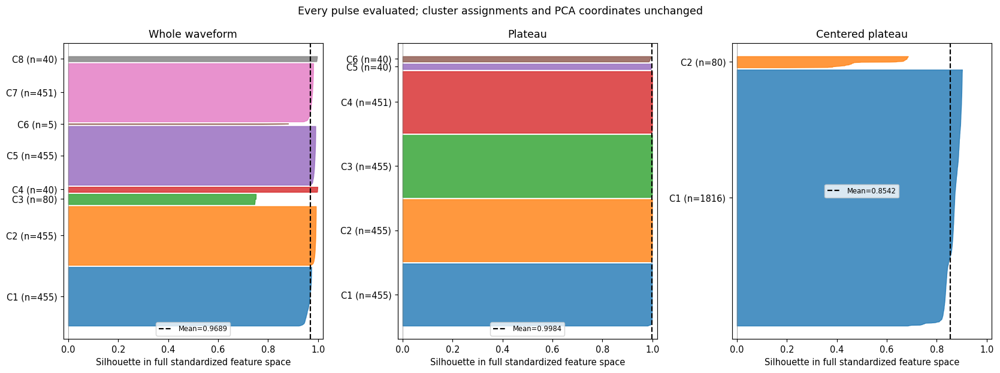

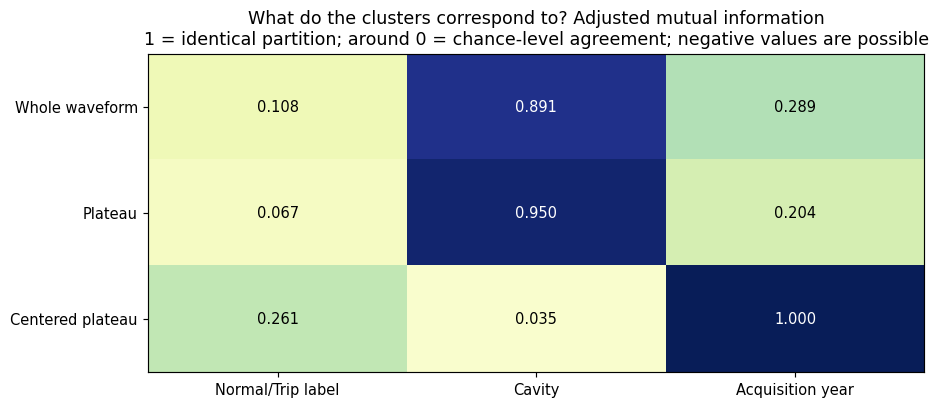

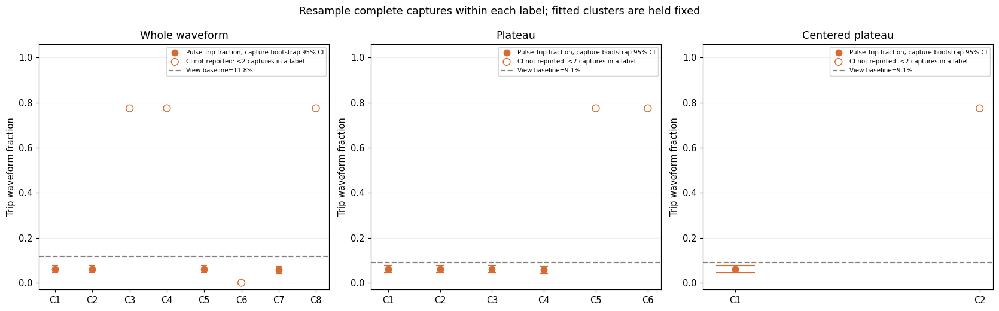

In [195]:
for pca_stats_filename, pca_stats_plotter in [
    ("silhouettes.png", pca_stats_tools.plot_silhouettes),
    ("label_cavity_year_AMI.png", pca_stats_tools.plot_associations),
    ("trip_fraction_capture_bootstrap.png", pca_stats_tools.plot_trip_fractions),
]:
    pca_stats_fig = pca_stats_plotter(pca_stats_result)
    pca_stats_fig.savefig(pca_stats_output / pca_stats_filename, dpi=140, bbox_inches="tight")
    plt.show()


### この図について数値から言えること

| 表現 | 全点Silhouette | AMI：Normal/Trip | AMI：cavity | AMI：取得年 |
|---|---:|---:|---:|---:|
| Whole waveform | 0.969 | 0.108 | 0.891 | 0.289 |
| Plateau | 0.998 | 0.067 | 0.950 | 0.204 |
| Centered plateau | 0.854 | 0.261 | 0.035 | 1.000 |

- **Whole waveform / Plateau**：幾何的には非常に明瞭な群ですが、Normal/Tripとの対応より
  cavityとの対応が強いです。PlateauでSilhouetteが約0.998でも、trip分類がほぼ完全という意味ではありません。
- **Centered plateau**：振幅平均を引くとcavityとの対応は小さくなりますが、取得年とのAMI・ARIはともに1です。
  実際、C1の1,816点はすべて2026年、C2の80点はすべて2025年です。
  年をそろえた後の `I(label; cluster | year)` は **0 bits** です。
  このデータではクラスターは取得年を超えるNormal/Tripの区別を追加していません。
- **Tripの濃縮**：Centered plateauのC2は62/80点＝77.5%がTripで、その表現全体の172/1,896点＝約9.1%に対して
  約8.54倍です。ただし、この差は取得年と対応し、Normal側も1収録だけなので、trip原因固有の差とは判断できません。
- **初期値**：選んだkを固定してseedを10通り変えても、3表現とも元の分割とのARIはすべて1でした。
  初期値への再現性は高い一方、取得年・cavityで安定して分かれている可能性も同時に示しています。
- **抽出による偏り**：plateau抽出後はNormalが1,724/1,747点（約98.7%）、Tripが172/234点（約73.5%）残っています。
  表現間でTrip比率を比べる際は、Tripの方が多く除外されていることも考慮します。

したがって、この図は「**再現性の高い群は存在するが、主な分離要因はcavityや取得年**」と読むのが妥当です。
これらの指標はデータの構造を記述するもので、未知の収録での検出精度やtripの根本原因の証明ではありません。
全点のsilhouette、群別構成・区間、初期値比較、条件付き集計は
`signal_comparison/pca_cluster_statistics/` に保存しています。


### Within-cluster spread: Normal versus Trip in Whole waveform and Plateau

上のNormal / Trip scatterにある**各クラスターの内側**を見て、NormalとTripの点の広がりを別々に求めます。
元のPCA座標とKMeansの所属を使い、クラスタリング・PCAを学習し直しません。
対象は同じ4 cavityの **Whole waveform 1,981点（Normal 1,747 / Trip 234）、
Plateau 1,896点（Normal 1,724 / Trip 172）**です。

クラスターごと・ラベルごとに、そのラベルの平均座標を求め、標本分散（`ddof=1`）を計算します。

\[
 s^2_{\mathrm{PC1},c,l}=\frac{1}{n_{c,l}-1}\sum_{i\in(c,l)}(\mathrm{PC1}_i-\overline{\mathrm{PC1}}_{c,l})^2,
 \qquad V_{2D,c,l}=s^2_{\mathrm{PC1},c,l}+s^2_{\mathrm{PC2},c,l}.
\]

- `var_PC1`は横方向、`var_PC2`は縦方向の広がりです。`variance_2D`は2方向の分散の合計です。
  単位はPCAスコアの2乗で、元の振幅の2乗ではありません。1本の波形内部の時間方向の分散とも異なります。
- **NormalはNormalの平均から、TripはTripの平均から**の広がりを計算します。
  平均位置のずれは別列の`centroid_distance_2D`です。
- `Trip_over_Normal_variance_2D`が1より大きいと、Tripの方が広がっています。
  分散比が9なら標準偏差に相当する広がりの比は約3であり、9ではありません。
- 表現ごとに別の標準化・PCAを使っているので、Whole waveformとPlateauの分散値の絶対値は直接比較しません。
  Whole waveformでは2Dに全分散の約87.8%、Plateauでは約99.99994%が載っていますが、
  **全体の寄与率は各クラスター内の変動の保存率を保証しません**。ここでは図上の分散を測っています。
- `n_captures`は独立した収録の数です。同一収録の複数pulseを含む記述統計であり、
  分散比を有意差や未知の収録での性能とは解釈しません。2点未満の分散はNAです。

以下の拡大図では、**クラスター全体の平均だけを両ラベル共通で引きます**。
分散とNormal/Tripの相対位置はそのままです。楕円は共分散の固有方向の1標準偏差を示すもので、
平均の信頼区間や95%領域ではありません。各パネルの軸の拡大率は異なるため、群間の広がりは表でも比較します。


In [196]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

pca_spread_root = next(p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
                       if (p / "cavity_pca_label_spread.py").is_file())
if str(pca_spread_root) not in sys.path:
    sys.path.insert(0, str(pca_spread_root))
import cavity_pca_label_spread as pca_spread_tools
pca_spread_tools = importlib.reload(pca_spread_tools)
# Use the exact points from the preceding statistics section, including live coordinates.
if "pca_stats_result" in globals():
    pca_spread_points = pca_stats_result["point_statistics"]
else:
    pca_spread_points = pd.read_csv(
        pca_spread_root / "signal_comparison/pca_cluster_statistics/point_statistics.csv",
        float_precision="round_trip")
pca_spread_result = pca_spread_tools.make_result(pca_spread_points)
pca_spread_output = pca_spread_root / "signal_comparison/pca_cluster_statistics/label_spread"
pca_spread_tools.save_results(pca_spread_result, pca_spread_output)

def pca_spread_format_table(table, formats):
    # Format only the displayed copy; CSVs and analysis retain numeric precision.
    table = table.copy()
    for column, pattern in formats.items():
        table[column] = table[column].map(lambda value, pattern=pattern:
                                          "NA" if pd.isna(value) else pattern.format(value))
    return table

for pca_spread_name in pca_spread_tools.VIEWS:
    print(pca_spread_name + ": クラスター別の分散比較（NAは計算できない群）")
    pca_spread_summary = pca_spread_result["cluster_comparison"].loc[
        lambda t: t.representation.eq(pca_spread_name), [
            "cluster", "Normal_n_waveforms", "Trip_n_waveforms", "Normal_n_captures", "Trip_n_captures",
            "Normal_variance_2D", "Trip_variance_2D", "Trip_over_Normal_variance_2D"
        ]]
    display(pca_spread_format_table(pca_spread_summary, {
        "Normal_variance_2D": "{:.4e}", "Trip_variance_2D": "{:.4e}",
        "Trip_over_Normal_variance_2D": "{:.3f}"}))


Whole waveform: クラスター別の分散比較（NAは計算できない群）


,cluster,Normal_n_waveforms,Trip_n_waveforms,Normal_n_captures,Trip_n_captures,Normal_variance_2D,Trip_variance_2D,Trip_over_Normal_variance_2D
0,1,427,28,33,28,2.1227e-03,1.5343e-03,0.723
1,2,427,28,33,28,8.4419e-04,6.7872e-04,0.804
2,3,18,62,1,31,5.4566e+00,5.2372e+00,0.960
3,4,9,31,1,31,1.7532e-05,5.3023e-05,3.024
4,5,427,28,33,28,1.4315e-03,1.3598e-03,0.950
5,6,5,0,2,0,2.0037e+01,NA,NA
6,7,425,26,33,26,1.0310e-03,7.8200e-04,0.758
7,8,9,31,1,31,4.1516e-05,1.1243e-04,2.708


Plateau: クラスター別の分散比較（NAは計算できない群）


,cluster,Normal_n_waveforms,Trip_n_waveforms,Normal_n_captures,Trip_n_captures,Normal_variance_2D,Trip_variance_2D,Trip_over_Normal_variance_2D
8,1,427,28,33,28,3.0465e-07,3.5562e-06,11.673
9,2,427,28,33,28,9.0521e-07,5.1701e-06,5.711
10,3,427,28,33,28,2.7081e-07,3.2091e-06,11.850
11,4,425,26,33,26,4.6335e-07,4.8882e-06,10.550
12,5,9,31,1,31,6.5075e-06,2.4741e-05,3.802
13,6,9,31,1,31,3.3815e-06,1.3861e-05,4.099


In [197]:
for pca_spread_name in pca_spread_tools.VIEWS:
    print(pca_spread_name + ": 横・縦の分散、共分散と平均位置")
    pca_spread_details = pca_spread_result["group_spread"].loc[
        lambda t: t.representation.eq(pca_spread_name), [
            "cluster", "label_name", "n_waveforms", "n_captures", "mean_PC1", "mean_PC2",
            "var_PC1", "var_PC2", "cov_PC1_PC2", "variance_2D", "status"
        ]]
    display(pca_spread_format_table(pca_spread_details, {column: "{:.4e}" for column in [
        "mean_PC1", "mean_PC2", "var_PC1", "var_PC2", "cov_PC1_PC2", "variance_2D"
    ]}))


Whole waveform: 横・縦の分散、共分散と平均位置


,cluster,label_name,n_waveforms,n_captures,mean_PC1,mean_PC2,var_PC1,var_PC2,cov_PC1_PC2,variance_2D,status
0,1,Normal,427,33,-1.9676e+00,-4.0082e+00,2.1215e-03,1.1412e-06,3.1885e-06,2.1227e-03,descriptive
1,1,Trip,28,28,-1.9671e+00,-4.0083e+00,1.5326e-03,1.7448e-06,-4.0105e-07,1.5343e-03,descriptive
2,2,Normal,427,33,5.8106e+00,3.5474e+00,8.3967e-04,4.5198e-06,4.9306e-05,8.4419e-04,descriptive
3,2,Trip,28,28,5.8082e+00,3.5474e+00,6.7349e-04,5.2312e-06,4.7746e-05,6.7872e-04,descriptive
4,3,Normal,18,1,-1.9667e+01,5.7658e+00,2.2780e+00,3.1786e+00,2.6909e+00,5.4566e+00,single_capture
5,3,Trip,62,31,-1.9667e+01,5.7656e+00,2.1761e+00,3.0610e+00,2.5809e+00,5.2372e+00,descriptive
6,4,Normal,9,1,-1.1603e+01,1.2947e+01,1.6070e-05,1.4620e-06,-3.6577e-06,1.7532e-05,single_capture
7,4,Trip,31,31,-1.1612e+01,1.2949e+01,5.0562e-05,2.4604e-06,4.9990e-06,5.3023e-05,descriptive
8,5,Normal,427,33,4.4647e+00,1.3966e+00,1.3198e-03,1.1168e-04,3.6249e-04,1.4315e-03,descriptive
9,5,Trip,28,28,4.4642e+00,1.3974e+00,1.2511e-03,1.0866e-04,3.5652e-04,1.3598e-03,descriptive


Plateau: 横・縦の分散、共分散と平均位置


,cluster,label_name,n_waveforms,n_captures,mean_PC1,mean_PC2,var_PC1,var_PC2,cov_PC1_PC2,variance_2D,status
16,1,Normal,427,33,1.0024e+00,-1.4623e-03,1.3748e-07,1.6718e-07,9.5483e-08,3.0465e-07,descriptive
17,1,Trip,28,28,1.0030e+00,-4.7278e-04,9.4760e-07,2.6086e-06,1.4888e-06,3.5562e-06,descriptive
18,2,Normal,427,33,-4.1865e+00,5.7187e-04,2.0220e-07,7.0301e-07,2.7178e-07,9.0521e-07,descriptive
19,2,Trip,28,28,-4.1857e+00,1.5232e-03,1.5061e-06,3.6640e-06,2.0875e-06,5.1701e-06,descriptive
20,3,Normal,427,33,4.9907e+00,-4.4734e-03,1.1017e-07,1.6064e-07,9.2859e-08,2.7081e-07,descriptive
21,3,Trip,28,28,4.9914e+00,-3.3773e-03,8.1407e-07,2.3950e-06,1.3040e-06,3.2091e-06,descriptive
22,4,Normal,425,33,-2.2890e+00,-3.0872e-03,1.2883e-07,3.3452e-07,1.5679e-07,4.6335e-07,descriptive
23,4,Trip,26,26,-2.2884e+00,-2.1589e-03,9.2964e-07,3.9586e-06,1.8808e-06,4.8882e-06,descriptive
24,5,Normal,9,1,3.5777e+00,3.2548e-02,5.4111e-06,1.0963e-06,-6.7413e-07,6.5075e-06,single_capture
25,5,Trip,31,31,3.5742e+00,3.2306e-02,2.3350e-05,1.3913e-06,-1.6475e-06,2.4741e-05,descriptive


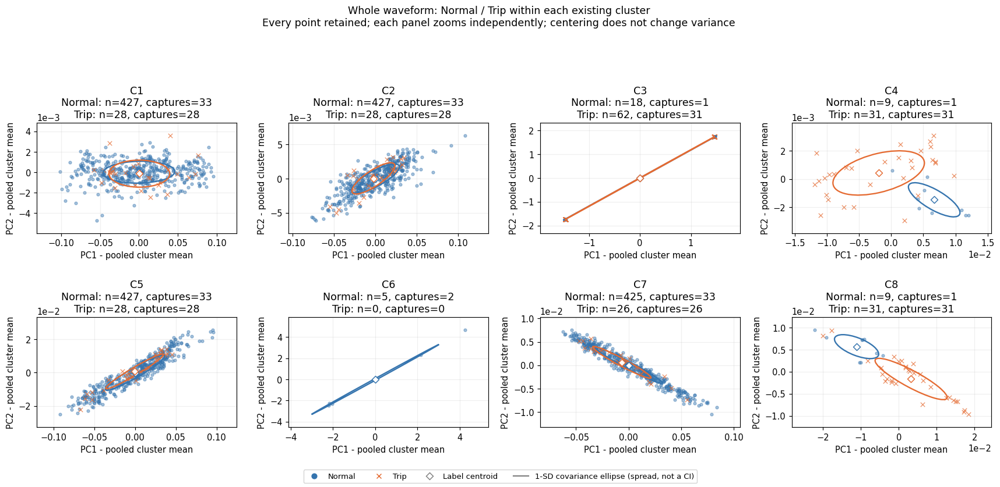

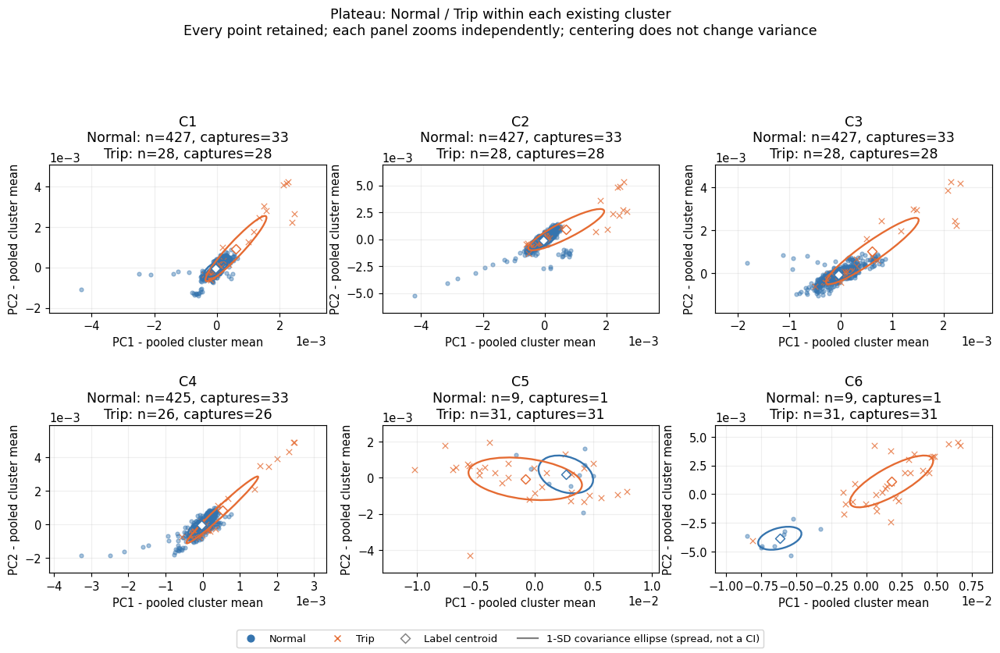

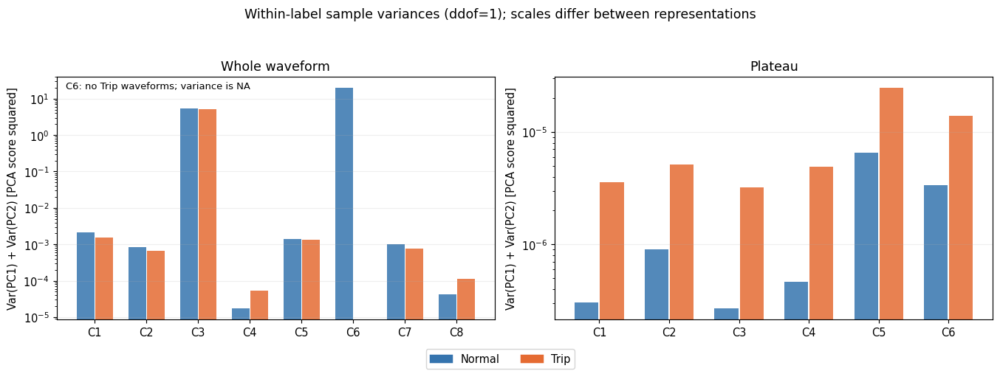

In [198]:
for pca_spread_name, pca_spread_filename in [
    ("Whole waveform", "whole_waveform_cluster_zoom.png"),
    ("Plateau", "plateau_cluster_zoom.png"),
]:
    pca_spread_fig = pca_spread_tools.plot_cluster_details(pca_spread_result, pca_spread_name)
    pca_spread_fig.savefig(pca_spread_output / pca_spread_filename, dpi=140, bbox_inches="tight")
    plt.show()
pca_spread_fig = pca_spread_tools.plot_variance_comparison(pca_spread_result)
pca_spread_fig.savefig(pca_spread_output / "normal_trip_variance_2D.png", dpi=140, bbox_inches="tight")
plt.show()


### このデータでのNormal / Tripの広がり

Plateauの2D分散 `Var(PC1)+Var(PC2)` は次のとおりです。横方向・縦方向の内訳は上の詳細表にあります。

| Plateauの群 | Normal点数 | Trip点数 | Normalの2D分散 | Tripの2D分散 | Trip / Normal |
|---|---:|---:|---:|---:|---:|
| C1 | 427 | 28 | 3.047e-7 | 3.556e-6 | 11.67 |
| C2 | 427 | 28 | 9.052e-7 | 5.170e-6 | 5.71 |
| C3 | 427 | 28 | 2.708e-7 | 3.209e-6 | 11.85 |
| C4 | 425 | 26 | 4.633e-7 | 4.888e-6 | 10.55 |
| C5 | 9 | 31 | 6.507e-6 | 2.474e-5 | 3.80 |
| C6 | 9 | 31 | 3.382e-6 | 1.386e-5 | 4.10 |

**Plateauでは6群すべてでTripの分散が大きい**です。ただしC5・C6はNormalが各9点でも、
それぞれ**Normal 1収録のみ**です。C1〜C4はNormalが33収録、Tripが26〜28収録です。
この比は選ばれたクラスター内の観測された広がりで、Trip検出の精度ではありません。

**Whole waveform**の分散比はC1=0.72、C2=0.80、C3=0.96、C4=3.02、C5=0.95、
C7=0.76、C8=2.71です。C6はNormal 5点だけでTripがないため、Tripの分散と比はNAです。
C3・C4・C8はNormalがそれぞれ1収録なので、こちらも一般化には追加のNormal収録が必要です。
Whole waveformではPlateauと異なり、Tripの方が一貫して広がるとは言えません。
クラスター番号は表現間で対応しないため、Whole waveformのC1とPlateauのC1を同じ群とはみなしません。

集計CSVと拡大図は `signal_comparison/pca_cluster_statistics/label_spread/` に保存しています。


### waveform in cluster



Whole waveform


label_name,Normal (DD),Trip (PM),n_pulses,trip_fraction,cavity_101,cavity_201,cavity_301,cavity_401
cluster,,,,,,,,
1,427,28,455,0.062,0,0,455,0
2,427,28,455,0.062,455,0,0,0
3,18,62,80,0.775,0,40,40,0
4,9,31,40,0.775,40,0,0,0
5,427,28,455,0.062,0,455,0,0
6,5,0,5,0.000,1,1,1,2
7,425,26,451,0.058,0,0,0,451
8,9,31,40,0.775,0,0,0,40


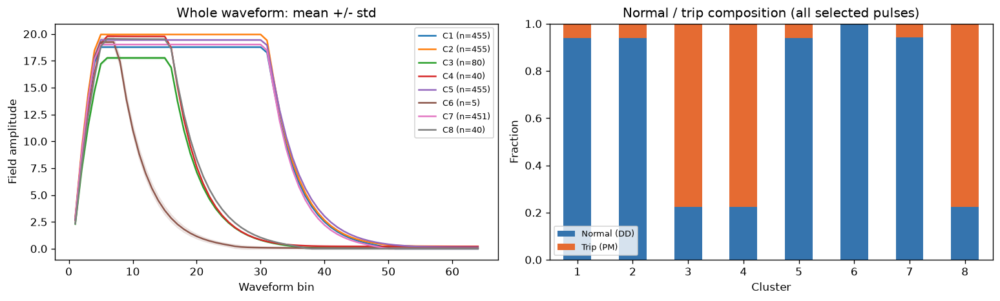

Plateau


label_name,Normal (DD),Trip (PM),n_pulses,trip_fraction,cavity_101,cavity_201,cavity_301,cavity_401
cluster,,,,,,,,
1,427,28,455,0.062,0,455,0,0
2,427,28,455,0.062,0,0,455,0
3,427,28,455,0.062,455,0,0,0
4,425,26,451,0.058,0,0,0,451
5,9,31,40,0.775,40,0,0,0
6,9,31,40,0.775,0,0,0,40


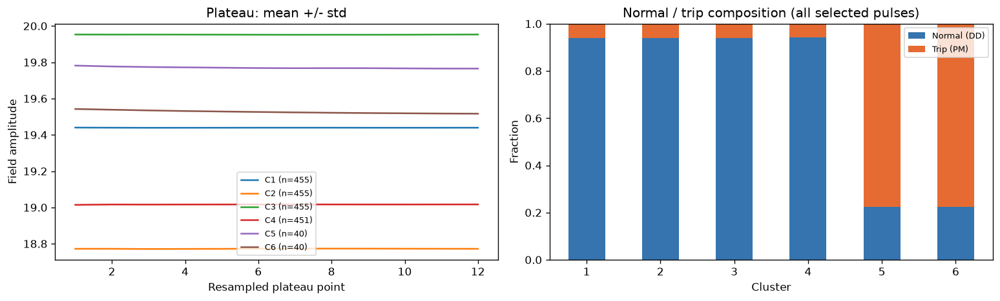

Centered plateau


label_name,Normal (DD),Trip (PM),n_pulses,trip_fraction,cavity_101,cavity_201,cavity_301,cavity_401
cluster,,,,,,,,
1,1706,110,1816,0.061,455,455,455,451
2,18,62,80,0.775,40,0,0,40


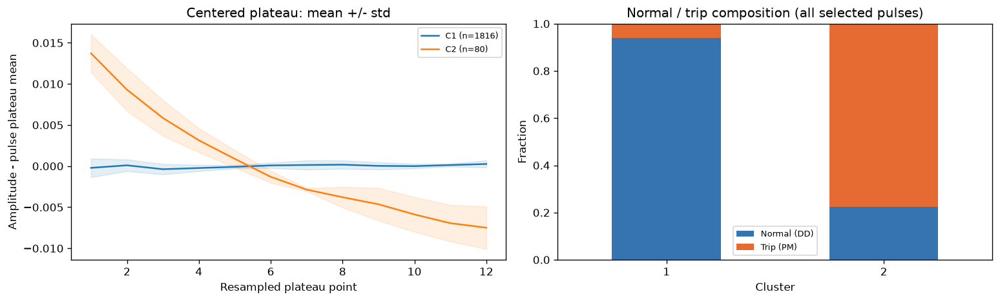

In [146]:
cluster_profiles = {}
for cluster_view_name, cluster_view in cluster_views.items():
    cluster_member = cluster_memberships[cluster_view_name]
    cluster_counts = pd.crosstab(cluster_member["cluster"], cluster_member["label_name"]).reindex(
        columns=["Normal (DD)", "Trip (PM)"], fill_value=0
    )
    cluster_profile = cluster_counts.copy()
    cluster_profile["n_pulses"] = cluster_counts.sum(axis=1)
    cluster_profile["trip_fraction"] = cluster_counts["Trip (PM)"] / cluster_profile["n_pulses"]
    for cluster_cavity in sorted(cluster_member["cavity_short"].unique()):
        cluster_profile[f"cavity_{cluster_cavity}"] = (
            cluster_member.loc[cluster_member["cavity_short"] == cluster_cavity]
            .groupby("cluster").size().reindex(cluster_profile.index, fill_value=0)
        )
    cluster_profiles[cluster_view_name] = cluster_profile
    print(cluster_view_name)
    display(cluster_profile.round(3))

    cluster_fig, cluster_axes = plt.subplots(1, 2, figsize=(13, 4))
    cluster_plot_x = np.arange(1, cluster_view["x"].shape[1] + 1)
    for cluster_id in cluster_profile.index:
        cluster_values = cluster_view["x"][cluster_view["clusters"] == cluster_id]
        cluster_mean, cluster_std = cluster_values.mean(axis=0), cluster_values.std(axis=0)
        cluster_color = plt.get_cmap("tab10")(cluster_id - 1)
        cluster_axes[0].plot(cluster_plot_x, cluster_mean, color=cluster_color,
                             label=f"C{cluster_id} (n={len(cluster_values)})")
        cluster_axes[0].fill_between(cluster_plot_x, cluster_mean - cluster_std,
                                     cluster_mean + cluster_std, color=cluster_color, alpha=0.12)
    cluster_axes[0].set(xlabel="Waveform bin" if cluster_view_name == "Whole waveform" else "Resampled plateau point",
                         ylabel="Field amplitude" if cluster_view_name != "Centered plateau" else "Amplitude - pulse plateau mean",
                         title=f"{cluster_view_name}: mean +/- std")
    cluster_axes[0].legend(fontsize=8)
    cluster_fractions = cluster_counts.div(cluster_counts.sum(axis=1), axis=0)
    cluster_fractions.plot.bar(stacked=True, ax=cluster_axes[1],
                                color=["#3574ae", "#e56b32"], rot=0)
    cluster_axes[1].set(xlabel="Cluster", ylabel="Fraction", ylim=(0, 1),
                         title="Normal / trip composition (all selected pulses)")
    cluster_axes[1].legend(fontsize=8, loc="best")
    cluster_fig.tight_layout()
    plt.show()


### Findings in this dataset

- The four cavities contain **1,981 complete waveforms**. Using the same plateau-extraction rules, **1,896 pulses** have usable plateaux: 1,724 normal pulses and 172 trip pulses.
- Among the tested values of k=2 through 8, the whole-waveform representation selects **8 clusters** and the plateau representation selects **6 clusters**. Each of the four large plateau clusters corresponds to a single cavity.
- Subtracting each plateau's mean amplitude produces **2 clusters**. The smaller cluster contains **62 trip pulses out of 80 pulses (77.5%)**; the larger cluster contains **110 trip pulses out of 1,816 pulses (6.1%)**.
- Both clusters contain normal and trip pulses. Use the composition tables to examine the relationship between clusters and labels.

### Scope of this visualization

- The original normal/trip proportions are retained. The 1:1 sampling used for classifier evaluation is not applied here.
- This section explores the data without supervision. Autoencoder residuals and classifier predictions are not used.
- Silhouette scores are computed in the original standardized feature space, using a sample of up to 1,200 points selected with a fixed random seed. The score measures cluster separation, not trip-classification accuracy.
- Interpolation aligns plateau lengths, so the plateau representations do not retain differences in their original duration.
- Original dataset row indices, cavity identifiers, labels, cluster assignments, and PCA coordinates are available in tables such as `cluster_memberships["Whole waveform"]`.


## Trip causes on the existing PCA clusters

既存の **Whole waveform・Plateau・Centered plateau** のPCA座標に、
`trip_events.csv` の `systems` 欄をtrip原因カテゴリとして併記します。
原因は点の色と集計にだけ使用し、PCA・K-means・クラスター数の選択には使用しません。

- 左：K-meansのクラスター、中央：trip原因、右：実際の `event_ts` による取得年。
  3パネルで点の位置は共通です。中央の `C1` 等は元のクラスターの位置を示します。
- 正常は灰色、原因が掲載されているtripはカテゴリ別の色、未掲載tripは黒の `+`。
- 元ParquetのUTC `event_ts` と原因CSVの時刻をナノ秒精度で完全一致させます。
  一致したイベントは `event_id` も検証し、近い時刻の別イベントへの割当てはしません。
- `systems` に複数系統がある場合は、全組合せを保持します。
  系統別の集計では各系統に1件ずつ数え、`n_labels` を単一原因には変換しません。
- 波形のcavityと、イベント全体に記録された原因系統は別の情報です。

対応できたのはtrip **59収録中43収録（234 waveform中170）**。
残り16収録（64 waveform）は「Unlisted trip」として残します。
原因CSVにあっても、この4 cavityの解析対象にない17イベントは別CSVに保存します。


In [169]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

trip_cause_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_trip_cause_pca.py").is_file()
)
if str(trip_cause_notebook_dir) not in sys.path:
    sys.path.insert(0, str(trip_cause_notebook_dir))
import cavity_signal_comparison as trip_cause_signal_tools
trip_cause_signal_tools = importlib.reload(trip_cause_signal_tools)
import cavity_signal_beam_mode as trip_cause_data_tools
trip_cause_data_tools = importlib.reload(trip_cause_data_tools)
import cavity_trip_cause_pca as trip_cause_tools
trip_cause_tools = importlib.reload(trip_cause_tools)

trip_cause_csv = next(p for p in [
    Path("/workspace/lustre/work/pdl18409/shared/Anomaly_Hunter/trip_label/trip_events.csv"),
    Path("/lustre/work/pdl18409/shared/Anomaly_Hunter/trip_label/trip_events.csv"),
] if p.is_file())
trip_cause_output = trip_cause_notebook_dir / "signal_comparison" / "trip_cause_pca"
REBUILD_TRIP_CAUSE_PCA = False
trip_cause_live_views = globals().get("cluster_views")
trip_cause_cached = all((trip_cause_output / f"{name}.csv").is_file() for name in trip_cause_tools.TABLES)
trip_cause_cache_fresh = trip_cause_cached and (
    (trip_cause_output / "metadata.csv").stat().st_mtime >= trip_cause_csv.stat().st_mtime
)
if trip_cause_live_views is not None:
    # Reuse the exact coordinates and cluster IDs already displayed above.
    trip_cause_result = trip_cause_tools.make_result(
        trip_cause_notebook_dir, cause_path=trip_cause_csv, existing_views=trip_cause_live_views
    )
    trip_cause_tools.save_results(trip_cause_result, trip_cause_output)
    print("Existing PCA coordinates and clusters reused; event annotations refreshed.")
elif not REBUILD_TRIP_CAUSE_PCA and trip_cause_cache_fresh:
    trip_cause_result = trip_cause_tools.load_results(trip_cause_output)
    print("Loaded the reproduced original clustering and exact event_ts annotations.")
else:
    trip_cause_result = trip_cause_tools.make_result(trip_cause_notebook_dir, cause_path=trip_cause_csv)
    trip_cause_tools.save_results(trip_cause_result, trip_cause_output)
    print("Original unsupervised clustering reproduced and trip causes attached.")

print("Cause source:", trip_cause_csv)
display(trip_cause_result["coverage"])
display(trip_cause_result["view_summary"].round(4))


Loaded the reproduced original clustering and exact event_ts annotations.
Cause source: /lustre/work/pdl18409/shared/Anomaly_Hunter/trip_label/trip_events.csv


,status,waveforms,captures
0,normal,1747,34
1,matched,170,43
2,unlisted,64,16


,representation,n_waveforms,n_features,selected_k,silhouette,PC1_variance,PC2_variance
0,Whole waveform,1981,64,8,0.9688,0.6290,0.2489
1,Plateau,1896,12,6,0.9985,1.0000,0.0000
2,Centered plateau,1896,12,2,0.8573,0.8245,0.0930


In [170]:
print("各クラスターのwaveform数と収録数")
display(trip_cause_result["cluster_summary"].sort_values(["representation", "cluster"]).reset_index(drop=True))

for trip_cause_view in trip_cause_result["view_summary"]["representation"]:
    trip_cause_systems = trip_cause_result["system_counts"].query("representation == @trip_cause_view")
    trip_cause_event_table = trip_cause_systems.pivot(
        index="cluster", columns="system", values="captures"
    ).fillna(0).astype(int)
    print(trip_cause_view, "：クラスター × 原因系統（収録件数）")
    display(trip_cause_event_table)

print("原因CSVに未掲載のtrip収録（時刻の近い別イベントには割り当てていません）")
display(trip_cause_result["unlisted_trip_events"].reset_index(drop=True))


各クラスターのwaveform数と収録数


,representation,cluster,normal_waveforms,trip_waveforms,normal_captures,trip_captures,matched_trip_waveforms,unlisted_trip_waveforms
0,Centered plateau,1,1706,110,33,28,74,36
1,Centered plateau,2,18,62,1,31,48,14
2,Plateau,1,427,28,33,28,19,9
3,Plateau,2,427,28,33,28,19,9
4,Plateau,3,427,28,33,28,19,9
5,Plateau,4,425,26,33,26,17,9
6,Plateau,5,9,31,1,31,24,7
7,Plateau,6,9,31,1,31,24,7
8,Whole waveform,1,427,28,33,28,19,9
9,Whole waveform,2,427,28,33,28,19,9


Whole waveform ：クラスター × 原因系統（収録件数）


system,BCM (beam current),BPM (beam position),DTL tank,Dump-line imaging,HBL cavity,MBL cavity,MEBT buncher,RFQ,Spoke cavity,Unlisted trip
cluster,,,,,,,,,,
1,5,5,1,9,2,3,0,0,0,9
2,5,5,1,9,2,3,0,0,0,9
3,1,0,3,0,1,0,17,1,1,7
4,1,0,3,0,1,0,17,1,1,7
5,5,5,1,9,2,3,0,0,0,9
7,3,5,1,9,0,1,0,0,0,9
8,1,0,3,0,1,0,17,1,1,7


Plateau ：クラスター × 原因系統（収録件数）


system,BCM (beam current),BPM (beam position),DTL tank,Dump-line imaging,HBL cavity,MBL cavity,MEBT buncher,RFQ,Spoke cavity,Unlisted trip
cluster,,,,,,,,,,
1,5,5,1,9,2,3,0,0,0,9
2,5,5,1,9,2,3,0,0,0,9
3,5,5,1,9,2,3,0,0,0,9
4,3,5,1,9,0,1,0,0,0,9
5,1,0,3,0,1,0,17,1,1,7
6,1,0,3,0,1,0,17,1,1,7


Centered plateau ：クラスター × 原因系統（収録件数）


system,BCM (beam current),BPM (beam position),DTL tank,Dump-line imaging,HBL cavity,MBL cavity,MEBT buncher,RFQ,Spoke cavity,Unlisted trip
cluster,,,,,,,,,,
1,5,5,1,9,2,3,0,0,0,9
2,1,0,3,0,1,0,17,1,1,7


原因CSVに未掲載のtrip収録（時刻の近い別イベントには割り当てていません）


,source,event_id,event_ts,event_year,beam_mode,beam_present,trig_delay
0,PM,15643012382,2025-05-29 06:45:42.982275840+00:00,2025,Probe,True,200.005676
1,PM,15643016190,2025-05-29 06:50:14.982704896+00:00,2025,Probe,False,200.005676
2,PM,15643035093,2025-05-29 07:12:45.195043584+00:00,2025,Probe,False,200.005676
3,PM,15643049090,2025-05-29 07:29:24.982075136+00:00,2025,Probe,False,200.005676
4,PM,15643457698,2025-05-29 15:35:51.299742464+00:00,2025,NoBeam,False,200.005676
5,PM,15644066092,2025-05-30 03:40:07.984749568+00:00,2025,Probe,True,200.005676
6,PM,15644067268,2025-05-30 03:41:31.998913024+00:00,2025,Probe,True,200.005676
7,PM,16122468314,2026-06-29 15:41:18.063747048+00:00,2026,RfTest,True,250.000153
8,PM,16122470176,2026-06-29 15:43:31.063740791+00:00,2026,Probe,True,250.000153
9,PM,16122508032,2026-06-29 16:28:35.095212049+00:00,2026,SlowCommissioning,True,250.000153


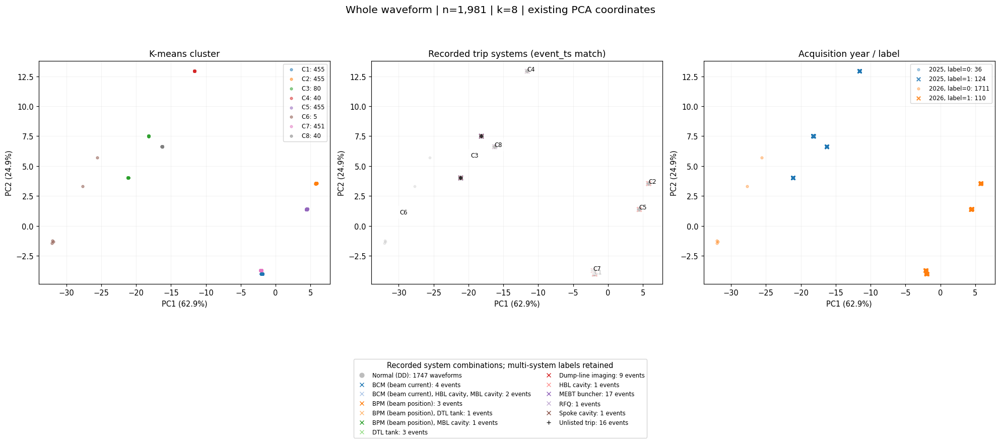

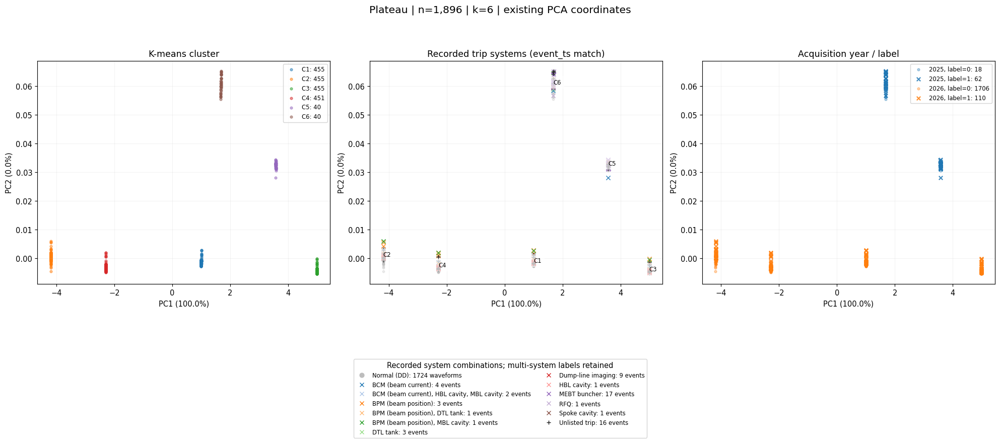

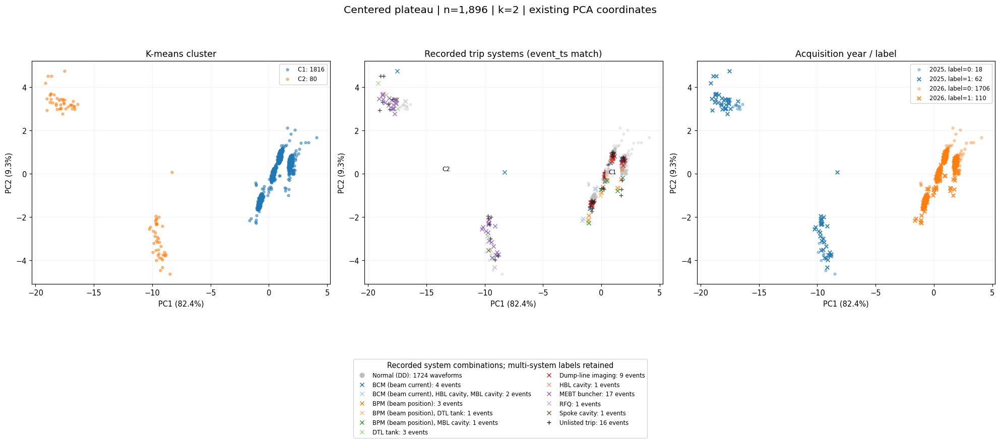

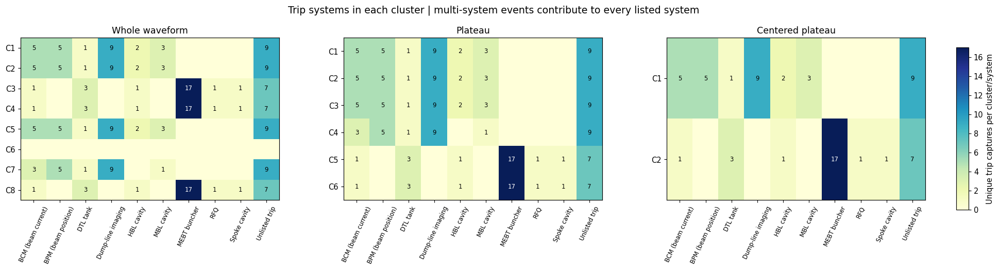

In [171]:
trip_cause_figure_files = []
for trip_cause_view_name, trip_cause_figure in trip_cause_tools.plot_cause_scatter(trip_cause_result):
    trip_cause_figure_path = trip_cause_output / (
        trip_cause_view_name.lower().replace(" ", "_") + "_trip_causes.png"
    )
    trip_cause_figure.savefig(trip_cause_figure_path, dpi=140, bbox_inches="tight")
    trip_cause_figure_files.append(trip_cause_figure_path)
    plt.show()

trip_cause_heatmap_figure = trip_cause_tools.plot_system_heatmaps(trip_cause_result)
trip_cause_heatmap_figure.savefig(trip_cause_output / "cluster_recorded_systems.png", dpi=140, bbox_inches="tight")
plt.show()


### Reading the trip-cause annotations

Centered plateauのC2には、MEBT buncherが記載された17収録が含まれますが、
Spoke cavity・DTL tank・RFQ・BCM・HBL cavity・原因未掲載のイベントも含まれます。
クラスターが1種類の原因だけに対応しているわけではありません。

さらにこのデータでは、Centered plateauの **C1は2026年の1,816 waveform、
C2は2025年の80 waveform** に一致しています。取得年とtrig_delayが対応している
ことも既に確認しているため、この分離をtrip原因だけによるものとは解釈できません。

系統別の表・ヒートマップは、同じクラスター内の同一収録をcavity間で重複して数えません。
ただし、複数系統のイベントは複数列に入り、同じイベントの別cavityが別クラスターに
入る場合もあります。そのため列・クラスターを足した合計は独立した収録総数にはなりません。

`memberships.csv` には、各点の `dataset_index`, `event_id`, `event_ts`, `cavity`,
`beam_mode`, `event_year`, `cluster`, `PC1`, `PC2`, `trip_systems`, `trip_cause_status`
を保存しています。対応表・未掲載一覧・集計・図はすべて
`signal_comparison/trip_cause_pca/` にあります。


## All-cavity trip signatures and recorded causes

4つのHBL cavityに限定していた解析を、**全82 cavity（HBL 20、MBL 36、Spoke 26）**に拡張します。
NormalはDDの全35,414波形セット（43収録、81 cavity）、TripはPMの各cavity最終4,809波形セット
（65収録、82 cavity）です。最初に全cavityのデータ数を表示します。
1波形セットは、1つのcavity・1つのpulseの信号の組であり、信号の種類をまとめて1本の波形とは呼びません。

**今回の目的はtrip原因の比較なので、クラスタリングの1点は1つのtrip収録です。**
NormalとTripの二値分類や検出精度の評価は行いません。Normalは全件を数えて確認し、
クラスターの学習には投入しません。Normal/Tripの比較は上・下の既存セクションとは別の解析です。

全cavityで保存済みのField振幅・Field位相・Forward振幅・Reflected振幅の特徴量を使います。
Forward/Reflected位相は全82 cavityでは準備されていないため、この解析には含めません。
元Parquetの高解像度波形から抽出済みのflat-top特徴と、64binのField振幅の変化を使い、
新しい分類器は作りません。

### 特徴の作り方

各cavityについて、PM収録の**前半のpulse**を基準にし、最終pulseがどれだけ変わったかを測ります。
前半は元の特徴抽出器と同じ `cycle_rank_from_last * 2 >= cycles_in_event` で選びます。
Field振幅・Forward振幅の相対変化、flat-topの揺らぎ・傾き・最大stepの変化、
位相の変化・ばらつきの変化、反射/入射の記録振幅比の変化など、15特徴を使います。
位相は円周上で扱い、反射/入射の振幅比を電力比には変換しません。
基準pulseがない、またはflat-topが定義できない特徴は欠測のまま残します。

82 cavity × 15特徴の**cavityの位置を保持した1,230特徴**で収録を比較します。
全cavityを単純平均してしまうことはありません。距離は両方の収録で観測できた特徴だけから計算し、
重複する特徴数に応じて補正します。欠測を「変化なし」の0には置き換えません。
詳細は[欠測を扱う距離の定義](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.nan_euclidean_distances.html)を参照してください。

全体の比較には、82 cavityの75%以上が存在し、全特徴の60%以上が有効な収録を使用します。
該当するのは59収録で、この中に82 cavityすべての測定が含まれます。
取得cavityが1〜38個の6収録は別表に残します。65収録すべてが完全な82 cavityを含むわけではありません。

階層型クラスタリングはk=2〜6をsilhouetteで比較し、最小群3収録を条件とします。
HDBSCANは `min_cluster_size=4, min_samples=3` の固定値で比較します。
原因ラベルは特徴・距離・群の作成・パラメータ選択に使いません。
原因CSVはUTCの `event_ts` 完全一致で結合し、`event_id` も照合します。


In [178]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

all_cavity_root = next(p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
                       if (p / "cavity_all_cavity_trip_clusters.py").is_file())
if str(all_cavity_root) not in sys.path:
    sys.path.insert(0, str(all_cavity_root))
import cavity_all_cavity_trip_clusters as all_cavity_tools
all_cavity_tools = importlib.reload(all_cavity_tools)
all_cavity_output = all_cavity_root / "signal_comparison" / "all_cavity_trip_clusters"
REBUILD_ALL_CAVITY_CLUSTERS = False
all_cavity_inputs = all_cavity_tools.input_paths(all_cavity_root) + [Path(all_cavity_tools.__file__)]
all_cavity_cache = [all_cavity_output / f"{name}.csv" for name in all_cavity_tools.TABLES]
all_cavity_fresh = all(p.is_file() for p in all_cavity_cache) and (
    min(p.stat().st_mtime for p in all_cavity_cache) >= max(p.stat().st_mtime for p in all_cavity_inputs)
)
if all_cavity_fresh and not REBUILD_ALL_CAVITY_CLUSTERS:
    all_cavity_result = all_cavity_tools.load_results(all_cavity_output)
else:
    all_cavity_result = all_cavity_tools.make_result(all_cavity_root)
    all_cavity_tools.save_results(all_cavity_result, all_cavity_output)

print("全cavityのlabel別データ数（waveform_setsは信号1種類あたりの件数）")
display(all_cavity_result["coverage"])
print("全82 cavityのデータ数と、収録内比較の基準があるTripの数")
display(all_cavity_result["cavity_support"])
print("全Trip 65収録の原因対応")
display(all_cavity_result["event_metadata"].groupby("cause_status").agg(
    captures=("event_id", "size"), min_cavities=("n_cavities", "min"), max_cavities=("n_cavities", "max")
).reset_index())
print("データ範囲が狭いため、全体のクラスタリングに割り当てない6収録")
display(all_cavity_result["memberships"].query("method == 'Not clustered'")[[
    "event_id", "event_ts", "n_cavities", "feature_coverage", "trip_cause", "status"
]].reset_index(drop=True))


全cavityのlabel別データ数（waveform_setsは信号1種類あたりの件数）


,label,population,waveform_sets,captures,cavities,field_amp_valid,field_phase_valid,fwd_amp_valid,refl_amp_valid
0,0,Normal (DD all pulses),35414,43,81,35414,35413,35414,35414
1,1,Trip (PM last per cavity),4809,65,82,4809,4809,4808,4809


全82 cavityのデータ数と、収録内比較の基準があるTripの数


,cavity,section,normal_waveform_sets,normal_captures,trip_waveform_sets,trip_captures,trip_with_shape_reference,trip_in_main_analysis
0,HBL-010RFC:RFS-DIG-101,HBL,437,34,59,59,59,59
1,HBL-010RFC:RFS-DIG-201,HBL,437,34,59,59,59,59
2,HBL-010RFC:RFS-DIG-301,HBL,437,34,59,59,59,59
3,HBL-010RFC:RFS-DIG-401,HBL,436,34,57,57,57,57
4,HBL-020RFC:RFS-DIG-101,HBL,427,33,57,57,57,57
5,HBL-020RFC:RFS-DIG-201,HBL,427,33,57,57,57,57
6,HBL-020RFC:RFS-DIG-301,HBL,427,33,57,57,57,57
7,HBL-020RFC:RFS-DIG-401,HBL,428,33,59,59,59,59
8,HBL-030RFC:RFS-DIG-101,HBL,428,33,59,59,59,59
9,HBL-030RFC:RFS-DIG-201,HBL,428,33,59,59,59,59


全Trip 65収録の原因対応


,cause_status,captures,min_cavities,max_cavities
0,matched,45,8,81
1,unlisted,20,1,81


データ範囲が狭いため、全体のクラスタリングに割り当てない6収録


,event_id,event_ts,n_cavities,feature_coverage,trip_cause,status
0,16096616902,2026-06-08 06:46:39.713014542+00:00,4,0.008130,Unlisted trip,partial_capture
1,16096680910,2026-06-08 08:02:51.712800783+00:00,4,0.008130,Unlisted trip,partial_capture
2,16096701802,2026-06-08 08:27:44.018994724+00:00,1,0.002439,Unlisted trip,partial_capture
3,16098736138,2026-06-10 00:49:33.706110229+00:00,8,0.052033,BCM (beam current),partial_capture
4,16098984770,2026-06-10 05:45:33.177389511+00:00,8,0.052033,Unlisted trip,partial_capture
5,16122596526,2026-06-29 18:13:56.062983186+00:00,38,0.463415,"BPM (beam position), DTL tank, HBL cavity, MBL cavity",partial_capture


In [179]:
print("原因ラベルを使わない階層型クラスタリングのk選択")
display(all_cavity_result["selection"].round(4))
print("クラスタリング後の原因との対応（AMI）と、取得条件を考慮した置換検定")
display(all_cavity_result["metrics"].round(4))

all_cavity_method = "HDBSCAN"
all_cavity_counts = all_cavity_result["cluster_causes"].query("method == @all_cavity_method").pivot(
    index="cluster", columns="trip_cause", values="events"
).fillna(0).astype(int)
print("HDBSCANの群 × 原因（独立した収録数。cluster=-1はNoise）")
display(all_cavity_counts)
print("各群の違いを説明するcavityと特徴（各群の上位5件）")
display(all_cavity_result["cluster_drivers"].query(
    "method == @all_cavity_method and rank <= 5"
).reset_index(drop=True).round(6))
print("比較する2収録の間で共通して観測できた特徴の割合")
display(all_cavity_result["distance_overlap"][["common_feature_fraction"]].describe().round(4))


原因ラベルを使わない階層型クラスタリングのk選択


,k,silhouette,min_cluster_events,eligible,selected
0,2,0.7436,1,False,False
1,3,0.7175,1,False,False
2,4,0.6247,1,False,False
3,5,0.5238,1,False,False
4,6,0.4779,1,False,False


クラスタリング後の原因との対応（AMI）と、取得条件を考慮した置換検定


,method,events,annotated_events,n_clusters,noise_events,cause_AMI,conditional_permutation_p,permutation_controls,year_AMI,beam_mode_AMI,conditional_p_holm
0,Hierarchical,59,43,0,0,0.0000,1.000,"event_date,beam_mode,beam_present",0.0000,0.0000,1.000
1,HDBSCAN,59,43,3,7,0.4307,0.002,"event_date,beam_mode,beam_present",0.2841,0.1796,0.004


HDBSCANの群 × 原因（独立した収録数。cluster=-1はNoise）


trip_cause,BCM (beam current),"BCM (beam current), HBL cavity, MBL cavity",BPM (beam position),"BPM (beam position), DTL tank","BPM (beam position), MBL cavity",DTL tank,Dump-line imaging,HBL cavity,MEBT buncher,RFQ,Spoke cavity,Unlisted trip
cluster,,,,,,,,,,,,
-1,0,2,0,0,1,0,0,0,0,0,1,3
1,0,0,2,1,0,0,0,0,0,0,0,3
2,4,0,1,0,0,0,9,0,6,0,0,9
3,0,0,0,0,0,3,0,1,11,1,0,1


各群の違いを説明するcavityと特徴（各群の上位5件）


,method,cluster,rank,cavity,feature,cluster_median_change,other_trip_median_change,scaled_difference,events_with_feature
0,HDBSCAN,1,1,MBL-090RFC:RFS-DIG-401,flat_step_change_rel,0.000867,-0.000028,2.947250,6
1,HDBSCAN,1,2,HBL-020RFC:RFS-DIG-101,flat_step_change_rel,0.000722,0.000000,2.850714,6
2,HDBSCAN,1,3,HBL-030RFC:RFS-DIG-201,flat_step_change_rel,0.001863,-0.000010,2.803719,6
3,HDBSCAN,1,4,MBL-020RFC:RFS-DIG-301,flat_step_change_rel,0.001116,0.000005,2.790281,6
4,HDBSCAN,1,5,HBL-020RFC:RFS-DIG-301,flat_step_change_rel,0.000935,-0.000012,2.778716,6
5,HDBSCAN,2,1,Spk-120RFC:RFS-DIG-201,flat_step_change_rel,-0.000005,-0.000957,1.822922,29
6,HDBSCAN,2,2,Spk-100RFC:RFS-DIG-201,flat_step_change_rel,-0.000005,-0.000872,1.776238,29
7,HDBSCAN,2,3,Spk-120RFC:RFS-DIG-101,flat_step_change_rel,0.000006,-0.000905,1.735061,29
8,HDBSCAN,2,4,Spk-070RFC:RFS-DIG-201,flat_step_change_rel,-0.000011,-0.000617,1.521398,29
9,HDBSCAN,2,5,Spk-110RFC:RFS-DIG-201,flat_step_change_rel,-0.000003,-0.000586,1.414770,29


比較する2収録の間で共通して観測できた特徴の割合


,common_feature_fraction
count,1711.0000
mean,0.9637
std,0.0456
min,0.7041
25%,0.9756
50%,0.9756
75%,0.9878
max,0.9878


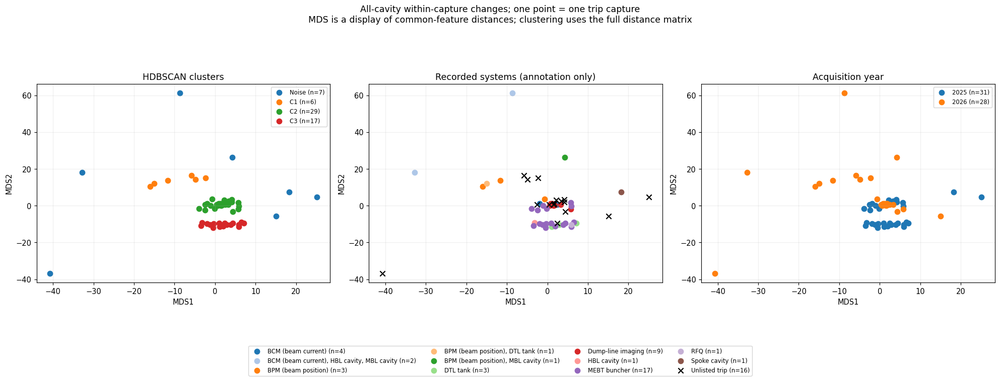

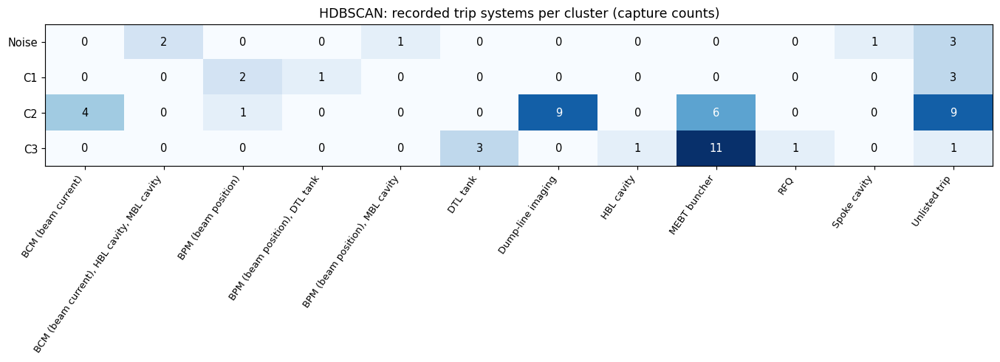

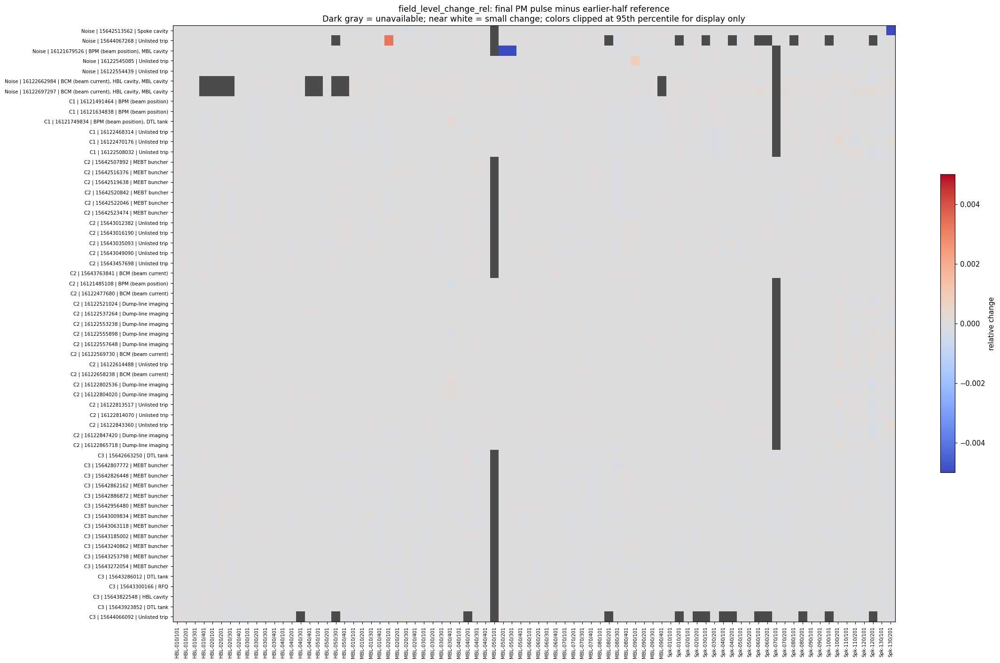

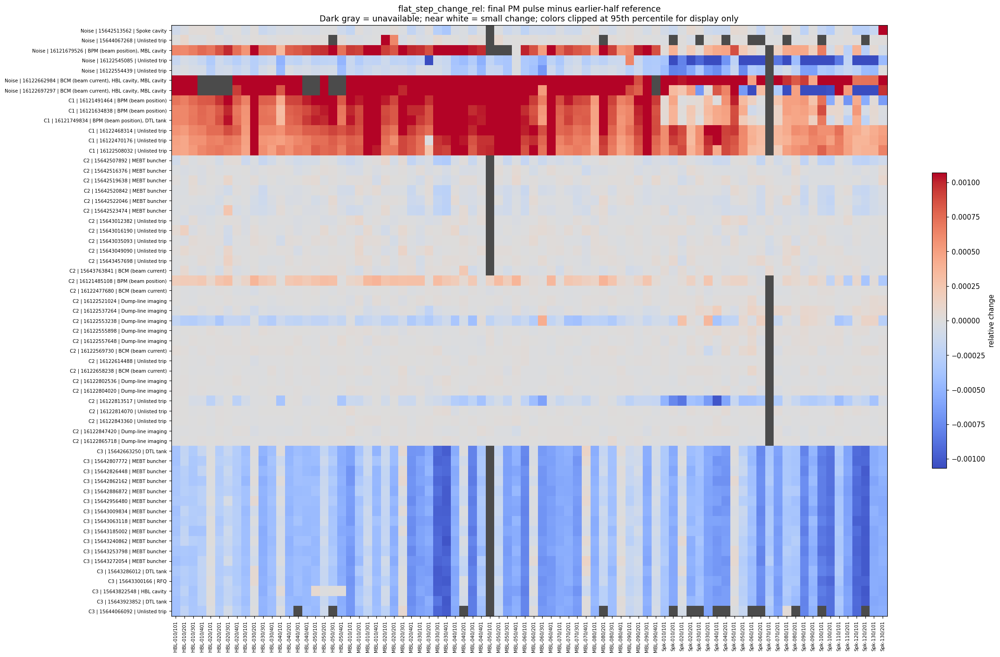

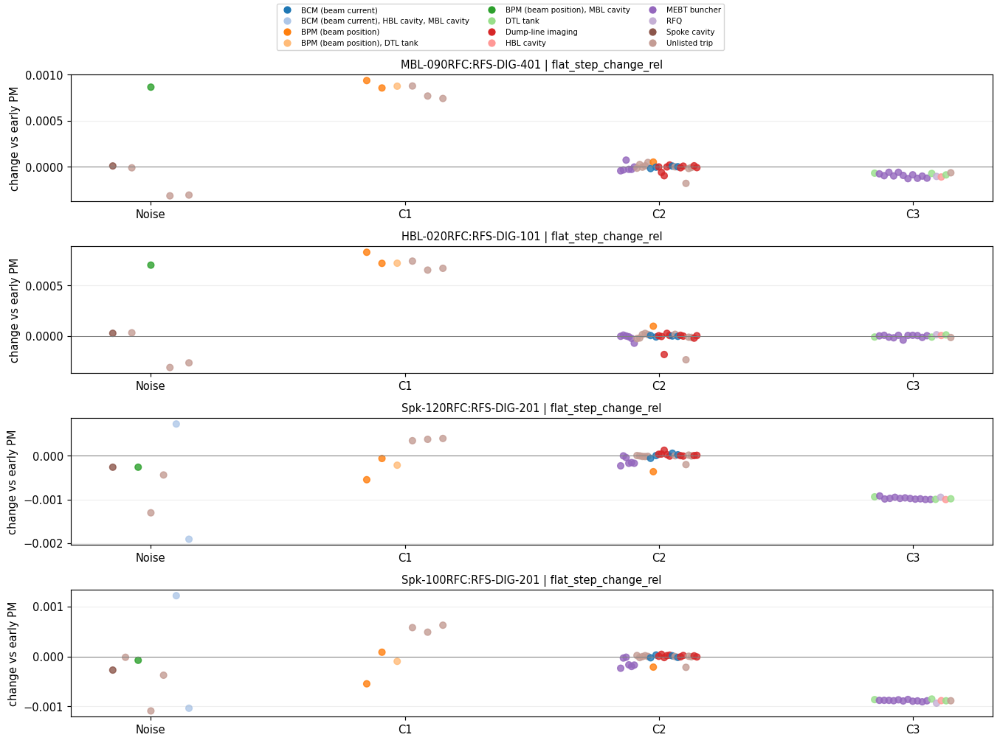

In [180]:
# MDSは距離関係の表示用。2次元の見かけからクラスタリングしていません。
all_cavity_fig = all_cavity_tools.plot_scatter(all_cavity_result, method=all_cavity_method)
all_cavity_fig.savefig(all_cavity_output / "hdbscan_scatter.png", dpi=140, bbox_inches="tight")
plt.show()
all_cavity_fig = all_cavity_tools.plot_cause_counts(all_cavity_result, method=all_cavity_method)
all_cavity_fig.savefig(all_cavity_output / "hdbscan_cause_counts.png", dpi=140, bbox_inches="tight")
plt.show()

# 各行が1収録、各列が1cavity。灰色は欠測で、変化0とは区別しています。
for all_cavity_feature in ["field_level_change_rel", "flat_step_change_rel"]:
    all_cavity_fig = all_cavity_tools.plot_cavity_changes(
        all_cavity_result, feature=all_cavity_feature, method=all_cavity_method
    )
    all_cavity_fig.savefig(all_cavity_output / f"{all_cavity_feature}.png", dpi=140, bbox_inches="tight")
    plt.show()
all_cavity_fig = all_cavity_tools.plot_top_features(all_cavity_result, method=all_cavity_method)
if all_cavity_fig is not None:
    all_cavity_fig.savefig(all_cavity_output / "cluster_feature_profiles.png", dpi=140, bbox_inches="tight")
    plt.show()


### What the all-cavity clusters show

この設定のHDBSCANでは、59収録が **C1=6、C2=29、C3=17、Noise=7** に分かれました。
Noiseは「異常原因が判明した」という意味ではなく、この設定で密度群に割り当てられない収録です。
新しいC1等は、この節だけの番号です。以前のPCAクラスターの同じ番号とは対応しません。

| 群 | 波形で目立つ違い | 記録された原因の内訳 |
|---|---|---|
| C1（6収録） | MBL/HBLの一部でflat-topの最大stepが収録前半より増加 | BPM単独2、BPM+DTL 1、未掲載3 |
| C2（29収録） | C3で見られるSpokeのstep低下が小さい群 | Dump-line imaging 9、MEBT 6、BCM 4、BPM 1、未掲載9 |
| C3（17収録） | Spokeを含む多くのcavityでflat-topの最大stepが収録前半より低下 | MEBT 11、DTL 3、RFQ 1、HBL 1、未掲載1 |
| Noise（7収録） | 互いに異なるため、1つの共通した説明を付けない | Spoke 1、BPM+MBL 1、BCM+HBL+MBL 2、未掲載3 |

ここで「step低下」は波形の段差の指標が小さくなったという観測であり、trip原因が解明できたという意味ではありません。
実際、MEBT原因17収録はC2に6、C3に11と分かれています。
原因が違っても似た波形変化が出る一方、同じ原因でも波形変化が異なる場合があります。
クラスター名をそのまま原因名に置き換えることはできません。

原因が掲載された43収録に限ったAMIは約0.431です。
AMIは原因区分とクラスターの一致を偶然の一致分で補正する指標で、検出率や分類精度ではありません。
**同じUTC取得日・beam mode・beam_present内だけで原因ラベルを入れ替える**999回の置換ではp=0.002、
比較した2手法についてHolm補正するとp=0.004でした。この条件内でも対応が見られる探索結果ですが、
C3は全件2025年であり、より細かい時刻・運転状態の影響や、少数事例による不確かさは残ります。
独立した収録での検証は行っておらず、根本原因の推定性能は示していません。
[AMIの定義](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_mutual_info_score.html)、
[HDBSCANの定義](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html)。

階層型のk=2〜6では、どのkでも1収録だけの小群ができたため、最小群3収録という条件を満たさず、
この解析では全点を無理に分割しませんでした。原因との一致を見てkを選び直していません。

全65収録の原因対応は45収録が掲載、20収録が未掲載です。全体のクラスタリングに使った59収録では
43収録が掲載、16収録が未掲載です。1つの原因に複数系統が記載された場合は全組合せを保持します。
一部のcavityは同じ収録の最終cycleが他のcavityより古いため、
`n_cycle_ids`, `n_metadata_states`, `max_last_cycle_age_s` を対応表に残しています。
同じeventでも全cavityの最終pulseが完全に同時とは限りません。

全cavityの件数、各収録・cavityの変化量、欠測状況、群所属、原因内訳、説明に使った特徴と図は
`signal_comparison/all_cavity_trip_clusters/` に保存します。


In [ ]:
# 

## Optional classifier benchmark for the six signals

The direct waveform-change comparison is in the section [Direct waveform changes within matched beam conditions](#direct-waveform-changes-within-matched-beam-conditions). The classifier results below measure a different quantity.

These datasets contain the **same 1,981 pulses from the same four cavities** as
the whole-waveform exploration above: **1,747 normal DD pulses and 234 final PM
pulses**, with **64 bins per waveform**. Event, cycle, cavity, label, and original
dataset row index are aligned across all signals.

| Signal | Raw PV component | Input source |
|---|---|---|
| Field amplitude | Dwn0-Cmp0 | Existing `field_amp_bins` |
| Field phase | Dwn0-Cmp1 | Existing `field_phase_bins` |
| Forward amplitude | Dwn5-Cmp0 | Existing `fwd_amp_bins` |
| Forward phase | Dwn5-Cmp1 | Matching raw SDS captures, binned to 64 points |
| Reflected amplitude | Dwn6-Cmp0 | Existing `refl_amp_bins` |
| Reflected phase | Dwn6-Cmp1 | Matching raw SDS captures, binned to 64 points |

Phase bins use circular means. Phase features are represented by sine and cosine
so that the -180/180-degree boundary does not create an artificial jump.
No plateau extraction or outlier removal is applied in this comparison.

Each signal has its own CSV with the original schema:
`cavity, value_1, ..., value_64, label`. The shared pulse keys are stored separately
in `signal_comparison/pulse_metadata.csv`; `waveforms.npz` stores the six aligned arrays.


In [147]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

signal_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_signal_comparison.py").is_file()
)
if str(signal_notebook_dir) not in sys.path:
    sys.path.insert(0, str(signal_notebook_dir))
import cavity_signal_comparison as signal_tools
signal_tools = importlib.reload(signal_tools)
signal_output_dir = signal_notebook_dir / "signal_comparison"
signal_metadata, signal_waveforms = signal_tools.load_datasets(signal_output_dir)
signal_availability = pd.read_csv(signal_output_dir / "signal_availability.csv")
print(f"Aligned pulses: {len(signal_metadata):,}; bins per waveform: {signal_tools.N_BINS}")
display(signal_availability)
display(pd.crosstab(signal_metadata["cavity"], signal_metadata["label"]).rename(
    columns={0: "Normal (DD)", 1: "Trip (PM)"}
))

# Optional: rebuild all datasets from the original feature tables and SDS archives.
# This requires pyarrow and access to the raw captures.
# signal_metadata, signal_waveforms = signal_tools.build_signal_datasets(
#     signal_notebook_dir, signal_notebook_dir.parents[3] / "raw"
# )


Aligned pulses: 1,981; bins per waveform: 64


,signal,usable,missing,normal,trip
0,field_amp,1981,0,1747,234
1,field_phase,1981,0,1747,234
2,fwd_amp,1981,0,1747,234
3,fwd_phase,1981,0,1747,234
4,refl_amp,1981,0,1747,234
5,refl_phase,1981,0,1747,234


label,Normal (DD),Trip (PM)
cavity,,
HBL-010RFC:RFS-DIG-101,437,59
HBL-010RFC:RFS-DIG-201,437,59
HBL-010RFC:RFS-DIG-301,437,59
HBL-010RFC:RFS-DIG-401,436,57


### Sample waveforms for every signal and cavity

Blue: normal DD pulses. Orange: final PM pulses labeled as trips.
Each panel overlays up to ten pulses of each label, selected using a fixed seed.
Phase is displayed in wrapped degrees. The original label proportions are retained
in the datasets and in the quantitative evaluation below.


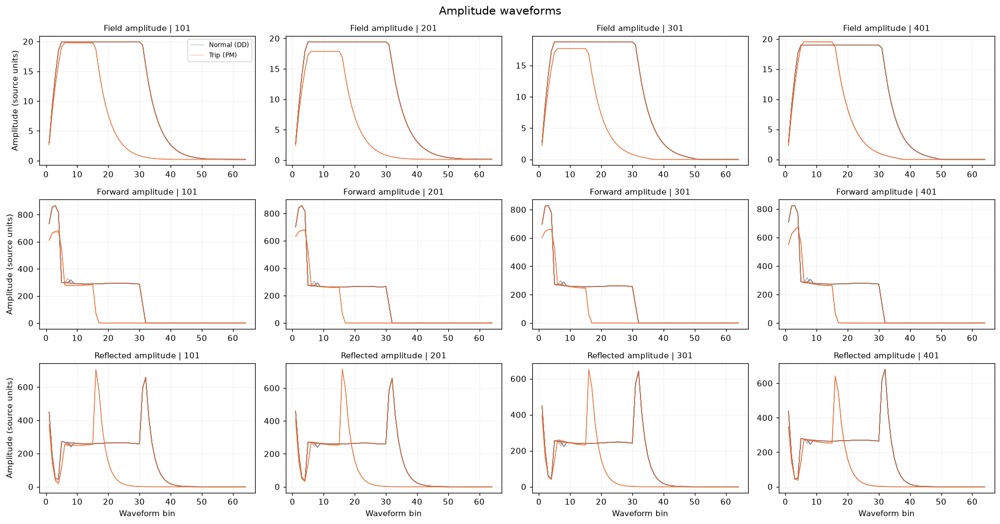

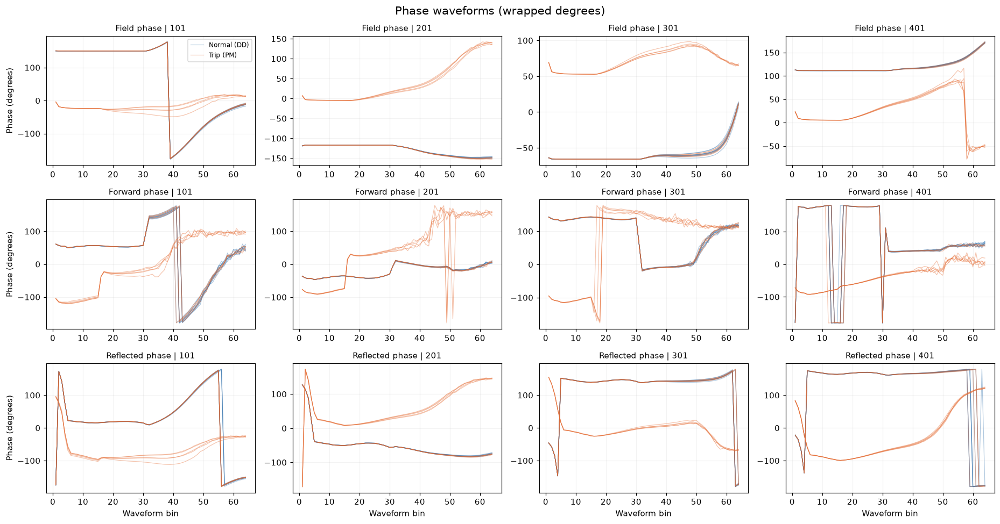

In [148]:
signal_waveform_figures = signal_tools.plot_waveforms(signal_metadata, signal_waveforms)
plt.show()


### Sensitivity on held-out capture events

All pulses and cavities from a capture stay together, so an event cannot occur
in both the training and test portions of a fold. Only pulses available in all
six channels are used. Preprocessing is fitted on the training portion only.

Two fixed baselines are compared: **ExtraTrees** for nonlinear differences and
**logistic regression** for a linear baseline. Class weights handle the original
normal/trip imbalance; no 1:1 subsampling or hyperparameter search is performed.

- **ROC AUC**: Separation of the two labels across thresholds; 0.5 is the random baseline.
- **Average precision (AP)**: Precision-recall performance; the random baseline is the trip fraction, about 11.8% here.
- **Recall at FPR <= 5%**: The largest recall on each held-out fold's ROC curve at a false positive rate of at most 5%. This describes the ROC curve; it is not a validation-selected deployment threshold.

Tables report the mean and standard deviation across folds. Use AP together with
recall at the same false positive rate when judging which signal is more sensitive.


In [149]:
signal_result = signal_tools.evaluate_signals(signal_metadata, signal_waveforms, n_splits=5)
print(f"Common evaluation pulses: {len(signal_result['metadata']):,}")
print(f"Trip prevalence: {signal_result['metadata']['label'].mean():.2%}")
for signal_model_name in ["ExtraTrees", "LogisticRegression"]:
    print(signal_model_name)
    display(signal_result["summary"].loc[
        signal_result["summary"]["model"] == signal_model_name
    ].drop(columns="model").round(4).reset_index(drop=True))
signal_result["summary"].to_csv(signal_output_dir / "sensitivity_summary.csv", index=False)
signal_result["fold_metrics"].to_csv(signal_output_dir / "sensitivity_by_fold.csv", index=False)
signal_result["predictions"].to_csv(signal_output_dir / "out_of_fold_predictions.csv", index=False)
signal_result["cavity_metrics"].to_csv(signal_output_dir / "sensitivity_by_cavity.csv", index=False)


Evaluated field_amp: ExtraTrees
Evaluated field_amp: LogisticRegression
Evaluated field_phase: ExtraTrees
Evaluated field_phase: LogisticRegression
Evaluated fwd_amp: ExtraTrees
Evaluated fwd_amp: LogisticRegression
Evaluated fwd_phase: ExtraTrees
Evaluated fwd_phase: LogisticRegression
Evaluated refl_amp: ExtraTrees
Evaluated refl_amp: LogisticRegression
Evaluated refl_phase: ExtraTrees
Evaluated refl_phase: LogisticRegression
Common evaluation pulses: 1,981
Trip prevalence: 11.81%
ExtraTrees


,signal,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,recall_at_5pct_fpr_mean,recall_at_5pct_fpr_std
0,field_amp,0.8494,0.0710,0.6883,0.2305,0.5899,0.3513
1,field_phase,0.8183,0.0627,0.6607,0.1235,0.5821,0.1021
2,fwd_amp,0.8434,0.0591,0.6423,0.1858,0.4999,0.2980
3,fwd_phase,0.8098,0.0468,0.6226,0.1521,0.5569,0.1173
4,refl_amp,0.8301,0.0601,0.6207,0.1883,0.5118,0.2374
5,refl_phase,0.7804,0.0359,0.6181,0.1061,0.5306,0.1137


LogisticRegression


,signal,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,recall_at_5pct_fpr_mean,recall_at_5pct_fpr_std
0,refl_amp,0.8587,0.0571,0.6203,0.1956,0.4782,0.2311
1,fwd_amp,0.8528,0.0781,0.6182,0.2116,0.4824,0.2301
2,field_amp,0.7825,0.0790,0.6170,0.2153,0.5377,0.2234
3,refl_phase,0.7797,0.0596,0.5859,0.1589,0.4893,0.1818
4,fwd_phase,0.7596,0.0483,0.5593,0.1806,0.4771,0.1978
5,field_phase,0.7672,0.0652,0.5549,0.1923,0.4896,0.2034


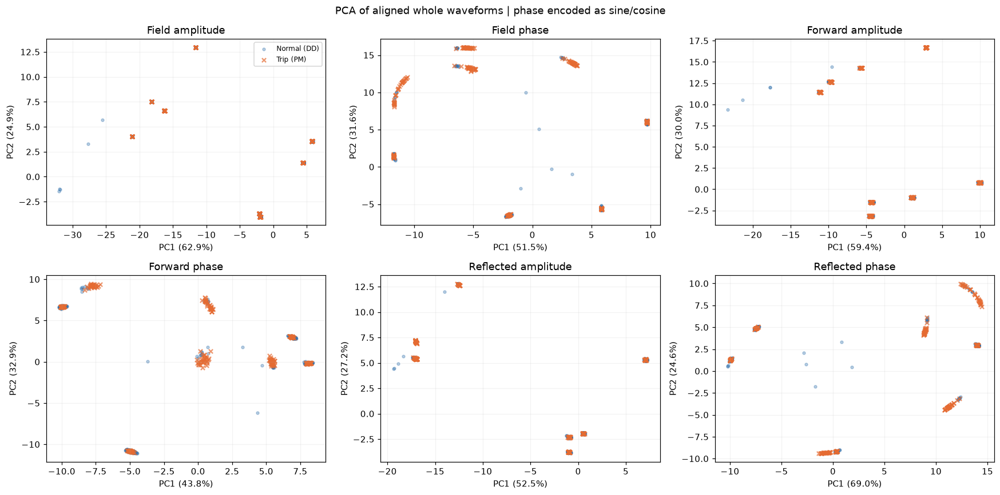

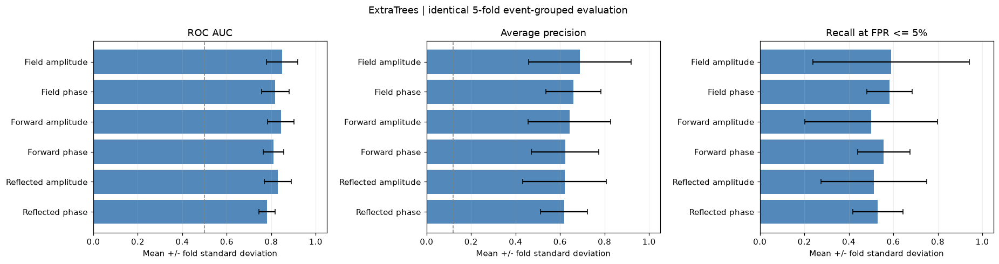

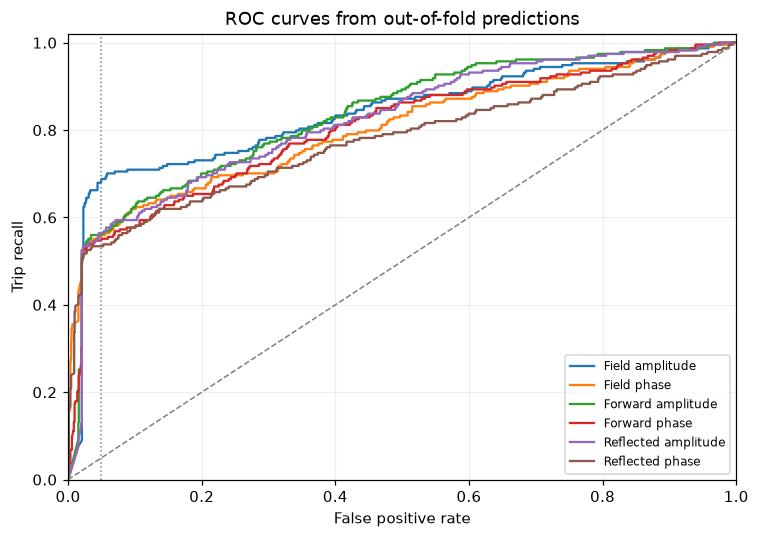

In [150]:
signal_pca_figure = signal_tools.plot_pca(
    signal_metadata, signal_waveforms, signal_result["common_mask"]
)
plt.show()
signal_performance_figures = signal_tools.plot_performance(signal_result)
plt.show()


### Compare sensitivity across cavities

The following ROC AUC values use the ExtraTrees out-of-fold predictions, separately
for each cavity. These are predictions for events absent from the corresponding
training fold. A signal's usefulness can differ between cavities.


cavity,101,201,301,401
signal,,,,
field_amp,0.8310,0.8479,0.8671,0.8158
field_phase,0.8049,0.7914,0.8023,0.8167
fwd_amp,0.8433,0.8302,0.8525,0.8145
fwd_phase,0.7843,0.8280,0.8298,0.7688
refl_amp,0.8488,0.8427,0.8250,0.7686
refl_phase,0.8023,0.7537,0.7915,0.7667


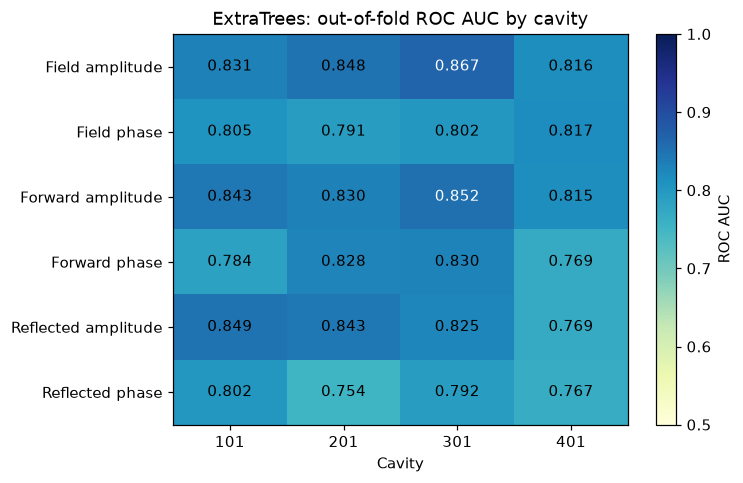

In [151]:
signal_cavity_table = signal_result["cavity_metrics"].query("model == 'ExtraTrees'").pivot(
    index="signal", columns="cavity", values="roc_auc"
).reindex(signal_tools.SIGNALS)
signal_cavity_table.columns = signal_cavity_table.columns.str[-3:]
display(signal_cavity_table.round(4))
signal_heatmap_figure, signal_heatmap_ax = plt.subplots(figsize=(7, 4.5))
signal_image = signal_heatmap_ax.imshow(signal_cavity_table.to_numpy(),
                                       vmin=0.5, vmax=1.0, cmap="YlGnBu", aspect="auto")
signal_heatmap_ax.set_xticks(np.arange(len(signal_cavity_table.columns)), signal_cavity_table.columns)
signal_heatmap_ax.set_yticks(np.arange(len(signal_cavity_table.index)),
    [signal_tools.SIGNAL_NAMES[s] for s in signal_cavity_table.index])
for signal_row in range(signal_cavity_table.shape[0]):
    for signal_col in range(signal_cavity_table.shape[1]):
        signal_value = signal_cavity_table.iloc[signal_row, signal_col]
        signal_heatmap_ax.text(signal_col, signal_row, f"{signal_value:.3f}",
                               ha="center", va="center", color="white" if signal_value > 0.85 else "black")
signal_heatmap_ax.set(xlabel="Cavity", title="ExtraTrees: out-of-fold ROC AUC by cavity")
signal_heatmap_figure.colorbar(signal_image, ax=signal_heatmap_ax, label="ROC AUC")
signal_heatmap_figure.tight_layout()
plt.show()


### Findings and interpretation

The highest mean average precision in the ExtraTrees comparison is obtained by
**Field amplitude**:
ROC AUC **0.849 +/- 0.071**,
AP **0.688 +/- 0.231**,
and recall at FPR <= 5% **59.0% +/- 35.1%**.
The full ranking and the linear baseline are shown above; a ranking can depend on the model.

This comparison identifies differences between nominal DD pulses and the final PM
pulse recorded at a beam trip. It does not measure advance warning, establish the
physical cause of a trip, or identify which cavity caused it. Acquisition conditions
can also contribute to separation. Fold variability reflects only these five
grouped splits; it is not a confidence interval or an independent final test.


### Classifier sensitivity with separate training for each beam mode

This experiment asks whether a classifier trained **only within a beam mode**
generalizes better to unseen captures from that same mode. It uses the same
six signals, four cavities, 64-bin whole waveforms, phase sine/cosine encoding,
fixed ExtraTrees/logistic-regression models, and class weighting as the benchmark
above. Each signal is trained separately; beam metadata is not an input feature.

**Paired comparison on identical test pulses:**

- Within each `beam_mode`, create event-grouped folds. Every pulse and cavity of
  a capture stays together. Use up to five folds, capped by the smaller number
  of independent normal/trip captures; require both labels in every train/test set.
- **Pooled training:** train on all modes after excluding every test capture
  globally, including any rows from that capture in another mode.
- **Per-mode training:** train only on that mode's remaining captures.
- Both models predict the exact same held-out pulses in each fold. The paired
  differences therefore compare training scope within the same evaluation cohort.
  These pooled scores are recomputed for this experiment; they are not the
  original all-mode five-fold summary above.

`Probe` supports only **two folds** because it has two normal captures. `RfTest`
and `SlowCommissioning` support five folds. `NoBeam` has no normal captures and
cannot be evaluated. Original class proportions are retained, and scores are
pulse-level, as in the original benchmark.

Compare AP **within a mode**, since trip prevalence differs greatly between
modes. Values are fold means +/- fold standard deviations, not confidence
intervals. Recall at FPR <= 5% is the largest recall on each test fold's ROC
curve under that FPR limit; it does not validate a deployment threshold.

This split controls `beam_mode` only: `beam_present`, `beam_len`, and `trig_delay`
can still differ between normal and trip captures within a mode. It does not
establish advance warning, physical causality, or sensitivity to the trip alone.


In [158]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

beam_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_signal_beam_mode.py").is_file()
)
if str(beam_notebook_dir) not in sys.path:
    sys.path.insert(0, str(beam_notebook_dir))
import cavity_signal_comparison as beam_signal_tools
beam_signal_tools = importlib.reload(beam_signal_tools)
import cavity_signal_beam_mode as beam_tools
beam_tools = importlib.reload(beam_tools)
beam_metadata, beam_waveforms = beam_tools.load_beam_datasets(
    beam_notebook_dir / "signal_comparison"
)
beam_output_dir = beam_notebook_dir / "signal_comparison" / "beam_mode_classifier"

# The saved results were computed for this section. Set True to retrain.
REBUILD_BEAM_MODE_BENCHMARK = False
beam_saved_tables = ["support", "summary", "comparison", "fold_metrics", "predictions", "partitions"]
if REBUILD_BEAM_MODE_BENCHMARK or not all(
    (beam_output_dir / f"{name}.csv").is_file() for name in beam_saved_tables
):
    beam_result = beam_tools.evaluate_by_beam_mode(beam_metadata, beam_waveforms, max_splits=5)
    beam_tools.save_results(beam_result, beam_output_dir)
    print("Recomputed paired pooled/per-mode classifiers.")
else:
    beam_result = beam_tools.load_results(beam_output_dir)
    print("Loaded paired classifier results; set REBUILD_BEAM_MODE_BENCHMARK=True to retrain.")

display(beam_result["support"].fillna("").round(4))


Loaded paired classifier results; set REBUILD_BEAM_MODE_BENCHMARK=True to retrain.


,beam_mode,normal_pulses,trip_pulses,normal_events,trip_events,trip_prevalence,n_splits,status,reason
0,NoBeam,0,4,0,1,1.0000,0,insufficient_events,Need at least two independent captures per label
1,Probe,88,144,2,36,0.6207,2,evaluated,
2,RfTest,1196,36,23,9,0.0292,5,evaluated,
3,SlowCommissioning,463,50,9,13,0.0975,5,evaluated,


The tables compare training on all modes with training on the test mode only.
**Positive Delta AP** means that per-mode training improved mean AP on the same
held-out pulses. The error values describe variation between the grouped folds;
they are particularly unstable with few captures. Signals are ordered by the
per-mode AP within each mode, separately for each classifier.


In [159]:
def beam_metric_text(row, metric, scope, percentage=False):
    factor = 100 if percentage else 1
    decimals = 1 if percentage else 3
    mean = row[f"{metric}_mean_{scope}"] * factor
    std = row[f"{metric}_std_{scope}"] * factor
    suffix = "%" if percentage else ""
    return f"{mean:.{decimals}f} +/- {std:.{decimals}f}{suffix}"

for beam_model_name in ["ExtraTrees", "LogisticRegression"]:
    beam_selected = beam_result["comparison"].query("model == @beam_model_name").sort_values(
        ["beam_mode", "average_precision_mean_per_mode"], ascending=[True, False]
    )
    beam_table = beam_selected[["beam_mode", "signal"]].copy()
    beam_table["signal"] = beam_table["signal"].map(beam_tools.SIGNAL_NAMES)
    for beam_metric, beam_title, beam_percentage in [
        ("roc_auc", "AUC", False),
        ("average_precision", "AP", False),
        ("recall_at_5pct_fpr", "Recall at FPR <= 5%", True),
    ]:
        for beam_scope, beam_scope_title in [("pooled", "pooled"), ("per_mode", "per-mode")]:
            beam_table[f"{beam_title}: {beam_scope_title}"] = beam_selected.apply(
                lambda r: beam_metric_text(r, beam_metric, beam_scope, beam_percentage), axis=1
            )
    beam_table["Delta AP"] = beam_selected["average_precision_delta"].round(3)
    print(beam_model_name)
    display(beam_table.reset_index(drop=True))


ExtraTrees


,beam_mode,signal,AUC: pooled,AUC: per-mode,AP: pooled,AP: per-mode,Recall at FPR <= 5%: pooled,Recall at FPR <= 5%: per-mode,Delta AP
0,Probe,Reflected phase,0.806 +/- 0.109,0.418 +/- 0.157,0.913 +/- 0.038,0.582 +/- 0.143,65.3 +/- 17.7%,0.0 +/- 0.0%,-0.331
1,Probe,Field phase,0.770 +/- 0.097,0.345 +/- 0.214,0.895 +/- 0.029,0.551 +/- 0.170,61.1 +/- 13.7%,0.0 +/- 0.0%,-0.344
2,Probe,Forward phase,0.797 +/- 0.171,0.309 +/- 0.230,0.902 +/- 0.079,0.536 +/- 0.169,59.7 +/- 33.4%,0.0 +/- 0.0%,-0.365
3,Probe,Reflected amplitude,0.727 +/- 0.234,0.259 +/- 0.230,0.830 +/- 0.162,0.512 +/- 0.168,41.0 +/- 57.9%,0.0 +/- 0.0%,-0.318
4,Probe,Forward amplitude,0.721 +/- 0.277,0.253 +/- 0.231,0.822 +/- 0.187,0.510 +/- 0.168,41.0 +/- 57.9%,0.0 +/- 0.0%,-0.312
5,Probe,Field amplitude,0.669 +/- 0.374,0.250 +/- 0.236,0.797 +/- 0.242,0.509 +/- 0.169,45.1 +/- 63.8%,0.0 +/- 0.0%,-0.287
6,RfTest,Field amplitude,0.863 +/- 0.180,0.853 +/- 0.198,0.697 +/- 0.349,0.679 +/- 0.387,65.8 +/- 36.8%,68.3 +/- 35.9%,-0.018
7,RfTest,Reflected amplitude,0.765 +/- 0.144,0.736 +/- 0.125,0.239 +/- 0.152,0.138 +/- 0.132,30.8 +/- 23.1%,20.0 +/- 22.7%,-0.100
8,RfTest,Forward amplitude,0.770 +/- 0.146,0.759 +/- 0.109,0.224 +/- 0.192,0.126 +/- 0.078,30.8 +/- 30.8%,31.7 +/- 30.8%,-0.098
9,RfTest,Reflected phase,0.505 +/- 0.123,0.539 +/- 0.046,0.069 +/- 0.048,0.080 +/- 0.058,10.8 +/- 10.9%,9.2 +/- 10.4%,0.011


LogisticRegression


,beam_mode,signal,AUC: pooled,AUC: per-mode,AP: pooled,AP: per-mode,Recall at FPR <= 5%: pooled,Recall at FPR <= 5%: per-mode,Delta AP
0,Probe,Reflected phase,0.702 +/- 0.350,0.325 +/- 0.217,0.839 +/- 0.188,0.565 +/- 0.216,54.2 +/- 49.1%,9.7 +/- 13.7%,-0.274
1,Probe,Field amplitude,0.685 +/- 0.318,0.253 +/- 0.238,0.834 +/- 0.166,0.559 +/- 0.188,51.4 +/- 45.2%,10.4 +/- 8.8%,-0.276
2,Probe,Field phase,0.663 +/- 0.369,0.287 +/- 0.282,0.805 +/- 0.217,0.544 +/- 0.213,45.8 +/- 53.0%,5.6 +/- 7.9%,-0.261
3,Probe,Forward phase,0.648 +/- 0.370,0.210 +/- 0.197,0.794 +/- 0.225,0.498 +/- 0.154,43.1 +/- 57.0%,0.0 +/- 0.0%,-0.296
4,Probe,Forward amplitude,0.602 +/- 0.439,0.179 +/- 0.161,0.779 +/- 0.248,0.490 +/- 0.148,44.4 +/- 55.0%,2.1 +/- 2.9%,-0.289
5,Probe,Reflected amplitude,0.604 +/- 0.405,0.206 +/- 0.187,0.777 +/- 0.238,0.481 +/- 0.129,44.4 +/- 55.0%,0.0 +/- 0.0%,-0.296
6,RfTest,Forward amplitude,0.777 +/- 0.209,0.790 +/- 0.200,0.555 +/- 0.440,0.563 +/- 0.430,59.2 +/- 39.6%,61.7 +/- 36.1%,0.008
7,RfTest,Reflected amplitude,0.748 +/- 0.236,0.813 +/- 0.186,0.537 +/- 0.459,0.557 +/- 0.441,57.5 +/- 41.1%,60.0 +/- 41.8%,0.020
8,RfTest,Field amplitude,0.682 +/- 0.133,0.748 +/- 0.215,0.330 +/- 0.235,0.341 +/- 0.298,43.3 +/- 22.6%,41.7 +/- 37.3%,0.012
9,RfTest,Reflected phase,0.559 +/- 0.079,0.548 +/- 0.071,0.064 +/- 0.052,0.047 +/- 0.035,8.3 +/- 11.8%,4.2 +/- 5.9%,-0.017


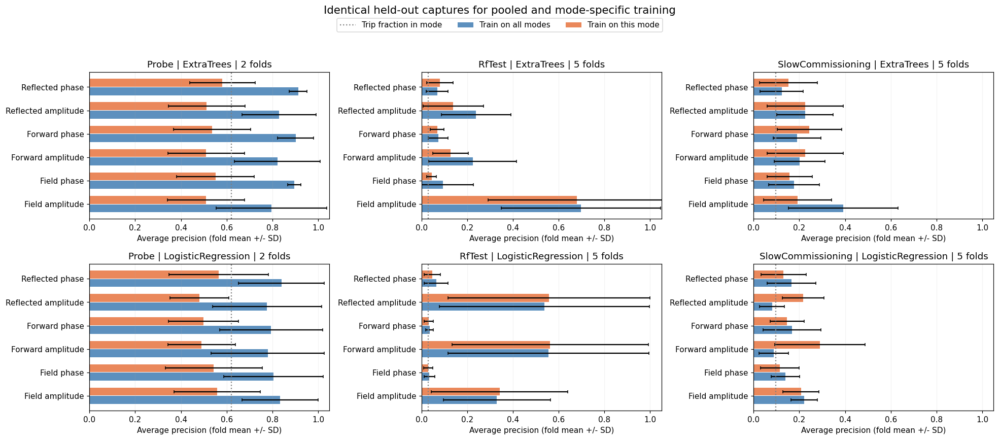

In [160]:
beam_comparison_figure = beam_tools.plot_comparison(beam_result)
beam_comparison_figure.savefig(beam_output_dir / "average_precision_comparison.png", dpi=160)
plt.show()


### Findings from training separately by beam mode

- **Separate training does not improve every mode or signal.** The relative
  ranking also depends on the classifier, so the original pooled ranking should
  not be interpreted as a universal physical signal-sensitivity ranking.
- **RfTest:** ExtraTrees with **Field amplitude** remains the strongest per-mode
  AP result: AUC **0.853 +/- 0.198**, AP **0.679 +/- 0.387**, and recall at
  FPR <= 5% **68.3% +/- 35.9%**. On the same test folds, pooled-training AP is
  **0.697**, so mode-specific training provides no AP improvement here.
  Other per-mode ExtraTrees signals have AP between **0.044 and 0.138**.
  With logistic regression the highest per-mode AP is **Forward amplitude
  (0.563)**, close to **Reflected amplitude (0.557)**.
- **SlowCommissioning:** ExtraTrees' highest per-mode AP is **Forward phase**:
  AP **0.244 +/- 0.142** versus pooled **0.190**, AUC **0.638 +/- 0.154**,
  recall **19.7% +/- 16.8%**. Logistic regression benefits most clearly for
  **Forward amplitude**: AP **0.087 -> 0.290** and AUC **0.245 -> 0.537**;
  this improvement still leaves modest discrimination and substantial fold
  variation. Field amplitude's ExtraTrees AP falls **0.392 -> 0.193**.
- **Probe:** normal data comes from only **two captures**; each fold trains on
  one and tests on the other. Per-mode ExtraTrees AUC is **0.250 to 0.418**
  across signals, and recall at FPR <= 5% is **0%** for all six. Per-mode AP
  (**0.509 to 0.582**) is below the mode's overall **62.1%** trip fraction.
  These results do not support reliable generalization from the
  available normal captures; more independent normal captures are needed.
- **NoBeam:** only four trip pulses from one event and no normal pulses;
  supervised normal/trip classification cannot be evaluated.

The trip fractions are **62.1% (Probe)**, **2.9% (RfTest)**, and
**9.7% (SlowCommissioning)**. AP values across these modes have different random
baselines. The results show the benefit or cost of restricting the training
data by mode on these particular grouped splits, with remaining acquisition
differences and small event counts still limiting interpretation.

The reproducible implementation is `cavity_signal_beam_mode.py`. Support counts,
fold metrics, out-of-fold predictions, and paired comparisons are saved under
`signal_comparison/beam_mode_classifier/`.


## Direct waveform changes within matched beam conditions

This section directly compares **normal and trip waveform changes**, using the
six aligned signals. It does not train classifiers or use classifier predictions.

The source tables have no column named `beamtype`. Their beam-mode field is
**`beam_mode`**, with values `Probe`, `RfTest`, `SlowCommissioning`, and `NoBeam`.
Their normal/trip proportions differ substantially. Therefore comparisons are
made **within the same cavity, beam_mode, beam_len, trig_delay, and beam_present**.
Acquisition date is not used as a substitute for beam type.

`label=0` still means a DD pulse; `label=1` means the final PM pulse. Conditions
without both labels are listed as unmatched and excluded from numerical changes.
These are group comparisons, not paired before/after measurements of one trip.
Beam-current values are retained for inspection but are not an additional matching key.


In [152]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

change_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_signal_change.py").is_file()
)
if str(change_notebook_dir) not in sys.path:
    sys.path.insert(0, str(change_notebook_dir))
import cavity_signal_change as change_tools
change_tools = importlib.reload(change_tools)
change_output_dir = change_notebook_dir / "signal_comparison"
change_metadata = pd.read_csv(change_output_dir / "direct_change_pulse_metadata.csv")
with np.load(change_output_dir / "waveforms.npz", allow_pickle=False) as change_bundle:
    change_waveforms = {name: change_bundle[name] for name in change_tools.SIGNALS}

# To refresh beam metadata from the source feature Parquets (requires pyarrow):
# change_metadata = change_tools.attach_beam_metadata(
#     pd.read_csv(change_output_dir / "pulse_metadata.csv"), change_notebook_dir
# )
# change_metadata.to_csv(change_output_dir / "direct_change_pulse_metadata.csv", index=False)

print("Beam-mode counts before matching:")
display(pd.crosstab(change_metadata["beam_mode"], change_metadata["label"]).rename(
    columns={0: "Normal DD pulses", 1: "Trip PM pulses"}
))
change_condition_counts = change_metadata.groupby(
    change_tools.CONDITION_COLUMNS + ["source"], dropna=False
).agg(pulses=("label", "size"), captures=("event_id", "nunique"))
display(change_condition_counts)


Beam-mode counts before matching:


label,Normal DD pulses,Trip PM pulses
beam_mode,,
NoBeam,0,4
Probe,88,144
RfTest,1196,36
SlowCommissioning,463,50


pulses  captures
beam_mode         beam_len trig_delay beam_present source                  
NoBeam            5.0      200.005676 False        PM           4         1
Probe             0.0      250.000153 False        PM           8         2
                  5.0      200.005676 False        PM          12         3
                                      True         DD          36         1
                                                   PM         108        27
                           250.000153 True         DD          52         1
                                                   PM          16         4
RfTest            0.0      250.000153 False        DD         208         4
                  50.0     250.000153 True         DD         988        19
                                                   PM          36         9
SlowCommissioning 0.0      250.000153 False        DD         248         5
                                                   PM          11         3
                  5.0      250.000153 True         DD         215         5
                                                   PM          39        10

### Measure changes relative to normal waveform variability

For each matched beam-condition/cavity group and each signal:

1. At each of the 64 bins, calculate the normal 2.5th and 97.5th percentile
   order statistics, enclosing at least 95% of the observed normal values.
2. Mark bins of each normal/trip pulse that fall outside this **normal envelope**.
3. Calculate the fraction of marked bins in that pulse. Average pulses within
   each capture, then give captures equal weight within each label.
4. Subtract the normal fraction from the trip fraction. The result is the
   **extra changed-bin fraction**, reported in percentage points (pp).

Example: 25% of trip bins outside the reference versus 5% of normal bins gives
**+20 pp**. This measures changes across a waveform; it is **not trip recall**.
A negative result means fewer bins are outside the reference in the trip group.
The envelope is estimated from normal pulses; capture-weighted normal summaries
can differ from 5% when captures contribute different numbers of pulses.

Both the full 64-bin record and a common **normal RF-on reference window** are
evaluated. The RF-on window is derived from normal median amplitudes: field
above 50% of its range, forward and reflected above 10% of their respective
ranges, measured from each normal minimum. All six signals use the same window
within a condition/cavity group. Original waveform duration is retained.

Phase is measured relative to the binwise normal circular mean and wrapped to
[-180, 180] degrees before calculating envelopes. Interpret phase changes
alongside amplitude, especially when the trip pulse's RF amplitude is near zero.

A reference with fewer than five independent normal captures is flagged as
limited. Capture-bootstrap intervals are supplied only with at least five normal
and three trip captures; they condition on the observed envelope and do not
include uncertainty in its estimation. No classifier is fitted.


In [153]:
change_result = change_tools.analyze_changes(change_metadata, change_waveforms)
print(f"All pulses: {len(change_metadata):,}")
print(f"Pulses with matched beam conditions and cavity: {change_result['matched_pulses']:,}")
print(f"Unmatched pulses: {change_result['unmatched_pulses']:,}")
display(change_result["support"][[
    *change_tools.CONDITION_COLUMNS, "cavity", "normal_pulses", "trip_pulses",
    "normal_events", "trip_events", "matched", "limited_normal_reference"
]])
for change_key, change_filename in {
    "summary": "direct_change_by_condition.csv",
    "profiles": "direct_change_by_bin.csv",
    "pulse_scores": "direct_change_per_pulse.csv",
    "support": "direct_change_support.csv",
    "beam_summary": "direct_change_by_beam_mode.csv",
}.items():
    change_result[change_key].to_csv(change_output_dir / change_filename, index=False)


All pulses: 1,981
Pulses with matched beam conditions and cavity: 1,749
Unmatched pulses: 232


,beam_mode,beam_len,trig_delay,beam_present,cavity,normal_pulses,trip_pulses,normal_events,trip_events,matched,limited_normal_reference
0,NoBeam,5.0,200.005676,False,HBL-010RFC:RFS-DIG-101,0,1,0,1,False,True
1,NoBeam,5.0,200.005676,False,HBL-010RFC:RFS-DIG-201,0,1,0,1,False,True
2,NoBeam,5.0,200.005676,False,HBL-010RFC:RFS-DIG-301,0,1,0,1,False,True
3,NoBeam,5.0,200.005676,False,HBL-010RFC:RFS-DIG-401,0,1,0,1,False,True
4,Probe,0.0,250.000153,False,HBL-010RFC:RFS-DIG-101,0,2,0,2,False,True
5,Probe,0.0,250.000153,False,HBL-010RFC:RFS-DIG-201,0,2,0,2,False,True
6,Probe,0.0,250.000153,False,HBL-010RFC:RFS-DIG-301,0,2,0,2,False,True
7,Probe,0.0,250.000153,False,HBL-010RFC:RFS-DIG-401,0,2,0,2,False,True
8,Probe,5.0,200.005676,False,HBL-010RFC:RFS-DIG-101,0,3,0,3,False,True
9,Probe,5.0,200.005676,False,HBL-010RFC:RFS-DIG-201,0,3,0,3,False,True


### Normal envelope, trip envelope, and median waveforms

Each figure holds beam conditions fixed. Columns are the four cavities; rows
are the three amplitude or three phase channels. Blue shading is the normal
envelope, blue/orange lines are normal/trip medians, and orange dotted lines
show the trip envelope. The gray background marks the normal RF-on reference.

There can be changed trip pulses even when the two medians overlap; the
per-bin change profiles below retain this information. Phase plots use degrees
relative to the normal circular mean, not the original absolute phase offset.


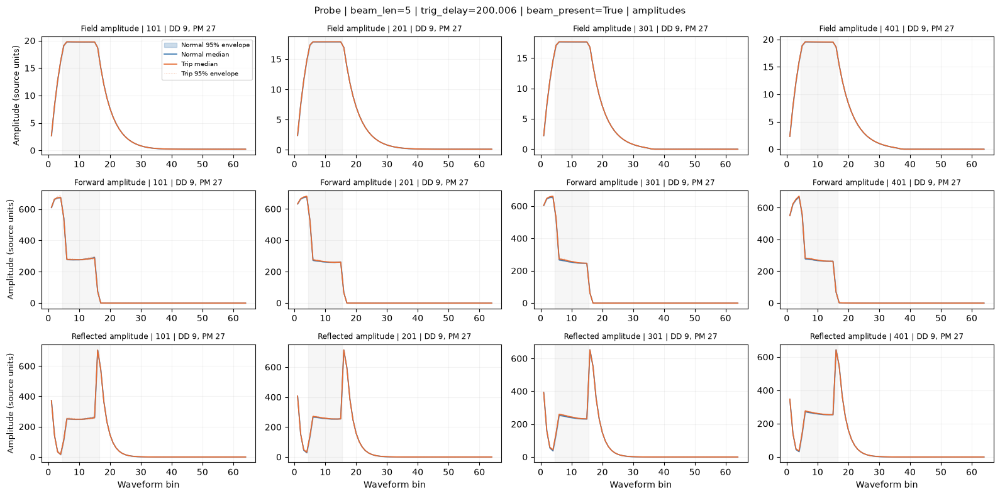

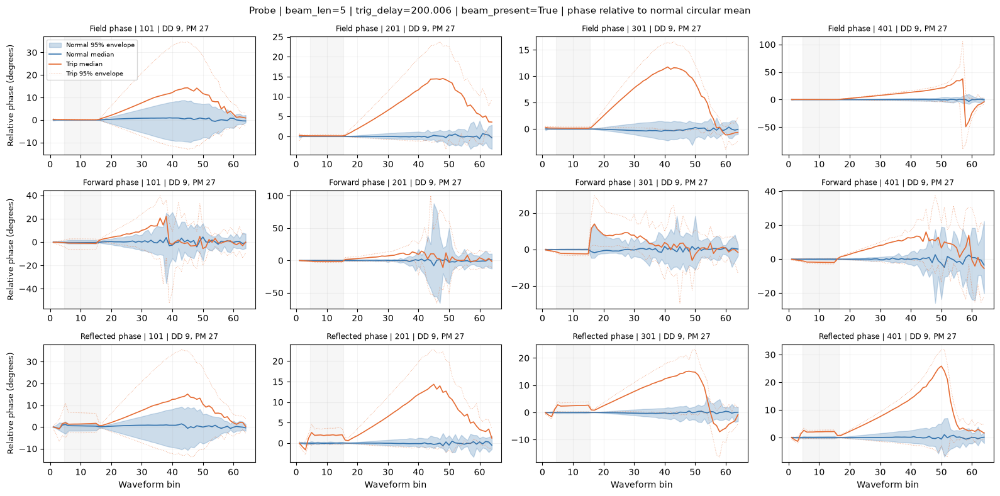

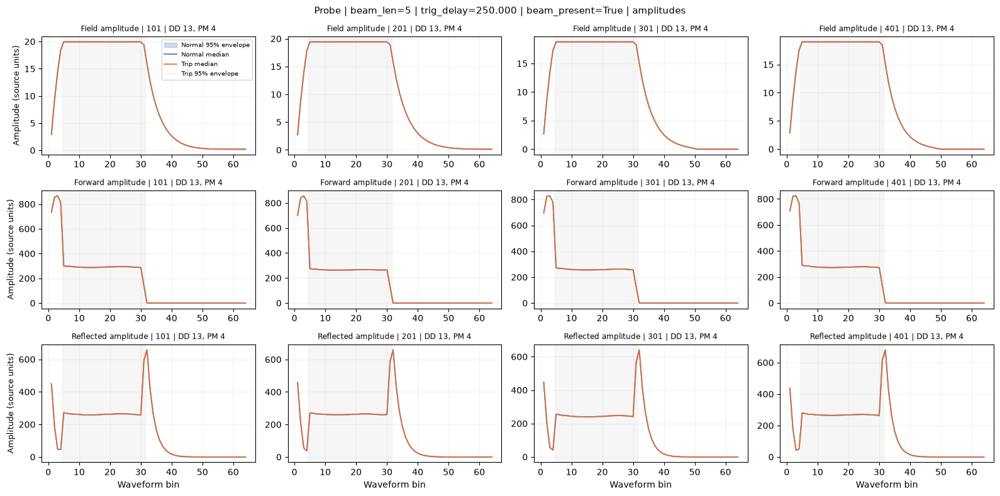

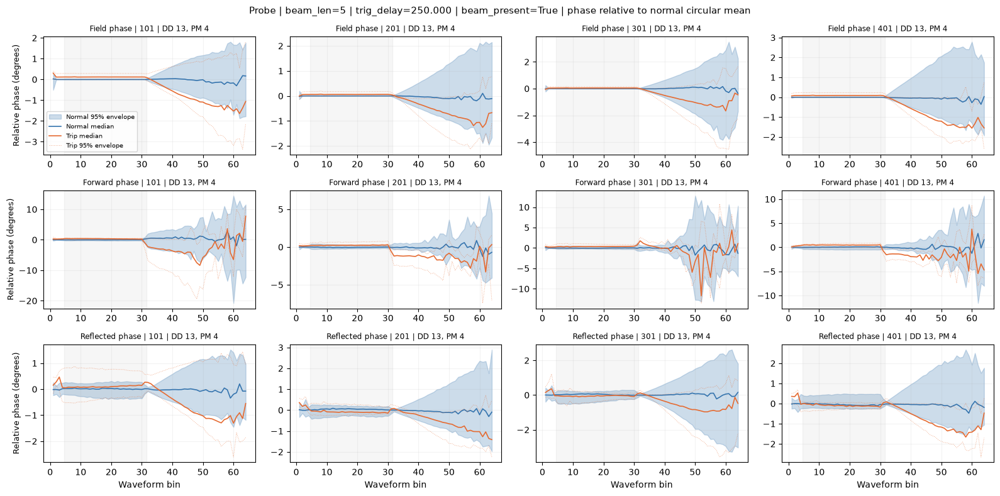

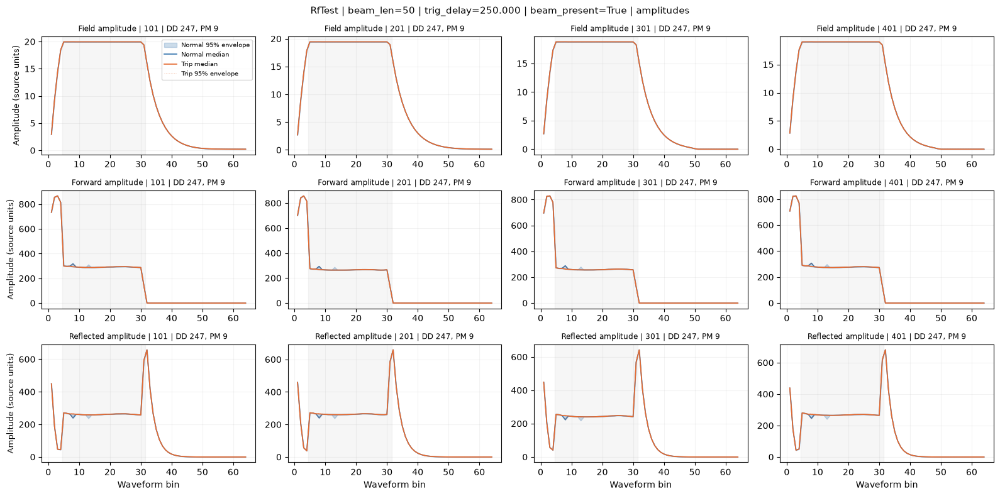

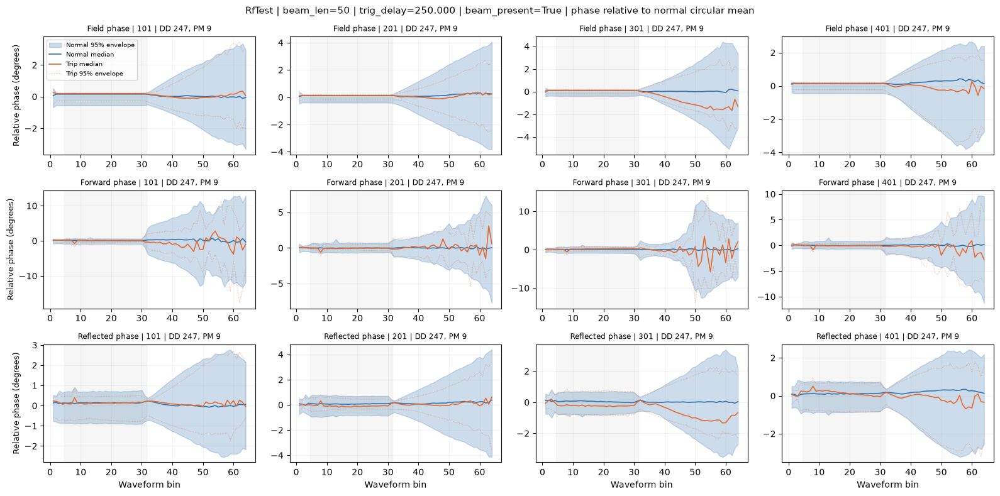

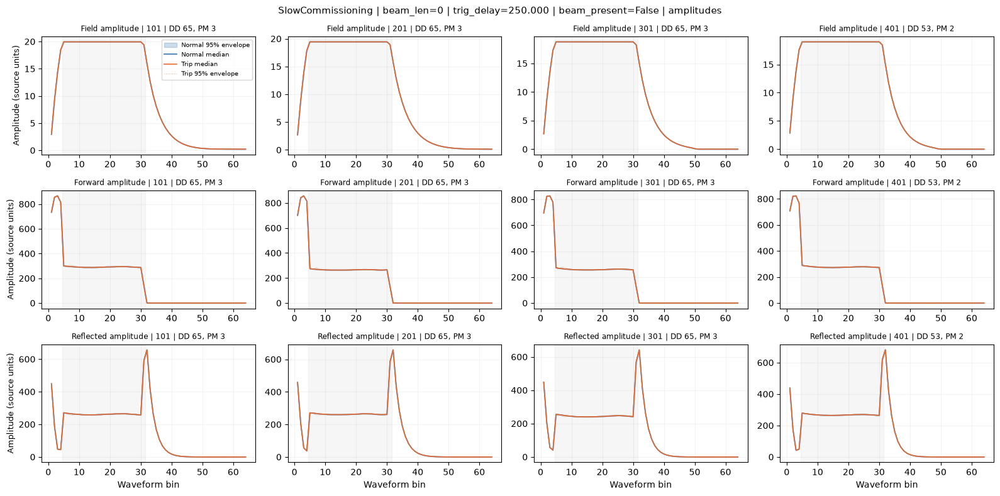

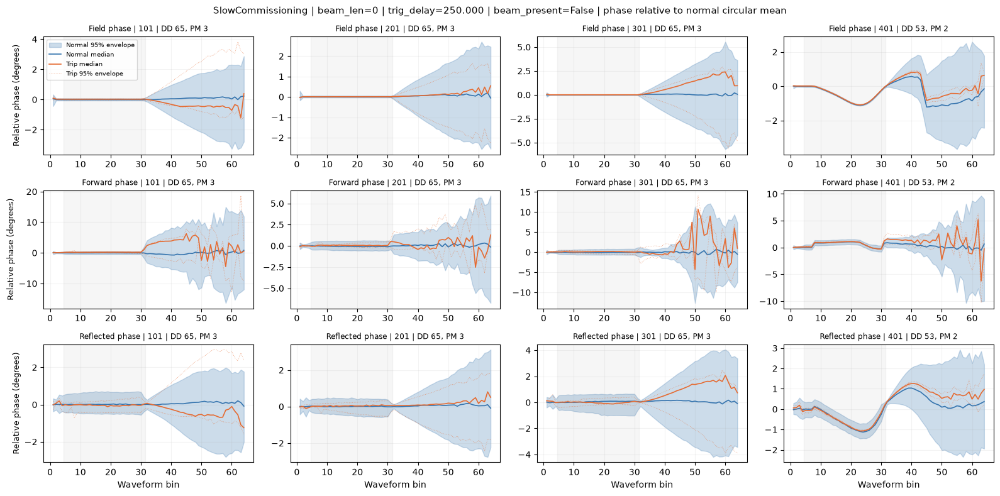

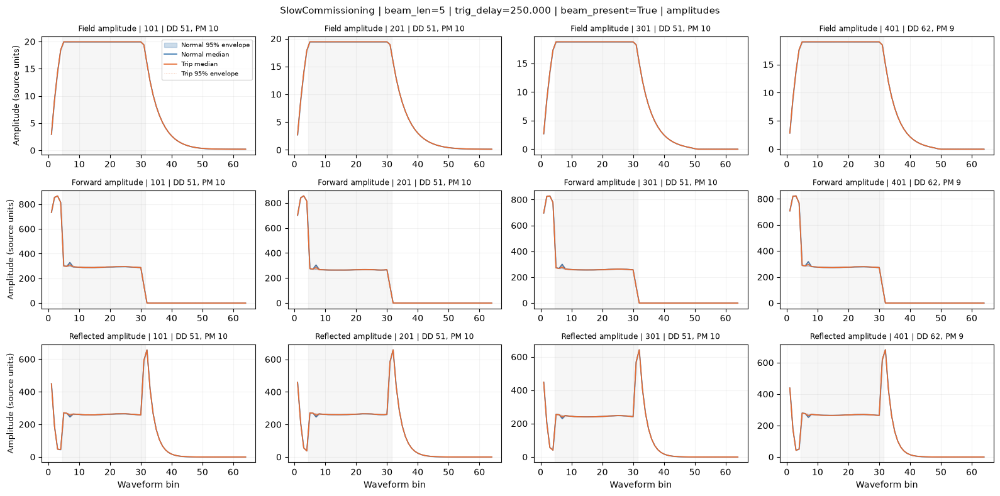

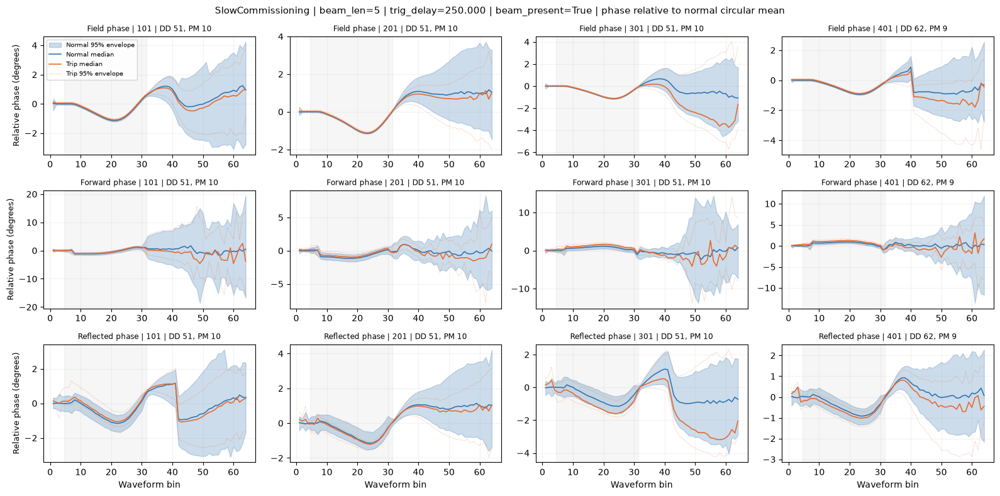

In [154]:
for change_figure in change_tools.plot_profiles(change_result):
    plt.show()


### Zoom into waveform deviations in source units

The full-scale waveforms can overlap even when their differences exceed normal
variation. This view subtracts the matched binwise normal median and zooms into
the normal RF-on window. Blue shading is normal variation; orange shows the trip
median and trip envelope in amplitude units or degrees. RfTest is shown here
because its normal reference contains 19 independent captures.
Change `beam_mode` below to inspect another mode.


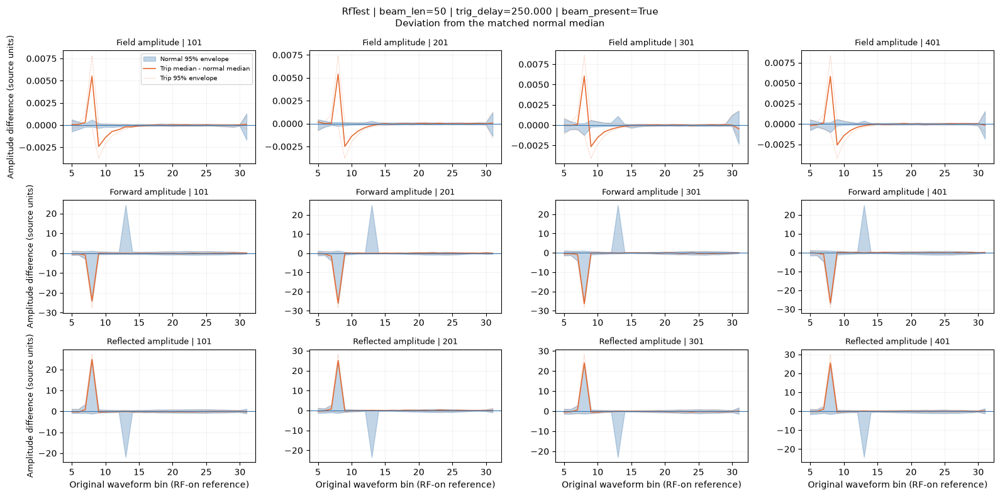

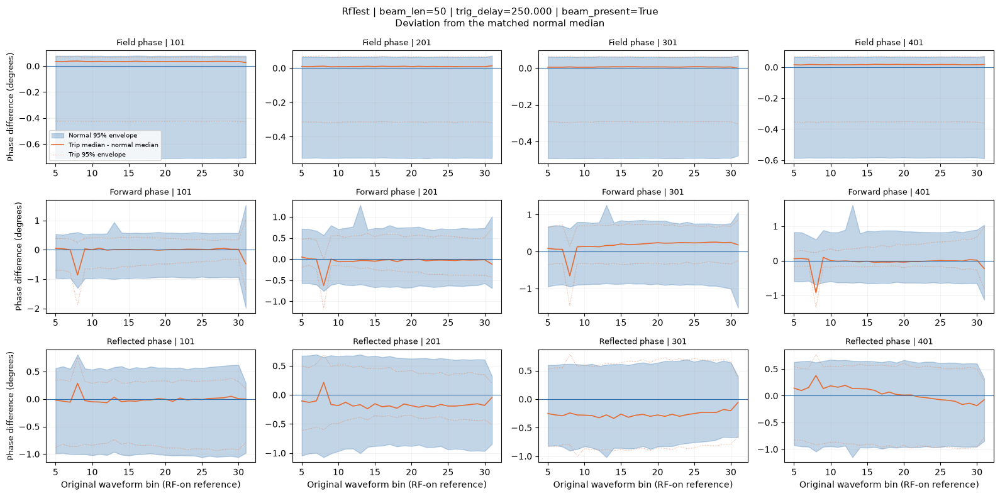

In [157]:
for change_figure in change_tools.plot_deviation_profiles(
    change_result, beam_mode="RfTest", beam_present=True
):
    plt.show()


### Where in the waveform do trip-associated changes appear?

Each curve shows the trip fraction outside the normal envelope minus the normal
fraction at that same bin, in percentage points. A positive peak identifies bins
where trip pulses more frequently differ from the matched normal distribution.


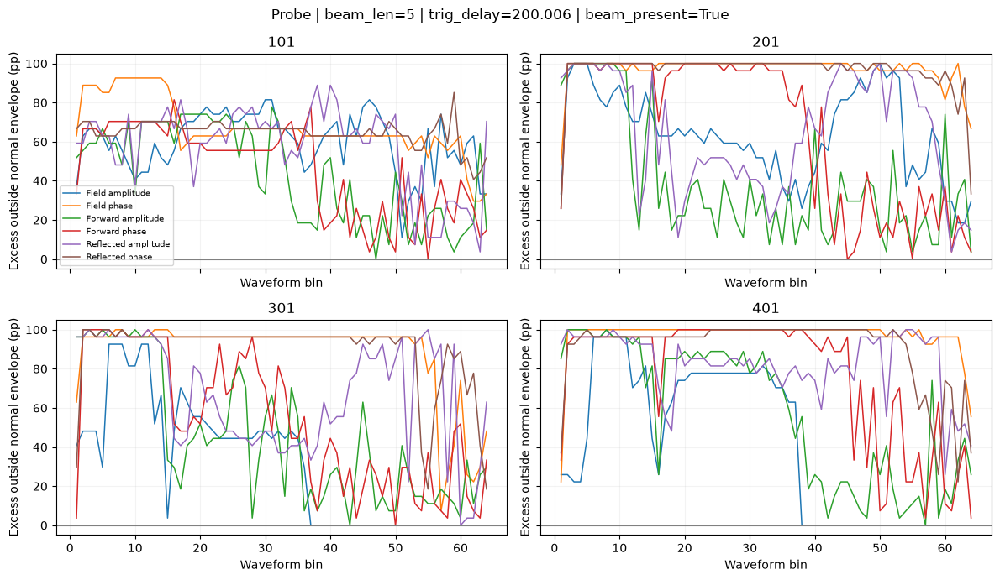

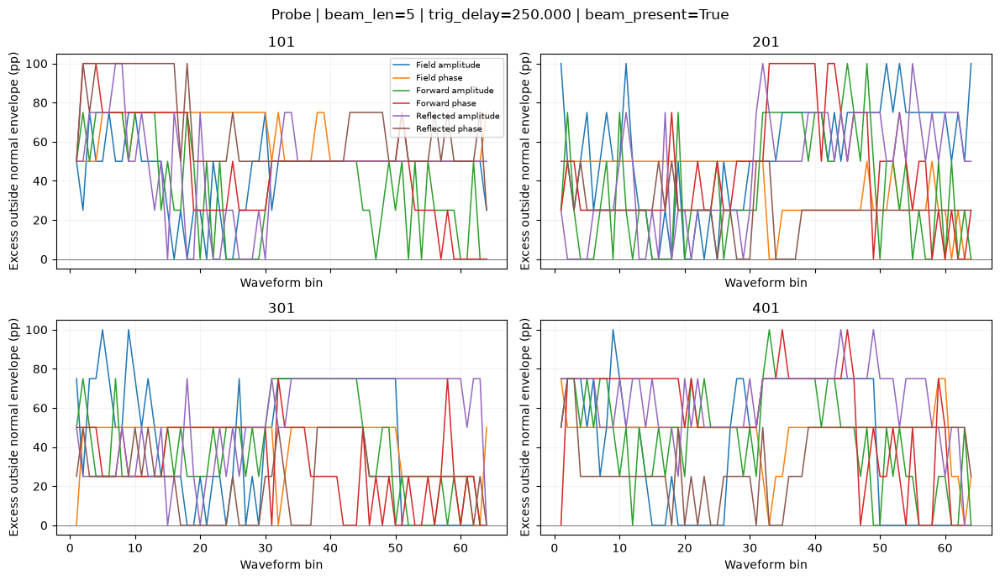

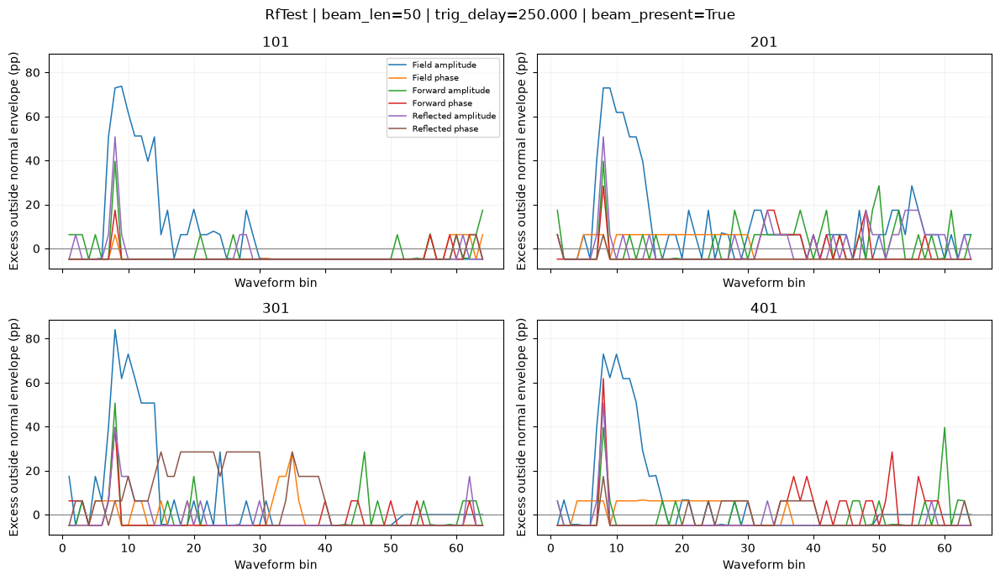

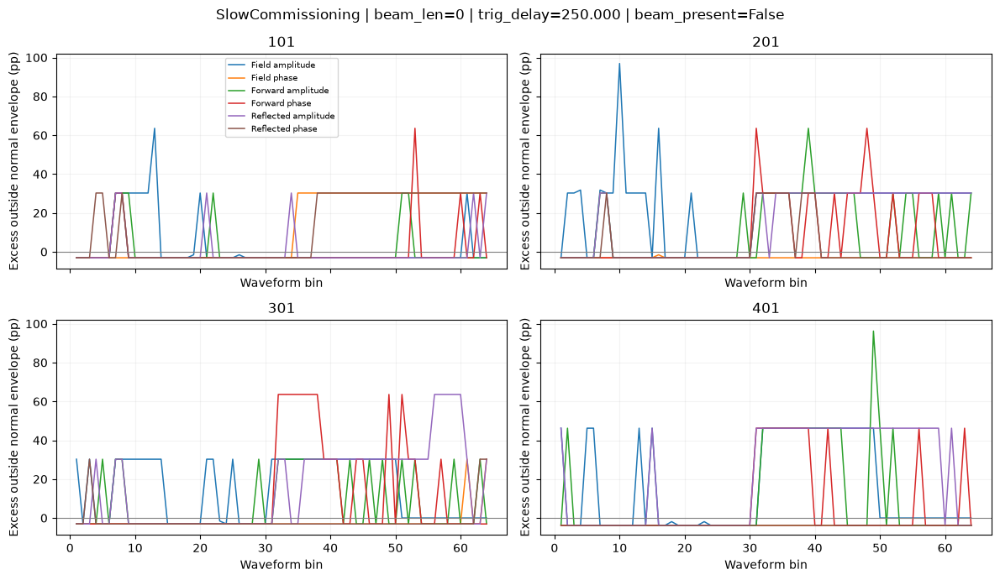

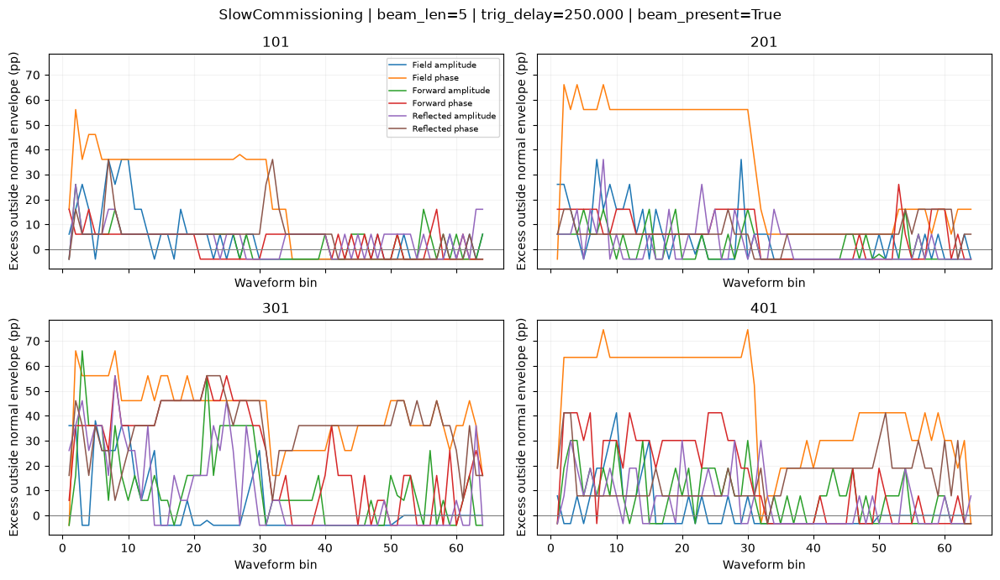

In [155]:
for change_figure in change_tools.plot_change_profiles(change_result):
    plt.show()


### Compare signal changes separately for each beam mode

The table and heatmaps summarize the **RF-on reference window**. Comparisons
remain separate for beam-present and beam-absent conditions. When a beam mode
has several matched condition/cavity cells, their results receive equal weight.
This is a descriptive summary, not a universal ranking of physical sensor sensitivity.
**Probe has only one normal capture per matched acquisition condition**;
its results cannot establish normal variation between captures.


,beam_mode,beam_present,signal,normal_changed_fraction,trip_changed_fraction,excess_changed_fraction,minimum_normal_events,minimum_trip_events,matched_cavity_condition_cells
0,Probe,True,field_phase,0.00,76.16,76.16,1,4,8
1,Probe,True,fwd_phase,0.00,68.72,68.72,1,4,8
2,Probe,True,refl_phase,0.00,62.09,62.09,1,4,8
3,Probe,True,refl_amp,0.00,61.44,61.44,1,4,8
4,Probe,True,fwd_amp,0.00,58.33,58.33,1,4,8
5,Probe,True,field_amp,0.00,52.71,52.71,1,4,8
6,RfTest,True,field_amp,4.74,23.46,18.72,19,9,4
7,RfTest,True,refl_phase,4.86,6.79,1.93,19,9,4
8,RfTest,True,field_phase,4.85,6.07,1.22,19,9,4
9,RfTest,True,refl_amp,4.85,4.12,-0.74,19,9,4


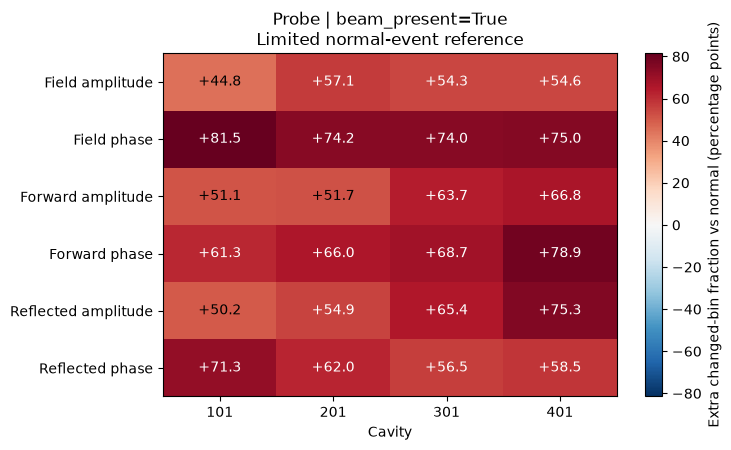

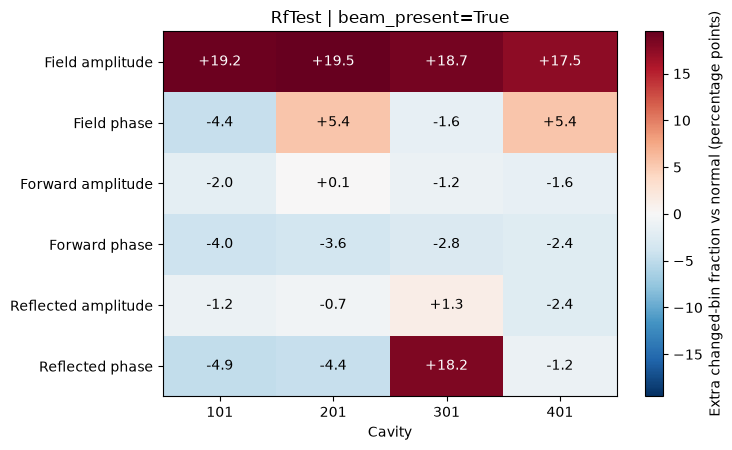

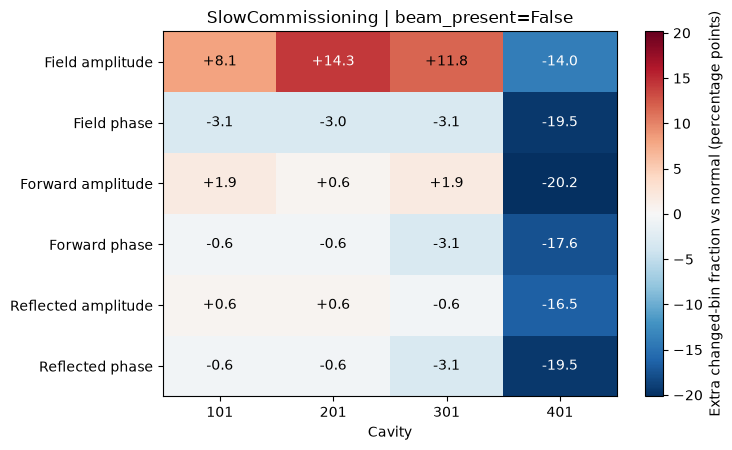

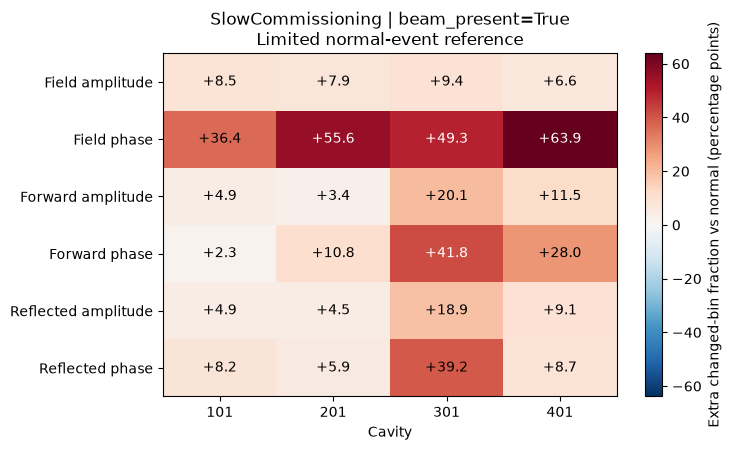

In [156]:
change_table = change_result["beam_summary"].query("window == 'rf_on_reference'").copy()
for change_column in ["normal_changed_fraction", "trip_changed_fraction", "excess_changed_fraction"]:
    change_table[change_column] *= 100
change_table = change_table.sort_values(
    ["beam_mode", "beam_present", "excess_changed_fraction"], ascending=[True, True, False]
)
display(change_table.drop(columns="window").round(2).reset_index(drop=True))
for change_figure in change_tools.plot_change_heatmaps(change_result):
    plt.show()


### Findings after matching beam conditions

- **Probe, beam_present=True**: Field phase has the largest mean excess in this summary (**+76.2 pp**). The normal reference has only one capture per acquisition condition.
- **RfTest, beam_present=True**: Field amplitude has the largest mean excess in this summary (**+18.7 pp**).
- **SlowCommissioning, beam_present=False**: Field amplitude has the largest mean excess in this summary (**+5.0 pp**).
- **SlowCommissioning, beam_present=True**: Field phase has the largest mean excess in this summary (**+51.3 pp**). The smallest matched normal reference contains four captures.

Signals should be interpreted within beam mode and cavity rather than by a pooled normal/trip difference.
NoBeam and other unmatched conditions have no valid two-label comparison. Beam current, beam state,
acquisition period, and RF-off phase behavior can still contribute to observed differences; this
descriptive comparison does not establish that a trip caused a signal change.


## ROC-AUC from waveform deviation scores (no classifier)

ROC-AUC needs **binary reference labels and one scalar score per observation**.
The score need not be a classifier probability. Here a fixed waveform statistic
is passed directly to `roc_auc_score(y_true, scores)`: no ExtraTrees, logistic
regression, or other classifier is fitted. See the
[scikit-learn ROC-AUC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).

**Primary waveform score:** the fraction of RF-on bins outside the normal
2.5th/97.5th percentile envelope:

\[
s(x)=\frac{1}{|W|}\sum_{j\in W}\mathbf{1}\{x_j<L_j\ \mathrm{or}\ x_j>U_j\}.
\]

Larger scores always mean more deviation from normal. The 95% envelope defines
the score; ROC thresholds then sweep the resulting fraction from low to high.
The score has discrete steps and ties, which ROC-AUC handles. Its magnitude is
not a calibrated probability of a trip. The AUC measures this chosen statistic's
ability to rank trip above normal, rather than an intrinsic sensitivity of the
raw signal independent of how it is summarized.

**Evaluation without using test captures in the reference:**

1. Match `beam_mode`, `beam_len`, `trig_delay`, and `beam_present`, then construct
   event-grouped folds shared by all four cavities and all six signals within
   that condition. Require both labels in every test cavity/fold.
2. Within each fold and cavity, use **only reference normal captures** to
   estimate the phase circular center, envelope, median, and RF-on window.
   No test pulse, including a normal test pulse, enters these estimates.
3. Score the held-out normal and trip pulses. The primary score uses the entire
   RF-on window selected from reference normal amplitudes, with the same field
   50% / forward 10% / reflected 10% range rules as the direct comparison.
   **Bins 7-14 are not selected for this waveform score.**
4. Compute ROC-AUC separately for each cavity and fold. Each test capture gets
   equal total weight within a cavity, so long normal captures do not dominate.
   Report the mean across folds per cavity, then an equal mean across matched
   condition/cavity cells. Scores with different normal references are not
   pooled into one ROC-AUC calculation.

The split count is reduced when independent captures are scarce. `Probe` has
only one normal capture per matched acquisition condition and is excluded;
`NoBeam` and other single-label conditions are also excluded. Standard deviations
across folds and the cavity range are descriptive, not confidence intervals.

**Separate exploratory bin map:** for every bin, use the absolute distance from
its reference normal median as the score (shortest circular distance for phase).
Its AUC shows where deviations distinguish the labels. This is a different score
from the primary waveform fraction. All bins are calculated; high-AUC bins
identified on these data need independent captures for confirmation. AUC values
below 0.5 are retained without reversing the score after examining the labels.


In [161]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

score_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_waveform_score_auc.py").is_file()
)
if str(score_notebook_dir) not in sys.path:
    sys.path.insert(0, str(score_notebook_dir))
import cavity_signal_comparison as score_signal_tools
score_signal_tools = importlib.reload(score_signal_tools)
import cavity_signal_change as score_change_tools
score_change_tools = importlib.reload(score_change_tools)
import cavity_signal_beam_mode as score_beam_tools
score_beam_tools = importlib.reload(score_beam_tools)
import cavity_waveform_score_auc as score_tools
score_tools = importlib.reload(score_tools)

score_output_dir = score_notebook_dir / "signal_comparison" / "waveform_score_auc"
# Normal-reference estimation only; this switch never trains a classifier.
REBUILD_WAVEFORM_SCORE_AUC = False
if REBUILD_WAVEFORM_SCORE_AUC or not all(
    (score_output_dir / f"{name}.csv").is_file() for name in score_tools.TABLES
):
    score_metadata, score_waveforms = score_tools.load_beam_datasets(
        score_notebook_dir / "signal_comparison"
    )
    score_result = score_tools.evaluate_score_auc(score_metadata, score_waveforms)
    score_tools.save_results(score_result, score_output_dir)
    print("Computed held-out waveform scores and ROC-AUC without a classifier.")
else:
    score_result = score_tools.load_results(score_output_dir)
    print("Loaded classifier-free ROC-AUC results; set REBUILD_WAVEFORM_SCORE_AUC=True to recompute.")

display(score_result["support"][[
    "beam_mode", "beam_len", "trig_delay", "beam_present",
    "normal_events", "trip_events", "minimum_normal_events_per_cavity",
    "minimum_trip_events_per_cavity", "n_splits", "status", "reason",
]].fillna(""))


Loaded classifier-free ROC-AUC results; set REBUILD_WAVEFORM_SCORE_AUC=True to recompute.


,beam_mode,beam_len,trig_delay,beam_present,normal_events,trip_events,minimum_normal_events_per_cavity,minimum_trip_events_per_cavity,n_splits,status,reason
0,NoBeam,5.0,200.005676,False,0,1,0,1,0,excluded,Need at least two independent captures per label in every cavity; every test fold must include both labels
1,Probe,0.0,250.000153,False,0,2,0,2,0,excluded,Need at least two independent captures per label in every cavity; every test fold must include both labels
2,Probe,5.0,200.005676,False,0,3,0,3,0,excluded,Need at least two independent captures per label in every cavity; every test fold must include both labels
3,Probe,5.0,200.005676,True,1,27,1,27,0,excluded,Need at least two independent captures per label in every cavity; every test fold must include both labels
4,Probe,5.0,250.000153,True,1,4,1,4,0,excluded,Need at least two independent captures per label in every cavity; every test fold must include both labels
5,RfTest,0.0,250.000153,False,4,0,4,0,0,excluded,Need at least two independent captures per label in every cavity; every test fold must include both labels
6,RfTest,50.0,250.000153,True,19,9,19,9,5,evaluated,
7,SlowCommissioning,0.0,250.000153,False,5,3,5,2,2,evaluated,
8,SlowCommissioning,5.0,250.000153,True,5,10,4,9,3,evaluated,


In [165]:
# Detailed signal x cavity report. No classifier is created or trained.
score_detail_metadata, score_detail_waveforms = score_tools.load_beam_datasets(
    score_notebook_dir / "signal_comparison"
)
score_cavity_report = score_tools.cavity_sensitivity_report(score_result, score_detail_metadata)
score_cavity_report.to_csv(score_output_dir / "cavity_waveform_sensitivity.csv", index=False)

for score_condition_id, score_group in score_cavity_report.query("status == 'evaluated'").groupby("condition_id"):
    score_context = score_group.iloc[0]
    print(f"{score_context.beam_mode} | beam_present={score_context.beam_present} | "
          f"beam_len={score_context.beam_len:g}, trig_delay={score_context.trig_delay:.6f} | "
          f"{score_context.n_splits} folds")
    score_counts = score_group[[
        "cavity", "normal_events", "trip_events", "minimum_reference_normal_events"
    ]].drop_duplicates().copy()
    score_counts["cavity"] = score_counts["cavity"].str[-3:]
    display(score_counts.reset_index(drop=True))
    for score_metric, score_scale, score_title in [
        ("roc_auc", 1, "ROC-AUC: fold mean +/- fold SD"),
        ("recall_at_5pct_fpr", 100, "Recall at FPR <= 5%: fold mean +/- fold SD (%)"),
    ]:
        score_display_group = score_group.copy()
        score_display_group["value"] = score_display_group.apply(
            lambda r: f"{r[f'{score_metric}_mean'] * score_scale:.3f} +/- "
                      f"{r[f'{score_metric}_std'] * score_scale:.3f}"
                      if score_scale == 1 else
                      f"{r[f'{score_metric}_mean'] * score_scale:.1f} +/- "
                      f"{r[f'{score_metric}_std'] * score_scale:.1f}", axis=1,
        )
        score_cavity_table = score_display_group.pivot(
            index="signal", columns="cavity", values="value"
        ).reindex(index=score_tools.SIGNALS, columns=score_tools.CAVITIES)
        score_cavity_table.index = [score_tools.SIGNAL_NAMES[s] for s in score_cavity_table.index]
        score_cavity_table.columns = score_cavity_table.columns.str[-3:]
        print(score_title)
        display(score_cavity_table)

print("Unavailable comparisons: N/A means insufficient independent captures, not zero sensitivity.")
score_unavailable = score_cavity_report.query("status != 'evaluated'")[[
    "beam_mode", "beam_len", "trig_delay", "beam_present", "cavity",
    "normal_events", "trip_events", "reason",
]].drop_duplicates().copy()
score_unavailable["cavity"] = score_unavailable["cavity"].str[-3:]
display(score_unavailable.reset_index(drop=True))


RfTest | beam_present=True | beam_len=50, trig_delay=250.000153 | 5 folds


,cavity,normal_events,trip_events,minimum_reference_normal_events
0,101,19,9,15.0
1,201,19,9,15.0
2,301,19,9,15.0
3,401,19,9,15.0


ROC-AUC: fold mean +/- fold SD


cavity,101,201,301,401
Field amplitude,0.872 +/- 0.142,0.917 +/- 0.174,0.844 +/- 0.192,0.831 +/- 0.207
Field phase,0.528 +/- 0.052,0.495 +/- 0.151,0.534 +/- 0.212,0.499 +/- 0.124
Forward amplitude,0.643 +/- 0.171,0.599 +/- 0.183,0.601 +/- 0.180,0.636 +/- 0.171
Forward phase,0.576 +/- 0.250,0.508 +/- 0.197,0.568 +/- 0.256,0.705 +/- 0.199
Reflected amplitude,0.603 +/- 0.191,0.593 +/- 0.214,0.667 +/- 0.218,0.551 +/- 0.150
Reflected phase,0.425 +/- 0.082,0.461 +/- 0.146,0.580 +/- 0.253,0.570 +/- 0.166


Recall at FPR <= 5%: fold mean +/- fold SD (%)


...

cavity,101,201,301,401
Field amplitude,0.609 +/- 0.085,0.577 +/- 0.203,0.627 +/- 0.195,0.560 +/- 0.238
Field phase,0.611 +/- 0.192,0.793 +/- 0.217,0.709 +/- 0.309,0.750 +/- 0.250
Forward amplitude,0.556 +/- 0.152,0.603 +/- 0.242,0.733 +/- 0.213,0.568 +/- 0.365
Forward phase,0.498 +/- 0.171,0.528 +/- 0.085,0.755 +/- 0.190,0.646 +/- 0.205
Reflected amplitude,0.539 +/- 0.158,0.624 +/- 0.236,0.808 +/- 0.106,0.529 +/- 0.319
Reflected phase,0.612 +/- 0.160,0.589 +/- 0.161,0.784 +/- 0.160,0.527 +/- 0.080


Recall at FPR <= 5%: fold mean +/- fold SD (%)


cavity,101,201,301,401
Field amplitude,19.4 +/- 17.3,11.1 +/- 19.2,27.8 +/- 25.5,16.7 +/- 28.9
Field phase,22.2 +/- 38.5,41.7 +/- 52.0,33.3 +/- 57.7,50.0 +/- 50.0
Forward amplitude,8.3 +/- 14.4,25.0 +/- 43.3,27.8 +/- 25.5,19.4 +/- 17.3
Forward phase,8.3 +/- 14.4,8.3 +/- 14.4,30.6 +/- 4.8,19.4 +/- 17.3
Reflected amplitude,8.3 +/- 14.4,25.0 +/- 43.3,27.8 +/- 25.5,8.3 +/- 14.4
Reflected phase,8.3 +/- 14.4,27.8 +/- 25.5,41.7 +/- 22.0,0.0 +/- 0.0


Unavailable comparisons: N/A means insufficient independent captures, not zero sensitivity.


,beam_mode,beam_len,trig_delay,beam_present,cavity,normal_events,trip_events,reason
0,NoBeam,5.0,200.005676,False,101,0,1,No normal capture in the matched acquisition condition
1,NoBeam,5.0,200.005676,False,201,0,1,No normal capture in the matched acquisition condition
2,NoBeam,5.0,200.005676,False,301,0,1,No normal capture in the matched acquisition condition
3,NoBeam,5.0,200.005676,False,401,0,1,No normal capture in the matched acquisition condition
4,Probe,0.0,250.000153,False,101,0,2,No normal capture in the matched acquisition condition
5,Probe,0.0,250.000153,False,201,0,2,No normal capture in the matched acquisition condition
6,Probe,0.0,250.000153,False,301,0,2,No normal capture in the matched acquisition condition
7,Probe,0.0,250.000153,False,401,0,2,No normal capture in the matched acquisition condition
8,Probe,5.0,200.005676,False,101,0,3,No normal capture in the matched acquisition condition
9,Probe,5.0,200.005676,False,201,0,3,No normal capture in the matched acquisition condition


### Sensitivity by beam mode, cavity, and waveform

Rows are the six waveform channels, and columns are the four cavities. The
panels retain each matched beam acquisition condition; beam-present and
beam-absent SlowCommissioning remain separate.

- **ROC-AUC** compares ranking over thresholds using the fixed normal-envelope
  fraction score. The random-ranking reference is 0.5. Scores below 0.5 are
  retained with the predeclared direction: larger deviation means more trip-like.
- **Recall at FPR <= 5%** gives the largest test-fold recall satisfying that
  false-positive limit. This is the detection-rate measure, separate from AUC;
  thresholds are not selected on independent validation captures.
- Values are means across event-grouped folds. Fold SDs and independent capture
  counts are printed above. A small difference between cells does not establish
  a statistically reliable ranking.

`Probe` has only one normal capture per matched acquisition condition. `NoBeam`
has no normal captures, and beam-absent `RfTest` has no trip captures. These
comparisons remain unavailable rather than receiving a numeric AUC. The CSV
`cavity_waveform_sensitivity.csv` retains all 216 condition/cavity/signal cells,
including 72 evaluated cells and explicit reasons for the unavailable cells.


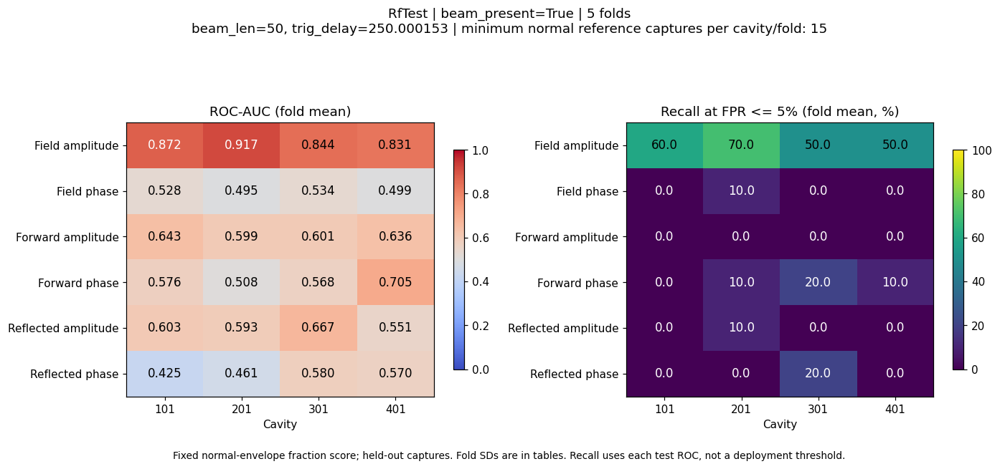

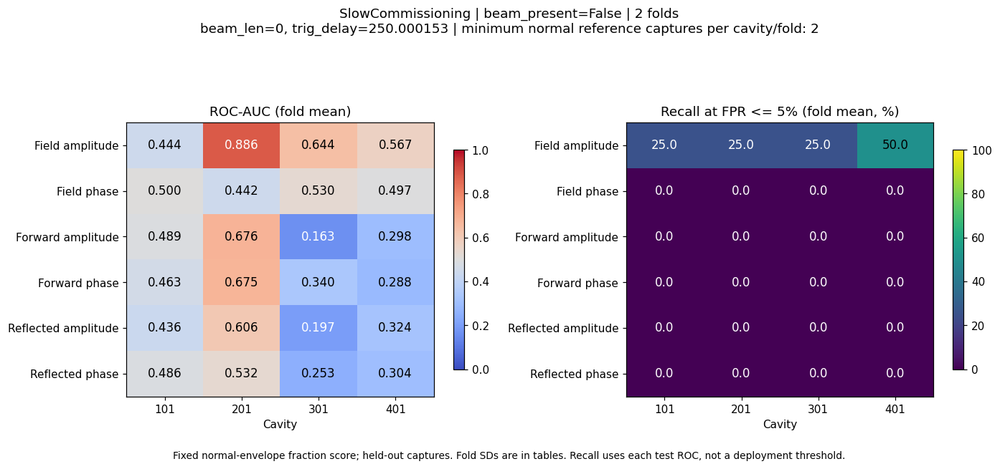

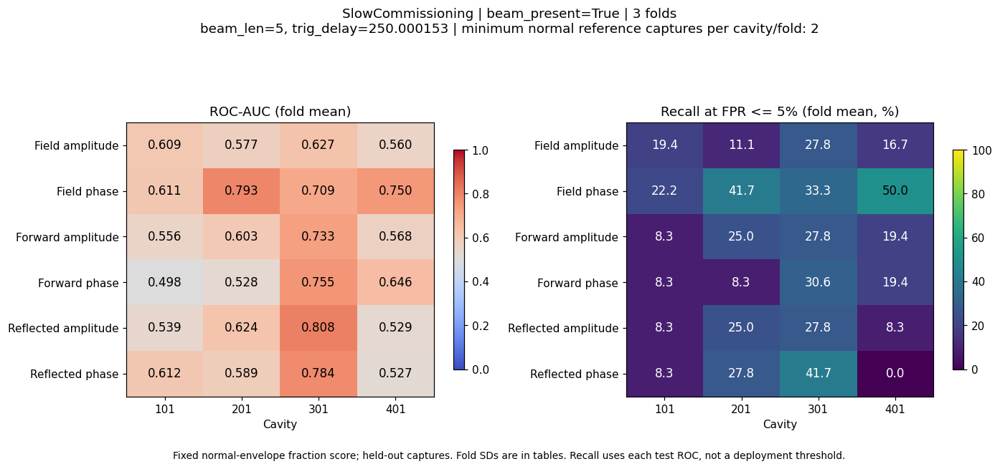

In [166]:
for score_detail_condition, score_detail_figure in score_tools.plot_cavity_sensitivity(score_cavity_report):
    score_detail_figure.savefig(
        score_output_dir / f"condition_{score_detail_condition}_cavity_sensitivity.png",
        dpi=160, bbox_inches="tight",
    )
    plt.show()


In [ ]:
fold meanは、データを分割して繰り返し評価した結果の平均です。foldは「分割したグループ」を指します。

例えばRfTestでは、収録イベントを5グループに分け、次を5回行います。

1. 4グループの正常データで「正常範囲」を作る。
2. 残り1グループの正常・trip波形からAUCを計算する。
3. 評価するグループを順番に交代する。

その5つのAUCを、同じ重みで平均します。

          AUC₁+AUC₂+AUC₃+AUC₄+AUC₅
fold mean=────────────────────────
                     5

前の表の RfTest・cavity 101・Field振幅の0.872 は、この組合せで得た5回のAUCの平均です。

± fold SDは、分割によって結果がどれくらい変わったかを表します。SDが大きいほど、評価する収録によって性能が変わっています。
⚠ Heads up, you have less than 50% of your 5h limit left. Run /status for a breakdown.

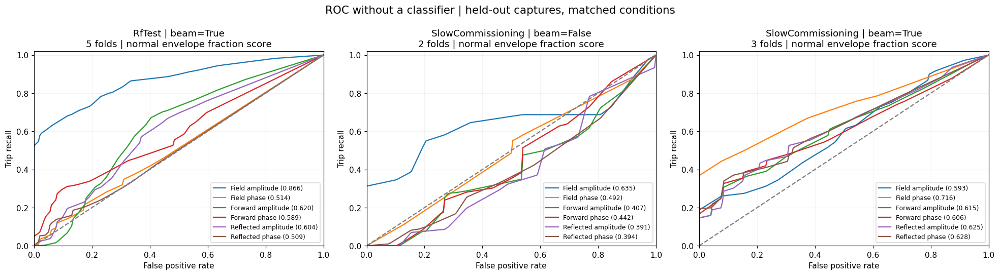

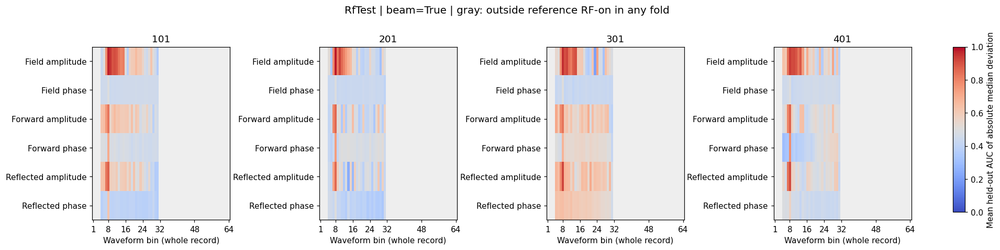

In [164]:
score_roc_figure = score_tools.plot_roc(score_result)
score_roc_figure.savefig(score_output_dir / "roc_without_classifier.png", dpi=150, bbox_inches="tight")
plt.show()

score_bin_figure = score_tools.plot_bin_auc(score_result, beam_mode="RfTest", beam_present=True)
score_bin_figure.savefig(score_output_dir / "rftest_bin_auc.png", dpi=150, bbox_inches="tight")
plt.show()


### Findings from ROC-AUC without a classifier

- **RfTest, beam present, five grouped folds:** Field amplitude has the highest
  primary waveform-score AUC, **0.866**. Its cavity means range from
  **0.831 to 0.917**; mean recall at FPR <= 5% is **57.5%**. The remaining
  waveform-score AUCs are Forward amplitude **0.620**, Reflected amplitude
  **0.604**, Forward phase **0.589**, Field phase **0.514**, and Reflected
  phase **0.509**. Each fold uses at least 15 normal reference captures per cavity.
- **SlowCommissioning, beam present, three grouped folds:** Field phase has the
  highest waveform-score AUC, **0.716**, with cavity means **0.611 to 0.793**.
  There are as few as **two normal reference captures** in a cavity/fold, so
  generalization remains uncertain despite excluding test captures from the reference.
- **SlowCommissioning, no beam, two grouped folds:** Field amplitude has the
  highest waveform-score AUC, **0.635**, with a wide cavity range
  **0.444 to 0.886** and as few as two normal reference captures.
- **Probe and NoBeam:** no scores are reported for conditions that cannot
  support separate normal reference and test captures with both test labels.

The exploratory bin map again highlights the early part of RfTest Field
amplitude: **bin 8** has mean absolute-deviation AUC **0.962** across folds and
cavities. Reflected amplitude at bin 8 has AUC **0.890** and Forward amplitude
**0.846**. These are per-bin scores, not the waveform-fraction AUC, and the
largest values are selected after examining this same dataset. They identify
candidate waveform regions for a subsequent independent evaluation.

Recall at FPR <= 5% is read from each test ROC curve, not from a threshold chosen
on separate validation captures. Phase changes need interpretation alongside
trip RF amplitude. Matching still does not control beam current or acquisition
period, and the labels compare DD operation with final PM trip pulses; this
does not establish causality or advance warning.

The implementation is `cavity_waveform_score_auc.py`; fold metrics, scalar scores,
reference/test pulse membership, bin AUCs, and figures are saved under
`signal_comparison/waveform_score_auc/`.


## Sample counts by label, beam mode, cavity, and acquisition condition

このノートブックの6信号比較に使用するパルスの件数を確認します。
`label=0` は正常のDDパルス、`label=1` はPM収録の最後のtripパルスです。
各信号は同じパルスに対応するので、信号6種類で件数を6倍にはしません。

- `normal_pulses (label=0)` / `trip_pulses (label=1)`：パルス数。
- `normal_captures (label=0)` / `trip_captures (label=1)`：
  `(source, event_id)` の重複を除いた収録イベント数。
- 全cavityの表では、同じ収録に属するcavityを重複して数えません。
- 最初の表は取得条件をまとめた全件数です。ROC-AUC評価では取得条件を
  そろえているため、評価に使った件数は条件別の表で確認してください。

最後に `Probe` を取り出し、`label=1` の存在と、取得条件ごとの正常収録数を
確認します。分類器の学習やサンプルの間引きは行いません。


In [2]:
from pathlib import Path
import pandas as pd

sample_count_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "signal_comparison" / "direct_change_pulse_metadata.csv").is_file()
)
sample_count_metadata = pd.read_csv(
    sample_count_dir / "signal_comparison" / "direct_change_pulse_metadata.csv"
)
if not sample_count_metadata["dataset_index"].is_unique:
    raise ValueError("Duplicate original pulse indices in metadata")
if not sample_count_metadata["label"].isin([0, 1]).all():
    raise ValueError("Expected label=0 (normal DD) or label=1 (trip PM)")

def count_labeled_samples(frame, group_columns):
    # Keep labels absent from a group as an explicit zero.
    pulse_counts = frame.groupby(group_columns + ["label"], dropna=False).size().unstack(
        "label", fill_value=0
    ).reindex(columns=[0, 1], fill_value=0)
    capture_rows = frame.drop_duplicates(group_columns + ["source", "event_id", "label"])
    capture_counts = capture_rows.groupby(group_columns + ["label"], dropna=False).size().unstack(
        "label", fill_value=0
    ).reindex(index=pulse_counts.index, columns=[0, 1], fill_value=0)
    result = pd.concat([
        pulse_counts.rename(columns={0: "normal_pulses (label=0)", 1: "trip_pulses (label=1)"}),
        capture_counts.rename(columns={0: "normal_captures (label=0)", 1: "trip_captures (label=1)"}),
    ], axis=1).reset_index()
    result.columns.name = None
    return result

sample_counts_by_mode = count_labeled_samples(sample_count_metadata, ["beam_mode"])
sample_counts_by_cavity = count_labeled_samples(sample_count_metadata, ["beam_mode", "cavity"])

print(f"Metadata pulses: {len(sample_count_metadata):,}")

display(sample_counts_by_mode)

display(sample_counts_by_cavity)


Metadata pulses: 1,981


,beam_mode,normal_pulses (label=0),trip_pulses (label=1),normal_captures (label=0),trip_captures (label=1)
0,NoBeam,0,4,0,1
1,Probe,88,144,2,36
2,RfTest,1196,36,23,9
3,SlowCommissioning,463,50,9,13


,beam_mode,cavity,normal_pulses (label=0),trip_pulses (label=1),normal_captures (label=0),trip_captures (label=1)
0,NoBeam,HBL-010RFC:RFS-DIG-101,0,1,0,1
1,NoBeam,HBL-010RFC:RFS-DIG-201,0,1,0,1
2,NoBeam,HBL-010RFC:RFS-DIG-301,0,1,0,1
3,NoBeam,HBL-010RFC:RFS-DIG-401,0,1,0,1
4,Probe,HBL-010RFC:RFS-DIG-101,22,36,2,36
5,Probe,HBL-010RFC:RFS-DIG-201,22,36,2,36
6,Probe,HBL-010RFC:RFS-DIG-301,22,36,2,36
7,Probe,HBL-010RFC:RFS-DIG-401,22,36,2,36
8,RfTest,HBL-010RFC:RFS-DIG-101,299,9,23,9
9,RfTest,HBL-010RFC:RFS-DIG-201,299,9,23,9


In [4]:
sample_condition_columns = ["beam_mode", "beam_present", "beam_len"]
sample_counts_by_condition = count_labeled_samples(sample_count_metadata, sample_condition_columns)
sample_probe_metadata = sample_count_metadata.loc[sample_count_metadata["beam_mode"].eq("Probe")]
sample_probe_by_cavity = count_labeled_samples(sample_probe_metadata, ["beam_mode", "cavity"])
sample_probe_by_condition = count_labeled_samples(
    sample_probe_metadata, sample_condition_columns + ["cavity"]
)


display(sample_counts_by_condition)

display(sample_probe_by_cavity)

display(sample_probe_by_condition)


,beam_mode,beam_present,beam_len,normal_pulses (label=0),trip_pulses (label=1),normal_captures (label=0),trip_captures (label=1)
0,NoBeam,False,5.0,0,4,0,1
1,Probe,False,0.0,0,8,0,2
2,Probe,False,5.0,0,12,0,3
3,Probe,True,5.0,88,124,2,31
4,RfTest,False,0.0,208,0,4,0
5,RfTest,True,50.0,988,36,19,9
6,SlowCommissioning,False,0.0,248,11,5,3
7,SlowCommissioning,True,5.0,215,39,5,10


,beam_mode,cavity,normal_pulses (label=0),trip_pulses (label=1),normal_captures (label=0),trip_captures (label=1)
0,Probe,HBL-010RFC:RFS-DIG-101,22,36,2,36
1,Probe,HBL-010RFC:RFS-DIG-201,22,36,2,36
2,Probe,HBL-010RFC:RFS-DIG-301,22,36,2,36
3,Probe,HBL-010RFC:RFS-DIG-401,22,36,2,36


,beam_mode,beam_present,beam_len,cavity,normal_pulses (label=0),trip_pulses (label=1),normal_captures (label=0),trip_captures (label=1)
0,Probe,False,0.0,HBL-010RFC:RFS-DIG-101,0,2,0,2
1,Probe,False,0.0,HBL-010RFC:RFS-DIG-201,0,2,0,2
2,Probe,False,0.0,HBL-010RFC:RFS-DIG-301,0,2,0,2
3,Probe,False,0.0,HBL-010RFC:RFS-DIG-401,0,2,0,2
4,Probe,False,5.0,HBL-010RFC:RFS-DIG-101,0,3,0,3
5,Probe,False,5.0,HBL-010RFC:RFS-DIG-201,0,3,0,3
6,Probe,False,5.0,HBL-010RFC:RFS-DIG-301,0,3,0,3
7,Probe,False,5.0,HBL-010RFC:RFS-DIG-401,0,3,0,3
8,Probe,True,5.0,HBL-010RFC:RFS-DIG-101,22,31,2,31
9,Probe,True,5.0,HBL-010RFC:RFS-DIG-201,22,31,2,31


## Waveform counts by beam mode, beam presence, and label

Field振幅・位相、Forward振幅・位相、Reflected振幅・位相の、
**各信号1種類あたりのwaveform数**を数えます。1 waveformは1 cavityの1 cycleの
64ビン波形です。4台のcavityを合計し、beam_mode・beam_present・labelで集計します。
収録イベント数はこの表に含めません。6信号に欠損がなければ、各信号の件数は同じです。


In [8]:
from pathlib import Path
import numpy as np
import pandas as pd

waveform_count_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "signal_comparison" / "direct_change_pulse_metadata.csv").is_file()
)
waveform_count_metadata = pd.read_csv(
    waveform_count_dir / "signal_comparison" / "direct_change_pulse_metadata.csv"
)
if not waveform_count_metadata["dataset_index"].is_unique:
    raise ValueError("Duplicate waveform row indices")

# Count actual finite waveforms, using the aligned row metadata for each signal.
waveform_counts_by_signal = {}
with np.load(waveform_count_dir / "signal_comparison" / "waveforms.npz", allow_pickle=False) as bundle:
    for waveform_signal_name in bundle.files:
        waveform_matrix = bundle[waveform_signal_name]
        if waveform_matrix.shape != (len(waveform_count_metadata), 64):
            raise ValueError(f"Metadata/array shape mismatch: {waveform_signal_name}")
        waveform_valid = np.isfinite(waveform_matrix).all(axis=1)
        waveform_counts_by_signal[waveform_signal_name] = (
            waveform_count_metadata.loc[waveform_valid]
            .groupby(["beam_mode", "beam_present", "label"], dropna=False).size()
            .unstack("label", fill_value=0).reindex(columns=[0, 1], fill_value=0)
        )

waveform_first_signal = next(iter(waveform_counts_by_signal))
waveform_reference_counts = waveform_counts_by_signal[waveform_first_signal]
waveform_same_counts = all(
    counts.equals(waveform_reference_counts) for counts in waveform_counts_by_signal.values()
)
if waveform_same_counts:
    #print("各信号1種類あたりのwaveform数（4 cavity合計、6信号すべて同じ件数）")
    waveform_count_table = waveform_reference_counts.rename(columns={
        0: "label=0 waveform", 1: "label=1 waveform"
    })
    display(waveform_count_table)
    print(f"合計: label=0 {int(waveform_reference_counts[0].sum()):,}, "
          f"label=1 {int(waveform_reference_counts[1].sum()):,}")
else:
    for waveform_signal_name, counts in waveform_counts_by_signal.items():
        print(waveform_signal_name)
        display(counts.rename(columns={0: "label=0 waveform", 1: "label=1 waveform"}))


label                           label=0 waveform  label=1 waveform
beam_mode         beam_present                                    
NoBeam            False                        0                 4
Probe             False                        0                20
                  True                        88               124
RfTest            False                      208                 0
                  True                       988                36
SlowCommissioning False                      248                11
                  True                       215                39

合計: label=0 1,747, label=1 234


## Amplitude waveforms with beam_present=False

`beam_present=False` の各beam modeについて、Field・Forward・Reflectedの
振幅波形を表示します。行が振幅3種類、列がcavity 101・201・301・401です。

- 青：`label=0`（DD）、オレンジ：`label=1`（PM最後のパルス）。
- 薄線：各waveformをすべて表示。太線：labelごとの中央値。
- 横軸：記録全体を分割した64ビン、縦軸：元データの振幅値。
  振幅の正規化・平均差し引き・外れ値除去は行いません。
- 同じ振幅種類の4つのcavityで縦軸をそろえます。
- `beam_len` と `trig_delay` が異なる条件は別の図にします。
  Probeは条件が2種類あるため2枚になります。

NoBeam・Probeにはlabel=1、RfTestにはlabel=0のみがあり、
SlowCommissioningには両ラベルがあります。各パネルにwaveform数を表示します。


In [14]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

beam_absent_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_signal_change.py").is_file()
)
if str(beam_absent_notebook_dir) not in sys.path:
    sys.path.insert(0, str(beam_absent_notebook_dir))
import cavity_signal_comparison as beam_absent_signal_tools
beam_absent_signal_tools = importlib.reload(beam_absent_signal_tools)
import cavity_signal_beam_mode as beam_absent_data_tools
beam_absent_data_tools = importlib.reload(beam_absent_data_tools)
import cavity_signal_change as beam_absent_plot_tools
beam_absent_plot_tools = importlib.reload(beam_absent_plot_tools)

beam_absent_metadata, beam_absent_waveforms = beam_absent_data_tools.load_beam_datasets(
    beam_absent_notebook_dir / "signal_comparison"
)
beam_absent_output = beam_absent_notebook_dir / "signal_comparison" / "beam_absent_amplitudes"
beam_absent_output.mkdir(parents=True, exist_ok=True)
beam_absent_selected = beam_absent_metadata.loc[beam_absent_metadata["beam_present"].eq(False)]
beam_absent_counts = (
    beam_absent_selected.groupby(["beam_mode", "beam_len", "trig_delay", "cavity", "label"])
    .size().unstack("label", fill_value=0).reindex(columns=[0, 1], fill_value=0)
    .rename(columns={0: "label=0 waveforms", 1: "label=1 waveforms"})
)
print("各振幅信号1種類あたりのwaveform数（beam_present=False）")
display(beam_absent_counts)
beam_absent_counts.to_csv(beam_absent_output / "waveform_counts.csv")


各振幅信号1種類あたりのwaveform数（beam_present=False）


label                                                         label=0 waveforms  \
beam_mode         beam_len trig_delay cavity                                      
NoBeam            5.0      200.005676 HBL-010RFC:RFS-DIG-101                  0   
                                      HBL-010RFC:RFS-DIG-201                  0   
                                      HBL-010RFC:RFS-DIG-301                  0   
                                      HBL-010RFC:RFS-DIG-401                  0   
Probe             0.0      250.000153 HBL-010RFC:RFS-DIG-101                  0   
                                      HBL-010RFC:RFS-DIG-201                  0   
                                      HBL-010RFC:RFS-DIG-301                  0   
                                      HBL-010RFC:RFS-DIG-401                  0   
                  5.0      200.005676 HBL-010RFC:RFS-DIG-101                  0   
                                      HBL-010RFC:RFS-DIG-201                  0   
                                      HBL-010RFC:RFS-DIG-301                  0   
                                      HBL-010RFC:RFS-DIG-401                  0   
RfTest            0.0      250.000153 HBL-010RFC:RFS-DIG-101                 52   
                                      HBL-010RFC:RFS-DIG-201                 52   
                                      HBL-010RFC:RFS-DIG-301                 52   
                                      HBL-010RFC:RFS-DIG-401                 52   
SlowCommissioning 0.0      250.000153 HBL-010RFC:RFS-DIG-101                 65   
                                      HBL-010RFC:RFS-DIG-201                 65   
                                      HBL-010RFC:RFS-DIG-301                 65   
                                      HBL-010RFC:RFS-DIG-401                 53   

label                                                         label=1 waveforms  
beam_mode         beam_len trig_delay cavity                                     
NoBeam            5.0      200.005676 HBL-010RFC:RFS-DIG-101                  1  
                                      HBL-010RFC:RFS-DIG-201                  1  
                                      HBL-010RFC:RFS-DIG-301                  1  
                                      HBL-010RFC:RFS-DIG-401                  1  
Probe             0.0      250.000153 HBL-010RFC:RFS-DIG-101                  2  
                                      HBL-010RFC:RFS-DIG-201                  2  
                                      HBL-010RFC:RFS-DIG-301                  2  
                                      HBL-010RFC:RFS-DIG-401                  2  
                  5.0      200.005676 HBL-010RFC:RFS-DIG-101                  3  
                                      HBL-010RFC:RFS-DIG-201                  3  
                                      HBL-010RFC:RFS-DIG-301                  3  
                                      HBL-010RFC:RFS-DIG-401                  3  
RfTest            0.0      250.000153 HBL-010RFC:RFS-DIG-101                  0  
                                      HBL-010RFC:RFS-DIG-201                  0  
                                      HBL-010RFC:RFS-DIG-301                  0  
                                      HBL-010RFC:RFS-DIG-401                  0  
SlowCommissioning 0.0      250.000153 HBL-010RFC:RFS-DIG-101                  3  
                                      HBL-010RFC:RFS-DIG-201                  3  
                                      HBL-010RFC:RFS-DIG-301                  3  
                                      HBL-010RFC:RFS-DIG-401                  2

NoBeam_beam_len_5_trig_delay_200.005676_amplitudes.png


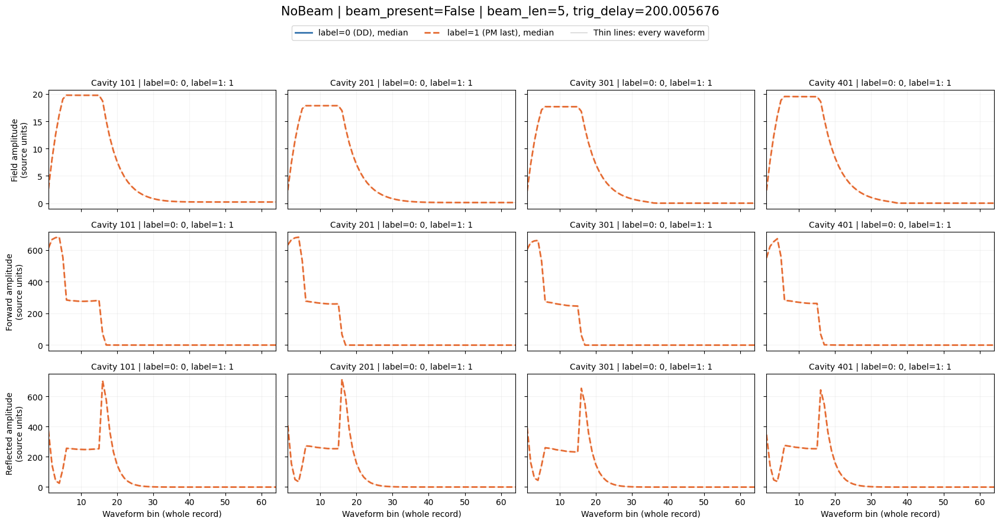

Probe_beam_len_0_trig_delay_250.000153_amplitudes.png


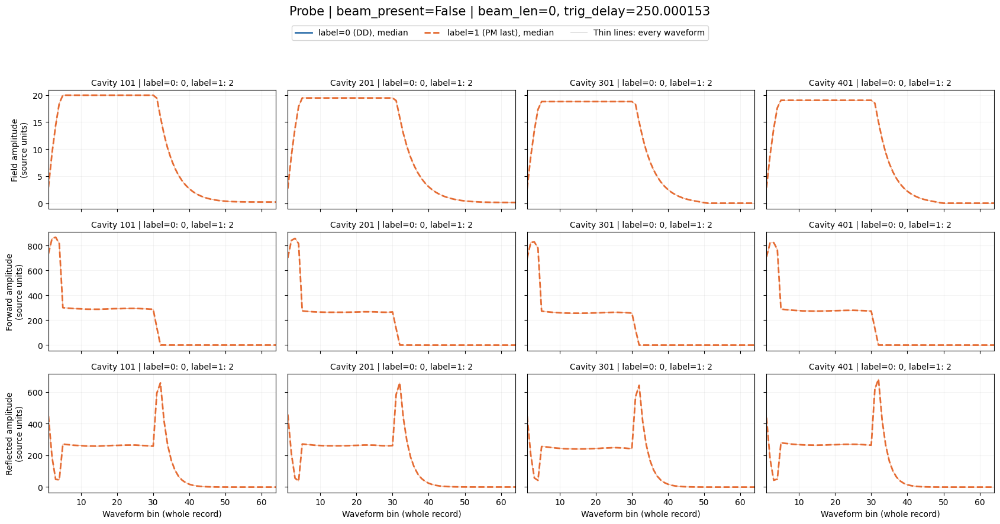

Probe_beam_len_5_trig_delay_200.005676_amplitudes.png


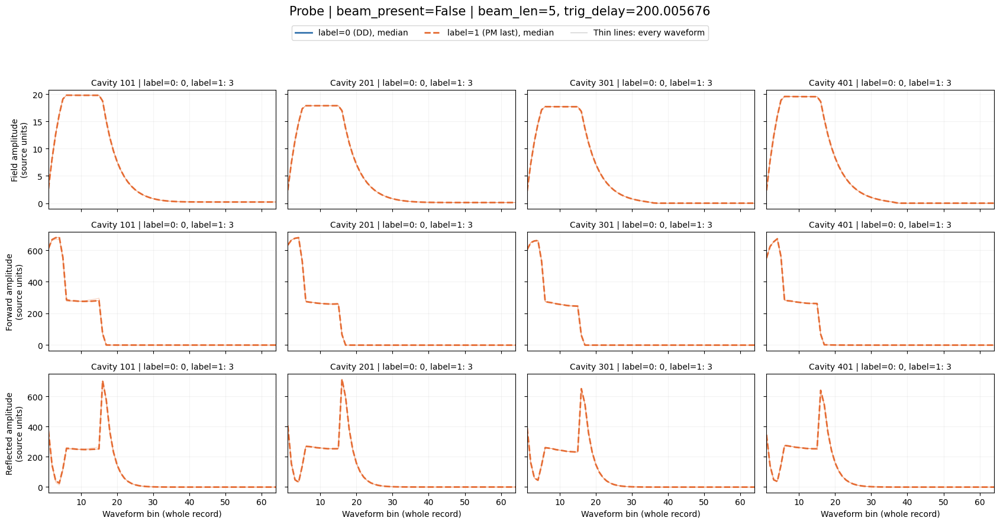

RfTest_beam_len_0_trig_delay_250.000153_amplitudes.png


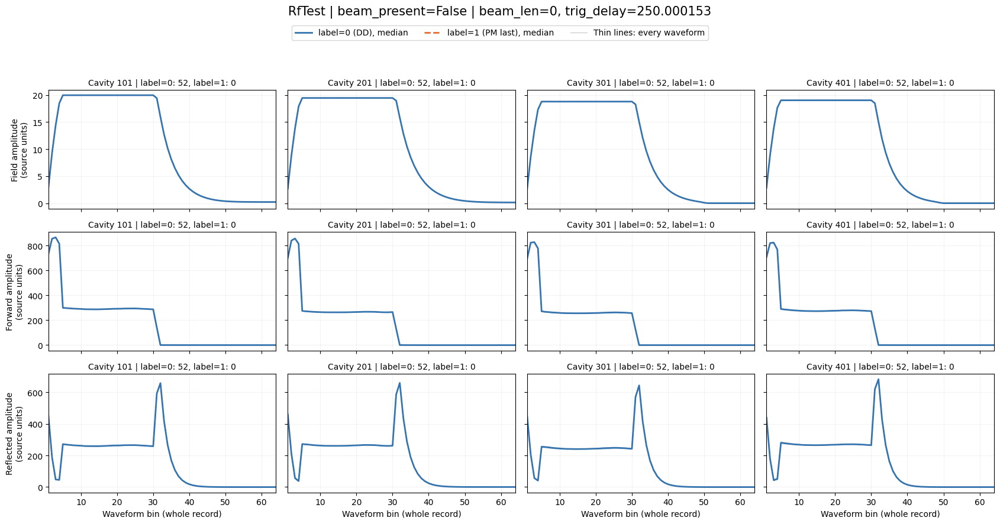

SlowCommissioning_beam_len_0_trig_delay_250.000153_amplitudes.png


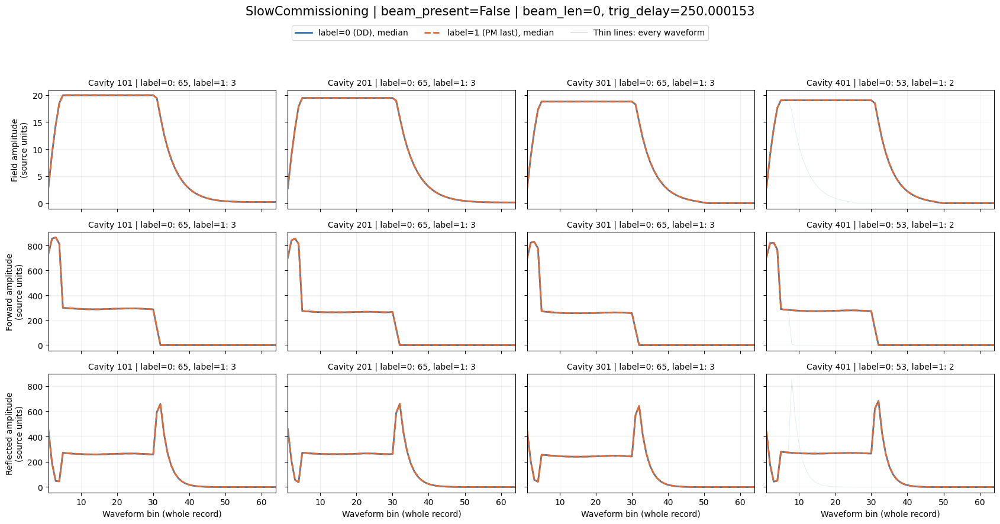

Saved 5 amplitude figures to /workspace/lustre/work/pdl18409/shared/data/anomaly-detection/teams/anomaly-hunters/test/cavity_dataset/signal_comparison/beam_absent_amplitudes


In [15]:
beam_absent_figure_files = []
for beam_absent_context, beam_absent_figure in beam_absent_plot_tools.plot_beam_absent_amplitudes(
    beam_absent_metadata, beam_absent_waveforms
):
    beam_absent_filename = (
        f"{beam_absent_context['beam_mode']}_"
        f"beam_len_{beam_absent_context['beam_len']:g}_"
        f"trig_delay_{beam_absent_context['trig_delay']:.6f}_amplitudes.png"
    )
    beam_absent_path = beam_absent_output / beam_absent_filename
    beam_absent_figure.savefig(beam_absent_path, dpi=150, bbox_inches="tight")
    beam_absent_figure_files.append(beam_absent_path)
    print(beam_absent_filename)
    plt.show()
print(f"Saved {len(beam_absent_figure_files)} amplitude figures to {beam_absent_output}")


## Probe amplitude waveforms compared by trigger delay

Probe・`beam_present=True`・`beam_len=5`で、`trig_delay`が約200と約250の
振幅波形を同じ軸に重ねます。label=0とlabel=1は別の図です。

- 青実線：`trig_delay=200.005676`、オレンジ破線：`250.000153`の中央値。
- 薄線：各条件の全waveform。行はField・Forward・Reflected振幅、列は4台のcavity。
- タイトルの `n` は各cavity・各振幅信号のwaveform数。
- 振幅は元の値、横軸は記録全体の64ビンです。時間位置の補正・振幅正規化はしません。

両条件の元波形長は35,221点です。各cavityの正常データは200側が9本、
250側が13本で、それぞれ1収録から来ています。tripは200側27本、250側4本です。
200側と250側では取得時期も異なるため、波形差をトリガ遅延だけの効果とは解釈できません。


In [167]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

probe_delay_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "cavity_signal_change.py").is_file()
)
if str(probe_delay_notebook_dir) not in sys.path:
    sys.path.insert(0, str(probe_delay_notebook_dir))
import cavity_signal_comparison as probe_delay_signal_tools
probe_delay_signal_tools = importlib.reload(probe_delay_signal_tools)
import cavity_signal_beam_mode as probe_delay_data_tools
probe_delay_data_tools = importlib.reload(probe_delay_data_tools)
import cavity_signal_change as probe_delay_plot_tools
probe_delay_plot_tools = importlib.reload(probe_delay_plot_tools)

probe_delay_metadata, probe_delay_waveforms = probe_delay_data_tools.load_beam_datasets(
    probe_delay_notebook_dir / "signal_comparison"
)
probe_delay_selected = probe_delay_metadata.loc[
    probe_delay_metadata["beam_mode"].eq("Probe") & probe_delay_metadata["beam_present"].eq(True)
]
probe_delay_counts = probe_delay_selected.groupby(["label", "trig_delay"]).agg(
    waveforms=("label", "size"), captures=("event_id", "nunique"),
    beam_len=("beam_len", "first"), array_size_min=("array_size", "min"),
    array_size_max=("array_size", "max"),
    capture_windows=("capture_window", lambda v: ", ".join(sorted(v.unique()))),
)
probe_delay_cavity_counts = probe_delay_selected.groupby(["label", "trig_delay", "cavity"]).agg(
    waveforms=("label", "size"), captures=("event_id", "nunique"),
)
display(probe_delay_counts)
display(probe_delay_cavity_counts)
probe_delay_output = probe_delay_notebook_dir / "signal_comparison" / "probe_trigger_delay"
probe_delay_output.mkdir(parents=True, exist_ok=True)
probe_delay_counts.to_csv(probe_delay_output / "counts_by_delay.csv")
probe_delay_cavity_counts.to_csv(probe_delay_output / "counts_by_delay_and_cavity.csv")


waveforms  captures  beam_len  array_size_min  array_size_max                                           capture_windows
label trig_delay                                                                                                                         
0     200.005676         36         1       5.0           35221           35221                               20250528_2045_20250530_0416
      250.000153         52         1       5.0           35221           35221                               20260629_2226_20260630_0626
1     200.005676        108        27       5.0           35221           35221                               20250528_2045_20250530_0416
      250.000153         16         4       5.0           35221           35221  20260629_1425_20260629_2225, 20260629_2226_20260630_0626

waveforms  captures
label trig_delay cavity                                     
0     200.005676 HBL-010RFC:RFS-DIG-101          9         1
                 HBL-010RFC:RFS-DIG-201          9         1
                 HBL-010RFC:RFS-DIG-301          9         1
                 HBL-010RFC:RFS-DIG-401          9         1
      250.000153 HBL-010RFC:RFS-DIG-101         13         1
                 HBL-010RFC:RFS-DIG-201         13         1
                 HBL-010RFC:RFS-DIG-301         13         1
                 HBL-010RFC:RFS-DIG-401         13         1
1     200.005676 HBL-010RFC:RFS-DIG-101         27        27
                 HBL-010RFC:RFS-DIG-201         27        27
                 HBL-010RFC:RFS-DIG-301         27        27
                 HBL-010RFC:RFS-DIG-401         27        27
      250.000153 HBL-010RFC:RFS-DIG-101          4         4
                 HBL-010RFC:RFS-DIG-201          4         4
                 HBL-010RFC:RFS-DIG-301          4         4
                 HBL-010RFC:RFS-DIG-401          4         4

Probe_beam_present_True_label_0_beam_len_5_trigger_delay_comparison.png


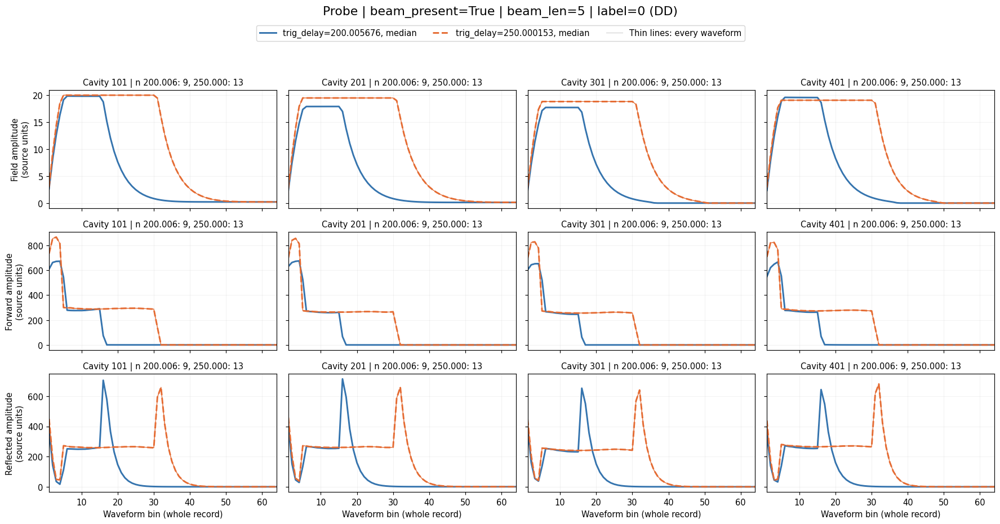

Probe_beam_present_True_label_1_beam_len_5_trigger_delay_comparison.png


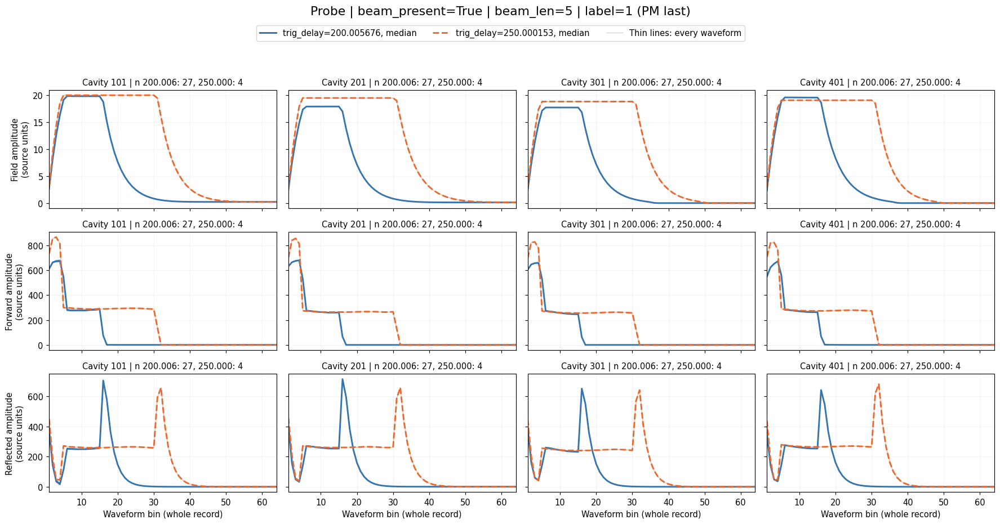

In [168]:
probe_delay_figure_files = []
for probe_delay_context, probe_delay_figure in probe_delay_plot_tools.plot_trigger_delay_amplitudes(
    probe_delay_metadata, probe_delay_waveforms, beam_mode="Probe", beam_present=True
):
    probe_delay_filename = (
        f"Probe_beam_present_True_label_{probe_delay_context['label']}_"
        f"beam_len_{probe_delay_context['beam_len']:g}_trigger_delay_comparison.png"
    )
    probe_delay_path = probe_delay_output / probe_delay_filename
    probe_delay_figure.savefig(probe_delay_path, dpi=150, bbox_inches="tight")
    probe_delay_figure_files.append(probe_delay_path)
    print(probe_delay_filename)
    plt.show()


## Verify acquisition year using the original event_ts

元のDD/PM Parquetから `event_ts` を読み、`source_row` で現在のwaveformに
対応付けます。`event_id`・`cycle_id`・`cavity` の一致を確認してから時刻を付けます。
取得年はファイル名から推定せず、UTCの `event_ts.dt.year` から求めます。

**確認結果：Probe・beam_present=Trueでは、trig_delay≈200は2025年5月、
≈250は2026年6月の収録です。** 今回の全対象データでも2025年と2026年が
それぞれこの2つのtrig_delayに対応しています。

したがって、直前の波形図は取得年も異なる群の比較です。見えた波形差には
年ごとの運転条件・設定変更なども含まれ得るため、trig_delay単独の影響を
この比較から確定することはできません。


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd

event_ts_notebook_dir = next(
    p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
    if (p / "signal_comparison" / "direct_change_pulse_metadata.csv").is_file()
)
event_ts_metadata = pd.read_csv(
    event_ts_notebook_dir / "signal_comparison" / "direct_change_pulse_metadata.csv"
)
if not event_ts_metadata["dataset_index"].is_unique:
    raise ValueError("Duplicate waveform indices")
if not event_ts_metadata["source"].isin(["DD", "PM"]).all():
    raise ValueError("Unexpected capture source")

event_ts_parts = []
for event_ts_source in ["DD", "PM"]:
    event_ts_mask = event_ts_metadata["source"].eq(event_ts_source)
    event_ts_source_table = pd.read_parquet(
        event_ts_notebook_dir.parent / "notebooks" / f"ess_{event_ts_source.lower()}" / "cavity_pulses.parquet",
        columns=["event_id", "cycle_id", "cavity", "event_ts"],
    ).iloc[event_ts_metadata.loc[event_ts_mask, "source_row"].to_numpy()].copy()
    for event_ts_key in ["event_id", "cycle_id", "cavity"]:
        if not np.array_equal(
            event_ts_source_table[event_ts_key].to_numpy(),
            event_ts_metadata.loc[event_ts_mask, event_ts_key].to_numpy(),
        ):
            raise ValueError(f"Timestamp metadata misalignment: {event_ts_source}, {event_ts_key}")
    event_ts_source_table["metadata_row"] = event_ts_metadata.index[event_ts_mask].to_numpy()
    event_ts_parts.append(event_ts_source_table[["metadata_row", "event_ts"]])

event_ts_aligned = pd.concat(event_ts_parts).set_index("metadata_row").sort_index()
if not event_ts_aligned.index.equals(event_ts_metadata.index):
    raise ValueError("Incomplete event_ts mapping")
event_ts_metadata["event_ts"] = pd.to_datetime(event_ts_aligned["event_ts"], utc=True)
if event_ts_metadata["event_ts"].isna().any():
    raise ValueError("Missing event_ts")
event_ts_metadata["event_year"] = event_ts_metadata["event_ts"].dt.year

event_ts_probe = event_ts_metadata.loc[
    event_ts_metadata["beam_mode"].eq("Probe") & event_ts_metadata["beam_present"].eq(True)
]
event_ts_probe_summary = event_ts_probe.groupby(["trig_delay", "event_year", "label"]).agg(
    waveforms=("label", "size"), captures=("event_id", "nunique"),
    first_event_ts_utc=("event_ts", "min"), last_event_ts_utc=("event_ts", "max"),
)
#print("Probe・beam_present=True：元データのevent_tsで確認（waveform数は4 cavity合計・各信号1種類あたり）")
display(event_ts_probe_summary)
#print("Probeの正常データ（label=0）の収録時刻")
display(event_ts_probe.loc[event_ts_probe["label"].eq(0), [
    "source", "event_id", "event_ts", "event_year", "trig_delay"
]].drop_duplicates().reset_index(drop=True))

event_ts_year_delay_counts = pd.crosstab(event_ts_metadata["event_year"], event_ts_metadata["trig_delay"])
#print("全対象データ：event_tsの取得年 × trig_delayのwaveform件数（各信号1種類あたり）")
display(event_ts_year_delay_counts)

event_ts_output_dir = event_ts_notebook_dir / "signal_comparison" / "event_ts_check"
event_ts_output_dir.mkdir(parents=True, exist_ok=True)
event_ts_metadata.to_csv(event_ts_output_dir / "pulse_metadata_with_event_ts.csv", index=False)
event_ts_probe_summary.to_csv(event_ts_output_dir / "probe_event_ts_summary.csv")
event_ts_year_delay_counts.to_csv(event_ts_output_dir / "year_delay_counts.csv")


waveforms  captures  \
trig_delay event_year label                        
200.005676 2025       0             36         1   
                      1            108        27   
250.000153 2026       0             52         1   
                      1             16         4   

                                             first_event_ts_utc  \
trig_delay event_year label                                       
200.005676 2025       0     2025-05-29 12:28:28.575492352+00:00   
                      1     2025-05-28 20:45:07.983413760+00:00   
250.000153 2026       0     2026-06-29 22:20:38.775262440+00:00   
                      1     2026-06-29 15:43:31.063740791+00:00   

                                              last_event_ts_utc  
trig_delay event_year label                                      
200.005676 2025       0     2025-05-29 12:28:28.575492352+00:00  
                      1     2025-05-30 03:41:31.998913024+00:00  
250.000153 2026       0     2026-06-29 22:20:38.775262440+00:00  
                      1     2026-06-29 22:20:57.090279446+00:00

,source,event_id,event_ts,event_year,trig_delay
0,DD,15643300300,2025-05-29 12:28:28.575492352+00:00,2025,200.005676
1,DD,16122803764,2026-06-29 22:20:38.775262440+00:00,2026,250.000153


trig_delay,200.005676,250.000153
event_year,,
2025,160,0
2026,0,1821


## Kickoff on the current dataset: setup

元の `kickoff_notebook.ipynb` の **Unsupervised classification of anomalies — clustering** と
**a weakly-supervised angle + explainability** を、このノートブックの現在の全cavityデータに適用します。
以下のセルは、上の分類器やautoencoderを先に実行しなくても動きます。

全82 cavity、DDの35,414 waveform setsとPM最終の4,809 waveform setsを使用します。
共通の信号はField振幅・位相、Forward振幅、Reflected振幅です。
1 waveform setは1つのcavity・1つのpulseの信号の組です。

| 解析 | 1点の単位 | 入力 | ラベルの扱い |
|---|---|---|---|
| 教師なしクラスター | 1 trip収録 | 全cavityの収録前半→最終pulseの変化、運転条件 | 原因は作成後の照合だけ |
| 弱いNormal/Tripモデル | 1 cavity-pulse | 瞬時の波形・波形特徴とcavity、運転条件 | DD=0 / PM最終=1 |
| 原因系統の関連モデル | 1 trip収録 | 全cavityの変化と運転条件 | 記録された系統を複数ラベルとして扱う |

**DD=0 / PM=1は収録方法に由来する弱いラベルです。** PMに属するすべてのcavityが故障したという
確定ラベルではありません。モデルのPMスコアを物理的な故障確率とは解釈しません。
原因CSVの `systems` もイベント全体の記録であり、個々のcavityの故障を直接指定するものではありません。
未掲載の原因は未知のまま残し、負例にはしません。


In [181]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

kickoff_root = next(p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
                    if (p / "cavity_kickoff_models.py").is_file())
if str(kickoff_root) not in sys.path:
    sys.path.insert(0, str(kickoff_root))
import cavity_kickoff_models as kickoff_tools
import cavity_kickoff_plots as kickoff_plot
kickoff_tools = importlib.reload(kickoff_tools)
kickoff_plot = importlib.reload(kickoff_plot)
kickoff_output = kickoff_root / "signal_comparison" / "kickoff_models"
REBUILD_KICKOFF_MODELS = False
if REBUILD_KICKOFF_MODELS or not kickoff_tools.cache_fresh(kickoff_root, kickoff_output):
    kickoff_result = kickoff_tools.make_result(kickoff_root, kickoff_output)
else:
    kickoff_result = kickoff_tools.load_results(kickoff_output)
kickoff_metadata, kickoff_waves, kickoff_prior = kickoff_tools.load_data(kickoff_root)
kickoff_bundle = joblib.load(kickoff_output / "models.joblib")

print("使用データ（capture数は条件をまたいで重複するため、この表のcapture列を単純合計しません）")
display(kickoff_result["data_support"])
print("独立した収録数と全waveform set数")
display(kickoff_metadata.groupby(["source", "label"]).agg(
    captures=("capture", "nunique"), waveform_sets=("cavity", "size"), cavities=("cavity", "nunique")
).reset_index())


Reused unchanged completed weak-label validation.
Recorded-cause held-out validation: BCM (beam current) (6 positives) complete
Recorded-cause held-out validation: BPM (beam position) (5 positives) complete
Recorded-cause held-out validation: DTL tank (4 positives) complete
Recorded-cause held-out validation: Dump-line imaging (9 positives) complete
Recorded-cause held-out validation: MEBT buncher (17 positives) complete
使用データ（capture数は条件をまたいで重複するため、この表のcapture列を単純合計しません）


,source,label,event_year,beam_mode,beam_present,waveform_sets,captures,cavities
0,DD,0,2025,Probe,True,36,1,4
1,DD,0,2026,Probe,False,575,9,12
2,DD,0,2026,Probe,True,1165,3,81
3,DD,0,2026,RfTest,False,4212,4,81
4,DD,0,2026,RfTest,True,20005,19,81
5,DD,0,2026,SlowCommissioning,False,5648,6,81
6,DD,0,2026,SlowCommissioning,True,3773,5,81
7,PM,1,2025,NoBeam,False,81,1,81
8,PM,1,2025,Probe,False,243,3,81
9,PM,1,2025,Probe,True,2173,27,81


独立した収録数と全waveform set数


,source,label,captures,waveform_sets,cavities
0,DD,0,43,35414,81
1,PM,1,65,4809,82


## Kickoff: Unsupervised classification of anomalies — clustering

PM最終pulseの収録を「異常候補」として、その波形変化のパターンを比較します。
新たな異常検出器によって各cavityの異常を確定したわけではありません。
上の全cavity解析と同じ、取得範囲の広い59収録に対して、次の2つを比較します。

1. **Waveform changes**：82 cavity × 15特徴。欠測を除いた共通特徴の距離。
2. **Waveform 80% + parameters 20%**：波形変化の距離と運転条件の距離を、固定の比率で組み合わせる。
   条件は `beam_mode`, `beam_present`, `beam_len` と、各sectionの `trig_delay` 中央値。

距離の典型的な大きさをそろえてから、`sqrt(0.8 * d_wave² + 0.2 * d_context²)` とします。
この比率は原因ラベルへの一致度で調整していません。
HDBSCANの設定は両方とも `min_cluster_size=4, min_samples=3` です。
MDSの座標は距離関係の表示用で、2次元の見た目に対してクラスタリングしていません。

原因へのAMIだけでなく、取得年・beam modeへのAMIも表示します。
条件を加えると群が見やすくなっても、運転状態や取得時期で分かれただけの可能性があります。
このクラスターは同じデータを探索した結果であり、未知の収録に対する予測精度ではありません。


,representation,events,clusters,noise_events,cause_AMI,year_AMI,beam_mode_AMI
0,Waveform changes,59,3,7,0.4307,0.2841,0.1796
1,Waveform 80% + parameters 20%,59,5,8,0.5123,0.4966,0.3737


,representation,cluster,beam_mode,beam_present,event_year,trip_cause,events
0,Waveform 80% + parameters 20%,-1,Probe,True,2025,Spoke cavity,1
1,Waveform 80% + parameters 20%,-1,Probe,True,2025,Unlisted trip,1
2,Waveform 80% + parameters 20%,-1,Probe,False,2026,Unlisted trip,1
3,Waveform 80% + parameters 20%,-1,RfTest,True,2026,"BPM (beam position), MBL cavity",1
4,Waveform 80% + parameters 20%,-1,SlowCommissioning,True,2026,"BCM (beam current), HBL cavity, MBL cavity",1
5,Waveform 80% + parameters 20%,-1,SlowCommissioning,False,2026,"BCM (beam current), HBL cavity, MBL cavity",1
6,Waveform 80% + parameters 20%,-1,SlowCommissioning,False,2026,Unlisted trip,2
7,Waveform 80% + parameters 20%,1,Probe,True,2026,Unlisted trip,1
8,Waveform 80% + parameters 20%,1,RfTest,True,2026,BPM (beam position),2
9,Waveform 80% + parameters 20%,1,RfTest,True,2026,"BPM (beam position), DTL tank",1


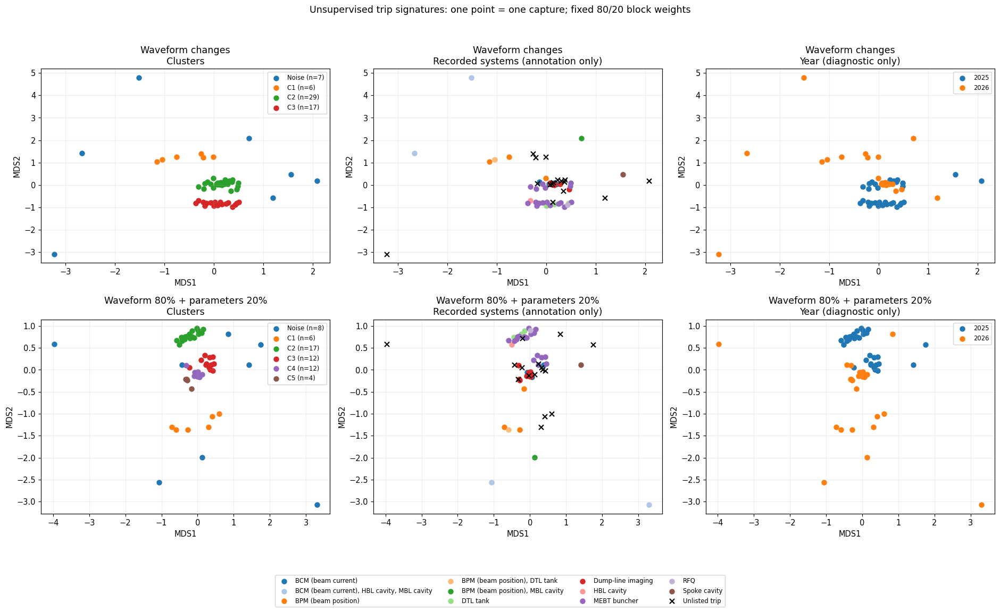

In [182]:
display(kickoff_result["cluster_summary"].round(4))
display(kickoff_result["cluster_profiles"].sort_values(
    ["representation", "cluster", "event_year", "beam_mode", "trip_cause"]
).reset_index(drop=True))
kickoff_fig = kickoff_plot.plot_clusters(kickoff_result)
kickoff_fig.savefig(kickoff_output / "clustering_waveforms_and_context.png", dpi=140, bbox_inches="tight")
plt.show()


## Kickoff: A weakly-supervised angle + explainability

### Normal/Tripモデル：波形と条件を分けて比較する

学習するのはDD=0 / PM最終=1という弱いラベルです。入力を次の3通りに分けます。

- **Waveforms + cavity**：波形とその瞬時の特徴、cavity ID。
- **Parameters + cavity**：`beam_mode`, `beam_present`, `beam_len`, `trig_delay` とcavity ID。
- **Both**：上記の両方。

4種類の64bin波形は、全binを使って連続4binずつ16区間にまとめます。
振幅は各波形の5–95%範囲で規格化し、元のレベルも別特徴に残します。
Field位相はsin/cosにし、Field振幅で重み付けしてRF-off区間の位相の影響を抑えます。
flat-topのばらつき、傾き、step、反射比など、元波形から抽出済みの瞬時の特徴も加えます。
ここでは収録全体の前半を使ったdrift特徴を使いません。
`source`, `label`, `event_id`, 時刻、取得年、最終pulseのrank、原因は入力から除きます。

モデルは深さ5以下のRandom Forest（80本）と、深さ3以下の小さな決定木です。
ハイパーパラメータをテストスコアで探索していません。
同一event IDの全cavity・全pulseを同じfoldに保ち、5-foldで評価します。
欠測補完とカテゴリ変換も学習fold内だけでfitします。
各収録の学習重みの合計を1にし、その中で各cavityの重みも均等にします。

主な評価単位は収録です。各cavity内でpulseのスコアを平均し、さらにcavity間を平均して
1収録のスコアにします。波形4万件を4万件の独立した収録とみなすことはありません。
以下のAUC/APは5個のテストfoldの平均と標準偏差です。


,model,scope,mean_event_auc,std_event_auc,mean_event_AP,std_event_AP
0,Forest,waveform,0.8839,0.0763,0.9230,0.0761
1,Small tree,waveform,0.7950,0.0675,0.8894,0.0489
2,Forest,parameters,0.8051,0.0841,0.8785,0.0676
3,Small tree,parameters,0.8089,0.0876,0.8782,0.0695
4,Forest,combined,0.8645,0.0865,0.9087,0.0791
5,Small tree,combined,0.8756,0.0700,0.9186,0.0650


,model,scope,fold,train_captures,test_captures,normal_test_captures,trip_test_captures,roc_auc,average_precision
0,Forest,waveform,1,86,22,8,14,0.7768,0.7918
1,Small tree,waveform,1,86,22,8,14,0.7232,0.8094
2,Forest,parameters,1,86,22,8,14,0.6607,0.7627
3,Small tree,parameters,1,86,22,8,14,0.6741,0.7626
4,Forest,combined,1,86,22,8,14,0.7679,0.7810
5,Small tree,combined,1,86,22,8,14,0.7589,0.8039
6,Forest,waveform,2,86,22,8,14,0.8304,0.9214
7,Small tree,waveform,2,86,22,8,14,0.7232,0.8772
8,Forest,parameters,2,86,22,8,14,0.8170,0.8942
9,Small tree,parameters,2,86,22,8,14,0.7991,0.8788


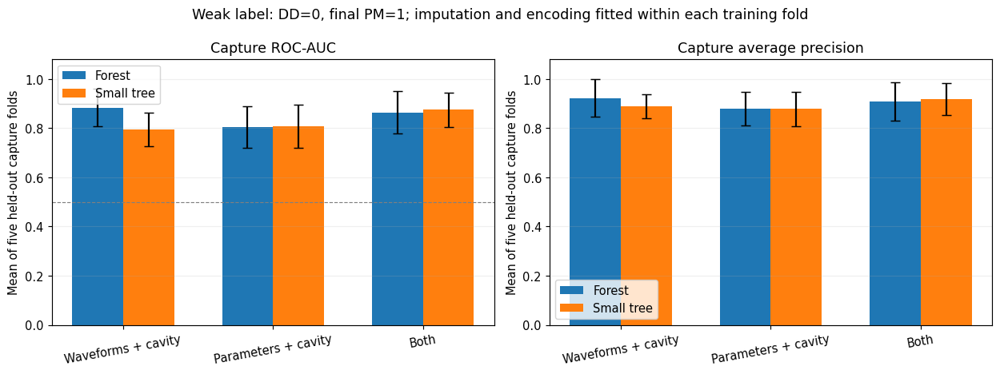

実際の分割は split_audit.csv、全waveformのheld-outスコアは weak_predictions.csv に保存


In [183]:
display(kickoff_result["weak_summary"].round(4))
display(kickoff_result["weak_fold_metrics"].round(4))
kickoff_fig = kickoff_plot.plot_weak_comparison(kickoff_result)
kickoff_fig.savefig(kickoff_output / "weak_label_model_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
print("実際の分割は split_audit.csv、全waveformのheld-outスコアは weak_predictions.csv に保存")


### 取得年をまたぐとどうなるか

`trig_delay` は取得年や装置設定と結びついています。
ランダムな収録分割で良い結果が出ても、波形異常そのものを学習したとは限りません。
そこでForestについて、一方の年だけで学習して、もう一方の年をテストする診断も行います。
年はモデルの入力に使いません。

**2025年はNormalの独立収録が非常に少ないため、年をまたぐAUCにも大きな不確かさがあります。**
この表は汎化を保証する結果ではありません。学習・テストの収録数と一緒に読みます。
特にNormalが1収録のテストでは、その収録がどこに順位付けされるかでAUCが大きく変わります。


In [184]:
display(kickoff_result["year_metrics"].round(4))


,test_year,scope,normal_train_captures,trip_train_captures,normal_test_captures,trip_test_captures,roc_auc,average_precision
0,2025,waveform,42,34,1,31,1.0000,1.0000
1,2025,parameters,42,34,1,31,0.0000,0.9637
2,2025,combined,42,34,1,31,0.8710,0.9958
3,2026,waveform,1,31,42,34,0.5707,0.5009
4,2026,parameters,1,31,42,34,0.4156,0.4775
5,2026,combined,1,31,42,34,0.6380,0.5109


NameError: name 'kickoff_result' is not defined

PMで高スコア、DDで高スコア、PMで低スコアの例


,dataset_index,capture,event_id,cavity,label,fold,score,base_score
0,37767,PM:15644066092,15644066092,Spk-010RFC:RFS-DIG-101,1,1,0.999986,0.593023
1,28,DD:15643300300,15643300300,HBL-010RFC:RFS-DIG-401,0,1,0.999957,0.593023
2,37914,PM:16096616902,16096616902,MBL-090RFC:RFS-DIG-401,1,2,0.243877,0.593023


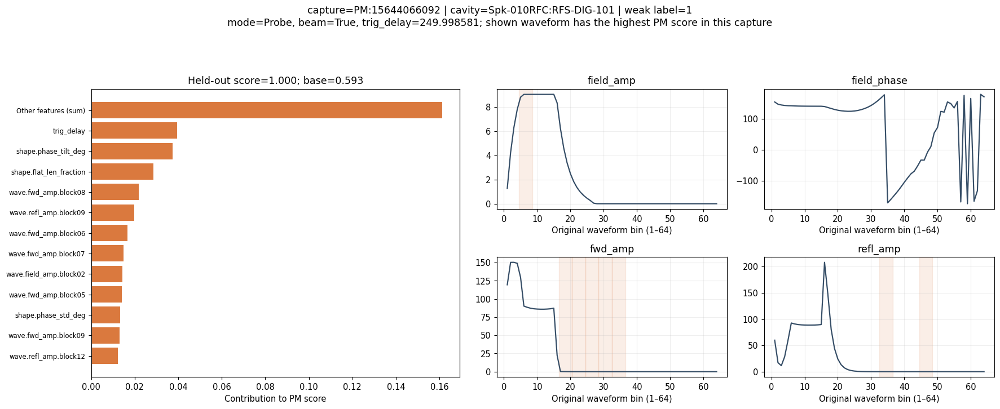

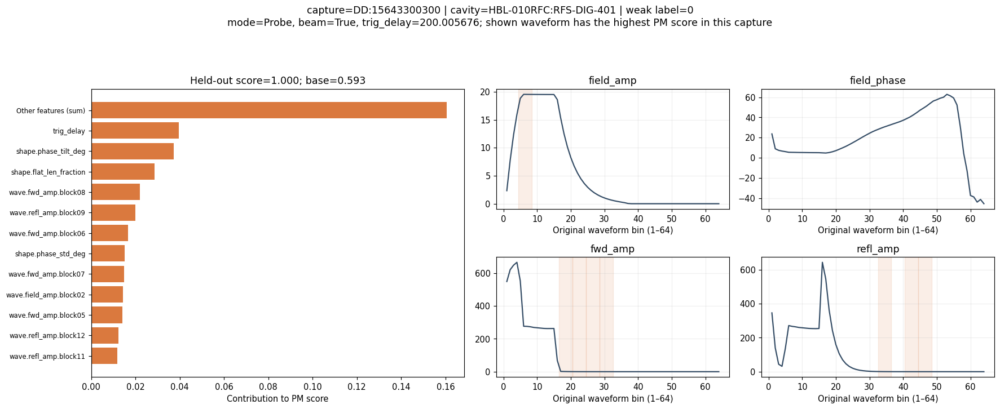

In [186]:
kickoff_cases = kickoff_plot.choose_examples(kickoff_result)
print("PMで高スコア、DDで高スコア、PMで低スコアの例")
display(kickoff_cases)
for kickoff_case in kickoff_cases.iloc[:2].itertuples():
    kickoff_fig = kickoff_plot.plot_local_waveform(
        kickoff_result, kickoff_metadata, kickoff_waves, dataset_index=int(kickoff_case.dataset_index)
    )
    kickoff_fig.savefig(kickoff_output / f"weak_explanation_{kickoff_case.dataset_index}.png", dpi=140, bbox_inches="tight")
    plt.show()

# 任意の収録例を再表示するには、weak_local_casesのdataset_indexを指定します。
# kickoff_plot.plot_local_waveform(kickoff_result, kickoff_metadata, kickoff_waves, dataset_index=...)
# plt.show()


### 記録されたtrip原因を説明するモデル

次に、全82 cavityの変化を1収録の入力にして、記録された原因系統との関連を学習します。
原因が判明した45収録のうち、取得範囲が広い43収録が対象です。
未掲載20収録や、取得範囲の狭い2つの掲載収録を負例にはしません。

`systems` に複数系統がある場合は各系統の複数ラベルとして扱います。
1系統ごとに「その系統が記録されている／他の系統が記録されている」を学習します。
正例・負例がそれぞれ4収録以上ある系統のみ3-foldで評価します。
負例はその系統の問題が物理的に絶対にないという確定ラベルではなく、記録に含まれない掲載イベントです。

ここでも「波形変化のみ」「運転条件のみ」「両方」を比較します。
波形の入力は82 cavity × 15特徴で、cavityの位置を保ちます。
特徴は上の全cavity解析と同じ収録前半から最終pulseへの変化です。
数値が非常に小さい特徴を木で安定して扱うため、事前に固定した物理単位のscaleで割っています。
欠測補完・カテゴリ変換は各学習fold内だけです。

AUC/APは**3個のテストfoldの平均**を主に表示し、全OOF予測をまとめた値もCSVに保存します。
少数事例ではfoldごとの正例比率が変わるため、OOFをまとめた値とfold平均は一致しません。
原因が少数の系統は評価を省略し、件数と理由を明示します。


,system,positive_captures,other_annotated_captures,status
0,BCM (beam current),6,37,evaluated
1,BPM (beam position),5,38,evaluated
2,DTL tank,4,39,evaluated
3,Dump-line imaging,9,34,evaluated
4,HBL cavity,3,40,too_few_labeled_captures
5,MBL cavity,3,40,too_few_labeled_captures
6,MEBT buncher,17,26,evaluated
7,RFQ,1,42,too_few_labeled_captures
8,Spoke cavity,1,42,too_few_labeled_captures


,system,scope,positive_captures,negative_captures,folds,mean_fold_auc,mean_fold_AP,roc_auc,average_precision
0,BCM (beam current),waveform,6,37,3,0.9038,0.7194,0.9279,0.6926
1,BCM (beam current),parameters,6,37,3,0.7949,0.3710,0.7523,0.3153
2,BCM (beam current),combined,6,37,3,0.8622,0.6444,0.8829,0.6027
3,BPM (beam position),waveform,5,38,3,0.9722,0.9000,0.9026,0.7750
4,BPM (beam position),parameters,5,38,3,0.9733,0.7222,0.9605,0.6257
5,BPM (beam position),combined,5,38,3,0.8958,0.8571,0.8368,0.7566
6,DTL tank,waveform,4,39,3,0.5897,0.2053,0.5641,0.1265
7,DTL tank,parameters,4,39,3,0.4359,0.1127,0.3910,0.0881
8,DTL tank,combined,4,39,3,0.4103,0.1368,0.4519,0.0977
9,Dump-line imaging,waveform,9,34,3,0.9899,0.9722,0.9755,0.9044


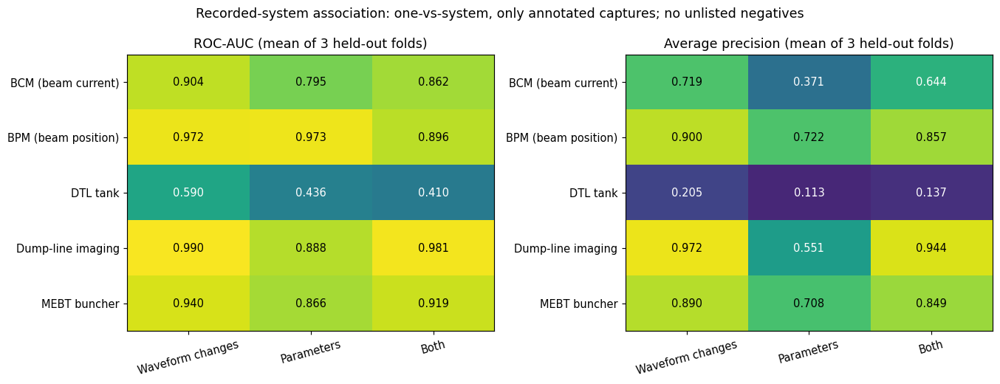

同じ2025年・Probe・beam_present=True内で、MEBTの記録を区別できるか


,system,condition,scope,positive_captures,negative_captures,mean_fold_auc,mean_fold_AP,roc_auc,average_precision
0,MEBT buncher,2025 / Probe / beam=True,waveform,17,7,0.55,0.7844,0.5462,0.7682
1,MEBT buncher,2025 / Probe / beam=True,parameters,17,7,0.50,0.7083,0.4328,0.6838
2,MEBT buncher,2025 / Probe / beam=True,combined,17,7,0.70,0.8487,0.6261,0.8382


In [187]:
display(kickoff_result["cause_support"])
display(kickoff_result["cause_metrics"].round(4))
kickoff_fig = kickoff_plot.plot_cause_metrics(kickoff_result)
kickoff_fig.savefig(kickoff_output / "recorded_cause_model_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
print("同じ2025年・Probe・beam_present=True内で、MEBTの記録を区別できるか")
display(kickoff_result["conditional_cause_metrics"].round(4))


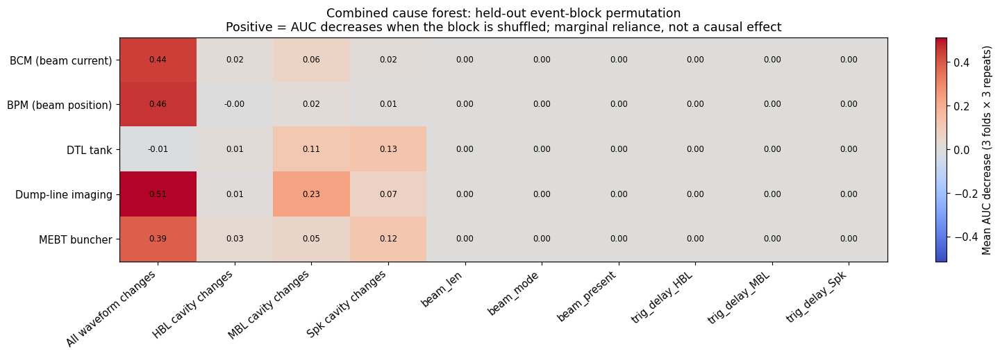

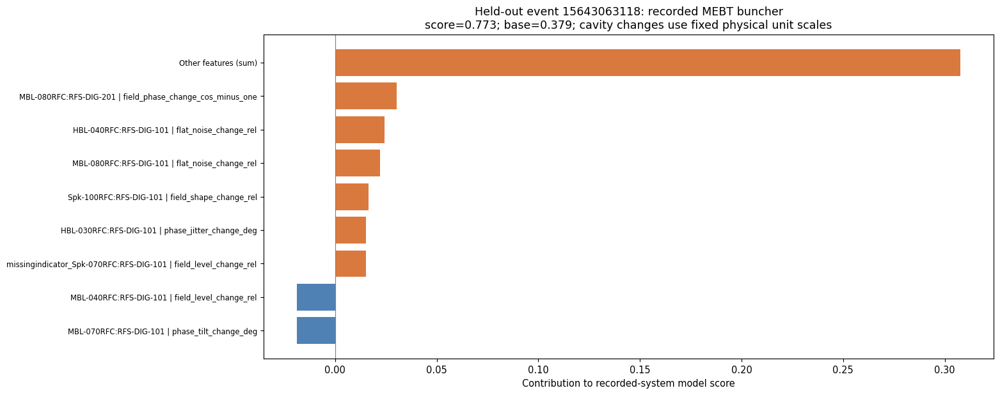

In [188]:
kickoff_fig = kickoff_plot.plot_cause_permutation(kickoff_result)
kickoff_fig.savefig(kickoff_output / "recorded_cause_heldout_permutation.png", dpi=140, bbox_inches="tight")
plt.show()
kickoff_fig = kickoff_plot.plot_cause_example(kickoff_result, system="MEBT buncher")
kickoff_fig.savefig(kickoff_output / "recorded_cause_mebt_explanation.png", dpi=140, bbox_inches="tight")
plt.show()


### 説明から何が言えるか

今回のForestでは、5-foldの収録AUCは波形+cavityが **0.884**、パラメータ+cavityが **0.805**、
両方が **0.865** でした。条件を追加すれば必ず良くなるという結果ではありません。
小さな決定木の両方モデルは約 **0.876** で、分岐を直接読めるモデルも比較対象になります。
ただし、その最初の分岐は `trig_delay <= 249.99937` です。
取得時期や装置設定を見分ける手掛かりに依存している可能性があります。

波形+条件の教師なしクラスターは、波形のみの3群から5群に変わりました。
原因AMIは約0.431→0.512でしたが、取得年AMIも約0.284→0.497に増えています。
原因別にうまく分かれたとだけ結論付けることはできません。

MEBTの原因モデルも、波形のみで全体のAUCが約0.940なのに対して、
同じ2025年・Probe・beam_present=True内では約 **0.550** でした。
波形と条件のモデルでも、全体約0.919、同条件内約0.700です。
同条件内の運転パラメータはほぼ一定なので、この差をパラメータの有用性と解釈することはできません。
特徴数が変わるとForestのランダムな特徴選択も変わり、少数事例では成績が変動します。

`missingindicator_...` の寄与は、波形変化そのものではなく、その測定・特徴が欠けていることへの依存です。
実際にMEBTモデルではSpk-070の欠測を表す特徴にも寄与があり、波形モデルだけでも取得範囲や時期を
見分けている可能性があります。AUCが高い系統でも、独立した運転期間での根本原因推定が実証されたわけではありません。

運転条件のみのモデルが高い場合は、原因やDD/PMの違いと条件が結びついている可能性があります。
両方のモデルの説明に `trig_delay` が現れても、遅延値がtripを引き起こしたと結論付けることはできません。
波形のみのモデル、取得年をまたぐ診断、同じ条件内のMEBT比較を合わせて評価します。

原因モデルのpermutation図は、**テスト収録**の入力ブロックを入れ替えたときのAUC低下です。
波形のブロック内の相関は保持しますが、運転条件と波形の組合せが非典型になることがあります。
相関した入力が代わりの手掛かりになる場合もあるため、値はモデルの依存度の診断として読みます。
高い関連スコアだけで根本原因が特定できたとは扱いません。

未掲載のうち取得範囲の広い16収録への候補スコアは `unknown_cause_scores.csv` に保存します。
これは掲載イベントで学習したモデルの探索用出力で、検証済みの原因ラベルではありません。
複数系統は同時に成立し得るため、候補スコアの合計を1にすることもありません。

推論用の最終モデルと前処理は `models.joblib`、読めるルールは `small_tree_rules.txt`、
全held-out予測、分割監査、寄与、クラスター、図は `signal_comparison/kickoff_models/` に保存します。
元のKickoffとこのノートブックの既存セルは変更しません。



## Normal + Trip: all 40,223 cavity-pulses

**Normalも含めた全40,223点**をクラスタリングします。
ここでは **1点＝1つのcavity・1つのpulse** です。1収録を1点にまとめていた前節の59点とは単位が違います。
各点には共通の4信号（Field振幅・位相、Forward振幅、Reflected振幅）から得られる特徴をまとめます。

- Normal（label=0）：DDの全35,414点、43収録、81 cavity。
- Trip（label=1）：PMの各cavity最終pulseの全4,809点、65収録、82 cavity。
- 合計：40,223点、108収録、82 cavity。Normal/Tripの比率は変更していません。
- 以前の収録単位の解析で別表だった6収録も、実際に存在する63点は今回すべて含めます。
  欠測特徴は全体の中央値で補完し、pulse自体は除外しません。flat-topの抽出失敗でも点を残します。

### 入力とクラスタリング

前の弱教師ありモデルと同じ、波形の97個の瞬時特徴を使います。
各信号の64binを連続4binずつ16区間にまとめ、振幅は各波形の5–95%範囲で規格化します。
位相はRF振幅で重み付けしたsin/cosで扱い、元の振幅レベル、flat-topの揺らぎ・傾き・step等も残します。
今回は収録前半との差ではなく、NormalにもTripにも同じ定義で計算できる瞬時の特徴です。

次の2通りを、Normal/Tripラベルを使わずに比較します。

1. **Waveforms**：標準化した波形特徴を、累積寄与率95%以上のPCAで圧縮。
2. **Waveforms 80% + parameters 20%**：波形のPCA特徴に、`beam_mode`, `beam_present`,
   `beam_len`, `trig_delay` の特徴を組み合わせます。両ブロックの平均二乗ノルムをそろえてから
   `sqrt(0.8)` と `sqrt(0.2)` を掛けます。この比率はラベルに合わせて調整していません。

どちらもKMeansの **k=2〜8の各候補を、全40,223点でfit**します。
候補の比較に使うsilhouetteだけは計算時間を抑えるため同じランダム1,500点で近似します。
選んだクラスター番号とPCA座標は、全点について保存します。
学習・描画用の点を間引いているわけではありません。

`label`, `source`、時刻・取得年、cavity ID、trip原因はクラスタリングの入力には使いません。
fit後の色分けと集計に使用します。条件を加える場合でも取得年そのものは入力しません。
前の波形+cavityの分類モデルとは異なり、今回はcavity IDも直接の入力から除きます。

図は全点を描画し、同じ座標付近の重なりは対数色の密度図でも表示します。
密度図に数えられた点の総数が40,223であることも検証します。
クラスタリングはPCAで残した全特徴空間で実施し、図の2次元だけで群を作っていません。
2通りの表示座標は別々にPCAを計算するため、パネル間の位置・軸を直接比較しません。


In [189]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

normal_trip_root = next(p for p in [Path.cwd(), Path.cwd() / "cavity_dataset"]
                        if (p / "cavity_normal_trip_clustering.py").is_file())
if str(normal_trip_root) not in sys.path:
    sys.path.insert(0, str(normal_trip_root))
import cavity_normal_trip_clustering as normal_trip_tools
normal_trip_tools = importlib.reload(normal_trip_tools)
normal_trip_output = normal_trip_root / "signal_comparison" / "normal_trip_clustering"
REBUILD_NORMAL_TRIP_CLUSTERS = False
if REBUILD_NORMAL_TRIP_CLUSTERS or not normal_trip_tools.cache_fresh(normal_trip_root, normal_trip_output):
    normal_trip_result = normal_trip_tools.make_result(normal_trip_root, normal_trip_output)
else:
    normal_trip_result = normal_trip_tools.load_results(normal_trip_output)

print("今回、実際にクラスタリングした全点数")
display(normal_trip_result["support"])
print("表のpointsはどちらの解析でも40,223。各点はNormalかTripのいずれかに1回だけ含まれます。")
display(normal_trip_result["view_summary"].round(4))
print("kの比較。全候補でfit_points=40,223、silhouette_sample_points=1,500です。")
display(normal_trip_result["model_selection"].round(4))
print("欠測を補完した特徴。行は除外しません。")
display(normal_trip_result["feature_missingness"].query("missing_rows > 0").reset_index(drop=True))


今回、実際にクラスタリングした全点数


,label,label_name,points,captures,cavities
0,0,Normal (DD),35414,43,81
1,1,Trip (PM last),4809,65,82


表のpointsはどちらの解析でも40,223。各点はNormalかTripのいずれかに1回だけ含まれます。


,representation,points,normal_points,trip_points,captures,cavities,waveform_features,waveform_PCs,waveform_variance_retained,cluster_space_dimensions,selected_k,silhouette,PC1_variance,PC2_variance,label_ARI,year_AMI,beam_mode_AMI,cavity_AMI
0,Waveforms,40223,35414,4809,108,82,97,15,0.9551,15,8,0.3840,0.2149,0.1644,0.0805,0.2506,0.1732,0.3845
1,Waveforms 80% + parameters 20%,40223,35414,4809,108,82,97,15,0.9551,22,8,0.2881,0.2005,0.1330,0.0580,0.2200,0.1905,0.3250


kの比較。全候補でfit_points=40,223、silhouette_sample_points=1,500です。


,representation,k,silhouette,fit_points,silhouette_sample_points,min_cluster_points,selected
0,Waveforms,2,0.3232,40223,1500,11891,False
1,Waveforms,3,0.2989,40223,1500,1629,False
2,Waveforms,4,0.3060,40223,1500,445,False
3,Waveforms,5,0.3652,40223,1500,445,False
4,Waveforms,6,0.3733,40223,1500,445,False
5,Waveforms,7,0.3747,40223,1500,138,False
6,Waveforms,8,0.3840,40223,1500,138,True
7,Waveforms 80% + parameters 20%,2,0.2591,40223,1500,11891,False
8,Waveforms 80% + parameters 20%,3,0.1844,40223,1500,1629,False
9,Waveforms 80% + parameters 20%,4,0.2319,40223,1500,445,False


欠測を補完した特徴。行は除外しません。


,feature,missing_rows
0,wave.fwd_amp.level,1
1,wave.fwd_amp.block01,1
2,wave.fwd_amp.block02,1
3,wave.fwd_amp.block03,1
4,wave.fwd_amp.block04,1
5,wave.fwd_amp.block05,1
6,wave.fwd_amp.block06,1
7,wave.fwd_amp.block07,1
8,wave.fwd_amp.block08,1
9,wave.fwd_amp.block09,1


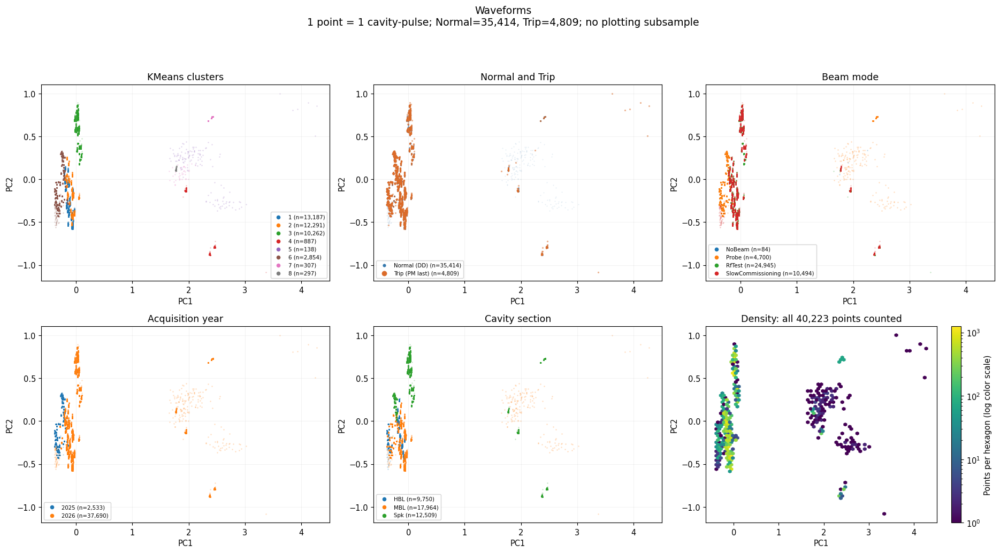

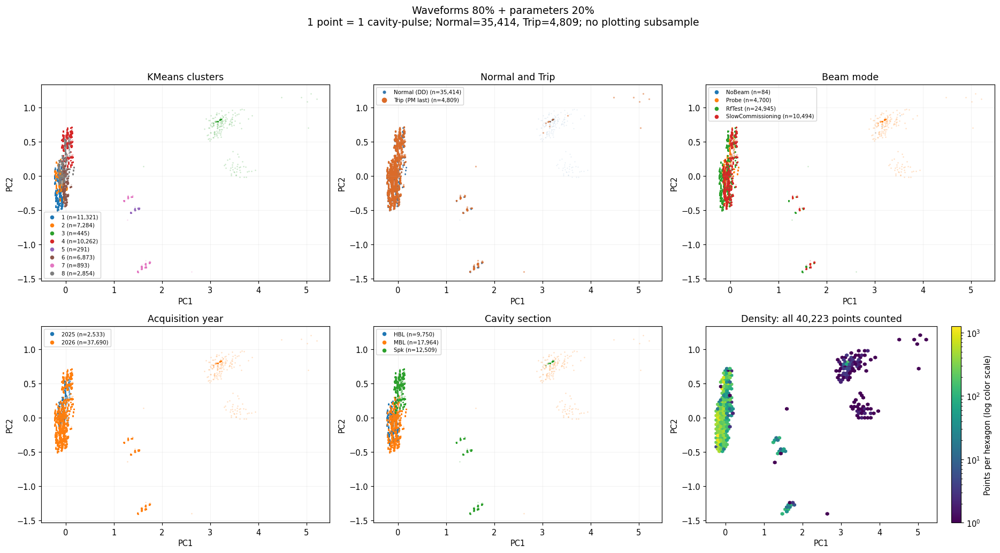

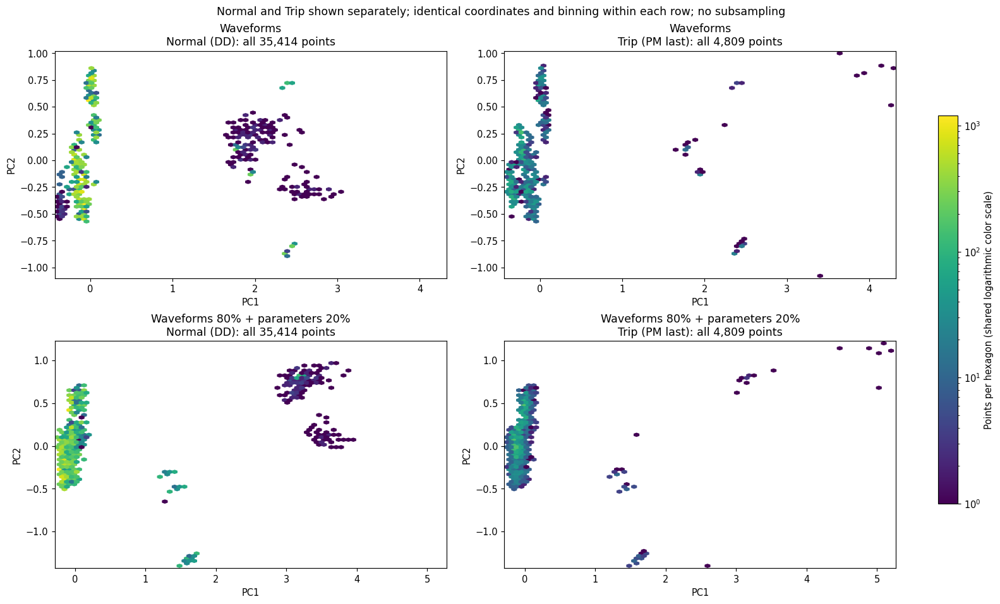

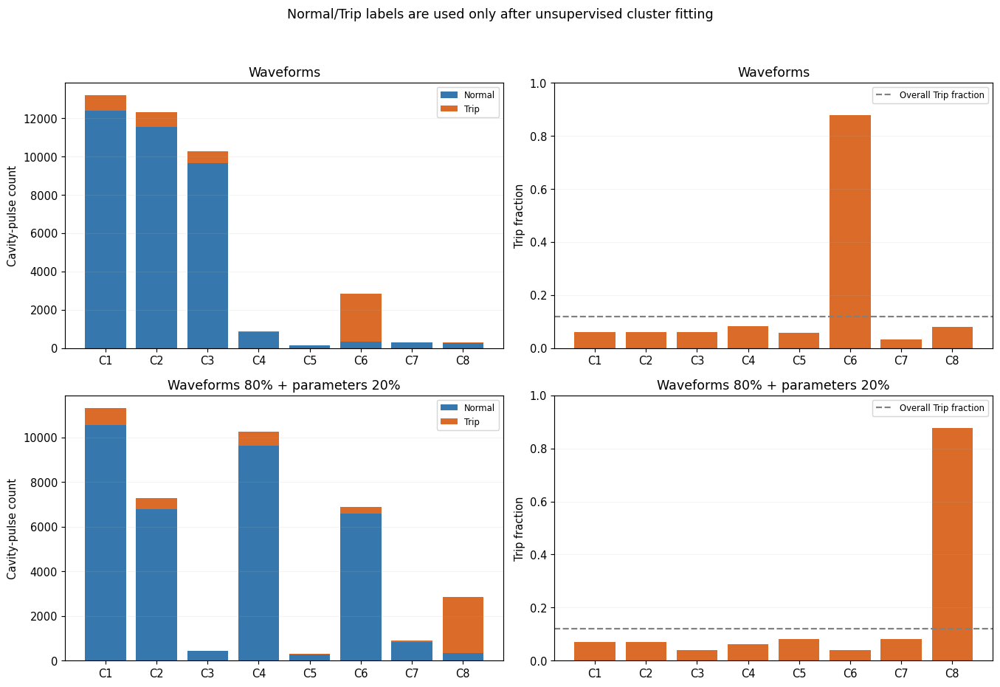

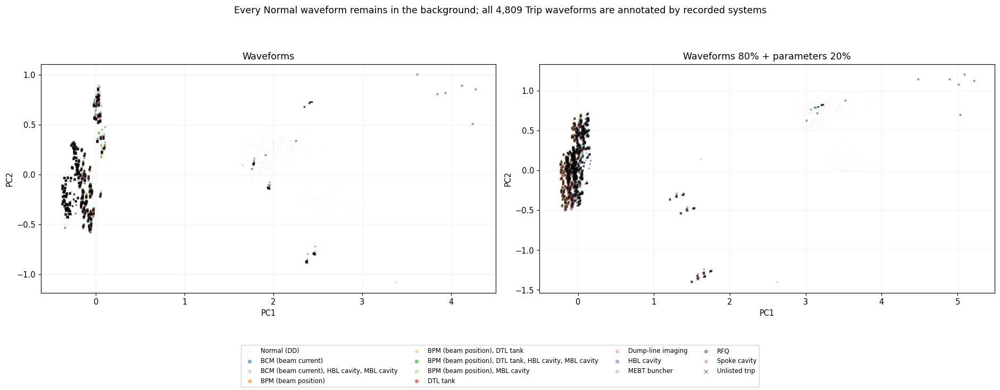

In [192]:
for normal_trip_view_number, normal_trip_view in enumerate(normal_trip_tools.VIEWS, 1):
    normal_trip_fig = normal_trip_tools.plot_all_points(normal_trip_result, normal_trip_view)
    normal_trip_fig.savefig(normal_trip_output / f"all_points_{normal_trip_view_number}.png", dpi=150, bbox_inches="tight")
    plt.show()

import cavity_kickoff_plots as normal_trip_plot
normal_trip_plot = importlib.reload(normal_trip_plot)
normal_trip_fig = normal_trip_plot.plot_normal_trip_densities(normal_trip_result)
normal_trip_fig.savefig(normal_trip_output / "normal_and_trip_separate_density.png", dpi=150, bbox_inches="tight")
plt.show()

normal_trip_fig = normal_trip_tools.plot_composition(normal_trip_result)
normal_trip_fig.savefig(normal_trip_output / "cluster_normal_trip_counts.png", dpi=150, bbox_inches="tight")
plt.show()
normal_trip_fig = normal_trip_tools.plot_causes(normal_trip_result)
normal_trip_fig.savefig(normal_trip_output / "trip_causes_with_normal.png", dpi=150, bbox_inches="tight")
plt.show()


In [191]:
print("各群のNormal/Trip波形数・比率・収録数")
display(normal_trip_result["cluster_composition"].round(4))
print("各群で全体との差が大きい波形特徴（上位4件）")
display(normal_trip_result["cluster_feature_profiles"].query("rank <= 4").reset_index(drop=True).round(5))
for normal_trip_view in normal_trip_tools.VIEWS:
    normal_trip_members = normal_trip_result["memberships"].query("representation == @normal_trip_view")
    print(normal_trip_view, "：クラスター × label × 取得年（点数）")
    display(pd.crosstab(normal_trip_members.cluster, [normal_trip_members.label, normal_trip_members.event_year]))

print("全点の対応表：", normal_trip_output / "memberships.csv")


各群のNormal/Trip波形数・比率・収録数


,representation,cluster,points,normal_points,trip_points,trip_fraction,normal_captures,trip_captures,cavities
0,Waveforms,1,13187,12382,805,0.0610,33,29,29
1,Waveforms,2,12291,11537,754,0.0613,33,29,27
2,Waveforms,3,10262,9633,629,0.0613,33,29,25
3,Waveforms,4,887,814,73,0.0823,21,25,4
4,Waveforms,5,138,130,8,0.0580,4,3,4
5,Waveforms,6,2854,348,2506,0.8781,8,34,82
6,Waveforms,7,307,297,10,0.0326,8,4,6
7,Waveforms,8,297,273,24,0.0808,21,24,1
8,Waveforms 80% + parameters 20%,1,11321,10540,781,0.0690,25,24,34
9,Waveforms 80% + parameters 20%,2,7284,6776,508,0.0697,25,24,22


各群で全体との差が大きい波形特徴（上位4件）


,representation,cluster,rank,feature,standardized_cluster_mean,cluster_mean,overall_mean
0,Waveforms,1,1,wave.field_phase_cos.block08,-0.85325,-0.63623,-0.04893
1,Waveforms,1,2,wave.field_phase_cos.block07,-0.85069,-0.67278,-0.04935
2,Waveforms,1,3,wave.field_phase_cos.block06,-0.84904,-0.67286,-0.04906
3,Waveforms,1,4,wave.field_phase_cos.block09,-0.84495,-0.32842,-0.03947
4,Waveforms,2,1,wave.field_phase_sin.block09,-0.87199,-0.26802,0.00050
5,Waveforms,2,2,wave.field_phase_sin.block08,-0.86572,-0.49985,0.00277
6,Waveforms,2,3,wave.field_phase_sin.block07,-0.85746,-0.52557,0.00304
7,Waveforms,2,4,wave.field_phase_sin.block06,-0.85487,-0.52545,0.00310
8,Waveforms,3,1,wave.refl_amp.block02,1.49034,0.95278,0.70601
9,Waveforms,3,2,wave.fwd_amp.block04,1.40757,0.66813,0.46455


Waveforms ：クラスター × label × 取得年（点数）


label         0            1     
event_year 2025   2026  2025 2026
cluster                          
1             0  12382     0  805
2             0  11537     0  754
3             0   9633     0  629
4             0    814     0   73
5             0    130     0    8
6            36    312  2497    9
7             0    297     0   10
8             0    273     0   24

Waveforms 80% + parameters 20% ：クラスター × label × 取得年（点数）


label         0            1     
event_year 2025   2026  2025 2026
cluster                          
1             0  10540     0  781
2             0   6776     0  508
3             0    427     0   18
4             0   9633     0  629
5             0    267     0   24
6             0   6603     0  270
7             0    820     0   73
8            36    312  2497    9

全点の対応表： /lustre/work/pdl18409/shared/data/anomaly-detection/teams/anomaly-hunters/test/cavity_dataset/signal_comparison/normal_trip_clustering/memberships.csv


### Normalを入れた結果の読み方

今回のk=2〜8の比較では、どちらの表現も範囲内でk=8が選ばれました。
8は探索範囲の上限なので、あらゆるkの中で最適な群数が8と確定したわけではありません。
新しいC1等はこの解析内の番号で、以前の59収録のクラスター番号とは対応しません。

WaveformsのC6、および波形+条件のC8は、Normal 348点・Trip 2,506点で、Trip比率は約87.8%でした。
ただし、その群には**2025年のTrip 2,497点すべて**が入り、2025年Normal 36点も含まれます。
群全体が2025年だけというわけではありませんが、取得年の影響を強く受けています。
したがって、この群を「trip固有の波形を学習して発見した群」とだけ解釈することはできません。
他の群でもNormalとTripが混ざり、cavityやbeam modeの違いも残っています。

今回はNormal 35,414点、Trip 4,809点という元の点数のままfitしています。
DDには同一収録の複数pulseがあるため、点数の多いNormalの波形パターンは全体の形に強く影響します。
同じ収録の点は独立した事例ではなく、この図は40,223件の独立したtrip事例を表してはいません。
表のnormal_captures/trip_capturesは群内で収録を重複カウントしませんが、
同じ収録の別cavityが別群に入ることがあるため、クラスター間では単純合計できません。

ARI/AMIは色分け情報と群との対応を調べる指標で、分類精度やROC-AUCではありません。
この解析は全データの分布を見るための教師なし探索であり、未知の収録での識別性能の評価ではありません。
全40,223点×2表現の対応表、集計、欠測数、モデル、図は
`signal_comparison/normal_trip_clustering/` に保存しています。
